In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn sqlalchemy pymysql python-dotenv

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import sqlalchemy
import pymysql
import dotenv

print("All libraries imported successfully!")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
Pandas: 2.2.3
NumPy: 2.1.3
Scikit-learn: 1.6.1


In [3]:
import os
from pathlib import Path
from dotenv import load_dotenv

# Locate the .env file
env_path = Path.cwd() / ".env"

# Load environment variables
load_dotenv(env_path)

# Verify credentials are available
required_vars = [
    "DB_HOST",
    "DB_PORT",
    "DB_USER",
    "DB_PASSWORD",
    "DB_NAME"
]

for var in required_vars:
    print(f"{var}: {'Loaded' if os.getenv(var) else 'Missing'}")


DB_HOST: Loaded
DB_PORT: Loaded
DB_USER: Loaded
DB_PASSWORD: Loaded
DB_NAME: Loaded


In [4]:
import os
import pandas as pd
from sqlalchemy import create_engine, text
from dotenv import load_dotenv

load_dotenv()

print("Database configuration loaded.")

Database configuration loaded.


In [5]:
from sqlalchemy import create_engine, URL

# Create database connection URL
connection_url = URL.create(
    drivername="mysql+pymysql",
    username=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD"),
    host=os.getenv("DB_HOST"),
    port=int(os.getenv("DB_PORT")),
    database=os.getenv("DB_NAME")
)

# Create SQLAlchemy engine
engine = create_engine(connection_url)

print("Database engine created successfully.")

Database engine created successfully.


In [6]:
try:
    with engine.connect() as connection:
        result = connection.execute(text("SELECT 1"))
        print("MySQL connection successful!")
        
except Exception as e:
    print("Connection failed:", e)

MySQL connection successful!


In [7]:
from sqlalchemy import inspect

# Create an inspector object
inspector = inspect(engine)

# Retrieve available table names
tables = inspector.get_table_names()

# Display tables
print("Available tables:")

for table in tables:
    print(table)

Available tables:
Cust_Account
Cust_Demographics
Cust_Enquiry


In [8]:
# Tables required for our project
project_tables = [
    "Cust_Account",
    "Cust_Enquiry",
    "Cust_Demographics"
]

# Inspect each table
for table in project_tables:

    print(f"\n{'='*50}")
    print(f"TABLE: {table}")
    print('='*50)

    # Retrieve column information
    columns = inspector.get_columns(table)

    print("\nColumns and Data Types:")

    for column in columns:
        print(f"{column['name']} : {column['type']}")

    # Retrieve row count
    with engine.connect() as connection:

        query = text(f"SELECT COUNT(*) FROM `{table}`")

        row_count = connection.execute(query).scalar()

    print(f"\nTotal Rows: {row_count:,}")
    print(f"Total Columns: {len(columns)}")


TABLE: Cust_Account

Columns and Data Types:
dt_opened : VARCHAR(255)
customer_no : VARCHAR(255)
upload_dt : VARCHAR(255)
acct_type : VARCHAR(255)
owner_indic : VARCHAR(255)
opened_dt : VARCHAR(255)
last_paymt_dt : VARCHAR(255)
closed_dt : VARCHAR(255)
reporting_dt : VARCHAR(255)
high_credit_amt : VARCHAR(255)
cur_balance_amt : VARCHAR(255)
amt_past_due : VARCHAR(255)
paymenthistory1 : VARCHAR(255)
paymenthistory2 : VARCHAR(255)
paymt_str_dt : VARCHAR(255)
paymt_end_dt : VARCHAR(255)
creditlimit : VARCHAR(255)
cashlimit : VARCHAR(255)
rateofinterest : VARCHAR(255)
paymentfrequency : VARCHAR(255)
actualpaymentamount : VARCHAR(255)

Total Rows: 186,329
Total Columns: 21

TABLE: Cust_Enquiry

Columns and Data Types:
dt_opened : VARCHAR(255)
customer_no : VARCHAR(255)
upload_dt : VARCHAR(255)
enquiry_dt : VARCHAR(255)
enq_purpose : VARCHAR(255)
enq_amt : VARCHAR(255)

Total Rows: 413,188
Total Columns: 6

TABLE: Cust_Demographics

Columns and Data Types:
dt_opened : VARCHAR(555)
customer_

In [9]:
from pathlib import Path

# Create raw data directory
raw_dir = Path("data/raw")

raw_dir.mkdir(parents=True, exist_ok=True)

print("Raw data directory created:", raw_dir.resolve())

Raw data directory created: C:\Users\AKASH\Projects\Datamites\Client_projects\data\raw


In [10]:
# Dictionary to store datasets
datasets = {}

for table in project_tables:

    print(f"Downloading {table}...")

    # Retrieve data from MySQL
    df = pd.read_sql(
        f"SELECT * FROM `{table}`",
        engine
    )

    # Store DataFrame
    datasets[table] = df

    # Save raw CSV
    file_path = raw_dir / f"{table}.csv"
    df.to_csv(file_path, index=False)

    print(f"Downloaded successfully: {df.shape}")
    print(f"Saved to: {file_path}")
    print("-" * 50)

Downloaded successfully: (186329, 21)
Saved to: data\raw\Cust_Account.csv
--------------------------------------------------
Downloaded successfully: (413188, 6)
Saved to: data\raw\Cust_Enquiry.csv
--------------------------------------------------
Downloaded successfully: (23896, 83)
Saved to: data\raw\Cust_Demographics.csv
--------------------------------------------------


In [11]:
for table, df in datasets.items():

    print(f"{table}:")
    print("Shape:", df.shape)
    print("File exists:", (raw_dir / f"{table}.csv").exists())
    print()

Cust_Account:
Shape: (186329, 21)
File exists: True

Cust_Enquiry:
Shape: (413188, 6)
File exists: True

Cust_Demographics:
Shape: (23896, 83)
File exists: True



### Data Understanding and Initial Inspection

In [12]:
# Load raw datasets

account_df = pd.read_csv(raw_dir / "Cust_Account.csv")

enquiry_df = pd.read_csv(raw_dir / "Cust_Enquiry.csv")

demographic_df = pd.read_csv(raw_dir / "Cust_Demographics.csv")

print("All datasets loaded successfully!")

C:\Users\AKASH\AppData\Local\Temp\ipykernel_7628\2990860522.py:3: DtypeWarning: Columns (18) have mixed types. Specify dtype option on import or set low_memory=False.
  account_df = pd.read_csv(raw_dir / "Cust_Account.csv")


All datasets loaded successfully!


C:\Users\AKASH\AppData\Local\Temp\ipykernel_7628\2990860522.py:7: DtypeWarning: Columns (12,20,63) have mixed types. Specify dtype option on import or set low_memory=False.
  demographic_df = pd.read_csv(raw_dir / "Cust_Demographics.csv")


In [13]:
dataframes = {
    "Cust_Account": account_df,
    "Cust_Enquiry": enquiry_df,
    "Cust_Demographics": demographic_df
}

for name, df in dataframes.items():

    print("\n" + "="*60)
    print(f"DATASET: {name}")
    print("="*60)

    print("\nFirst 5 Rows:")
    display(df.head())

    print("\nDataset Shape:", df.shape)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:", df.isnull().sum().sum())

    print("Duplicate Rows:", df.duplicated().sum())


DATASET: Cust_Account

First 5 Rows:


,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,...,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
0,10-Nov-15,12265,20-Oct-15,6,1,09-Jun-13,30-Jun-14,05-Jul-14,30-Sep-15,20900.0,...,NaN,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",NaN,01-Sep-15,01-Jul-14,NaN,NaN,NaN,NaN,NaN
1,10-Nov-15,12265,20-Oct-15,10,1,25-May-12,06-Sep-15,NaN,03-Oct-15,16201.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000...",01-Oct-15,01-Nov-12,14000.0,1400.0,NaN,3.0,5603.0
2,10-Nov-15,12265,20-Oct-15,10,1,22-Mar-12,31-Aug-15,NaN,30-Sep-15,41028.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Sep-15,01-Oct-12,NaN,NaN,NaN,NaN,NaN
3,20-Jul-15,15606,09-Jul-15,10,1,13-Jan-06,NaN,26-Jul-07,31-Jan-09,93473.0,...,NaN,"""""""1200900600600600300000000000000000000000000...",NaN,01-Jul-07,01-Feb-06,NaN,NaN,NaN,NaN,NaN
4,20-Jul-15,15606,09-Jul-15,6,1,18-Jan-15,05-May-15,NaN,31-May-15,20250.0,...,NaN,"""""""000000000000000""""""",NaN,01-May-15,01-Jan-15,NaN,NaN,NaN,NaN,NaN



Dataset Shape: (186329, 21)

Data Types:
dt_opened               object
customer_no              int64
upload_dt               object
acct_type                int64
owner_indic              int64
opened_dt               object
last_paymt_dt           object
closed_dt               object
reporting_dt            object
high_credit_amt        float64
cur_balance_amt          int64
amt_past_due           float64
paymenthistory1         object
paymenthistory2         object
paymt_str_dt            object
paymt_end_dt            object
creditlimit            float64
cashlimit              float64
rateofinterest          object
paymentfrequency       float64
actualpaymentamount    float64
dtype: object

Missing Values: 1154903
Duplicate Rows: 2401

DATASET: Cust_Enquiry

First 5 Rows:


,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
0,18-Apr-15,1,21-Apr-15,19-Dec-14,2.0,3500000.0
1,18-Apr-15,1,21-Apr-15,05-Mar-14,5.0,500000.0
2,18-Apr-15,1,21-Apr-15,05-Mar-14,0.0,50000.0
3,18-Apr-15,1,21-Apr-15,22-Feb-14,10.0,50000.0
4,18-Apr-15,1,21-Apr-15,11-Jun-13,10.0,1000.0



Dataset Shape: (413188, 6)

Data Types:
dt_opened       object
customer_no      int64
upload_dt       object
enquiry_dt      object
enq_purpose    float64
enq_amt        float64
dtype: object

Missing Values: 440
Duplicate Rows: 13827

DATASET: Cust_Demographics

First 5 Rows:


,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label
0,18-Apr-15,1,13-Apr-15,Insignia,13-Apr-15,650.0,2.0,Card Setup,14.0,500000.0,...,21.0,R,NaN,NaN,0000-00-00,0.0,98332XXXXX,1.0,N,0
1,21-Apr-15,2,21-Apr-15,Insignia,21-Apr-15,760.0,1.0,Card Setup,14.0,1200000.0,...,17.0,R,NaN,NaN,0000-00-00,0.0,99455XXXXX,1.0,N,0
2,22-Apr-15,3,21-Apr-15,Insignia,21-Apr-15,774.0,1.0,Card Setup,14.0,700000.0,...,17.0,R,NaN,NaN,0000-00-00,0.0,98456XXXXX,1.0,N,0
3,25-Apr-15,4,15-Apr-15,Insignia,20-Apr-15,770.0,1.0,Card Setup,14.0,500000.0,...,21.0,R,NaN,NaN,6/15/65,1.0,98220XXXXX,1.0,N,0
4,06-May-15,5,30-Apr-15,Insignia,NaN,NaN,3.0,Card Setup,14.0,500000.0,...,13.0,R,NaN,NaN,0000-00-00,0.0,98111XXXXX,1.0,N,0



Dataset Shape: (23896, 83)

Data Types:
dt_opened       object
customer_no      int64
entry_time      object
feature_1       object
feature_2       object
                ...   
feature_76     float64
feature_77      object
feature_78     float64
feature_79      object
Bad_label        int64
Length: 83, dtype: object

Missing Values: 333644
Duplicate Rows: 0


In [14]:
# Investigate customer-level relationships

for name, df in dataframes.items():

    print("\n" + "="*50)
    print(f"DATASET: {name}")
    print("="*50)

    print("Total records:", len(df))

    print("Unique customers:", df['customer_no'].nunique())

    print("Duplicate customer numbers:",
          df['customer_no'].duplicated().sum())


DATASET: Cust_Account
Total records: 186329
Unique customers: 23896
Duplicate customer numbers: 162433

DATASET: Cust_Enquiry
Total records: 413188
Unique customers: 23896
Duplicate customer numbers: 389292

DATASET: Cust_Demographics
Total records: 23896
Unique customers: 23896
Duplicate customer numbers: 0


In [15]:
# Target variable distribution

print("Bad_label Distribution:")
print(demographic_df['Bad_label'].value_counts())

print("\nPercentage Distribution:")
print(
    demographic_df['Bad_label']
    .value_counts(normalize=True) * 100
)

Bad_label Distribution:
Bad_label
0    22892
1     1004
Name: count, dtype: int64

Percentage Distribution:
Bad_label
0    95.79846
1     4.20154
Name: proportion, dtype: float64


### EDA 

#### Numerical Variable Distributions

In [16]:
# Select numerical variables for analysis

numerical_cols = [
    'high_credit_amt',
    'cur_balance_amt',
    'amt_past_due',
    'creditlimit',
    'cashlimit',
    'actualpaymentamount'
]

# Generate descriptive statistics

account_df[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
high_credit_amt,177454.0,175610.351652,984264.331718,1.0,22975.0,45223.5,106000.00,180000000.0
cur_balance_amt,186329.0,76402.694932,618678.291810,-7355205.0,0.0,0.0,20998.00,136009965.0
amt_past_due,876.0,25831.509132,203067.995753,1.0,153.5,1209.5,7663.25,4869309.0
creditlimit,48852.0,75528.806559,71741.089587,1.0,31000.0,60000.0,100000.00,2500000.0
cashlimit,35282.0,20608.503401,24856.481410,1.0,7500.0,12500.0,27000.00,1000000.0
actualpaymentamount,41053.0,30166.160914,387082.205866,1.0,3110.0,7590.0,18000.00,67853221.0


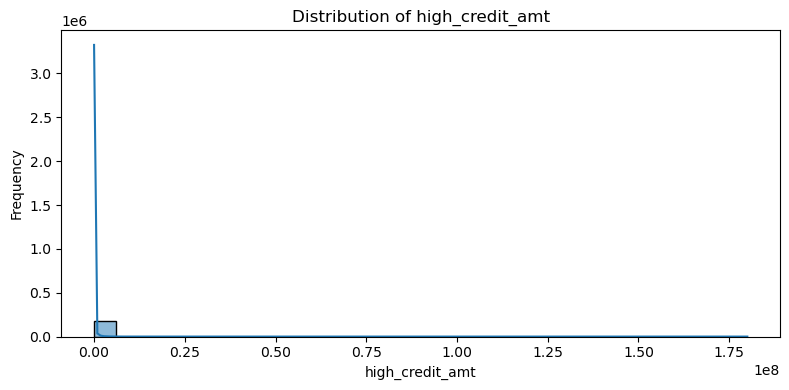

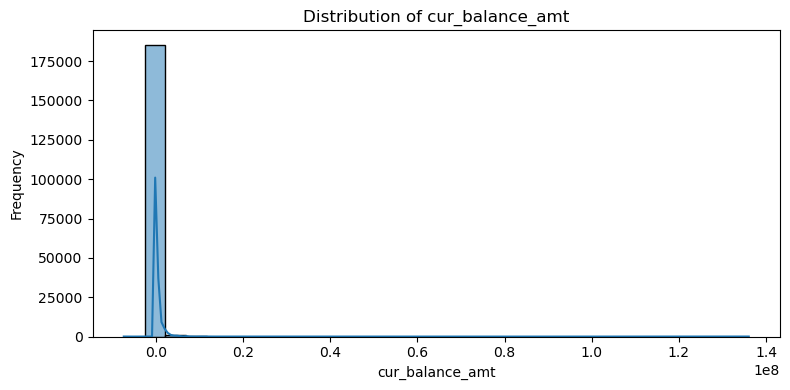

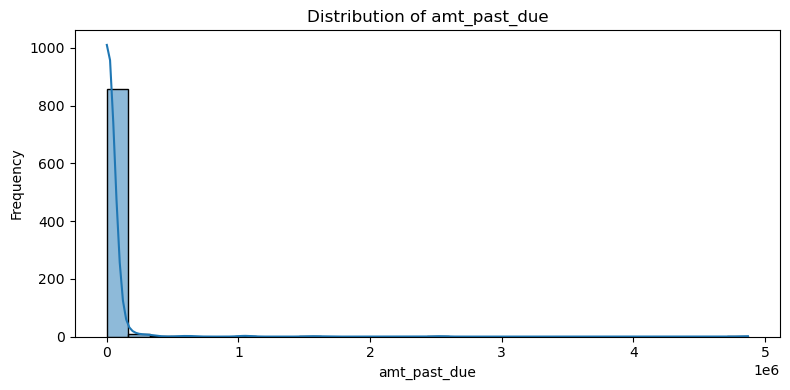

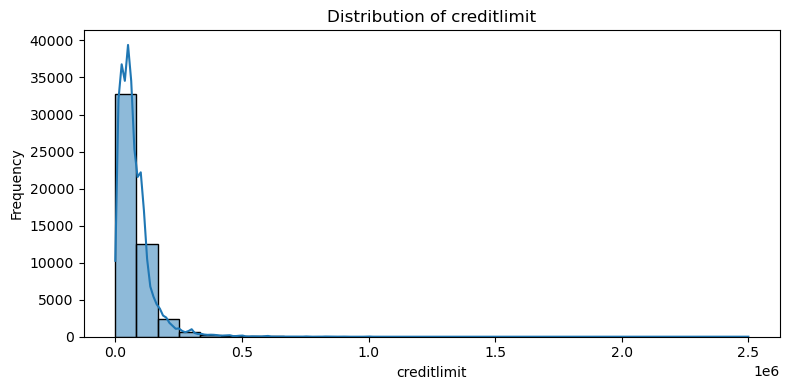

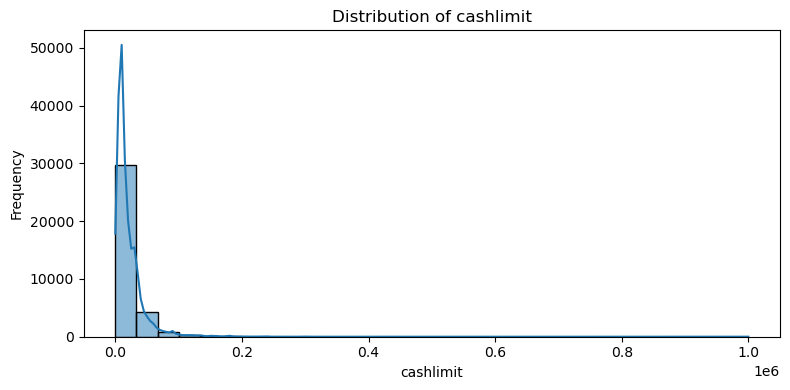

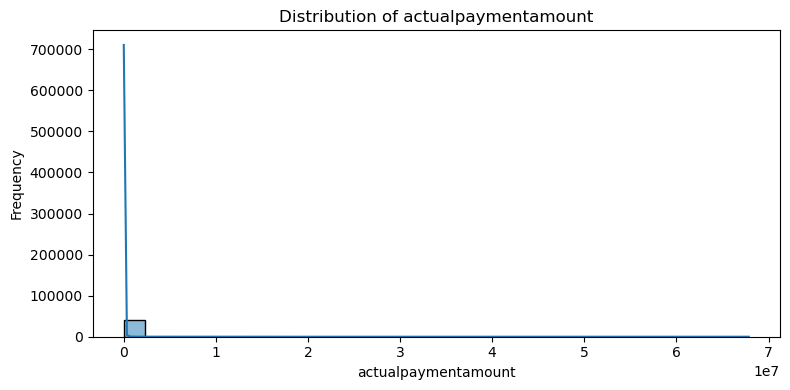

In [17]:
# Plot numerical variable distributions

for col in numerical_cols:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=account_df,
        x=col,
        kde=True,
        bins=30
    )

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

In [18]:
account_df['rateofinterest'].describe()

count     24833
unique     1770
top          39
freq       3211
Name: rateofinterest, dtype: object

In [19]:
account_df['rateofinterest'].value_counts().head(20)

rateofinterest
39       3211
39.0     1814
40.8     1625
41.4     1211
10       1008
40.8      895
39.96     800
41.4      672
39.6      668
10.0      499
39.96     481
39.6      425
11        393
35        366
17.88     352
42        333
15        282
37.8      259
11.0      223
35.0      221
Name: count, dtype: int64

In [20]:
# Categorical variable distribution

account_df['paymentfrequency'].value_counts()

paymentfrequency
3.0    63772
1.0      121
Name: count, dtype: int64

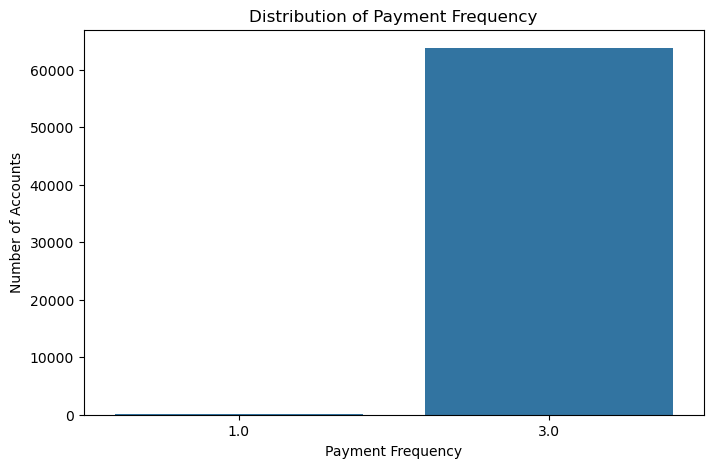

In [21]:
# Visualize payment frequency

plt.figure(figsize=(8, 5))

sns.countplot(
    data=account_df,
    x='paymentfrequency'
)

plt.title('Distribution of Payment Frequency')
plt.xlabel('Payment Frequency')
plt.ylabel('Number of Accounts')

plt.show()

In [22]:
account_df['paymentfrequency'].value_counts(dropna=False)

paymentfrequency
NaN    122436
3.0     63772
1.0       121
Name: count, dtype: int64

acct_type
10    100239
6      25664
5      22921
1       9427
13      8569
2       5639
7       4256
0       3944
12      1196
32       744
51       732
3        672
15       519
17       453
8        407
53       386
4        188
52        97
54        73
35        54
9         53
31        27
59        22
55        17
56         8
34         5
33         5
14         5
11         4
16         2
57         1
Name: count, dtype: int64


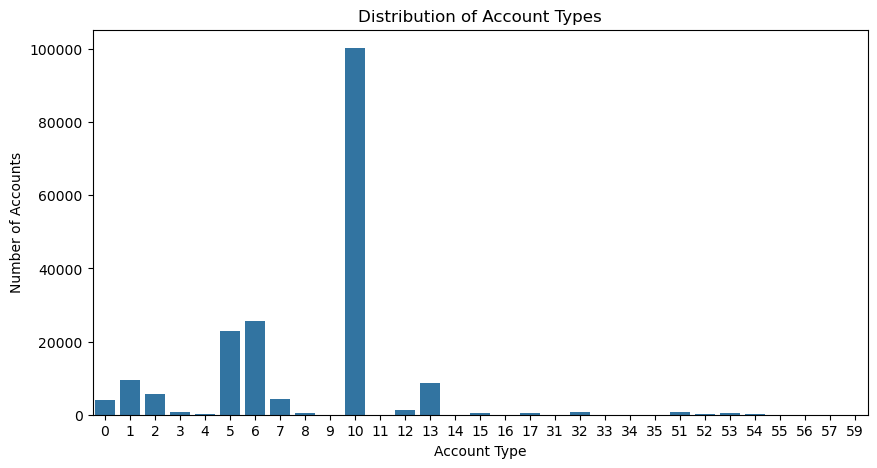

In [23]:
# Account type distribution

print(account_df['acct_type'].value_counts(dropna=False))

plt.figure(figsize=(10, 5))

sns.countplot(
    data=account_df,
    x='acct_type'
)

plt.title('Distribution of Account Types')
plt.xlabel('Account Type')
plt.ylabel('Number of Accounts')

plt.show()

owner_indic
1    177287
4      6253
2      1581
3      1208
Name: count, dtype: int64


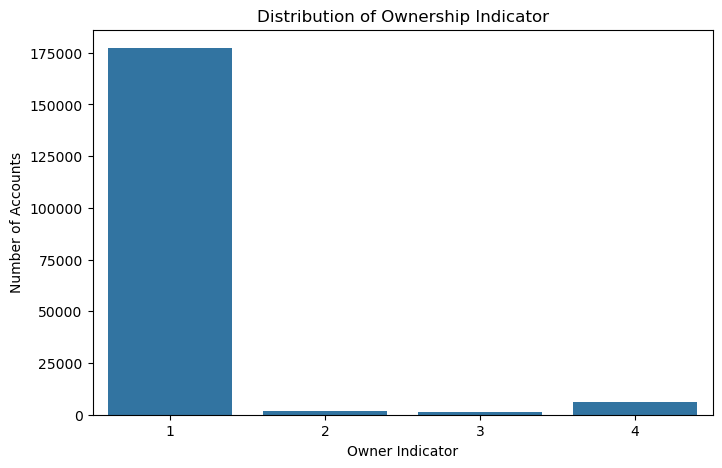

In [24]:
# Ownership indicator distribution

print(account_df['owner_indic'].value_counts(dropna=False))

plt.figure(figsize=(8, 5))

sns.countplot(
    data=account_df,
    x='owner_indic'
)

plt.title('Distribution of Ownership Indicator')
plt.xlabel('Owner Indicator')
plt.ylabel('Number of Accounts')

plt.show()

In [25]:
# Missing value analysis

missing_summary = pd.DataFrame({
    'Missing_Count': account_df.isnull().sum(),
    'Missing_Percentage': account_df.isnull().mean() * 100
})

# Sort by missing percentage
missing_summary = missing_summary.sort_values(
    by='Missing_Percentage',
    ascending=False
)

display(missing_summary)

,Missing_Count,Missing_Percentage
amt_past_due,185453,99.529864
rateofinterest,161496,86.672499
cashlimit,151047,81.064676
actualpaymentamount,145276,77.967466
creditlimit,137477,73.781859
paymentfrequency,122436,65.709578
closed_dt,109075,58.538928
paymenthistory2,107824,57.867535
last_paymt_dt,25487,13.678493
high_credit_amt,8875,4.763080


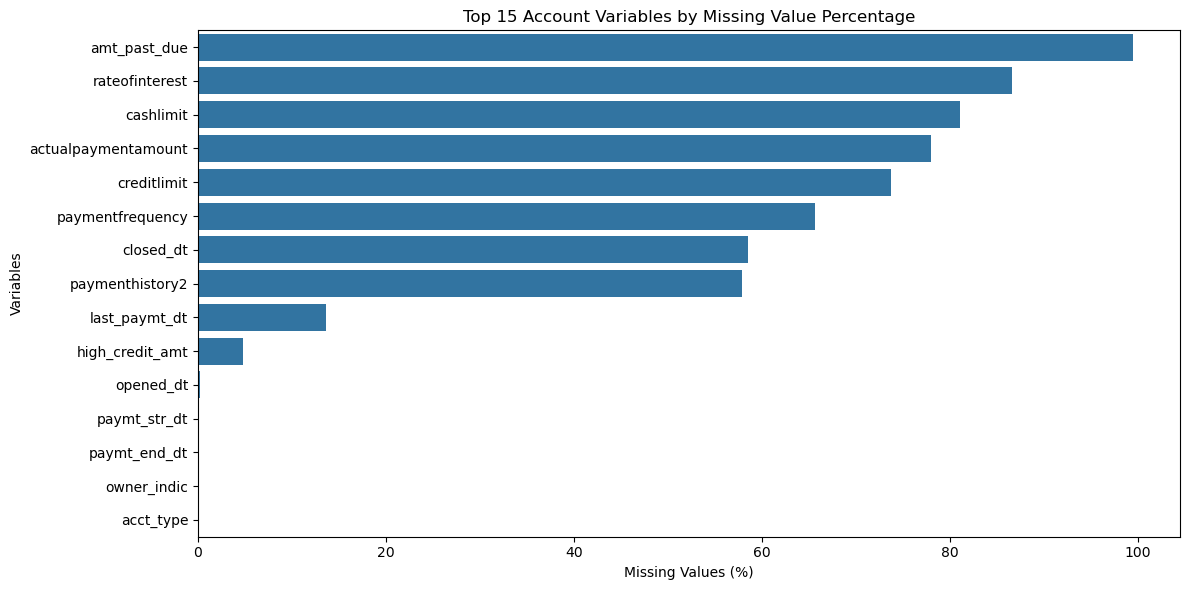

In [26]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=missing_summary.reset_index().head(15),
    x='Missing_Percentage',
    y='index'
)

plt.title('Top 15 Account Variables by Missing Value Percentage')
plt.xlabel('Missing Values (%)')
plt.ylabel('Variables')

plt.tight_layout()
plt.show()

In [27]:
missing_by_account = (
    account_df
    .groupby('acct_type')
    .apply(
        lambda group: group.isnull().mean() * 100,
        include_groups=False
    )
)

print(missing_by_account)

           dt_opened  customer_no  upload_dt  owner_indic  opened_dt  \
acct_type                                                              
0                0.0          0.0        0.0          0.0   1.876268   
1                0.0          0.0        0.0          0.0   0.137902   
2                0.0          0.0        0.0          0.0   0.283738   
3                0.0          0.0        0.0          0.0   0.446429   
4                0.0          0.0        0.0          0.0   0.531915   
5                0.0          0.0        0.0          0.0   0.117796   
6                0.0          0.0        0.0          0.0   0.413030   
7                0.0          0.0        0.0          0.0   1.433271   
8                0.0          0.0        0.0          0.0   0.245700   
9                0.0          0.0        0.0          0.0   0.000000   
10               0.0          0.0        0.0          0.0   0.018955   
11               0.0          0.0        0.0          0.0   0.00

In [28]:
# Check completely duplicated account records

duplicate_rows = account_df.duplicated().sum()

print("Total duplicate rows:", duplicate_rows)

print(
    "Duplicate percentage:",
    (duplicate_rows / len(account_df)) * 100
)

Total duplicate rows: 2401
Duplicate percentage: 1.2885809508986792


In [29]:
# Display duplicated records

account_df[
    account_df.duplicated(keep=False)
].head(10)

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,...,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
76,27-Aug-15,17744,10-Aug-15,10,1,22-Aug-14,25-Jun-15,NaN,11-Jul-15,15702.0,...,NaN,"""""""000000000000000000000000000000000""""""",NaN,01-Jul-15,01-Sep-14,116000.0,34800.0,NaN,3.0,810.0
77,27-Aug-15,17744,10-Aug-15,5,1,05-May-14,05-May-15,NaN,31-May-15,100000.0,...,NaN,"""""""000000000000000""""""",NaN,01-May-15,01-Jan-15,NaN,NaN,NaN,NaN,NaN
78,27-Aug-15,17744,10-Aug-15,10,1,08-May-13,10-Jun-15,NaN,30-Jun-15,28261.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000""""""",01-Jun-15,01-May-13,NaN,NaN,NaN,NaN,NaN
79,27-Aug-15,17744,10-Aug-15,10,1,19-Mar-12,29-Jun-15,NaN,30-Jun-15,25523.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Jun-15,01-Jul-12,73000.0,NaN,39.0,NaN,1000.0
80,27-Aug-15,17744,10-Aug-15,10,1,22-Aug-14,25-Jun-15,NaN,11-Jul-15,15702.0,...,NaN,"""""""000000000000000000000000000000000""""""",NaN,01-Jul-15,01-Sep-14,116000.0,34800.0,NaN,3.0,810.0
81,27-Aug-15,17744,10-Aug-15,5,1,05-May-14,05-May-15,NaN,31-May-15,100000.0,...,NaN,"""""""000000000000000""""""",NaN,01-May-15,01-Jan-15,NaN,NaN,NaN,NaN,NaN
82,27-Aug-15,17744,10-Aug-15,10,1,08-May-13,10-Jun-15,NaN,30-Jun-15,28261.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000""""""",01-Jun-15,01-May-13,NaN,NaN,NaN,NaN,NaN
83,27-Aug-15,17744,10-Aug-15,10,1,19-Mar-12,29-Jun-15,NaN,30-Jun-15,25523.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Jun-15,01-Jul-12,73000.0,NaN,39.0,NaN,1000.0
377,06-Nov-15,4920,29-Oct-15,10,1,04-May-06,NaN,04-May-06,30-Sep-06,NaN,...,NaN,"""""""000""""""",NaN,01-May-06,01-May-06,NaN,NaN,NaN,NaN,NaN
378,06-Nov-15,4920,29-Oct-15,10,1,04-May-06,NaN,04-May-06,30-Sep-06,NaN,...,NaN,"""""""000""""""",NaN,01-May-06,01-May-06,NaN,NaN,NaN,NaN,NaN


In [30]:
# Count occurrences of completely duplicated records

duplicate_groups = (
    account_df[
        account_df.duplicated(keep=False)
    ]
    .value_counts()
    .reset_index(name='Occurrence_Count')
    .sort_values(
        by='Occurrence_Count',
        ascending=False
    )
)

duplicate_groups.head(10)

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,...,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount,Occurrence_Count
0,22-May-15,845,05-May-15,10,1,14-Jul-08,23-Aug-13,22-Nov-13,21-Apr-15,49057.0,...,"""""""1800010000000000000000000000000000000000000...","""""""000000000000000000000000XXX0000000000000000...",01-Nov-13,01-Dec-10,204000.0,123000.0,42,3.0,9600.0,2


In [31]:
# Identify completely duplicated account records

duplicate_data = account_df[
    account_df.duplicated(keep=False)
].copy()


# Extract customer number and target variable
target_lookup = demographic_df[
    ['customer_no', 'Bad_label']
].drop_duplicates(subset='customer_no')


# Merge target labels into duplicate account records

duplicate_data = duplicate_data.merge(
    target_lookup,
    on='customer_no',
    how='left',
    validate='many_to_one'
)


# Check target-label consistency

label_consistency = (
    duplicate_data
    .groupby(list(account_df.columns), dropna=False)
    ['Bad_label']
    .nunique(dropna=True)
    .value_counts()
    .sort_index()
)

print("Target-label consistency:")
print(label_consistency)

Target-label consistency:
Bad_label
1    2207
Name: count, dtype: int64


In [32]:
# Continuous numerical variables

outlier_cols = [
    'high_credit_amt',
    'cur_balance_amt',
    'amt_past_due',
    'creditlimit',
    'cashlimit',
    'actualpaymentamount'
]


# Calculate IQR and identify potential outliers

outlier_summary = []

for col in outlier_cols:

    Q1 = account_df[col].quantile(0.25)
    Q3 = account_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = account_df[
        (account_df[col] < lower_bound) |
        (account_df[col] > upper_bound)
    ]

    outlier_summary.append({
        'Variable': col,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound,
        'Outlier_Count': len(outliers),
        'Outlier_Percentage': (
            len(outliers) / account_df[col].notna().sum()
        ) * 100
    })


outlier_summary_df = pd.DataFrame(outlier_summary)

outlier_summary_df

,Variable,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,high_credit_amt,-101562.500,230537.500,23897,13.466589
1,cur_balance_amt,-31497.000,52495.000,28494,15.292306
2,amt_past_due,-11111.125,18927.875,126,14.383562
3,creditlimit,-72500.000,203500.000,2074,4.245476
4,cashlimit,-21750.000,56250.000,2021,5.728133
5,actualpaymentamount,-19225.000,40335.000,4648,11.321950


In [33]:
# Investigate extreme values in numerical variables

for col in outlier_cols:

    print("\n" + "=" * 60)
    print(f"VARIABLE: {col}")
    print("=" * 60)

    print("Minimum:", account_df[col].min())
    print("Maximum:", account_df[col].max())

    print("\nPercentiles:")

    print(
        account_df[col].quantile(
            [0, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 1]
        )
    )


VARIABLE: high_credit_amt
Minimum: 1.0
Maximum: 180000000.0

Percentiles:
0.00            1.0
0.01          562.0
0.05         4763.0
0.25        22975.0
0.50        45223.5
0.75       106000.0
0.95       550000.0
0.99      2340000.0
1.00    180000000.0
Name: high_credit_amt, dtype: float64

VARIABLE: cur_balance_amt
Minimum: -7355205
Maximum: 136009965

Percentiles:
0.00   -7.355205e+06
0.01   -4.287200e+02
0.05    0.000000e+00
0.25    0.000000e+00
0.50    0.000000e+00
0.75    2.099800e+04
0.95    2.792998e+05
0.99    1.465971e+06
1.00    1.360100e+08
Name: cur_balance_amt, dtype: float64

VARIABLE: amt_past_due
Minimum: 1.0
Maximum: 4869309.0

Percentiles:
0.00          1.00
0.01          1.00
0.05          2.00
0.25        153.50
0.50       1209.50
0.75       7663.25
0.95      63338.00
0.99     305409.75
1.00    4869309.00
Name: amt_past_due, dtype: float64

VARIABLE: creditlimit
Minimum: 1.0
Maximum: 2500000.0

Percentiles:
0.00          1.0
0.01       5000.0
0.05      10000.0
0.2

In [34]:
# Inspect the 10 highest values for each numerical variable

for col in outlier_cols:

    print(f"\nTop 10 values: {col}")

    display(
        account_df[
            ['customer_no', col]
        ]
        .sort_values(
            by=col,
            ascending=False
        )
        .head(10)
    )


Top 10 values: high_credit_amt


,customer_no,high_credit_amt
176100,6999,180000000.0
176105,6999,100000000.0
176104,6999,95463505.0
176110,6999,85000000.0
90671,60,70555622.0
90670,60,69966552.0
70602,20248,60500000.0
153169,16438,60000000.0
70603,20248,51700000.0
142558,17594,46000000.0



Top 10 values: cur_balance_amt


,customer_no,cur_balance_amt
176100,6999,136009965
153169,16438,43403125
142558,17594,42444359
10160,8845,39138851
125758,22949,38950534
111767,19708,34942978
79186,15012,34731070
90670,60,32339854
19155,7535,32063143
152735,7599,30500000



Top 10 values: amt_past_due


,customer_no,amt_past_due
31181,13198,4869309.0
98230,1,2528846.0
27195,42,1561783.0
118207,16099,1053440.0
118185,16099,1053440.0
27194,42,633372.0
152512,6307,576298.0
41448,20598,355295.0
90691,9443,311652.0
92146,10434,303329.0


... (2 outputs left out)


Top 10 values: cashlimit


,customer_no,cashlimit
70009,17827,1000000.0
144665,7621,576200.0
152240,90,450000.0
91381,22869,450000.0
102845,17420,450000.0
55927,10691,440000.0
13475,12063,400000.0
132189,4265,400000.0
68844,11,390546.0
68843,11,390546.0



Top 10 values: actualpaymentamount


,customer_no,actualpaymentamount
176100,6999,67853221.0
55610,11640,22604549.0
55611,11640,14476286.0
9243,7219,7792050.0
30033,2812,7466202.0
126393,8101,6796698.0
31931,12474,6519921.0
140193,57,5989707.0
55612,11640,5902000.0
103430,8332,5075303.0


In [35]:
# Investigate negative account balances

negative_balance = account_df[
    account_df['cur_balance_amt'] < 0
]

print("Negative balance records:", len(negative_balance))

display(
    negative_balance[
        ['customer_no', 'cur_balance_amt']
    ].sort_values(
        by='cur_balance_amt'
    ).head(10)
)

Negative balance records: 8881


,customer_no,cur_balance_amt
170538,15861,-7355205
41892,12210,-4410220
50863,12128,-2384012
100076,5722,-1622449
100073,5722,-1390199
121074,12508,-1011553
35228,7557,-996000
35227,7557,-976000
115500,10115,-948506
110212,8643,-783306


In [36]:
# Analyze negative balances by account type

negative_balance.groupby('acct_type').agg(
    Negative_Balance_Count=('cur_balance_amt', 'count'),
    Average_Balance=('cur_balance_amt', 'mean'),
    Minimum_Balance=('cur_balance_amt', 'min')
).sort_values(
    by='Negative_Balance_Count',
    ascending=False
)

,Negative_Balance_Count,Average_Balance,Minimum_Balance
acct_type,,,
10,8517,-6.667921e+02,-189222
13,107,-8.214327e+03,-36000
1,85,-5.886376e+03,-40102
12,48,-2.655671e+05,-7355205
5,21,-4.363157e+04,-534740
2,14,-2.773287e+05,-2384012
17,13,-3.681308e+03,-42167
15,11,-8.648691e+04,-366936
7,11,-7.702691e+04,-230000


In [37]:
# Negative balance percentage by account type

negative_balance_summary = (
    account_df.groupby('acct_type')
    .agg(
        Total_Accounts=('cur_balance_amt', 'count'),

        Negative_Balance_Count=(
            'cur_balance_amt',
            lambda x: (x < 0).sum()
        ),

        Negative_Balance_Percentage=(
            'cur_balance_amt',
            lambda x: (x < 0).sum() / x.notna().sum() * 100
        )
    )
    .sort_values(
        by='Negative_Balance_Percentage',
        ascending=False
    )
)

negative_balance_summary

,Total_Accounts,Negative_Balance_Count,Negative_Balance_Percentage
acct_type,,,
14,5,2,40.000000
31,27,6,22.222222
35,54,11,20.370370
10,100239,8517,8.496693
12,1196,48,4.013378
52,97,3,3.092784
17,453,13,2.869757
4,188,4,2.127660
15,519,11,2.119461


In [38]:
# Date analysis 
# Identify date columns

date_cols = [
    'dt_opened',
    'opened_dt',
    'closed_dt',
    'reporting_dt',
    'last_paymt_dt',
    'paymt_str_dt',
    'paymt_end_dt',
    'upload_dt'
]

# Inspect date column information

for col in date_cols:

    print("=" * 50)
    print(f"VARIABLE: {col}")
    print("=" * 50)

    print("Data Type:", account_df[col].dtype)

    print("Missing Values:", account_df[col].isnull().sum())

    print("Unique Values:", account_df[col].nunique())

    print("\nSample Values:")
    print(account_df[col].dropna().head(10).tolist())

    print("\n")

VARIABLE: dt_opened
Data Type: object
Missing Values: 0
Unique Values: 197

Sample Values:
['10-Nov-15', '10-Nov-15', '10-Nov-15', '20-Jul-15', '20-Jul-15', '20-Jul-15', '20-Jul-15', '20-Jul-15', '20-Jul-15', '20-Jul-15']


VARIABLE: opened_dt
Data Type: object
Missing Values: 455
Unique Values: 6245

Sample Values:
['09-Jun-13', '25-May-12', '22-Mar-12', '13-Jan-06', '18-Jan-15', '14-Jan-15', '29-Dec-14', '22-Oct-14', '04-Dec-12', '01-Aug-12']


VARIABLE: closed_dt
Data Type: object
Missing Values: 109075
Unique Values: 4839

Sample Values:
['05-Jul-14', '26-Jul-07', '03-Dec-11', '02-Nov-11', '21-Oct-10', '17-Apr-14', '21-Mar-07', '20-Nov-08', '15-Jan-14', '07-Jan-14']


VARIABLE: reporting_dt
Data Type: object
Missing Values: 0
Unique Values: 1877

Sample Values:
['30-Sep-15', '03-Oct-15', '30-Sep-15', '31-Jan-09', '31-May-15', '31-May-15', '31-May-15', '31-May-15', '31-May-15', '26-Jun-15']


VARIABLE: last_paymt_dt
Data Type: object
Missing Values: 25487
Unique Values: 4510

Sample

In [39]:
# Create a separate DataFrame for date analysis

date_analysis_df = account_df[date_cols].copy()

# Convert object columns into datetime format

for col in date_cols:

    date_analysis_df[col] = pd.to_datetime(
        date_analysis_df[col].astype('string').str.strip(),
        format='%d-%b-%y',
        errors='coerce'
    )

In [40]:
# Validate converted date columns

for col in date_cols:

    original_missing = account_df[col].isna().sum()

    converted_missing = date_analysis_df[col].isna().sum()

    invalid_dates = converted_missing - original_missing

    print(f"\nCOLUMN: {col}")
    print("Converted Data Type:", date_analysis_df[col].dtype)
    print("Original Missing Values:", original_missing)
    print("Invalid Date Values:", invalid_dates)
    print("Total Missing After Conversion:", converted_missing)


COLUMN: dt_opened
Converted Data Type: datetime64[ns]
Original Missing Values: 0
Invalid Date Values: 0
Total Missing After Conversion: 0

COLUMN: opened_dt
Converted Data Type: datetime64[ns]
Original Missing Values: 455
Invalid Date Values: 0
Total Missing After Conversion: 455

COLUMN: closed_dt
Converted Data Type: datetime64[ns]
Original Missing Values: 109075
Invalid Date Values: 0
Total Missing After Conversion: 109075

COLUMN: reporting_dt
Converted Data Type: datetime64[ns]
Original Missing Values: 0
Invalid Date Values: 0
Total Missing After Conversion: 0

COLUMN: last_paymt_dt
Converted Data Type: datetime64[ns]
Original Missing Values: 25487
Invalid Date Values: 0
Total Missing After Conversion: 25487

COLUMN: paymt_str_dt
Converted Data Type: datetime64[ns]
Original Missing Values: 1
Invalid Date Values: 0
Total Missing After Conversion: 1

COLUMN: paymt_end_dt
Converted Data Type: datetime64[ns]
Original Missing Values: 1
Invalid Date Values: 0
Total Missing After Conver

In [41]:
# Analyse date ranges

date_summary = pd.DataFrame({
    'Minimum_Date': date_analysis_df[date_cols].min(),
    'Maximum_Date': date_analysis_df[date_cols].max(),
    'Unique_Dates': date_analysis_df[date_cols].nunique(),
    'Missing_Count': date_analysis_df[date_cols].isna().sum()
})

date_summary

,Minimum_Date,Maximum_Date,Unique_Dates,Missing_Count
dt_opened,2015-04-16,2015-12-31,197,0
opened_dt,1979-10-01,2015-12-15,6245,455
closed_dt,1993-10-14,2015-12-11,4839,109075
reporting_dt,2004-02-14,2015-12-20,1877,0
last_paymt_dt,1993-02-20,2015-12-10,4510,25487
paymt_str_dt,1993-10-01,2015-12-01,233,1
paymt_end_dt,1993-02-01,2015-12-01,234,1
upload_dt,2015-04-21,2015-12-31,75,0


In [42]:
# Compare payment start and end dates

payment_dates = date_analysis_df[
    ['paymt_str_dt', 'paymt_end_dt']
].dropna()

# Identify chronological relationships

start_after_end = (
    payment_dates['paymt_str_dt'] >
    payment_dates['paymt_end_dt']
).sum()

start_before_end = (
    payment_dates['paymt_str_dt'] <
    payment_dates['paymt_end_dt']
).sum()

same_date = (
    payment_dates['paymt_str_dt'] ==
    payment_dates['paymt_end_dt']
).sum()

print("Total comparable records:", len(payment_dates))
print("Start date after end date:", start_after_end)
print("Start date before end date:", start_before_end)
print("Both dates are equal:", same_date)

print(
    "Reversed Date Percentage:",
    (start_after_end / len(payment_dates)) * 100
)

Total comparable records: 186328
Start date after end date: 164920
Start date before end date: 0
Both dates are equal: 21408
Reversed Date Percentage: 88.5105834871839


In [43]:
# Identify records with reversed payment dates

reversed_mask = (
    date_analysis_df['paymt_str_dt'] >
    date_analysis_df['paymt_end_dt']
)

reversed_payment_dates = account_df.loc[
    reversed_mask
]

display(
    reversed_payment_dates[
        [
            'customer_no',
            'acct_type',
            'opened_dt',
            'reporting_dt',
            'paymt_str_dt',
            'paymt_end_dt'
        ]
    ].head(20)
)

,customer_no,acct_type,opened_dt,reporting_dt,paymt_str_dt,paymt_end_dt
0,12265,6,09-Jun-13,30-Sep-15,01-Sep-15,01-Jul-14
1,12265,10,25-May-12,03-Oct-15,01-Oct-15,01-Nov-12
2,12265,10,22-Mar-12,30-Sep-15,01-Sep-15,01-Oct-12
3,15606,10,13-Jan-06,31-Jan-09,01-Jul-07,01-Feb-06
4,15606,6,18-Jan-15,31-May-15,01-May-15,01-Jan-15
5,15606,6,14-Jan-15,31-May-15,01-May-15,01-Jan-15
6,15606,6,29-Dec-14,31-May-15,01-May-15,01-Dec-14
7,15606,6,22-Oct-14,31-May-15,01-May-15,01-Oct-14
8,15606,10,04-Dec-12,31-May-15,01-May-15,01-Dec-12
9,15606,10,01-Aug-12,26-Jun-15,01-Jun-15,01-Aug-12


In [44]:
# Calculate date differences

payment_date_analysis = date_analysis_df[
    [
        'reporting_dt',
        'paymt_str_dt',
        'paymt_end_dt'
    ]
].dropna().copy()


# Difference between reporting date and payment start date

payment_date_analysis['Reporting_Start_Days'] = (
    payment_date_analysis['reporting_dt'] -
    payment_date_analysis['paymt_str_dt']
).dt.days


# Difference between reporting date and payment end date

payment_date_analysis['Reporting_End_Days'] = (
    payment_date_analysis['reporting_dt'] -
    payment_date_analysis['paymt_end_dt']
).dt.days


# Statistical summary

payment_date_analysis[
    [
        'Reporting_Start_Days',
        'Reporting_End_Days'
    ]
].describe()

,Reporting_Start_Days,Reporting_End_Days
count,186328.000000,186328.000000
mean,233.815497,765.644144
std,572.409199,636.998573
min,0.000000,0.000000
25%,29.000000,272.000000
50%,30.000000,698.000000
75%,30.000000,1094.000000
max,7029.000000,7487.000000


In [45]:
# Sort records by the largest reporting-to-start date difference

largest_start_gaps = payment_date_analysis.sort_values(
    by='Reporting_Start_Days',
    ascending=False
)

display(
    largest_start_gaps[
        [
            'reporting_dt',
            'paymt_str_dt',
            'paymt_end_dt',
            'Reporting_Start_Days',
            'Reporting_End_Days'
        ]
    ].head(10)
)

,reporting_dt,paymt_str_dt,paymt_end_dt,Reporting_Start_Days,Reporting_End_Days
18984,2015-03-31,1996-01-01,1996-01-01,7029,7029
178564,2014-06-20,1995-09-01,1995-09-01,6867,6867
136088,2014-06-20,1996-03-01,1996-03-01,6685,6685
92028,2014-06-20,1996-10-01,1996-10-01,6471,6471
181850,2015-05-31,1997-10-01,1997-10-01,6451,6451
66060,2014-06-20,1996-11-01,1996-11-01,6440,6440
177111,2013-08-02,1996-01-01,1993-02-01,6423,7487
98040,2014-06-20,1997-06-01,1997-06-01,6228,6228
11341,2010-01-31,1993-10-01,1993-10-01,5966,5966
77369,2014-06-20,1998-04-01,1998-04-01,5924,5924


In [46]:
# Sort records by the largest reporting-to-end date difference

largest_end_gaps = payment_date_analysis.sort_values(
    by='Reporting_End_Days',
    ascending=False
)

display(
    largest_end_gaps[
        [
            'reporting_dt',
            'paymt_str_dt',
            'paymt_end_dt',
            'Reporting_Start_Days',
            'Reporting_End_Days'
        ]
    ].head(10)
)

,reporting_dt,paymt_str_dt,paymt_end_dt,Reporting_Start_Days,Reporting_End_Days
177111,2013-08-02,1996-01-01,1993-02-01,6423,7487
18984,2015-03-31,1996-01-01,1996-01-01,7029,7029
178564,2014-06-20,1995-09-01,1995-09-01,6867,6867
136088,2014-06-20,1996-03-01,1996-03-01,6685,6685
92028,2014-06-20,1996-10-01,1996-10-01,6471,6471
181850,2015-05-31,1997-10-01,1997-10-01,6451,6451
66060,2014-06-20,1996-11-01,1996-11-01,6440,6440
98040,2014-06-20,1997-06-01,1997-06-01,6228,6228
11341,2010-01-31,1993-10-01,1993-10-01,5966,5966
77369,2014-06-20,1998-04-01,1998-04-01,5924,5924


In [47]:
# Calculate the difference between payment start and end dates

payment_date_analysis['Payment_Date_Difference'] = (
    payment_date_analysis['paymt_str_dt'] -
    payment_date_analysis['paymt_end_dt']
).dt.days

# Statistical summary
payment_date_analysis['Payment_Date_Difference'].describe()

count    186328.000000
mean        531.828646
std         408.107312
min           0.000000
25%         153.000000
50%         455.000000
75%        1064.000000
max        1157.000000
Name: Payment_Date_Difference, dtype: float64

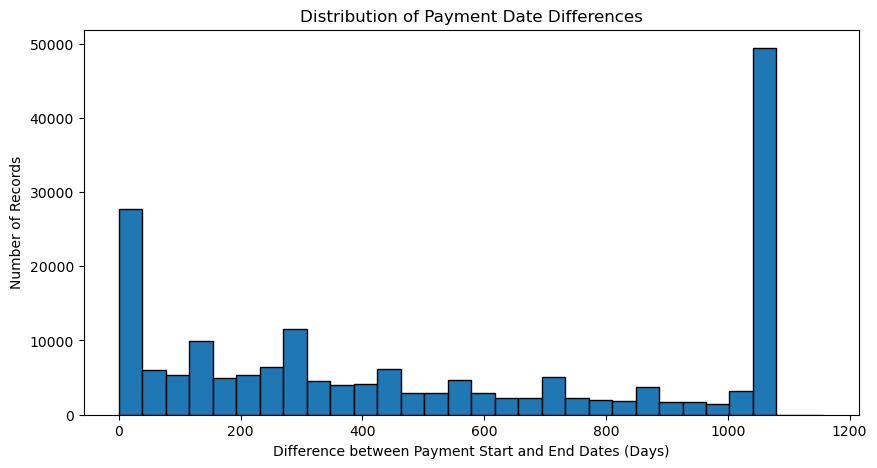

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    payment_date_analysis['Payment_Date_Difference'],
    bins=30,
    edgecolor='black'
)

plt.title('Distribution of Payment Date Differences')
plt.xlabel('Difference between Payment Start and End Dates (Days)')
plt.ylabel('Number of Records')

plt.show()

#### Payment Date Difference – Histogram and Frequency Analysis

**Objective:**
To understand the distribution of the difference between `paymt_str_dt` and `paymt_end_dt` and identify recurring date intervals.

**Histogram observations:**

1. The distribution is not uniform. Several noticeable concentrations appear across the date differences.
2. A large concentration occurs around zero days, representing records where payment start and end dates are identical.
3. The largest concentration occurs around 1,064–1,066 days, indicating a recurring interval of approximately three years.
4. Smaller concentrations are visible across intervals ranging from approximately 30 to 900 days.
5. The distribution contains multiple peaks rather than following a smooth pattern.

**Frequency analysis observations:**

1. The most frequent difference is 1,065 days, appearing in 21,624 records.
2. Zero-day differences occur in 21,408 records.
3. Differences of 1,064, 1,065 and 1,066 days collectively account for 45,698 records, approximately 24.5% of comparable records.
4. Other recurring differences include 31, 61, 92, 153, 212, 243, 273, 304 and 365 days.

**Conclusion:**

The payment date difference exhibits distinct recurring intervals, particularly around zero days and approximately 1,065 days. This suggests systematic patterns in the payment date fields rather than a uniform distribution.

The meaning of these recurring intervals and the unusual chronological relationship between the payment start and end dates require further investigation. No changes have been made to the original dataset.


In [49]:
# Find the 15 most frequent payment date differences

payment_date_analysis['Payment_Date_Difference'].value_counts().head(15)

Payment_Date_Difference
1065    21624
0       21408
1064    18162
1066     5912
61       4076
212      3830
304      3746
273      3744
365      3586
31       3520
243      3195
1067     2926
92       2810
334      2556
153      2429
Name: count, dtype: int64

In [50]:
# Identify records with date differences between 1064 and 1066 days

difference_mask = payment_date_analysis[
    'Payment_Date_Difference'
].between(1064, 1066)

# Count the records
print("Number of records:", difference_mask.sum())

print(
    "Percentage of comparable records:",
    round((difference_mask.sum() / len(payment_date_analysis)) * 100, 2),
    "%"
)

# Get the original account records
sample_indices = payment_date_analysis.index[difference_mask][:20]

display(
    account_df.loc[
        sample_indices,
        [
            'customer_no',
            'acct_type',
            'opened_dt',
            'reporting_dt',
            'paymt_str_dt',
            'paymt_end_dt'
        ]
    ].join(
        payment_date_analysis[['Payment_Date_Difference']],
        how='left'
    )
)

Number of records: 45698
Percentage of comparable records: 24.53 %


,customer_no,acct_type,opened_dt,reporting_dt,paymt_str_dt,paymt_end_dt,Payment_Date_Difference
1,12265,10,25-May-12,03-Oct-15,01-Oct-15,01-Nov-12,1064
2,12265,10,22-Mar-12,30-Sep-15,01-Sep-15,01-Oct-12,1065
10,15606,1,29-Nov-07,31-Dec-11,01-Dec-11,01-Jan-09,1064
11,15606,10,23-Aug-07,28-Feb-14,01-Nov-11,01-Dec-08,1065
16,15606,13,23-Nov-05,31-Jan-10,01-Nov-08,01-Dec-05,1066
21,11742,13,30-Jun-12,31-Jan-14,01-Jan-14,01-Feb-11,1065
22,12379,10,24-Aug-07,31-May-15,01-Jan-14,01-Feb-11,1065
29,12379,7,22-Aug-12,31-Jan-14,01-Jan-14,01-Feb-11,1065
30,12379,10,28-Aug-10,17-Jul-15,01-Jul-15,01-Aug-12,1064
31,12379,10,11-Mar-09,17-Jul-15,01-Jul-15,01-Aug-12,1064


In [51]:
# Get all records with payment date differences between 1064 and 1066 days

records_1064_1066 = account_df.loc[
    payment_date_analysis.index[difference_mask],
    ['acct_type']
].copy()

# Account-type distribution within the selected records
selected_counts = (
    records_1064_1066['acct_type']
    .value_counts()
)

selected_percentage = (
    records_1064_1066['acct_type']
    .value_counts(normalize=True) * 100
)

# Account-type distribution in the complete dataset
overall_percentage = (
    account_df['acct_type']
    .value_counts(normalize=True) * 100
)

# Combine the results
account_type_comparison = pd.DataFrame({
    'Selected_Count': selected_counts,
    'Selected_Percentage': selected_percentage,
    'Overall_Percentage': overall_percentage
}).fillna(0)

account_type_comparison = account_type_comparison.sort_values(
    by='Selected_Count',
    ascending=False
)

display(account_type_comparison.round(2))

,Selected_Count,Selected_Percentage,Overall_Percentage
acct_type,,,
10,27685.0,60.58,53.80
5,6302.0,13.79,12.30
1,2641.0,5.78,5.06
6,2402.0,5.26,13.77
2,1840.0,4.03,3.03
13,1755.0,3.84,4.60
7,1217.0,2.66,2.28
0,530.0,1.16,2.12
12,230.0,0.50,0.64


In [52]:
# Total records in each account type
total_by_account_type = account_df['acct_type'].value_counts()

# Records with date differences between 1064 and 1066 days
selected_by_account_type = (
    account_df.loc[
        payment_date_analysis.index[difference_mask],
        'acct_type'
    ].value_counts()
)

# Combine both counts
account_type_prevalence = pd.DataFrame({
    'Total_Records': total_by_account_type,
    'Selected_Records': selected_by_account_type
}).fillna(0)

# Calculate prevalence within each account type
account_type_prevalence['Prevalence_Percentage'] = (
    account_type_prevalence['Selected_Records'] /
    account_type_prevalence['Total_Records']
) * 100

# Sort by prevalence
account_type_prevalence = account_type_prevalence.sort_values(
    by='Prevalence_Percentage',
    ascending=False
)

display(account_type_prevalence.round(2))

,Total_Records,Selected_Records,Prevalence_Percentage
acct_type,,,
54,73,38.0,52.05
55,17,8.0,47.06
8,407,187.0,45.95
14,5,2.0,40.00
2,5639,1840.0,32.63
7,4256,1217.0,28.59
1,9427,2641.0,28.02
35,54,15.0,27.78
10,100239,27685.0,27.62


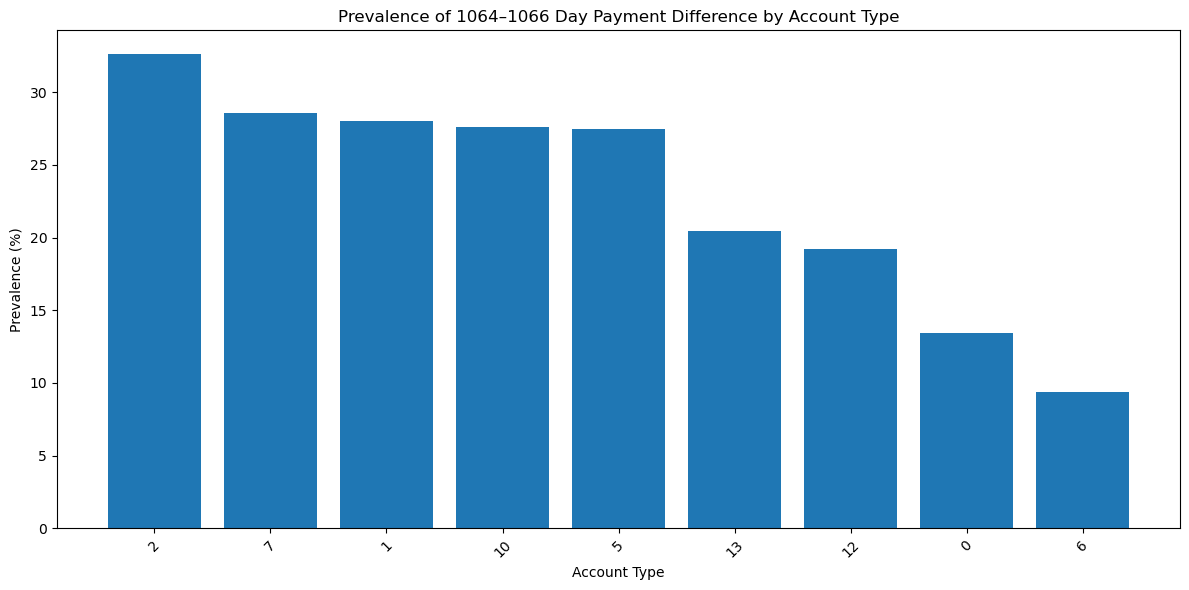

In [53]:
# Filter account types with at least 1,000 records

reliable_account_types = account_type_prevalence[
    account_type_prevalence['Total_Records'] >= 1000
].sort_values(
    by='Prevalence_Percentage',
    ascending=False
)

# Plot prevalence
plt.figure(figsize=(12, 6))

plt.bar(
    reliable_account_types.index.astype(str),
    reliable_account_types['Prevalence_Percentage']
)

plt.title('Prevalence of 1064–1066 Day Payment Difference by Account Type')
plt.xlabel('Account Type')
plt.ylabel('Prevalence (%)')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [54]:
# Calculate calendar-month difference between payment dates

payment_date_analysis['Payment_Month_Difference'] = (
    (payment_date_analysis['paymt_str_dt'].dt.year -
     payment_date_analysis['paymt_end_dt'].dt.year) * 12
    +
    (payment_date_analysis['paymt_str_dt'].dt.month -
     payment_date_analysis['paymt_end_dt'].dt.month)
)

# Filter records with a difference of 1064–1066 days
selected_records = payment_date_analysis[
    payment_date_analysis['Payment_Date_Difference'].between(1064, 1066)
]

# Examine the calendar-month differences
display(
    selected_records['Payment_Month_Difference']
    .value_counts()
    .sort_index()
)

Payment_Month_Difference
35    45698
Name: count, dtype: int64

In [55]:
# Check the day component of both payment dates

print("Payment start day distribution:")

display(
    selected_records['paymt_str_dt']
    .dt.day
    .value_counts()
    .sort_index()
)

print("Payment end day distribution:")

display(
    selected_records['paymt_end_dt']
    .dt.day
    .value_counts()
    .sort_index()
)

Payment start day distribution:


paymt_str_dt
1    45698
Name: count, dtype: int64

Payment end day distribution:


paymt_end_dt
1    45698
Name: count, dtype: int64

### Investigation of the 1,064–1,066 Day Payment Date Pattern

**Objective:**
To investigate the recurring concentration of payment date differences between 1,064 and 1,066 days.

**Findings:**

1. A total of 45,698 records (24.53% of comparable records) have a payment date difference between 1,064 and 1,066 days.
2. All 45,698 records have exactly 35 calendar months between `paymt_str_dt` and `paymt_end_dt`.
3. Both payment dates fall on the first day of their respective months in all selected records.
4. The difference in calendar days varies between 1,064 and 1,066 days because calendar months have different lengths.
5. The pattern occurs across multiple account types, although its prevalence varies between account types.
6. Account type 6 has a noticeably lower prevalence (9.36%) than several other major account types.

**Conclusion:**

The concentration around 1,064–1,066 days represents a systematic 35-calendar-month interval rather than random date differences.

The recurring first-of-month pattern suggests a structured date-recording convention in the source data. However, the underlying business meaning of these dates has not yet been established.

The original dataset remains unchanged. Any decisions about handling these columns will be deferred until the preprocessing and feature-engineering phases.


In [56]:
# Extract account opening and closing dates

account_lifecycle_df = date_analysis_df[
    ['opened_dt', 'closed_dt']
].copy()

# Count account openings by year
yearly_openings = (
    account_lifecycle_df['opened_dt']
    .dropna()
    .dt.year
    .value_counts()
    .sort_index()
)

# Count account closures by year
yearly_closures = (
    account_lifecycle_df['closed_dt']
    .dropna()
    .dt.year
    .value_counts()
    .sort_index()
)

# Combine both summaries
account_lifecycle_summary = pd.DataFrame({
    'Account_Openings': yearly_openings,
    'Account_Closures': yearly_closures
}).fillna(0).astype(int)

display(account_lifecycle_summary)

,Account_Openings,Account_Closures
1979,1,0
1984,1,0
1985,2,0
1988,1,0
1989,1,0
1990,5,0
1991,14,0
1992,22,0
1993,35,1
1994,60,0


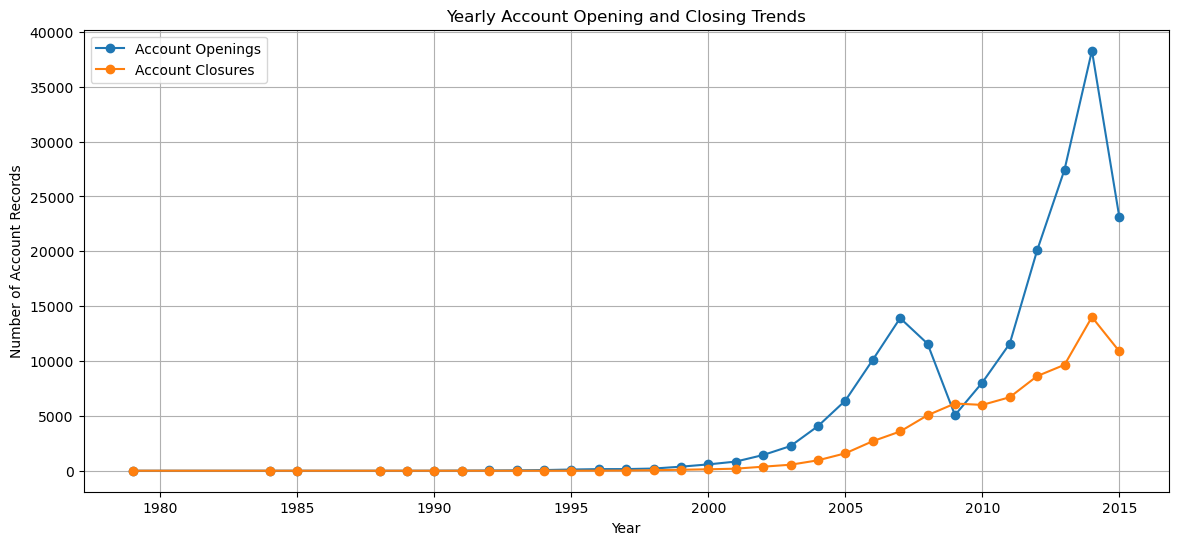

In [57]:
# Plot account opening and closing trends

plt.figure(figsize=(14, 6))

plt.plot(
    account_lifecycle_summary.index,
    account_lifecycle_summary['Account_Openings'],
    marker='o',
    label='Account Openings'
)

plt.plot(
    account_lifecycle_summary.index,
    account_lifecycle_summary['Account_Closures'],
    marker='o',
    label='Account Closures'
)

plt.title('Yearly Account Opening and Closing Trends')
plt.xlabel('Year')
plt.ylabel('Number of Account Records')
plt.legend()
plt.grid(True)

plt.show()

### Account Opening and Closing Trends

**Objective:**

To understand historical account opening and closing patterns using `opened_dt` and `closed_dt`.

**Account opening observations:**

1. Account openings generally increased over the historical period.
2. A noticeable decline occurred between 2007 and 2009.
3. Openings recovered from 2010 onwards.
4. The highest number of account openings occurred in 2014, with 38,285 records.
5. Account openings declined to 23,107 in 2015.

**Account closing observations:**

1. Account closures generally increased over time.
2. A noticeable increase occurred between 2008 and 2009.
3. Closures reached 14,009 records in 2014, the highest value in the observed period.
4. Closures declined to 10,883 in 2015.

**Key findings:**

1. The 2009 period experienced a decline in account openings alongside an increase in account closures.
2. The 2012–2014 period experienced substantial growth in account openings.
3. Both account openings and closures reached their highest recorded values in 2014.
4. Both measures declined in 2015. The possibility of incomplete year coverage should be considered before interpreting this decline.

**Conclusion:**

The historical data shows substantial growth in account openings and closures, particularly between 2010 and 2014. The year 2014 recorded the highest activity for both measures.

These are descriptive observations. The underlying reasons for the changes cannot be established from this analysis alone.


In [58]:
# Select the columns with the highest missing percentages
high_missing_cols = missing_summary.head(8).index.tolist()

# Calculate the number of records in each account type
account_type_counts = account_df['acct_type'].value_counts().sort_index()

# Create a compact missing-value summary by account type
missing_by_type_summary = (
    account_df
    .groupby('acct_type')[high_missing_cols]
    .apply(lambda group: group.isnull().mean() * 100)
)

# Add the number of records for each account type
missing_by_type_summary.insert(
    0,
    'Record_Count',
    account_type_counts
)

display(missing_by_type_summary.round(2))

,Record_Count,amt_past_due,rateofinterest,cashlimit,actualpaymentamount,creditlimit,paymentfrequency,closed_dt,paymenthistory2
acct_type,,,,,,,,,
0,3944,99.65,59.79,100.00,95.18,100.00,75.99,53.68,84.94
1,9427,99.29,84.46,100.00,73.13,100.00,64.86,52.37,46.77
2,5639,98.46,67.69,100.00,80.76,100.00,56.89,68.51,43.08
3,672,98.81,81.70,100.00,89.58,100.00,59.97,63.69,60.86
4,188,98.40,72.87,100.00,98.94,100.00,93.62,37.23,80.32
5,22921,99.71,89.98,100.00,79.56,100.00,70.43,40.04,58.62
6,25664,99.62,97.53,100.00,99.85,100.00,96.96,37.39,93.17
7,4256,99.79,91.00,100.00,92.97,100.00,85.71,25.19,97.25
8,407,99.26,40.05,100.00,90.66,100.00,52.33,58.72,28.75


In [59]:
# Keep account types with at least 100 records
reliable_account_types = missing_by_type_summary[
    missing_by_type_summary['Record_Count'] >= 100
]

display(reliable_account_types.round(2))

,Record_Count,amt_past_due,rateofinterest,cashlimit,actualpaymentamount,creditlimit,paymentfrequency,closed_dt,paymenthistory2
acct_type,,,,,,,,,
0,3944,99.65,59.79,100.00,95.18,100.00,75.99,53.68,84.94
1,9427,99.29,84.46,100.00,73.13,100.00,64.86,52.37,46.77
2,5639,98.46,67.69,100.00,80.76,100.00,56.89,68.51,43.08
3,672,98.81,81.70,100.00,89.58,100.00,59.97,63.69,60.86
4,188,98.40,72.87,100.00,98.94,100.00,93.62,37.23,80.32
5,22921,99.71,89.98,100.00,79.56,100.00,70.43,40.04,58.62
6,25664,99.62,97.53,100.00,99.85,100.00,96.96,37.39,93.17
7,4256,99.79,91.00,100.00,92.97,100.00,85.71,25.19,97.25
8,407,99.26,40.05,100.00,90.66,100.00,52.33,58.72,28.75


### Missing Value Analysis – Cust_Account

#### 1. Dataset Overview
- Total records: 186,329
- Total columns: 21

#### 2. Overall Missing Value Analysis

The following columns have the highest percentages of missing values:

| Column | Missing Percentage |
|---|---:|
| amt_past_due | 99.53% |
| rateofinterest | 86.67% |
| cashlimit | 81.06% |
| actualpaymentamount | 77.97% |
| creditlimit | 73.78% |
| paymentfrequency | 65.71% |
| closed_dt | 58.54% |
| paymenthistory2 | 57.87% |

### 3. Missing Values Across Account Types

Further investigation was performed to understand how missing values are distributed across different account types.

Key observations:

- **amt_past_due:** Consistently high missingness across almost all account types (approximately 98–100%).
- **rateofinterest:** Missingness varies considerably across account types.
- **cashlimit and creditlimit:** Almost entirely missing for most account types. Account type 10 has considerably more available information.
- **actualpaymentamount:** Shows substantial variations in missingness across account types.
- **paymentfrequency:** Missingness varies considerably between account types.
- **closed_dt:** Missingness varies across account types.
- **paymenthistory2:** Shows considerable variations in missingness across account types.

#### 4. Account Type Distribution

Account type 10 contains 100,239 records, representing approximately 53.8% of the entire dataset.

It also has considerably more available information for certain variables, particularly `cashlimit` and `creditlimit`.

#### 5. Key Findings and Conclusion

- Missing values are not uniformly distributed across the dataset.
- Several variables exhibit different missing-value patterns across account types.
- Some variables, particularly `amt_past_due`, have extremely high missingness across almost all account types.
- Account type should be considered when investigating missing-value patterns during preprocessing.

**EDA Decision:** Retain the original data for further investigation. Missing-value treatment and decisions regarding feature removal or retention will be addressed during the preprocessing and feature-selection phases.

No missing values were removed or imputed during this analysis. The original dataset remains unchanged.

#### 6. Status

- Overall missing-value analysis: Completed
- Missingness by account type: Completed
- Interpretation of missingness patterns: Completed

**Next Task:** Duplicate-pattern analysis for `Cust_Account`.

In [60]:
# Count exact duplicate rows
duplicate_count = account_df.duplicated().sum()

# Calculate duplicate percentage
duplicate_percentage = (
    duplicate_count / len(account_df)
) * 100

print("Total records:", len(account_df))
print("Exact duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_percentage, 2))

Total records: 186329
Exact duplicate rows: 2401
Duplicate percentage: 1.29


In [61]:
# Extract all occurrences of duplicated rows
duplicate_records = account_df[
    account_df.duplicated(keep=False)
]

# Display the first 20 duplicate records
display(duplicate_records.head(20))

,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,...,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
76,27-Aug-15,17744,10-Aug-15,10,1,22-Aug-14,25-Jun-15,NaN,11-Jul-15,15702.0,...,NaN,"""""""000000000000000000000000000000000""""""",NaN,01-Jul-15,01-Sep-14,116000.0,34800.0,NaN,3.0,810.0
77,27-Aug-15,17744,10-Aug-15,5,1,05-May-14,05-May-15,NaN,31-May-15,100000.0,...,NaN,"""""""000000000000000""""""",NaN,01-May-15,01-Jan-15,NaN,NaN,NaN,NaN,NaN
78,27-Aug-15,17744,10-Aug-15,10,1,08-May-13,10-Jun-15,NaN,30-Jun-15,28261.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000""""""",01-Jun-15,01-May-13,NaN,NaN,NaN,NaN,NaN
79,27-Aug-15,17744,10-Aug-15,10,1,19-Mar-12,29-Jun-15,NaN,30-Jun-15,25523.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Jun-15,01-Jul-12,73000.0,NaN,39.0,NaN,1000.0
80,27-Aug-15,17744,10-Aug-15,10,1,22-Aug-14,25-Jun-15,NaN,11-Jul-15,15702.0,...,NaN,"""""""000000000000000000000000000000000""""""",NaN,01-Jul-15,01-Sep-14,116000.0,34800.0,NaN,3.0,810.0
81,27-Aug-15,17744,10-Aug-15,5,1,05-May-14,05-May-15,NaN,31-May-15,100000.0,...,NaN,"""""""000000000000000""""""",NaN,01-May-15,01-Jan-15,NaN,NaN,NaN,NaN,NaN
82,27-Aug-15,17744,10-Aug-15,10,1,08-May-13,10-Jun-15,NaN,30-Jun-15,28261.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000""""""",01-Jun-15,01-May-13,NaN,NaN,NaN,NaN,NaN
83,27-Aug-15,17744,10-Aug-15,10,1,19-Mar-12,29-Jun-15,NaN,30-Jun-15,25523.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Jun-15,01-Jul-12,73000.0,NaN,39.0,NaN,1000.0
377,06-Nov-15,4920,29-Oct-15,10,1,04-May-06,NaN,04-May-06,30-Sep-06,NaN,...,NaN,"""""""000""""""",NaN,01-May-06,01-May-06,NaN,NaN,NaN,NaN,NaN
378,06-Nov-15,4920,29-Oct-15,10,1,04-May-06,NaN,04-May-06,30-Sep-06,NaN,...,NaN,"""""""000""""""",NaN,01-May-06,01-May-06,NaN,NaN,NaN,NaN,NaN


In [62]:

# Group identical records and count their occurrences
duplicate_groups = (
    duplicate_records
    .groupby(list(account_df.columns), dropna=False)
    .size()
    .reset_index(name='Occurrence_Count')
)

# Summary of duplicate groups
print("Total duplicate groups:", len(duplicate_groups))

print(
    "Total records involved in duplicate groups:",
    duplicate_groups['Occurrence_Count'].sum()
)

print(
    "Maximum repetitions of a single record:",
    duplicate_groups['Occurrence_Count'].max()
)

display(duplicate_groups['Occurrence_Count'].value_counts().sort_index())

Total duplicate groups: 2207
Total records involved in duplicate groups: 4608
Maximum repetitions of a single record: 10


Occurrence_Count
2     2064
3      107
4       31
5        2
6        1
9        1
10       1
Name: count, dtype: int64

## Duplicate-Pattern Analysis – Cust_Account

### 1. Dataset Overview
- Total records: 186,329
- Total columns: 21

### 2. Exact Duplicate Analysis

The initial investigation identified 2,401 exact duplicate rows, representing approximately 1.29% of the dataset.

### 3. Duplicate Group Analysis

Further investigation identified 2,207 distinct duplicate groups involving 4,608 records.

The distribution of duplicate groups is:

| Occurrences of Identical Record | Number of Groups |
|---:|---:|
| 2 | 2,064 |
| 3 | 107 |
| 4 | 31 |
| 5 | 2 |
| 6 | 1 |
| 9 | 1 |
| 10 | 1 |
| **Total** | **2,207** |

### 4. Key Findings

- Most duplicate groups contain two identical records.
- A small number of records appear three or more times.
- The maximum number of occurrences of a single identical record is 10.
- The dataset contains 2,401 additional duplicate rows.
- Repeated customer numbers do not necessarily indicate duplicate records because customers can have multiple accounts.

### 5. Conclusion

The investigation identified exact duplicate records in the Cust_Account dataset.

Approximately 1.29% of the dataset consists of additional occurrences of identical records.

These duplicates should be considered during data preprocessing. However, no records were removed during EDA.

The original dataset remains unchanged.


In [63]:
#Cust_Enquiry
# Identify numerical columns
# Identify numerical variables based on their actual meaning
numeric_cols = ['enq_amt']

# Descriptive statistics
display(enquiry_df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
enq_amt,413078.0,828909.435506,1.204328e+07,1.0,10000.0,50000.0,143000.0,999999999.0


In [64]:
# Descriptive statistics of numerical variables
display(enquiry_df[numeric_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
enq_amt,413078.0,828909.435506,1.204328e+07,1.0,10000.0,50000.0,143000.0,999999999.0


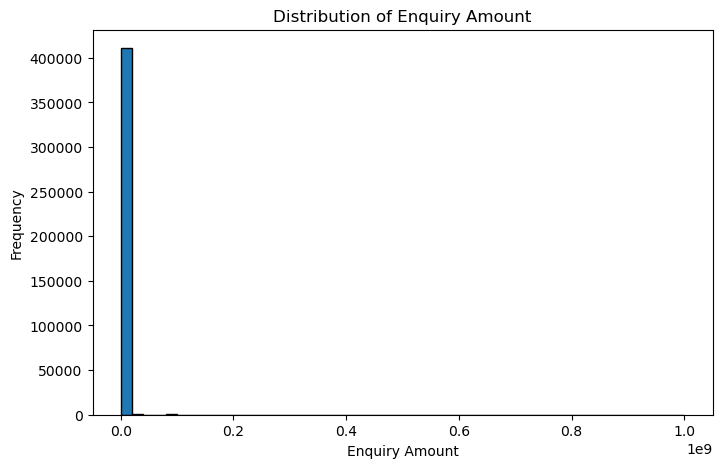

In [65]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    enquiry_df['enq_amt'].dropna(),
    bins=50,
    edgecolor='black'
)

plt.title('Distribution of Enquiry Amount')
plt.xlabel('Enquiry Amount')
plt.ylabel('Frequency')

plt.show()

In [66]:
# Frequency distribution of enquiry purposes
enquiry_purpose_counts = (
    enquiry_df['enq_purpose']
    .value_counts()
    .sort_index()
)

display(enquiry_purpose_counts)

enq_purpose
0.0      15048
1.0      23708
2.0      15576
3.0       1728
4.0        280
5.0      81881
6.0      17426
7.0       1351
8.0        563
9.0         51
10.0    238150
11.0        13
12.0      1000
13.0     11179
14.0        95
15.0        13
16.0         2
17.0       410
31.0         3
32.0       170
33.0        14
34.0         3
35.0        19
36.0         6
40.0        22
41.0         7
43.0         6
51.0      3942
52.0       130
53.0        72
54.0       154
55.0        12
56.0        13
57.0        10
58.0         6
59.0        15
Name: count, dtype: int64

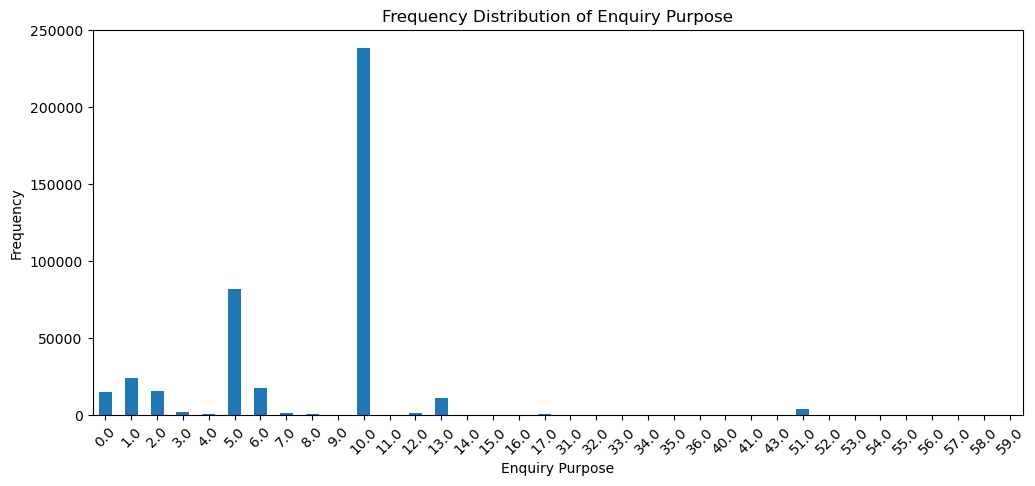

In [67]:
plt.figure(figsize=(12, 5))

enquiry_purpose_counts.plot(kind='bar')

plt.title('Frequency Distribution of Enquiry Purpose')
plt.xlabel('Enquiry Purpose')
plt.ylabel('Frequency')

plt.xticks(rotation=45)
plt.show()

## Categorical Variable Analysis – Cust_Enquiry

### 1. Variable Identification

`enq_purpose` was initially identified as a numerical variable based on its Pandas data type. However, after examining its meaning, it was correctly classified as a categorical variable.

Although its values are stored as numbers, they represent enquiry-purpose codes rather than measurable quantities.

### 2. Frequency Distribution

The frequency distribution revealed 36 distinct enquiry-purpose categories.

The most frequent categories are:

| Enquiry Purpose | Frequency | Percentage |
|---:|---:|---:|
| 10 | 238,150 | 57.65% |
| 5 | 81,881 | 19.82% |
| 1 | 23,708 | 5.74% |
| 6 | 17,426 | 4.22% |
| 2 | 15,576 | 3.77% |
| 0 | 15,048 | 3.64% |
| 13 | 11,179 | 2.71% |
| 51 | 3,942 | 0.95% |

### 3. Key Observations

- Enquiry-purpose code 10 is the most frequent category, representing approximately 57.65% of records.
- Code 5 is the second most frequent category, representing approximately 19.82%.
- The distribution is highly imbalanced, with a few categories accounting for most enquiry records.
- Several categories have very low frequencies.
- The actual business meanings of the enquiry-purpose codes have not yet been established.

### 4. Conclusion

The `enq_purpose` variable is categorical despite being stored numerically.

The frequency distribution indicates that enquiry records are concentrated in a small number of categories.

The category codes should be interpreted using a data dictionary or appropriate business documentation.

No records or values were modified during this analysis.


In [68]:
# Examine the distribution of enquiry amounts at higher percentiles
enquiry_df['enq_amt'].quantile(
    [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.00]
)

0.500        50000.0
0.750       143000.0
0.900       500000.0
0.950      1000000.0
0.990      6500000.0
0.995     25000000.0
0.999    100000000.0
1.000    999999999.0
Name: enq_amt, dtype: float64

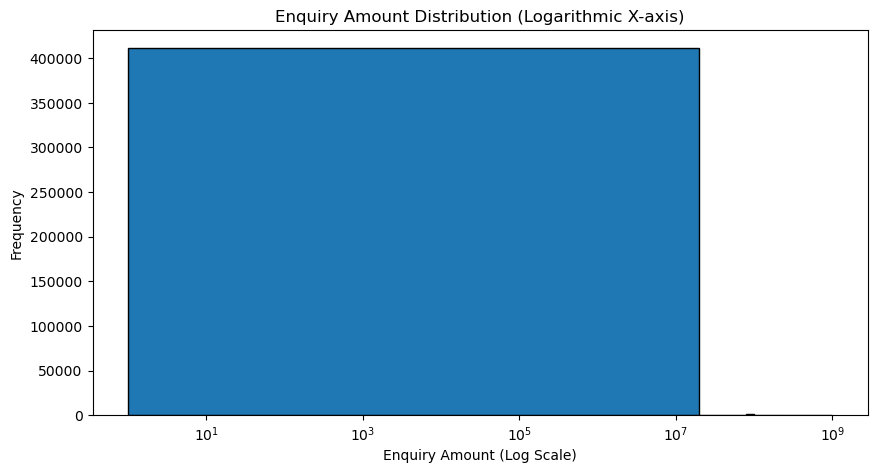

In [69]:
plt.figure(figsize=(10, 5))

plt.hist(
    enquiry_df['enq_amt'].dropna(),
    bins=50,
    edgecolor='black'
)

plt.xscale('log')

plt.title('Enquiry Amount Distribution (Logarithmic X-axis)')
plt.xlabel('Enquiry Amount (Log Scale)')
plt.ylabel('Frequency')

plt.show()

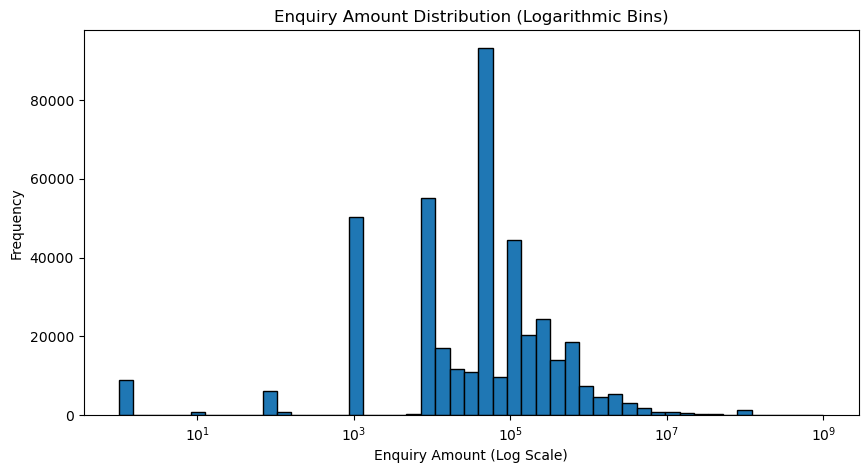

In [70]:
# Select positive, non-missing enquiry amounts
enq_amounts = enquiry_df['enq_amt'].dropna()
enq_amounts = enq_amounts[enq_amounts > 0]

# Generate logarithmically spaced bins
log_bins = np.logspace(
    np.log10(enq_amounts.min()),
    np.log10(enq_amounts.max()),
    50
)

plt.figure(figsize=(10, 5))

plt.hist(
    enq_amounts,
    bins=log_bins,
    edgecolor='black'
)

plt.xscale('log')

plt.title('Enquiry Amount Distribution (Logarithmic Bins)')
plt.xlabel('Enquiry Amount (Log Scale)')
plt.ylabel('Frequency')

plt.show()

## Numerical Variable Analysis – Cust_Enquiry

### 1. Variable Identification

The `enq_amt` column was identified as the numerical variable for this analysis.

The `enq_purpose` column was excluded because it represents categorical enquiry-purpose codes, despite being stored numerically.

### 2. Descriptive Statistics

| Statistic | Value |
|---|---:|
| Count | 413,078 |
| Mean | 828,909.44 |
| Standard Deviation | 12,043,280 |
| Minimum | 1 |
| Median | 50,000 |
| 75th Percentile | 143,000 |
| Maximum | 999,999,999 |

### 3. Percentile Analysis

| Percentile | Enquiry Amount |
|---|---:|
| 50th | 50,000 |
| 75th | 143,000 |
| 90th | 500,000 |
| 95th | 1,000,000 |
| 99th | 6,500,000 |
| 99.5th | 25,000,000 |
| 99.9th | 100,000,000 |
| 100th | 999,999,999 |

### 4. Key Observations

- The mean is considerably higher than the median, indicating a strongly right-skewed distribution.
- Approximately 75% of enquiry amounts are at or below 143,000.
- The 99th percentile is 6.5 million, while the maximum reaches 999,999,999.
- The logarithmic histogram reveals multiple concentration peaks across different enquiry-amount ranges.
- A small number of extreme values extend towards one billion.

### 5. Conclusion

The `enq_amt` variable has a highly right-skewed distribution with a long upper tail.

The extreme values require further investigation during the outlier-analysis stage.

No values were removed, modified or transformed during this analysis.

In [71]:
# Identify date-related columns
date_cols = [
    'dt_opened',
    'upload_dt',
    'enquiry_dt'
]

# Inspect data types
print("Date column data types:")
display(enquiry_df[date_cols].dtypes)

# Inspect sample values
print("Sample date values:")
display(enquiry_df[date_cols].head(10))

Date column data types:


dt_opened     object
upload_dt     object
enquiry_dt    object
dtype: object

Sample date values:


,dt_opened,upload_dt,enquiry_dt
0,18-Apr-15,21-Apr-15,19-Dec-14
1,18-Apr-15,21-Apr-15,05-Mar-14
2,18-Apr-15,21-Apr-15,05-Mar-14
3,18-Apr-15,21-Apr-15,22-Feb-14
4,18-Apr-15,21-Apr-15,11-Jun-13
5,18-Apr-15,21-Apr-15,08-Feb-13
6,18-Apr-15,21-Apr-15,30-Nov-12
7,18-Apr-15,21-Apr-15,30-May-12
8,18-Apr-15,21-Apr-15,24-May-11
9,18-Apr-15,21-Apr-15,10-Nov-10


In [72]:
# Create a separate DataFrame for date analysis
enquiry_date_df = enquiry_df[date_cols].copy()

# Convert date columns into datetime format
for col in date_cols:
    enquiry_date_df[col] = pd.to_datetime(
        enquiry_date_df[col],
        format='%d-%b-%y',
        errors='coerce'
    )

# Inspect converted data types
display(enquiry_date_df.dtypes)

# Display sample converted dates
display(enquiry_date_df.head(10))


dt_opened     datetime64[ns]
upload_dt     datetime64[ns]
enquiry_dt    datetime64[ns]
dtype: object

,dt_opened,upload_dt,enquiry_dt
0,2015-04-18,2015-04-21,2014-12-19
1,2015-04-18,2015-04-21,2014-03-05
2,2015-04-18,2015-04-21,2014-03-05
3,2015-04-18,2015-04-21,2014-02-22
4,2015-04-18,2015-04-21,2013-06-11
5,2015-04-18,2015-04-21,2013-02-08
6,2015-04-18,2015-04-21,2012-11-30
7,2015-04-18,2015-04-21,2012-05-30
8,2015-04-18,2015-04-21,2011-05-24
9,2015-04-18,2015-04-21,2010-11-10


In [73]:
# Compare missing values before and after conversion
date_validation = pd.DataFrame({
    'Original_Missing': enquiry_df[date_cols].isna().sum(),
    'Converted_Missing': enquiry_date_df[date_cols].isna().sum()
})

date_validation['Invalid_Dates'] = (
    date_validation['Converted_Missing']
    - date_validation['Original_Missing']
)

display(date_validation)

,Original_Missing,Converted_Missing,Invalid_Dates
dt_opened,0,0,0
upload_dt,110,110,0
enquiry_dt,110,110,0


In [74]:
# Generate date range summary
date_range_summary = pd.DataFrame({
    'Minimum_Date': enquiry_date_df[date_cols].min(),
    'Maximum_Date': enquiry_date_df[date_cols].max(),
    'Unique_Dates': enquiry_date_df[date_cols].nunique()
})

display(date_range_summary)

,Minimum_Date,Maximum_Date,Unique_Dates
dt_opened,2015-04-16,2015-12-31,197
upload_dt,2015-04-21,2015-12-31,75
enquiry_dt,2004-07-22,2015-12-23,3771


In [75]:
# Select records with all three dates available
date_relationship_df = enquiry_date_df.dropna(
    subset=date_cols
).copy()

# Compare chronological relationships
print(
    "Enquiry date after upload date:",
    (date_relationship_df['enquiry_dt'] >
     date_relationship_df['upload_dt']).sum()
)

print(
    "Upload date after opening date:",
    (date_relationship_df['upload_dt'] >
     date_relationship_df['dt_opened']).sum()
)

print(
    "Enquiry date after opening date:",
    (date_relationship_df['enquiry_dt'] >
     date_relationship_df['dt_opened']).sum()
)

print(
    "Records with all three dates:",
    len(date_relationship_df)
)

Enquiry date after upload date: 0
Upload date after opening date: 1755
Enquiry date after opening date: 0
Records with all three dates: 413078


In [76]:
# Calculate differences between dates
date_relationship_df['Enquiry_to_Opening_Days'] = (
    date_relationship_df['dt_opened'] -
    date_relationship_df['enquiry_dt']
).dt.days

date_relationship_df['Opening_to_Upload_Days'] = (
    date_relationship_df['upload_dt'] -
    date_relationship_df['dt_opened']
).dt.days

date_relationship_df['Enquiry_to_Upload_Days'] = (
    date_relationship_df['upload_dt'] -
    date_relationship_df['enquiry_dt']
).dt.days

# Generate descriptive statistics
display(
    date_relationship_df[
        [
            'Enquiry_to_Opening_Days',
            'Opening_to_Upload_Days',
            'Enquiry_to_Upload_Days'
        ]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
Enquiry_to_Opening_Days,413078.0,1098.771578,946.149277,2.0,334.0,783.0,1665.0,4054.0
Opening_to_Upload_Days,413078.0,-23.450012,20.657951,-238.0,-28.0,-18.0,-11.0,34.0
Enquiry_to_Upload_Days,413078.0,1075.321566,945.573130,1.0,310.0,760.0,1641.0,4032.0


In [77]:
# Identify records where upload date is after opening date
upload_after_opening = date_relationship_df[
    date_relationship_df['Opening_to_Upload_Days'] > 0
]

print("Records with upload after opening:",
      len(upload_after_opening))

display(upload_after_opening.head(20))

Records with upload after opening: 1755


,dt_opened,upload_dt,enquiry_dt,Enquiry_to_Opening_Days,Opening_to_Upload_Days,Enquiry_to_Upload_Days
0,2015-04-18,2015-04-21,2014-12-19,120,3,123
1,2015-04-18,2015-04-21,2014-03-05,409,3,412
2,2015-04-18,2015-04-21,2014-03-05,409,3,412
3,2015-04-18,2015-04-21,2014-02-22,420,3,423
4,2015-04-18,2015-04-21,2013-06-11,676,3,679
5,2015-04-18,2015-04-21,2013-02-08,799,3,802
6,2015-04-18,2015-04-21,2012-11-30,869,3,872
7,2015-04-18,2015-04-21,2012-05-30,1053,3,1056
8,2015-04-18,2015-04-21,2011-05-24,1425,3,1428
9,2015-04-18,2015-04-21,2010-11-10,1620,3,1623


In [78]:
# Select records where upload happened after opening
positive_upload_diff = date_relationship_df[
    date_relationship_df['Opening_to_Upload_Days'] > 0
]

# Summary statistics
print("Total records:", len(positive_upload_diff))

display(
    positive_upload_diff['Opening_to_Upload_Days']
    .describe()
)

# Frequency of each date difference
display(
    positive_upload_diff['Opening_to_Upload_Days']
    .value_counts()
    .sort_index()
)

Total records: 1755


count    1755.000000
mean        4.283761
std         8.381874
min         1.000000
25%         1.000000
50%         2.000000
75%         2.000000
max        34.000000
Name: Opening_to_Upload_Days, dtype: float64

Opening_to_Upload_Days
1     660
2     877
3      43
4       3
5       7
12      9
30    121
34     35
Name: count, dtype: int64

## Date-Related Variable Analysis – Cust_Enquiry

### 1. Date Columns Identified

Three date columns were identified:

- `dt_opened`
- `upload_dt`
- `enquiry_dt`

All three columns were initially stored as object data types.

### 2. Date Conversion and Validation

The date columns were converted into datetime format using the expected format `%d-%b-%y`.

Validation results:

| Column | Original Missing | Converted Missing | Invalid Dates |
|---|---:|---:|---:|
| dt_opened | 0 | 0 | 0 |
| upload_dt | 110 | 110 | 0 |
| enquiry_dt | 110 | 110 | 0 |

All available date values were successfully converted. No additional missing values were introduced.

### 3. Date Range Analysis

| Column | Minimum Date | Maximum Date | Unique Dates |
|---|---|---|---:|
| dt_opened | 2015-04-16 | 2015-12-31 | 197 |
| upload_dt | 2015-04-21 | 2015-12-31 | 75 |
| enquiry_dt | 2004-07-22 | 2015-12-23 | 3,771 |

**Observations:**

- `dt_opened` and `upload_dt` cover dates within 2015.
- `enquiry_dt` covers a longer historical period, beginning in 2004.
- The enquiry dataset therefore contains historical enquiry records.

### 4. Chronological Relationship Analysis

| Relationship | Records |
|---|---:|
| Enquiry date after upload date | 0 |
| Upload date after opening date | 1,755 |
| Enquiry date after opening date | 0 |

No enquiry dates were found after their corresponding upload dates or opening dates.

### 5. Investigation of Upload Dates After Opening Dates

A total of 1,755 records had an upload date later than the opening date.

| Statistic | Days |
|---|---:|
| Mean | 4.28 |
| Median | 2 |
| Minimum | 1 |
| Maximum | 34 |

Frequency distribution:

| Difference (Days) | Records |
|---:|---:|
| 1 | 660 |
| 2 | 877 |
| 3 | 43 |
| 4 | 3 |
| 5 | 7 |
| 12 | 9 |
| 30 | 121 |
| 34 | 35 |

**Observations:**

- Approximately 87.58% of these records have a difference of one or two days.
- A further 121 records have a difference of 30 days.
- The maximum observed difference is 34 days.
- These differences require business-context verification before being classified as data-quality errors.

### 6. Conclusion

The three date columns were successfully converted and validated.

The enquiry dates cover a substantially longer historical period than the opening and upload dates.

The chronological analysis identified 1,755 records where the upload date occurs after the opening date. Most of these differences are small, with a median of two days.

No date values were modified in the original dataset.

In [79]:
# Calculate missing values for each column
missing_summary = pd.DataFrame({
    'Missing_Count': enquiry_df.isna().sum(),
    'Missing_Percentage': (
        enquiry_df.isna().mean() * 100
    ),
    'Non_Missing_Count': enquiry_df.notna().sum()
})

# Sort by missing percentage
missing_summary = missing_summary.sort_values(
    by='Missing_Percentage',
    ascending=False
)

display(missing_summary.round(2))

,Missing_Count,Missing_Percentage,Non_Missing_Count
enquiry_dt,110,0.03,413078
upload_dt,110,0.03,413078
enq_purpose,110,0.03,413078
enq_amt,110,0.03,413078
customer_no,0,0.00,413188
dt_opened,0,0.00,413188


In [80]:
# Identify rows containing at least one missing value
missing_rows = enquiry_df[
    enquiry_df.isna().any(axis=1)
].copy()

print("Total rows containing missing values:", len(missing_rows))

# Examine missing-value combinations
missing_patterns = (
    enquiry_df.isna()
    .value_counts()
    .reset_index(name='Record_Count')
)

display(missing_patterns)

Total rows containing missing values: 110


,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt,Record_Count
0,False,False,False,False,False,False,413078
1,False,False,True,True,True,True,110


### Missing-Value Analysis – Cust_Enquiry

**1. Overall findings**

The `Cust_Enquiry` dataset contains 413,188 records and 6 columns. Four columns contain 110 missing values each, representing approximately 0.03% of the records.

* `enquiry_dt`: 110 missing values (0.03%)
* `upload_dt`: 110 missing values (0.03%)
* `enq_purpose`: 110 missing values (0.03%)
* `enq_amt`: 110 missing values (0.03%)
* `customer_no`: No missing values.
* `dt_opened`: No missing values.

**2. Missingness pattern investigation**

Further investigation confirmed that all four enquiry-related columns are missing in exactly the same 110 records.

The remaining 413,078 records contain complete values across all six columns.

**3. Key observations**

* Missing values are concentrated in 110 records.
* Customer identifiers and account opening dates are available for all records.
* Approximately 99.97% of the dataset contains complete enquiry information.
* The missingness pattern suggests that these records contain no corresponding enquiry details.

**4. Conclusion and decision**

The overall missing-value percentage is negligible. The 110 affected records will be retained for now. No missing values were removed or imputed during EDA.

The original dataset remains unchanged.


In [81]:
# Count exact duplicate records
duplicate_count = enquiry_df.duplicated().sum()

# Calculate duplicate percentage
duplicate_percentage = (
    duplicate_count / len(enquiry_df)
) * 100

print("Total records:", len(enquiry_df))
print("Exact duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_percentage, 2))

Total records: 413188
Exact duplicate rows: 13827
Duplicate percentage: 3.35


In [82]:
# Extract all occurrences of duplicated records
duplicate_records = enquiry_df[
    enquiry_df.duplicated(keep=False)
].copy()

# Group identical records and count their occurrences
duplicate_groups = (
    duplicate_records
    .groupby(list(enquiry_df.columns), dropna=False)
    .size()
    .reset_index(name='Occurrence_Count')
)

# Summary of duplicate groups
print("Total duplicate groups:", len(duplicate_groups))

print(
    "Total records involved in duplicate groups:",
    len(duplicate_records)
)

print(
    "Maximum repetitions of a single record:",
    duplicate_groups['Occurrence_Count'].max()
)

# Distribution of repetition counts
display(
    duplicate_groups['Occurrence_Count']
    .value_counts()
    .sort_index()
)

# Inspect sample duplicate records
display(duplicate_groups.head(20))

Total duplicate groups: 12330
Total records involved in duplicate groups: 26157
Maximum repetitions of a single record: 14


Occurrence_Count
2     11262
3       763
4       250
5        24
6        18
7         4
8         4
9         1
10        2
13        1
14        1
Name: count, dtype: int64

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt,Occurrence_Count
0,01-Aug-15,3307,30-Jul-15,10-Dec-13,5.0,200000.0,2
1,01-Aug-15,3307,30-Jul-15,13-Aug-14,5.0,300000.0,2
2,01-Aug-15,3307,30-Jul-15,14-Aug-14,5.0,300000.0,2
3,01-Aug-15,3310,23-Jul-15,15-Oct-09,10.0,50000.0,2
4,01-Aug-15,7949,30-Jul-15,27-Feb-07,2.0,3000000.0,2
5,01-Aug-15,7954,09-Jul-15,01-Sep-11,1.0,200000.0,2
6,01-Aug-15,7957,13-Jul-15,01-Nov-10,13.0,22000.0,2
7,01-Aug-15,7958,09-Jul-15,20-Aug-13,2.0,5500000.0,3
8,01-Aug-15,7960,30-Jul-15,17-Jun-14,5.0,115000.0,2
9,01-Aug-15,7966,06-Jul-15,07-Feb-15,5.0,300000.0,2


### Duplicate Analysis – Cust_Enquiry

**1. Overall findings**

The `Cust_Enquiry` dataset contains 413,188 records and 6 columns.

The exact duplicate analysis identified:

* Exact duplicate occurrences: 13,827
* Duplicate groups: 12,330
* Total records involved in duplicate groups: 26,157
* Maximum repetitions of a single identical record: 14
* Duplicate percentage: 3.35%

**2. Duplicate repetition patterns**

Most duplicate groups contain two identical records (11,262 groups), followed by 763 groups containing three records and 250 groups containing four records.

A small number of groups have higher repetition counts, with the maximum being 14 occurrences of an identical record.

**3. Key observations**

* Duplicate records match across all six columns.
* Most duplicate groups have only two occurrences.
* Repeated customer numbers do not necessarily indicate duplicate enquiries because customers can make multiple enquiries.
* A small number of records have unusually high repetition counts.

**4. Conclusion and decision**

The investigation identified exact duplicate records in the `Cust_Enquiry` dataset. Approximately 3.35% of the dataset consists of additional occurrences of identical records.

These duplicates should be considered during preprocessing. However, no records were removed during EDA.

The original dataset remains unchanged.


In [83]:
# Calculate first and third quartiles
Q1 = enquiry_df['enq_amt'].quantile(0.25)
Q3 = enquiry_df['enq_amt'].quantile(0.75)

# Calculate interquartile range
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 10000.0
Q3: 143000.0
IQR: 133000.0
Lower Bound: -189500.0
Upper Bound: 342500.0


In [84]:
# Identify potential upper outliers
upper_outliers = enquiry_df[
    enquiry_df['enq_amt'] > upper_bound
]

# Calculate counts
outlier_count = len(upper_outliers)
total_records = enquiry_df['enq_amt'].notna().sum()

# Calculate percentage
outlier_percentage = (
    outlier_count / total_records
) * 100

print("Total valid records:", total_records)
print("Potential upper outliers:", outlier_count)
print("Outlier percentage:", round(outlier_percentage, 2), "%")
print("Maximum enquiry amount:", enquiry_df['enq_amt'].max())

Total valid records: 413078
Potential upper outliers: 57832
Outlier percentage: 14.0 %
Maximum enquiry amount: 999999999.0


In [85]:
# Display the 20 largest enquiry amounts
largest_enquiries = (
    enquiry_df.nlargest(20, 'enq_amt')
)

display(
    largest_enquiries[
        [
            'customer_no',
            'dt_opened',
            'enquiry_dt',
            'enq_purpose',
            'enq_amt'
        ]
    ]
)

,customer_no,dt_opened,enquiry_dt,enq_purpose,enq_amt
18398,1004,28-May-15,24-Apr-09,0.0,999999999.0
70321,3971,18-Sep-15,22-Apr-14,3.0,999999999.0
104691,6075,23-Jul-15,23-Aug-08,10.0,999999999.0
136371,7500,07-Jul-15,18-Sep-08,10.0,999999999.0
140537,7700,17-Jul-15,23-Aug-08,10.0,999999999.0
174575,9329,17-Sep-15,04-Mar-15,0.0,999999999.0
181572,9738,28-Sep-15,14-Jan-09,10.0,999999999.0
190760,10222,06-Oct-15,22-Dec-08,10.0,999999999.0
237335,12777,21-Nov-15,07-Oct-08,10.0,999999999.0
282075,15283,06-Jul-15,20-Feb-08,10.0,999999999.0


In [86]:
# Check the most frequently occurring values among upper outliers
display(
    upper_outliers['enq_amt']
    .value_counts()
    .head(20)
)


enq_amt
500000.0       10010
400000.0        4748
1000000.0       3807
600000.0        2393
350000.0        2299
2000000.0       1827
1500000.0       1734
2500000.0       1519
700000.0        1329
100000000.0     1266
800000.0        1145
450000.0        1116
3000000.0        938
5000000.0        876
1200000.0        792
750000.0         587
550000.0         555
10000000.0       545
3500000.0        544
4000000.0        542
Name: count, dtype: int64

In [87]:
# Investigate the maximum enquiry amount

max_enquiry_amount = enquiry_df['enq_amt'].max()

print("Maximum enquiry amount:", max_enquiry_amount)

print(
    "Number of records with maximum amount:",
    (enquiry_df['enq_amt'] == max_enquiry_amount).sum()
)

# Inspect the 10 highest distinct enquiry amounts
display(
    enquiry_df['enq_amt']
    .value_counts()
    .sort_index(ascending=False)
    .head(10)
)

Maximum enquiry amount: 999999999.0
Number of records with maximum amount: 15


enq_amt
999999999.0    15
992599029.0     1
989124566.0     1
989118718.0     2
950000000.0     1
929090102.0     1
900000000.0     1
818144112.0     1
800000000.0     3
777777777.0     1
Name: count, dtype: int64

## Outlier Analysis – `enq_amt`

### 1. Statistical Summary

The Interquartile Range (IQR) method was used to identify potential outliers in the `enq_amt` variable.

| Metric                   |    Value |
| ------------------------ | -------: |
| Q1 (25th percentile)     |   10,000 |
| Q3 (75th percentile)     |  143,000 |
| IQR                      |  133,000 |
| Lower boundary           | -189,500 |
| Upper boundary           |  342,500 |
| Total valid records      |  413,078 |
| Potential upper outliers |   57,832 |
| Outlier percentage       |      14% |

### 2. Key Observations

* Approximately 14% of valid enquiry records exceed the upper IQR boundary of 342,500.
* The enquiry amount distribution is highly right-skewed, with a substantial upper tail.
* The most frequently occurring potential outlier is 500,000, appearing 10,010 times.
* Other frequently occurring amounts include 400,000 (4,748 records) and 1,000,000 (3,807 records).
* The maximum enquiry amount is 999,999,999, occurring in 15 records.
* Several other extremely large values occur only once or a few times.
* Some extreme values exhibit unusual repeated-digit patterns, which may indicate special codes or placeholders. However, their meaning has not been established.

### 3. Conclusion and Decision

The IQR analysis identified a considerable number of potential upper outliers in `enq_amt`.

These values should not automatically be considered erroneous because large enquiry amounts may represent genuine financial enquiries.

All records will be retained during EDA. The extreme values will be flagged for further investigation during preprocessing, subject to available business documentation or a data dictionary.

No records were removed, capped, or modified during this investigation.


In [88]:
#Cust_Demographic
# Inspect dataset structure
demographic_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23896 entries, 0 to 23895
Data columns (total 83 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   dt_opened    23896 non-null  object 
 1   customer_no  23896 non-null  int64  
 2   entry_time   23881 non-null  object 
 3   feature_1    23881 non-null  object 
 4   feature_2    21060 non-null  object 
 5   feature_3    21060 non-null  float64
 6   feature_4    23881 non-null  float64
 7   feature_5    23881 non-null  object 
 8   feature_6    23881 non-null  float64
 9   feature_7    23881 non-null  float64
 10  feature_8    1261 non-null   object 
 11  feature_9    1261 non-null   object 
 12  feature_10   51 non-null     object 
 13  feature_11   23881 non-null  object 
 14  feature_12   23881 non-null  object 
 15  feature_13   10892 non-null  object 
 16  feature_14   16163 non-null  float64
 17  feature_15   23873 non-null  object 
 18  feature_16   23869 non-null  object 
 19  feat

In [89]:
# Identify numerical columns
numeric_cols = demographic_df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Identify categorical columns
categorical_cols = demographic_df.select_dtypes(
    include=['object', 'string', 'category']
).columns.tolist()

print("Number of numerical columns:", len(numeric_cols))
print("Number of categorical columns:", len(categorical_cols))

print("\nNumerical columns:")
print(numeric_cols)

print("\nCategorical columns:")
print(categorical_cols)

Number of numerical columns: 34
Number of categorical columns: 49

Numerical columns:
['customer_no', 'feature_3', 'feature_4', 'feature_6', 'feature_7', 'feature_14', 'feature_19', 'feature_25', 'feature_26', 'feature_29', 'feature_30', 'feature_31', 'feature_34', 'feature_35', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_44', 'feature_49', 'feature_52', 'feature_55', 'feature_56', 'feature_64', 'feature_65', 'feature_66', 'feature_67', 'feature_68', 'feature_69', 'feature_71', 'feature_74', 'feature_76', 'feature_78', 'Bad_label']

Categorical columns:
['dt_opened', 'entry_time', 'feature_1', 'feature_2', 'feature_5', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_27', 'feature_28', 'feature_32', 'feature_33', 'feature_36', 'feature_37', 'feature_38', 'feature_43', 'feature_45', 'feature_46', 'fea

In [90]:
# Descriptive statistics of numerical features
display(
    demographic_df[numeric_cols].describe().T
)

,count,mean,std,min,25%,50%,75%,max
customer_no,23896.0,1.194850e+04,6.898325e+03,1.0,5.974750e+03,1.194850e+04,1.792225e+04,2.389600e+04
feature_3,21060.0,7.232359e+02,3.731868e+01,-1.0,6.980000e+02,7.210000e+02,7.450000e+02,8.960000e+02
feature_4,23881.0,2.321595e+00,8.928375e-01,1.0,1.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00
feature_6,23881.0,1.400000e+01,0.000000e+00,14.0,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01
feature_7,23881.0,1.190705e+05,7.752349e+04,0.0,7.200000e+04,1.040000e+05,1.390000e+05,1.217000e+06
feature_14,16163.0,8.086618e+00,5.625654e+00,0.0,0.000000e+00,1.200000e+01,1.200000e+01,1.200000e+01
feature_19,23881.0,1.049412e+00,2.167305e-01,1.0,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00
feature_25,23881.0,1.233910e+00,4.233244e-01,1.0,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00
feature_26,23881.0,7.256396e-01,1.124986e+00,0.0,0.000000e+00,0.000000e+00,2.000000e+00,1.000000e+01
feature_29,23881.0,2.176202e+05,1.592671e+05,110001.0,1.100510e+05,1.100940e+05,3.900020e+05,7.122450e+05


In [91]:
# Calculate unique values and missing values
categorical_summary = pd.DataFrame({
    'Unique_Values': demographic_df[categorical_cols].nunique(),
    'Missing_Values': demographic_df[categorical_cols].isna().sum()
})

# Sort by number of unique values
categorical_summary = categorical_summary.sort_values(
    by='Unique_Values',
    ascending=False
)

display(categorical_summary)

,Unique_Values,Missing_Values
feature_47,11250,0
feature_20,10610,0
feature_21,8462,15
feature_38,5663,5682
feature_45,4472,13713
feature_22,3251,0
feature_77,3124,0
feature_24,721,640
feature_16,522,27
feature_63,491,15


In [92]:
# Examine the most frequent values in each categorical column
for col in categorical_cols:

    print(f"\nFeature: {col}")

    display(
        demographic_df[col]
        .value_counts()
        .head(10)
    )


Feature: dt_opened


dt_opened
16-Nov-15    699
21-Dec-15    324
13-Oct-15    279
26-Oct-15    271
24-Nov-15    268
18-Aug-15    266
30-Sep-15    257
30-Nov-15    241
31-Dec-15    238
15-Oct-15    229
Name: count, dtype: int64


Feature: entry_time


entry_time
11-Sep-15    180
19-Oct-15    180
23-Oct-15    174
09-Oct-15    172
07-Aug-15    172
16-Nov-15    168
12-Oct-15    168
17-Oct-15    166
24-Sep-15    165
06-Nov-15    155
Name: count, dtype: int64


Feature: feature_1


feature_1
Platinum Maxima    9056
Platinum Deligh    8541
Titanium Deligh    5943
RBL Bank Fun+       218
Insignia             67
Golf Card            30
Platinum Cricke      26
Name: count, dtype: int64

... (88 outputs left out)


Feature: feature_77


feature_77
XXXXX         2149
99999XXXXX     176
99990XXXXX     132
98100XXXXX     109
99994XXXXX     107
98110XXXXX     100
98116XXXXX      99
98111XXXXX      97
99993XXXXX      96
99100XXXXX      95
Name: count, dtype: int64


Feature: feature_79


feature_79
N    23876
Y        5
Name: count, dtype: int64

### Categorical Feature Distribution — Findings

The categorical feature analysis identified the following observations:

**1. High-cardinality features**

Several columns contain a large number of unique values. For example, `feature_47` contains 11,250 unique values, `feature_20` contains 10,610, and `feature_21` contains 8,462. These features may represent identifiers, codes or other detailed categorical information.

**2. Low-cardinality features**

Several features contain only a few distinct categories. Multiple columns contain binary values such as Y/N, indicating relatively simple categorical distributions.

**3. Constant features**

`feature_5` contains only one observed value (`Card Setup`) across all 23,881 non-missing records. Similarly, `feature_54` contains the same date (`17-Jun-16`) across all 23,881 records. Both features have no observed variation.

**4. Date-like and mixed-format values**

Several categorical columns, including `feature_2`, `feature_21`, `feature_53`, `feature_54`, `feature_63`, `feature_70` and `feature_75`, contain date-like or year/month-like values. Some columns also contain inconsistent date formats.

**5. Business-related categories**

Features such as `feature_27`, `feature_28`, `feature_32`, `feature_36`, `feature_37`, `feature_38`, `feature_43`, `feature_48` and `feature_51` contain recognizable categories relating to education, location, organisation type, industry, occupation and banking institutions. Their exact definitions remain unknown.

**6. Unusual and inconsistent values**

Some features contain mixed numeric-looking, text and masked alphanumeric values. Examples include `feature_10`, `feature_17`, `feature_20`, `feature_22` and `feature_61`. Email-domain values also appear in `feature_24` and `feature_45` with different formats.

**7. Missing values**

Several categorical features have substantial missingness, including `feature_17`, `feature_18`, `feature_8`, `feature_9`, `feature_45`, `feature_48`, `feature_57` and `feature_73`. These patterns will be examined separately during missing-value analysis.

### Conclusion and Decision

The categorical features show considerable variation in cardinality, value formats and missingness. Some features appear constant, while others contain date-like, business-related or unusual values.

Since the original feature names have been anonymized, their exact meanings cannot be established from the available output.

No columns or records were removed, and no transformations were performed during this analysis. The original dataset remains unchanged.

In [93]:
# Calculate missing-value statistics for each column

missing_summary = pd.DataFrame({
    'Missing_Count': demographic_df.isnull().sum(),
    'Missing_Percentage': demographic_df.isnull().mean() * 100,
    'Non_Missing_Count': demographic_df.notnull().sum()
})

# Sort columns by missing percentage
missing_summary = missing_summary.sort_values(
    by='Missing_Percentage',
    ascending=False
)

display(missing_summary.round(2))

,Missing_Count,Missing_Percentage,Non_Missing_Count
feature_61,23887,99.96,9
feature_74,23879,99.93,17
feature_18,23878,99.92,18
feature_10,23845,99.79,51
feature_49,23792,99.56,104
...,...,...,...
feature_22,0,0.00,23896
feature_47,0,0.00,23896
feature_20,0,0.00,23896
feature_77,0,0.00,23896


In [94]:
# Calculate overall missing-value statistics

total_cells = demographic_df.size

total_missing = demographic_df.isnull().sum().sum()

total_non_missing = demographic_df.notnull().sum().sum()

overall_missing_percentage = (
    total_missing / total_cells
) * 100

print("Total cells:", total_cells)
print("Total missing cells:", total_missing)
print("Total non-missing cells:", total_non_missing)

print(
    "Overall missing percentage:",
    round(overall_missing_percentage, 2),
    "%"
)

Total cells: 1983368
Total missing cells: 333644
Total non-missing cells: 1649724
Overall missing percentage: 16.82 %


In [95]:
print(missing_summary.round(2).to_string())

             Missing_Count  Missing_Percentage  Non_Missing_Count
feature_61           23887               99.96                  9
feature_74           23879               99.93                 17
feature_18           23878               99.92                 18
feature_10           23845               99.79                 51
feature_49           23792               99.56                104
feature_17           22869               95.70               1027
feature_8            22635               94.72               1261
feature_9            22635               94.72               1261
feature_57           21503               89.99               2393
feature_73           20951               87.68               2945
feature_48           18399               77.00               5497
feature_45           13713               57.39              10183
feature_13           13004               54.42              10892
feature_53           11610               48.59              12286
feature_51

In [96]:
# Count the number of missing values in each row

row_missing_counts = demographic_df.isnull().sum(axis=1)

# Examine the distribution of missing values per row

display(
    row_missing_counts.value_counts().sort_index()
)

7        1
8        5
9      248
10     515
11    2462
12    3927
13    3476
14    4377
15    3370
16    2110
17    1888
18     708
19     651
20     123
21      17
22       2
23       1
76      15
Name: count, dtype: int64

In [97]:
# Identify records with exactly 76 missing values

high_missing_rows = demographic_df.loc[
    row_missing_counts == 76
]

print("Number of records:", len(high_missing_rows))

# Identify non-missing columns in these records

for index, row in high_missing_rows.iterrows():

    available_columns = row[row.notna()].index.tolist()

    print(f"\nRecord index: {index}")
    print("Available columns:", available_columns)

Number of records: 15

Record index: 1566
Available columns: ['dt_opened', 'customer_no', 'feature_20', 'feature_22', 'feature_47', 'feature_77', 'Bad_label']

Record index: 2231
Available columns: ['dt_opened', 'customer_no', 'feature_20', 'feature_22', 'feature_47', 'feature_77', 'Bad_label']

Record index: 7250
Available columns: ['dt_opened', 'customer_no', 'feature_20', 'feature_22', 'feature_47', 'feature_77', 'Bad_label']

Record index: 8687
Available columns: ['dt_opened', 'customer_no', 'feature_20', 'feature_22', 'feature_47', 'feature_77', 'Bad_label']

Record index: 8807
Available columns: ['dt_opened', 'customer_no', 'feature_20', 'feature_22', 'feature_47', 'feature_77', 'Bad_label']

Record index: 12048
Available columns: ['dt_opened', 'customer_no', 'feature_20', 'feature_22', 'feature_47', 'feature_77', 'Bad_label']

Record index: 12250
Available columns: ['dt_opened', 'customer_no', 'feature_20', 'feature_22', 'feature_47', 'feature_77', 'Bad_label']

Record index: 12

### Missing-Value Analysis – Findings and Observations

The customer demographic dataset contains 23,896 records and 83 columns, with an overall missing-value percentage of 16.82%.

The column-level analysis revealed that missing values are unevenly distributed across features. Several features have extremely high missing percentages, including feature_61 (99.96%), feature_74 (99.93%), feature_18 (99.92%), feature_10 (99.79%), and feature_49 (99.56%). Some features have moderate missingness, while most remaining features have relatively low missing percentages. Seven columns, including customer_no, dt_opened, and Bad_label, contain no missing values.

The row-level analysis showed that missing values are spread across customer records. Most records contain missing values in multiple features. In particular, 15 records have 76 missing values out of 83 columns.

Further investigation revealed that all 15 records have exactly the same seven available columns: dt_opened, customer_no, feature_20, feature_22, feature_47, feature_77, and Bad_label. This indicates a consistent missing-value pattern among these records. The reason for this pattern cannot be established from the available information.

**Decision:**
No records or columns were removed, and no missing-value treatment was performed during EDA. Features with high missing percentages and the 15 exceptionally incomplete records will be considered during the preprocessing phase. The original dataset remains unchanged.

In [98]:
# Identify exact duplicate records across all columns

duplicate_mask = demographic_df.duplicated(keep=False)

# Extract all records belonging to duplicate groups

duplicate_records = demographic_df.loc[duplicate_mask]

# Calculate duplicate statistics

total_duplicate_records = len(duplicate_records)

duplicate_groups = demographic_df.duplicated().sum()

print("Total records:", len(demographic_df))
print("Duplicate records after the first occurrence:", duplicate_groups)
print("Total records involved in duplicate groups:", total_duplicate_records)

print(
    "Percentage of records involved in duplicates:",
    round((total_duplicate_records / len(demographic_df)) * 100, 2),
    "%"
)

# Display sample duplicate records

display(duplicate_records.head(20))

Total records: 23896
Duplicate records after the first occurrence: 0
Total records involved in duplicate groups: 0
Percentage of records involved in duplicates: 0.0 %


,dt_opened,customer_no,entry_time,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79,Bad_label


In [99]:
# Count occurrences of each customer number

customer_counts = demographic_df['customer_no'].value_counts()

# Identify customer numbers appearing more than once

repeated_customers = customer_counts[customer_counts > 1]

print("Total unique customers:", demographic_df['customer_no'].nunique())

print("Customer numbers appearing more than once:", len(repeated_customers))

print("Total records belonging to repeated customers:", repeated_customers.sum())

display(repeated_customers.head(20))

Total unique customers: 23896
Customer numbers appearing more than once: 0
Total records belonging to repeated customers: 0


Series([], Name: count, dtype: int64)

### Duplicate Analysis – Customer Demographics

The duplicate analysis was performed on the `Cust_Demographics` dataset, which contains **23,896 records and 83 columns**.

**Key Findings:**

1. **Exact Duplicate Records:** No exact duplicate records were identified. The dataset contains zero duplicate records after the first occurrence.

2. **Duplicate Groups:** No records were found belonging to duplicate groups. Therefore, the percentage of records involved in duplicates is **0%**.

3. **Customer Identifier Uniqueness:** The dataset contains 23,896 unique customer numbers. No customer number appears more than once.

**Conclusion:**

The `Cust_Demographics` dataset contains no duplicate records, and every customer has a unique identifier. Therefore, no duplicate-related data cleaning is required at this stage.

The original dataset remains unchanged, with all 23,896 records retained.


In [100]:
# Identify numerical columns

numeric_columns = demographic_df.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

# Exclude customer identifier and target variable

excluded_columns = ['customer_no', 'Bad_label']

numeric_features = [
    col for col in numeric_columns
    if col not in excluded_columns
]

print("Total numerical columns:", len(numeric_columns))
print("Numerical features for investigation:", len(numeric_features))

print("\nNumerical features:")
print(numeric_features)

Total numerical columns: 34
Numerical features for investigation: 32

Numerical features:
['feature_3', 'feature_4', 'feature_6', 'feature_7', 'feature_14', 'feature_19', 'feature_25', 'feature_26', 'feature_29', 'feature_30', 'feature_31', 'feature_34', 'feature_35', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_44', 'feature_49', 'feature_52', 'feature_55', 'feature_56', 'feature_64', 'feature_65', 'feature_66', 'feature_67', 'feature_68', 'feature_69', 'feature_71', 'feature_74', 'feature_76', 'feature_78']


In [101]:
# Generate a summary of numerical features

numeric_summary = demographic_df[numeric_features].describe().T

# Add the number of unique values in each feature
numeric_summary['Unique_Values'] = (
    demographic_df[numeric_features].nunique()
)

# Add missing-value counts
numeric_summary['Missing_Values'] = (
    demographic_df[numeric_features].isnull().sum()
)

display(numeric_summary.round(2))

,count,mean,std,min,25%,50%,75%,max,Unique_Values,Missing_Values
feature_3,21060.0,7.232400e+02,3.732000e+01,-1.0,6.980000e+02,7.210000e+02,7.450000e+02,8.960000e+02,262,2836
feature_4,23881.0,2.320000e+00,8.900000e-01,1.0,1.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3,15
feature_6,23881.0,1.400000e+01,0.000000e+00,14.0,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01,1,15
feature_7,23881.0,1.190705e+05,7.752349e+04,0.0,7.200000e+04,1.040000e+05,1.390000e+05,1.217000e+06,484,15
feature_14,16163.0,8.090000e+00,5.630000e+00,0.0,0.000000e+00,1.200000e+01,1.200000e+01,1.200000e+01,2,7733
feature_19,23881.0,1.050000e+00,2.200000e-01,1.0,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,2,15
feature_25,23881.0,1.230000e+00,4.200000e-01,1.0,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,2,15
feature_26,23881.0,7.300000e-01,1.120000e+00,0.0,0.000000e+00,0.000000e+00,2.000000e+00,1.000000e+01,11,15
feature_29,23881.0,2.176202e+05,1.592671e+05,110001.0,1.100510e+05,1.100940e+05,3.900020e+05,7.122450e+05,964,15
feature_30,23881.0,2.001180e+03,1.199000e+01,1964.0,1.991000e+03,2.005000e+03,2.011000e+03,2.015000e+03,52,15


In [102]:
# Inspect the distribution of potential continuous features

potential_continuous_features = [
    'feature_3',
    'feature_7',
    'feature_29',
    'feature_35',
    'feature_44',
    'feature_52',
    'feature_65',
    'feature_66',
    'feature_69'
]

for col in potential_continuous_features:

    print(f"\nFeature: {col}")

    display(
        demographic_df[col]
        .describe()
        .to_frame()
    )

    print("Most frequent values:")

    display(
        demographic_df[col]
        .value_counts()
        .head(10)
    )


Feature: feature_3


,feature_3
count,21060.000000
mean,723.235945
std,37.318684
min,-1.000000
25%,698.000000
50%,721.000000
75%,745.000000
max,896.000000


Most frequent values:


feature_3
694.0    606
676.0    560
682.0    511
705.0    476
700.0    466
725.0    411
737.0    405
715.0    362
736.0    345
687.0    341
Name: count, dtype: int64


Feature: feature_7


,feature_7
count,2.388100e+04
mean,1.190705e+05
std,7.752349e+04
min,0.000000e+00
25%,7.200000e+04
50%,1.040000e+05
75%,1.390000e+05
max,1.217000e+06


... (26 outputs left out)


Feature: feature_69


,feature_69
count,2.388100e+04
mean,3.278933e+04
std,1.087860e+05
min,1.000000e+00
25%,1.000000e+00
50%,3.000000e+04
75%,4.300000e+04
max,1.500000e+07


Most frequent values:


feature_69
1.0         8392
40000.0     2054
30000.0     1467
50000.0     1143
35000.0      895
25000.0      607
45000.0      596
60000.0      369
100000.0     318
42000.0      252
Name: count, dtype: int64

In [103]:
# Check whether feature_35 and feature_69 contain identical values

comparison = demographic_df['feature_35'].equals(
    demographic_df['feature_69']
)

print("Are feature_35 and feature_69 identical?", comparison)

Are feature_35 and feature_69 identical? True


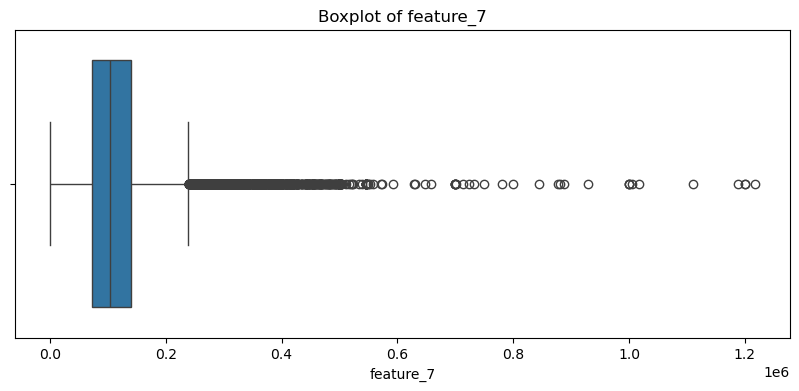

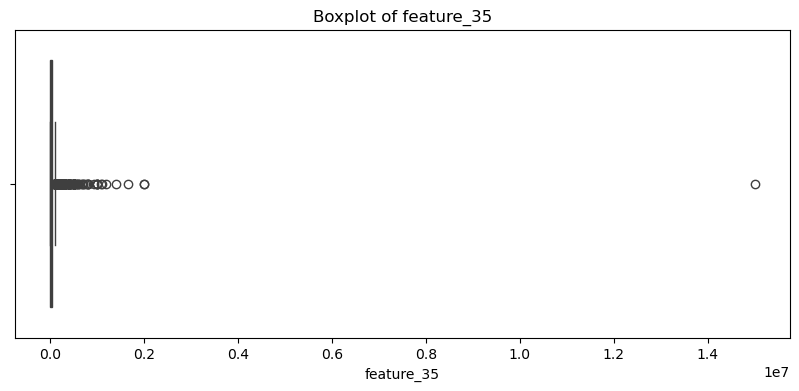

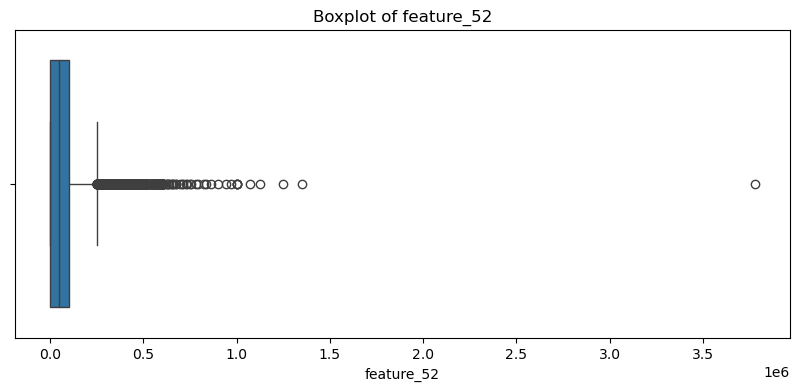

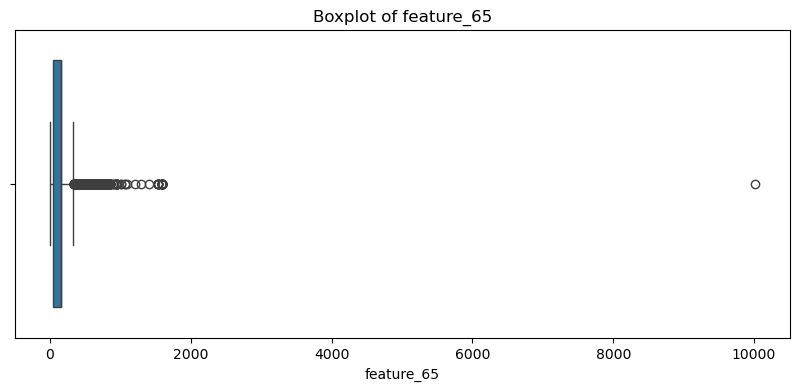

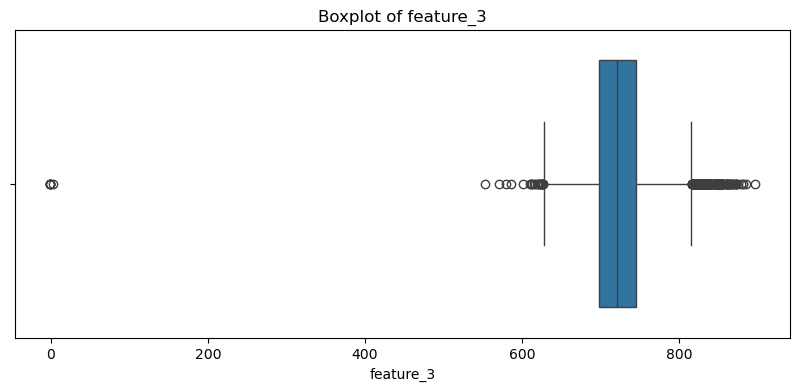

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns

outlier_candidates = [
    'feature_7',
    'feature_35',
    'feature_52',
    'feature_65',
    'feature_3'
]

for col in outlier_candidates:

    plt.figure(figsize=(10, 4))

    sns.boxplot(x=demographic_df[col])

    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)

    plt.show()

In [105]:
outlier_candidates = [
    'feature_3',
    'feature_7',
    'feature_35',
    'feature_52',
    'feature_65'
]

outlier_results = []

for col in outlier_candidates:

    Q1 = demographic_df[col].quantile(0.25)
    Q3 = demographic_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    outlier_mask = (
        (demographic_df[col] < lower_bound) |
        (demographic_df[col] > upper_bound)
    )

    outlier_count = outlier_mask.sum()

    outlier_percentage = (
        outlier_count / demographic_df[col].notna().sum()
    ) * 100

    outlier_results.append({
        'Feature': col,
        'Lower_Bound': lower_bound,
        'Upper_Bound': upper_bound,
        'Outlier_Count': outlier_count,
        'Outlier_Percentage': outlier_percentage
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,feature_3,627.5,815.5,319,1.51
1,feature_7,-28500.0,239500.0,1445,6.05
2,feature_35,-64497.5,107498.5,546,2.29
3,feature_52,-150000.0,250000.0,1099,4.60
4,feature_65,-138.0,334.0,2177,9.12


In [106]:
outlier_direction = []

for col in outlier_candidates:

    Q1 = demographic_df[col].quantile(0.25)
    Q3 = demographic_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    lower_outliers = (
        demographic_df[col] < lower_bound
    ).sum()

    upper_outliers = (
        demographic_df[col] > upper_bound
    ).sum()

    outlier_direction.append({
        'Feature': col,
        'Lower_Outliers': lower_outliers,
        'Upper_Outliers': upper_outliers,
        'Total_Outliers': lower_outliers + upper_outliers
    })

outlier_direction_df = pd.DataFrame(outlier_direction)

display(outlier_direction_df)

,Feature,Lower_Outliers,Upper_Outliers,Total_Outliers
0,feature_3,30,289,319
1,feature_7,0,1445,1445
2,feature_35,0,546,546
3,feature_52,0,1099,1099
4,feature_65,0,2177,2177


In [107]:
for col in outlier_candidates:

    Q1 = demographic_df[col].quantile(0.25)
    Q3 = demographic_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - (1.5 * IQR)
    upper_bound = Q3 + (1.5 * IQR)

    lower_outliers = demographic_df[
        demographic_df[col] < lower_bound
    ][['customer_no', col]]

    upper_outliers = demographic_df[
        demographic_df[col] > upper_bound
    ][['customer_no', col]]

    print(f"\nFeature: {col}")

    if not lower_outliers.empty:
        print("Lowest outlier values:")
        display(lower_outliers.nsmallest(10, col))

    if not upper_outliers.empty:
        print("Highest outlier values:")
        display(upper_outliers.nlargest(10, col))


Feature: feature_3
Lowest outlier values:


,customer_no,feature_3
26,27,-1.0
45,46,-1.0
3539,3540,-1.0
4800,4801,-1.0
12457,12458,-1.0
15166,15167,-1.0
2460,2461,3.0
75,76,553.0
12217,12218,570.0
79,80,580.0


Highest outlier values:


,customer_no,feature_3
16801,16802,896.0
10750,10751,885.0
232,233,881.0
9818,9819,881.0
22683,22684,879.0
5356,5357,875.0
21,22,872.0
6889,6890,872.0
6944,6945,872.0
8577,8578,872.0



Feature: feature_7
Highest outlier values:


,customer_no,feature_7
3214,3215,1217000.0
1,2,1200000.0
11,12,1200000.0
23352,23353,1189000.0
21132,21133,1110000.0
9,10,1017000.0
7779,7780,1005000.0
5,6,1000000.0
24,25,1000000.0
43,44,1000000.0


... (2 outputs left out)


Feature: feature_52
Highest outlier values:


,customer_no,feature_52
13484,13485,3777000.0
19857,19858,1350000.0
9256,9257,1250000.0
14311,14312,1125000.0
2336,2337,1070000.0
47,48,1000000.0
10516,10517,1000000.0
15373,15374,1000000.0
17826,17827,1000000.0
10338,10339,970000.0



Feature: feature_65
Highest outlier values:


,customer_no,feature_65
21081,21082,10008.0
4285,4286,1586.0
4551,4552,1586.0
4625,4626,1586.0
4823,4824,1586.0
4906,4907,1586.0
5331,5332,1586.0
5776,5777,1586.0
5782,5783,1586.0
6081,6082,1586.0


### Outlier Analysis – Cust_Demographics

The Interquartile Range (IQR) method was used to identify potential outliers in the numerical features of the Cust_Demographics dataset.

Five features were identified as containing IQR-based outliers: `feature_3`, `feature_7`, `feature_35`, `feature_52`, and `feature_65`.

Among these features, `feature_65` recorded the highest outlier percentage at 9.12%, followed by `feature_7` at 6.05%, `feature_52` at 4.60%, `feature_35` at 2.29%, and `feature_3` at 1.51%.

Most identified outliers were on the upper end of the distributions. However, `feature_3` contained outliers on both ends, including negative values of -1.

Several features also contained extreme maximum values. For example, `feature_35` had a maximum value of 15,000,000, while `feature_52` had a maximum of 3,777,000. These observations require further investigation to determine whether they represent genuine extreme values or potential data-quality issues.

**Conclusion:**

The IQR analysis identified potential outliers in five numerical features. Since the actual meanings and units of these anonymized features are unavailable, the identified values cannot yet be classified as erroneous. No records or values will be removed or modified during EDA. Their treatment will be considered during the preprocessing phase after further investigation.


In [108]:
# Verify whether both columns are identical

are_identical = demographic_df['feature_35'].equals(
    demographic_df['feature_69']
)

print("Are feature_35 and feature_69 identical?", are_identical)

print(
    "Matching records:",
    (demographic_df['feature_35'] == demographic_df['feature_69']).sum()
)

print(
    "Missing values in feature_35:",
    demographic_df['feature_35'].isna().sum()
)

print(
    "Missing values in feature_69:",
    demographic_df['feature_69'].isna().sum()
)

Are feature_35 and feature_69 identical? True
Matching records: 23881
Missing values in feature_35: 15
Missing values in feature_69: 15


In [109]:
# Investigate negative and unusually low values

print("Negative values:")
display(
    demographic_df.loc[
        demographic_df['feature_3'] < 0,
        ['customer_no', 'feature_3']
    ]
)

print("Frequency of -1:")
print((demographic_df['feature_3'] == -1).sum())

print("Values below 627.5:")
display(
    demographic_df.loc[
        demographic_df['feature_3'] < 627.5,
        'feature_3'
    ].value_counts().sort_index()
)

Negative values:


,customer_no,feature_3
26,27,-1.0
45,46,-1.0
3539,3540,-1.0
4800,4801,-1.0
12457,12458,-1.0
15166,15167,-1.0


Frequency of -1:
6
Values below 627.5:


feature_3
-1.0      6
 3.0      1
 553.0    1
 570.0    1
 580.0    1
 586.0    1
 601.0    1
 610.0    1
 611.0    2
 612.0    1
 615.0    1
 617.0    1
 619.0    1
 620.0    1
 621.0    2
 623.0    1
 624.0    1
 625.0    4
 626.0    1
 627.0    1
Name: count, dtype: int64

In [110]:
# Inspect the highest values in feature_65

print("Highest 20 distinct values:")
display(
    demographic_df['feature_65']
    .value_counts()
    .sort_index(ascending=False)
    .head(20)
)

print("Frequency of 1586:")
print((demographic_df['feature_65'] == 1586).sum())

print("Frequency of 10008:")
print((demographic_df['feature_65'] == 10008).sum())

print("Values above the IQR upper bound (334):")
display(
    demographic_df.loc[
        demographic_df['feature_65'] > 334,
        'feature_65'
    ].value_counts().sort_index(ascending=False).head(20)
)

Highest 20 distinct values:


feature_65
10008.0     1
1586.0     42
1539.0      7
1401.0      1
1289.0      1
1210.0      1
1094.0      1
1062.0      2
1003.0      2
947.0       5
937.0       5
912.0       1
899.0       1
891.0       1
847.0       1
846.0       1
845.0      28
844.0       2
840.0       1
839.0       1
Name: count, dtype: int64

Frequency of 1586:
42
Frequency of 10008:
1
Values above the IQR upper bound (334):


feature_65
10008.0     1
1586.0     42
1539.0      7
1401.0      1
1289.0      1
1210.0      1
1094.0      1
1062.0      2
1003.0      2
947.0       5
937.0       5
912.0       1
899.0       1
891.0       1
847.0       1
846.0       1
845.0      28
844.0       2
840.0       1
839.0       1
Name: count, dtype: int64

### Investigation of Numerical Feature Anomalies

**1. feature_35 and feature_69**

* Both columns were compared using exact equality.
* The comparison returned `True`, confirming that both columns contain identical values and matching missing-value positions.
* These columns are potentially redundant. This should be considered during feature selection or preprocessing.

**2. feature_3**

* Six records contain the value `-1`.
* These values were identified as lower outliers during the IQR investigation.
* Their meaning cannot be established because the original feature description is unavailable.
* These values will be retained for now.

**3. feature_65**

* The IQR upper bound is 334.
* A total of 2,177 observations (9.12%) were identified as upper outliers.
* No lower outliers were detected.
* The value 1586 occurs 42 times, while 845 occurs 28 times.
* The maximum value, 10008, occurs once.
* Repeated extreme values may indicate recurring values or codes, but their meaning requires further investigation.

**EDA Decision:**
No rows or columns will be deleted, and no values will be modified during EDA. The identified anomalies and potentially redundant feature will be considered during preprocessing and feature selection.


In [111]:
# Features already investigated for outliers
investigated_features = [
    'feature_3',
    'feature_7',
    'feature_35',
    'feature_52',
    'feature_65'
]

# Exclude the customer identifier and target
excluded_columns = ['customer_no', 'Bad_label']

# Identify remaining numerical features
remaining_features = [
    col for col in numeric_features
    if col not in investigated_features + excluded_columns
]

print("Number of remaining features:", len(remaining_features))
print("\nRemaining numerical features:")
print(remaining_features)

Number of remaining features: 27

Remaining numerical features:
['feature_4', 'feature_6', 'feature_14', 'feature_19', 'feature_25', 'feature_26', 'feature_29', 'feature_30', 'feature_31', 'feature_34', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_44', 'feature_49', 'feature_55', 'feature_56', 'feature_64', 'feature_66', 'feature_67', 'feature_68', 'feature_69', 'feature_71', 'feature_74', 'feature_76', 'feature_78']


In [112]:
# Examine the remaining numerical features

feature_profile = pd.DataFrame({
    'Data_Type': demographic_df[remaining_features].dtypes,
    'Unique_Values': demographic_df[remaining_features].nunique(),
    'Missing_Values': demographic_df[remaining_features].isnull().sum(),
    'Minimum': demographic_df[remaining_features].min(),
    'Maximum': demographic_df[remaining_features].max(),
    'Mean': demographic_df[remaining_features].mean(),
    'Median': demographic_df[remaining_features].median()
})

feature_profile.sort_values(
    by='Unique_Values',
    ascending=True
)

,Data_Type,Unique_Values,Missing_Values,Minimum,Maximum,Mean,Median
feature_6,float64,1,15,14.0,1.400000e+01,1.400000e+01,1.400000e+01
feature_14,float64,2,7733,0.0,1.200000e+01,8.086618e+00,1.200000e+01
feature_19,float64,2,15,1.0,2.000000e+00,1.049412e+00,1.000000e+00
feature_25,float64,2,15,1.0,2.000000e+00,1.233910e+00,1.000000e+00
feature_67,float64,2,15,0.0,1.000000e+00,1.843725e-01,0.000000e+00
feature_4,float64,3,15,1.0,3.000000e+00,2.321595e+00,3.000000e+00
feature_68,float64,3,15,1.0,3.000000e+00,1.238851e+00,1.000000e+00
feature_34,float64,3,15,1.0,3.000000e+00,1.238851e+00,1.000000e+00
feature_74,float64,3,23879,2.0,4.000000e+00,2.411765e+00,2.000000e+00
feature_78,float64,3,15,1.0,3.000000e+00,1.043214e+00,1.000000e+00


In [113]:
# Inspect distinct values and their frequencies

features_to_inspect = [
    'feature_4', 'feature_6', 'feature_14',
    'feature_19', 'feature_25', 'feature_26',
    'feature_29', 'feature_30', 'feature_31',
    'feature_34', 'feature_39', 'feature_40',
    'feature_41', 'feature_42', 'feature_44',
    'feature_49', 'feature_55', 'feature_56',
    'feature_64', 'feature_66', 'feature_67',
    'feature_68', 'feature_71', 'feature_74',
    'feature_76', 'feature_78'
]

for col in features_to_inspect:

    print(f"\n{'=' * 40}")
    print(f"Feature: {col}")
    print(f"Unique values: {demographic_df[col].nunique()}")

    print(demographic_df[col].value_counts().head(15))


Feature: feature_4
Unique values: 3
feature_4
3.0    14593
1.0     6913
2.0     2375
Name: count, dtype: int64

Feature: feature_6
Unique values: 1
feature_6
14.0    23881
Name: count, dtype: int64

Feature: feature_14
Unique values: 2
feature_14
12.0    10892
0.0      5271
Name: count, dtype: int64

Feature: feature_19
Unique values: 2
feature_19
1.0    22701
2.0     1180
Name: count, dtype: int64

Feature: feature_25
Unique values: 2
feature_25
1.0    18295
2.0     5586
Name: count, dtype: int64

Feature: feature_26
Unique values: 11
feature_26
0.0     15503
2.0      4292
1.0      2144
3.0      1371
4.0       419
5.0       119
6.0        23
7.0         6
10.0        2
8.0         1
9.0         1
Name: count, dtype: int64

Feature: feature_29
Unique values: 964
feature_29
110059.0    1097
122001.0     975
110092.0     685
201301.0     625
110085.0     520
110062.0     465
121001.0     403
110018.0     401
110044.0     375
110045.0     366
110053.0     352
201001.0     335
201010.0   

In [114]:
# Inspect all non-missing values in feature_49

feature_49_values = demographic_df['feature_49'].value_counts(
    dropna=True
).sort_values(ascending=False)

print("Total non-missing values:",
      demographic_df['feature_49'].notna().sum())

print("\nDistinct non-missing values:",
      demographic_df['feature_49'].nunique())

print("\nAll distinct values and frequencies:")
print(feature_49_values.to_string())

Total non-missing values: 104

Distinct non-missing values: 18

All distinct values and frequencies:
feature_49
3.090000e+11    76
4.090000e+11     6
1.010000e+11     4
1.000000e+11     2
1.650139e+06     2
3.100000e+11     2
1.676840e+06     1
1.531761e+06     1
7.568570e+05     1
7.723740e+05     1
1.062149e+07     1
1.731996e+06     1
3.000000e+11     1
3.090096e+10     1
3.090005e+10     1
1.061418e+07     1
1.049050e+07     1
8.090000e+11     1


In [115]:
# Separate smaller and larger values for investigation

feature_49_non_missing = demographic_df[
    demographic_df['feature_49'].notna()
]

small_values = feature_49_non_missing[
    feature_49_non_missing['feature_49'] < 1_000_000_000
]

large_values = feature_49_non_missing[
    feature_49_non_missing['feature_49'] >= 1_000_000_000
]

print("Smaller-value records:", len(small_values))
print("Larger-value records:", len(large_values))

print("\nSmaller-value observations:")
print(
    small_values[['customer_no', 'feature_49', 'Bad_label']]
    .sort_values('feature_49')
    .to_string(index=False)
)

Smaller-value records: 10
Larger-value records: 94

Smaller-value observations:
 customer_no  feature_49  Bad_label
          40    756857.0          0
          38    772374.0          0
          46   1531761.0          0
          36   1650139.0          0
          37   1650139.0          0
          30   1676840.0          0
          52   1731996.0          0
       12080  10490498.0          0
       11047  10614179.0          0
        3887  10621493.0          0


In [116]:
# Compare feature_49 value groups against Bad_label

feature_49_non_missing = demographic_df[
    demographic_df['feature_49'].notna()
].copy()

feature_49_non_missing['value_group'] = feature_49_non_missing[
    'feature_49'
].apply(
    lambda x: 'Smaller values' if x < 1_000_000_000
    else 'Larger values'
)

# Count of each target class
print(
    pd.crosstab(
        feature_49_non_missing['value_group'],
        feature_49_non_missing['Bad_label']
    )
)

# Percentage distribution
print("\nPercentage distribution:")

print(
    pd.crosstab(
        feature_49_non_missing['value_group'],
        feature_49_non_missing['Bad_label'],
        normalize='index'
    ).mul(100).round(2)
)

Bad_label        0  1
value_group          
Larger values   91  3
Smaller values  10  0

Percentage distribution:
Bad_label            0     1
value_group                 
Larger values    96.81  3.19
Smaller values  100.00  0.00


### Investigation of feature_49

* Total records: 23,896
* Missing values: 23,792 (99.56%)
* Non-missing observations: 104
* Distinct non-missing values: 18

The value distribution showed two substantially different magnitude groups:

* Smaller values (< 1 billion): 10 observations.
* Larger values (>= 1 billion): 94 observations.

The smaller-value observations ranged from 756,857 to 10,621,493, while most larger values were in the hundreds of billions.

The relationship with `Bad_label` was also examined:

| Value group    | Good credit (0) | Bad credit (1) |
| -------------- | --------------: | -------------: |
| Smaller values |       10 (100%) |         0 (0%) |
| Larger values  |     91 (96.81%) |      3 (3.19%) |

**Conclusion:**

The feature contains an unusual distribution with two distinct magnitude groups. However, its meaning is unknown, and the available observations are insufficient to establish whether the smaller values are erroneous or represent a different category.

Due to its extremely high missingness and unusual value distribution, `feature_49` is flagged for further investigation during feature assessment.

No observations or values were removed or modified.


In [117]:
# Examine feature_74 against the target

feature_74_data = demographic_df[
    demographic_df['feature_74'].notna()
]

print("Target distribution by feature_74:")

print(
    pd.crosstab(
        feature_74_data['feature_74'],
        feature_74_data['Bad_label']
    )
)

print("\nPercentage distribution:")

print(
    pd.crosstab(
        feature_74_data['feature_74'],
        feature_74_data['Bad_label'],
        normalize='index'
    ).mul(100).round(2)
)

Target distribution by feature_74:
Bad_label    0  1
feature_74       
2.0         10  1
3.0          5  0
4.0          1  0

Percentage distribution:
Bad_label        0     1
feature_74              
2.0          90.91  9.09
3.0         100.00  0.00
4.0         100.00  0.00


### Investigation of feature_74

* Total records: 23,896
* Missing values: 23,879 (99.93%)
* Non-missing observations: 17
* Distinct values: 3

Value frequencies:

* 2: 11 observations
* 3: 5 observations
* 4: 1 observation

The target distribution was examined:

| Feature value | Good credit (0) | Bad credit (1) |
| ------------- | --------------: | -------------: |
| 2             |     10 (90.91%) |      1 (9.09%) |
| 3             |        5 (100%) |         0 (0%) |
| 4             |        1 (100%) |         0 (0%) |

**Conclusion:**

The feature contains only 17 non-missing observations and has extremely high missingness. Its values appear categorical or coded rather than continuous.

IQR-based outlier detection is not appropriate for this feature. The target comparison is also inconclusive because of the very small sample size.

The feature is flagged for further investigation during feature assessment. No values were modified or removed.


In [118]:
# Inspect year-like features
year_like_features = ['feature_30', 'feature_39']

for col in year_like_features:

    print(f"\n{'='*50}")
    print(f"Feature: {col}")
    print(f"{'='*50}")

    print("Missing values:", demographic_df[col].isna().sum())
    print("Non-missing values:", demographic_df[col].count())
    print("Unique values:", demographic_df[col].nunique())
    print("Minimum value:", demographic_df[col].min())
    print("Maximum value:", demographic_df[col].max())

    print("\nValue frequencies:")
    display(
        demographic_df[col]
        .value_counts(dropna=False)
        .sort_index()
    )


Feature: feature_30
Missing values: 15
Non-missing values: 23881
Unique values: 52
Minimum value: 1964.0
Maximum value: 2015.0

Value frequencies:


feature_30
1964.0     144
1965.0      29
1966.0      22
1967.0      18
1968.0      26
1969.0      50
1970.0      72
1971.0      39
1972.0      51
1973.0      64
1974.0      87
1975.0     162
1976.0     104
1977.0     103
1978.0     149
1979.0     170
1980.0     395
1981.0     215
1982.0     283
1983.0     286
1984.0     393
1985.0     683
1986.0     378
1987.0     388
1988.0     364
1989.0     332
1990.0     791
1991.0     179
1992.0     158
1993.0     122
1994.0      85
1995.0     823
1996.0      72
1997.0     110
1998.0     149
1999.0     285
2000.0    1710
2001.0     324
2002.0     292
2003.0     467
2004.0     352
2005.0    1319
2006.0     480
2007.0     836
2008.0     801
2009.0    1026
2010.0    1839
2011.0    1483
2012.0    1745
2013.0    1717
2014.0    1320
2015.0     389
NaN         15
Name: count, dtype: int64


Feature: feature_39
Missing values: 15
Non-missing values: 23881
Unique values: 18
Minimum value: 0.0
Maximum value: 2015.0

Value frequencies:


feature_39
0.0       5667
1999.0     670
2000.0     307
2001.0     128
2002.0     143
2003.0     174
2004.0     216
2005.0     554
2006.0     449
2007.0     860
2008.0     907
2009.0    1113
2010.0    1989
2011.0    1960
2012.0    2402
2013.0    2463
2014.0    2375
2015.0    1504
NaN         15
Name: count, dtype: int64

### Investigation of feature_30 and feature_39

#### feature_30

* Non-missing observations: 23,881
* Missing values: 15
* Unique values: 52
* Minimum: 1964
* Maximum: 2015

The feature contains consecutive year-like values from 1964 to 2015. No obvious invalid values were identified.

**Conclusion:** No conventional IQR-based outlier analysis was applied because the feature appears year-like. Lower-frequency years should not automatically be considered outliers.

#### feature_39

* Non-missing observations: 23,881
* Missing values: 15
* Unique values: 18
* Minimum: 0
* Maximum: 2015
* Zero frequency: 5,667

The feature contains year-like values from 1999 to 2015, along with a frequent value of zero.

**Conclusion:** Zero is flagged as a potential special or coded value. Its meaning cannot be established without a data dictionary. It was not treated as missing or removed.

### Overall decision

Neither feature was subjected to conventional IQR-based outlier detection. Both are flagged for semantic investigation during feature assessment.

No records or values were modified or removed.


In [119]:
# Classify numerical demographic features

feature_groups = {
    'Continuous-like': [
        'feature_3', 'feature_7', 'feature_35',
        'feature_52', 'feature_65'
    ],

    'Categorical-like': [
        'feature_4', 'feature_14', 'feature_19',
        'feature_25', 'feature_34', 'feature_55',
        'feature_67', 'feature_68', 'feature_78'
    ],

    'Discrete/Coded': [
        'feature_26', 'feature_31', 'feature_40',
        'feature_41', 'feature_42', 'feature_56',
        'feature_64', 'feature_71', 'feature_76'
    ],

    'Code-like': [
        'feature_29', 'feature_44', 'feature_66'
    ],

    'Year-like': [
        'feature_30', 'feature_39'
    ],

    'Special cases': [
        'feature_6', 'feature_49', 'feature_69', 'feature_74'
    ]
}

# Convert dictionary into a DataFrame
feature_classification = pd.DataFrame(
    [
        {'Feature': feature, 'Classification': group}
        for group, features in feature_groups.items()
        for feature in features
    ]
)

display(
    feature_classification.sort_values('Feature')
)

,Feature,Classification
6,feature_14,Categorical-like
7,feature_19,Categorical-like
8,feature_25,Categorical-like
14,feature_26,Discrete/Coded
23,feature_29,Code-like
0,feature_3,Continuous-like
26,feature_30,Year-like
15,feature_31,Discrete/Coded
9,feature_34,Categorical-like
2,feature_35,Continuous-like


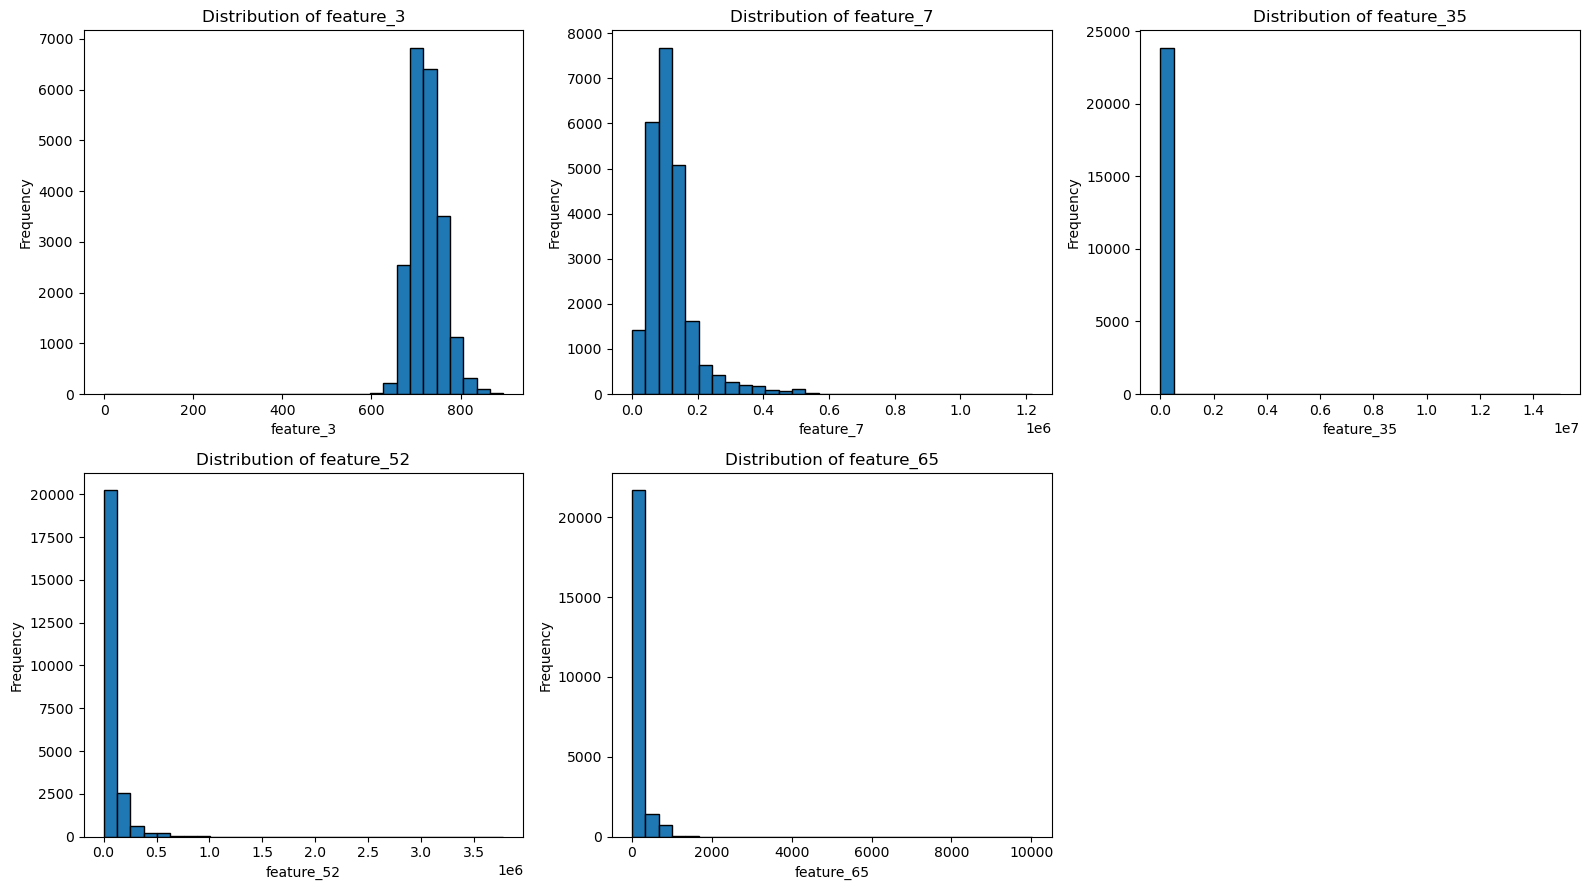

In [120]:

continuous_features = [
    'feature_3',
    'feature_7',
    'feature_35',
    'feature_52',
    'feature_65'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

axes = axes.flatten()

for i, col in enumerate(continuous_features):

    axes[i].hist(
        demographic_df[col].dropna(),
        bins=30,
        edgecolor='black'
    )

    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

# Remove the unused sixth subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()

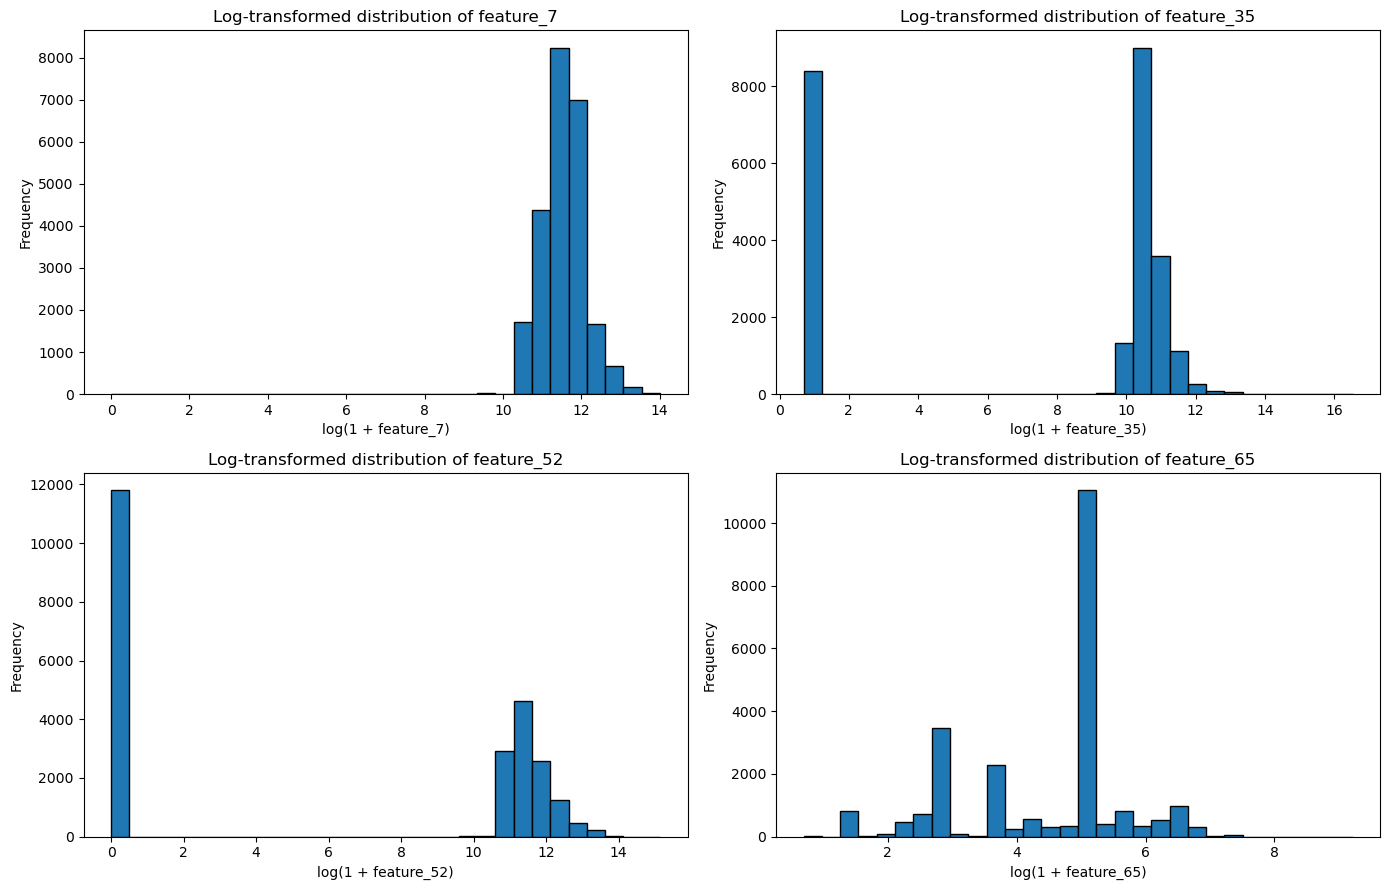

In [121]:
skewed_features = [
    'feature_7',
    'feature_35',
    'feature_52',
    'feature_65'
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, col in enumerate(skewed_features):

    transformed_values = np.log1p(
        demographic_df[col].dropna()
    )

    axes[i].hist(
        transformed_values,
        bins=30,
        edgecolor='black'
    )

    axes[i].set_title(f'Log-transformed distribution of {col}')
    axes[i].set_xlabel(f'log(1 + {col})')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Distribution Analysis of Continuous-Like Features

Histograms were used to examine the distributions of `feature_3`, `feature_7`, `feature_35`, `feature_52`, and `feature_65`.

**Observations:**

* **feature_3:** Most observations are concentrated between approximately 680 and 760. The distribution is relatively compact and approximately bell-shaped.
* **feature_7:** The original distribution is positively skewed, with a long right tail. A log-transformed visualization makes the distribution more compact.
* **feature_35:** The distribution contains two major concentrations. A large number of observations have the value 1, while another group contains substantially larger values.
* **feature_52:** The distribution contains a large concentration of zero values, followed by a positively skewed distribution of non-zero observations.
* **feature_65:** The distribution contains several distinct peaks and repeated values, suggesting discrete or coded behaviour rather than a smooth continuous distribution.

**Conclusion:**

The five features do not share the same distribution pattern. Some are strongly skewed, while others contain concentrated or repeated values.

Logarithmic transformations were used only for visualization. No transformations or modifications were applied to the original dataset.

The meanings of the anonymized features remain unknown and require further investigation before preprocessing decisions are made.


In [122]:
categorical_features = [
    'feature_4',
    'feature_14',
    'feature_19',
    'feature_25',
    'feature_34',
    'feature_55',
    'feature_67',
    'feature_68',
    'feature_78'
]

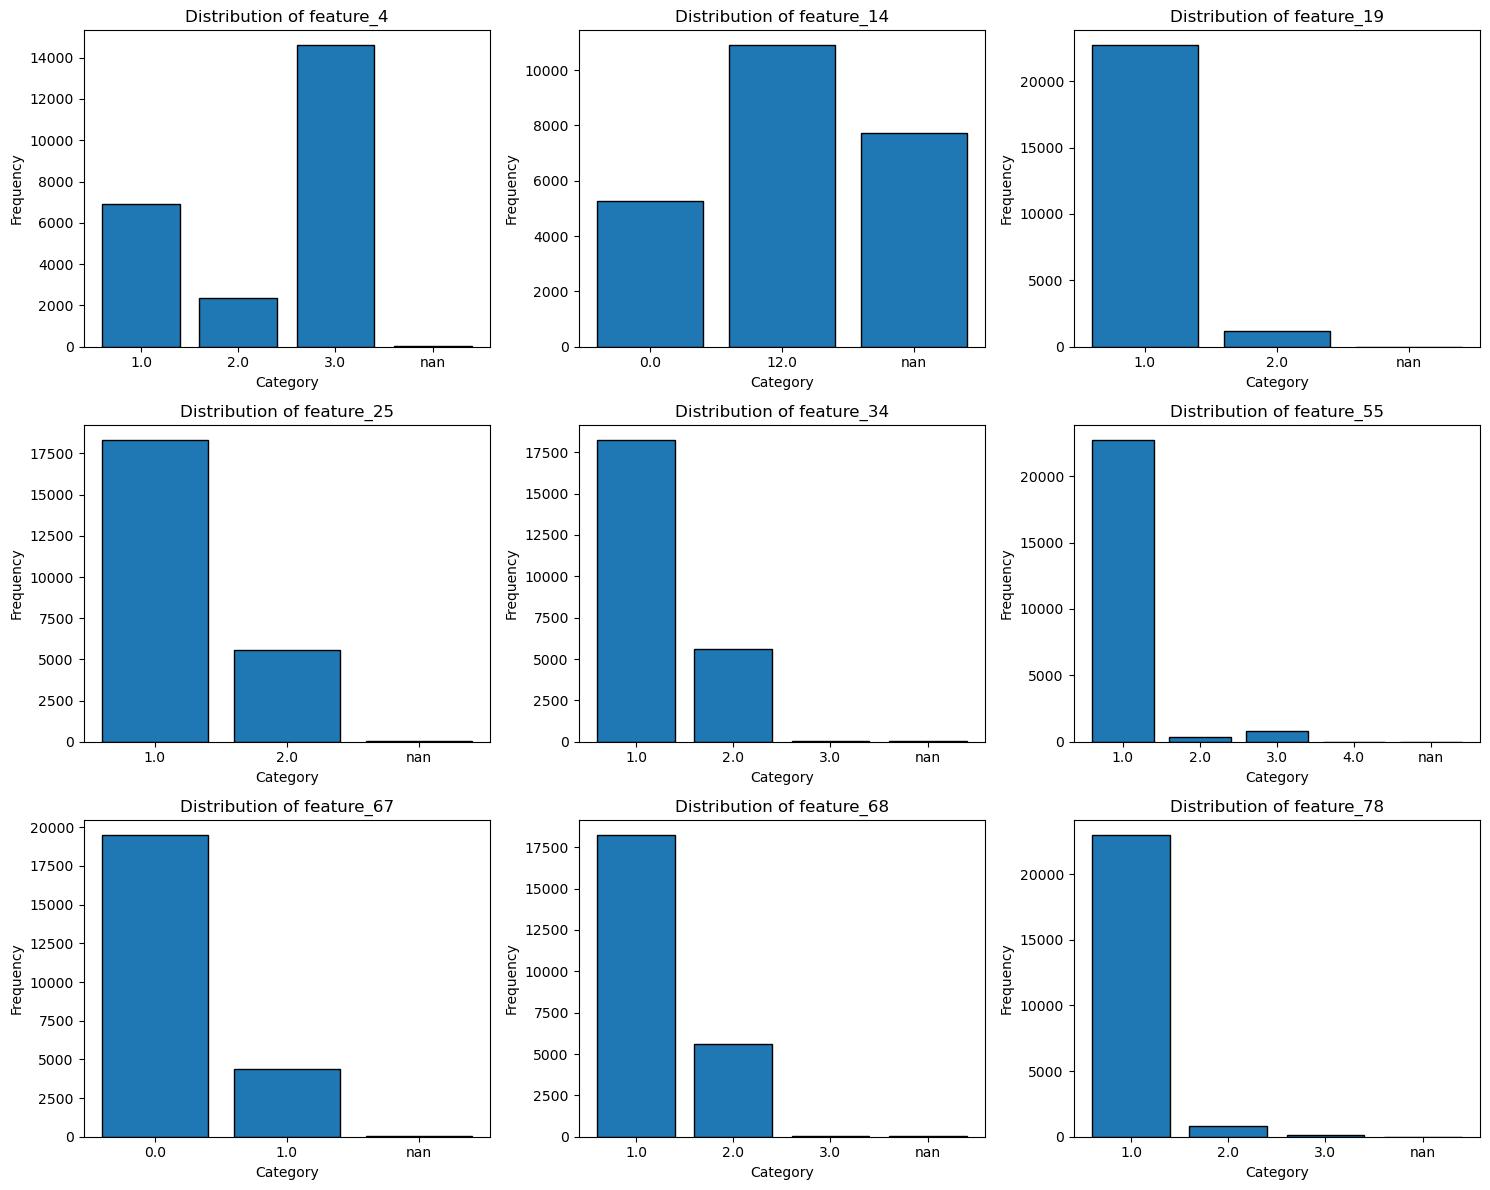

In [123]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for i, col in enumerate(categorical_features):

    value_counts = demographic_df[col].value_counts(
        dropna=False
    ).sort_index()

    axes[i].bar(
        value_counts.index.astype(str),
        value_counts.values,
        edgecolor='black'
    )

    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('Category')
    axes[i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Distribution Analysis of Categorical-Like Features

Bar charts were used to examine the distributions of nine categorical-like features.

**Observations:**

* **feature_4:** Contains three categories, with category 3 being the most frequent.
* **feature_14:** Contains two observed values, 0 and 12. Value 12 occurs more frequently. The feature has 32.36% missing values.
* **feature_19:** Value 1 dominates the distribution, with 22,701 observations.
* **feature_25:** Value 1 is the dominant category, with 18,295 observations.
* **feature_34:** Value 1 dominates, while value 3 is rare, with only 37 observations.
* **feature_55:** Value 1 dominates with 22,693 observations. Value 4 occurs only 8 times.
* **feature_67:** Value 0 is more frequent than value 1.
* **feature_68:** Value 1 dominates, while value 3 occurs only 37 times.
* **feature_78:** Value 1 dominates, accounting for 22,958 observations.

**Key findings:**

1. Several features have highly imbalanced category distributions.
2. Some categories have very low frequencies and should be investigated further.
3. `feature_14` has substantial missingness compared with the other features in this group.
4. `feature_34` and `feature_68` have identical category frequencies, which may warrant further investigation.

**Conclusion:**

These features are more appropriately examined as categorical variables than as continuous numerical measurements. Their observed distributions and rare categories should be considered during later feature assessment.

No categories or records were removed or modified.


In [124]:
discrete_features = [
    'feature_26',
    'feature_31',
    'feature_40',
    'feature_41',
    'feature_42',
    'feature_56',
    'feature_64',
    'feature_71',
    'feature_76'
]

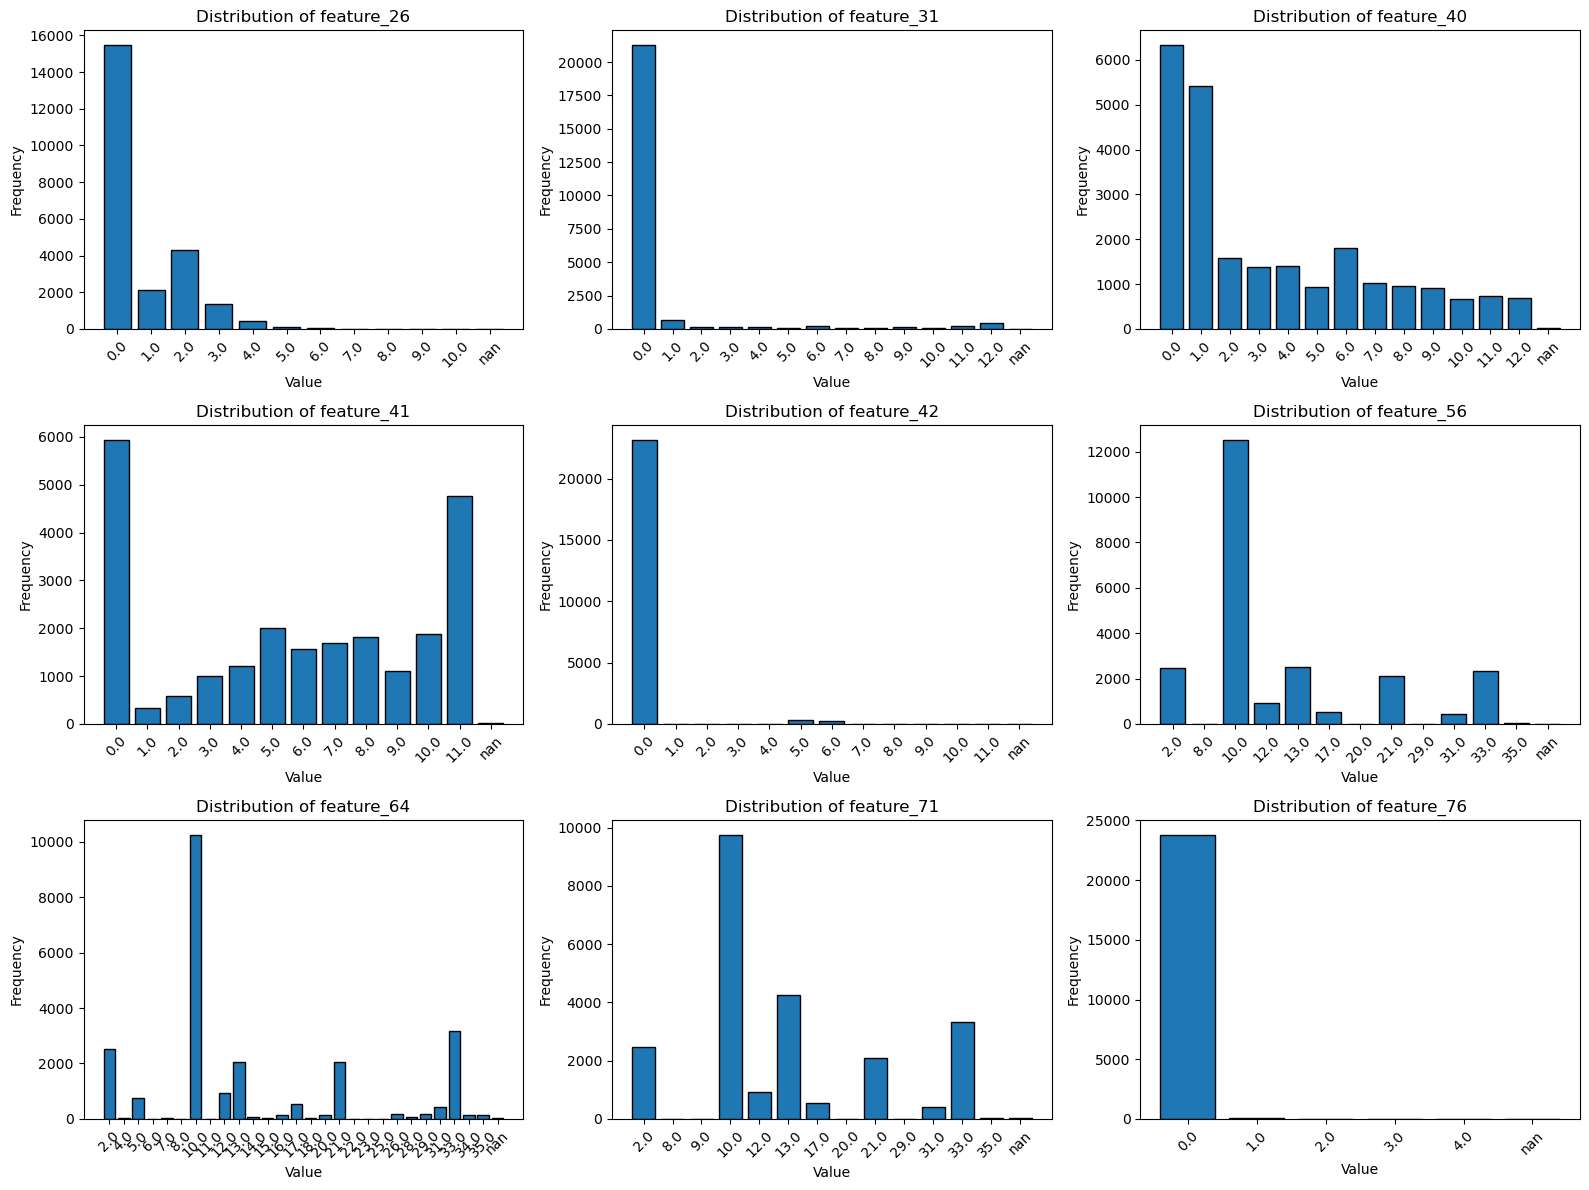

In [125]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(discrete_features):

    value_counts = demographic_df[col].value_counts(
        dropna=False
    ).sort_index()

    axes[i].bar(
        value_counts.index.astype(str),
        value_counts.values,
        edgecolor='black'
    )

    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')
    axes[i].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Distribution Analysis of Discrete/Coded Features

Bar charts were used to examine nine discrete/coded features.

**Observations:**

* **feature_26:** Value 0 dominates with 15,503 observations, followed by value 2 with 4,292 observations.
* **feature_31:** Value 0 dominates with 21,315 observations.
* **feature_40:** Values 0 and 1 are the most frequent, while the remaining values are distributed across the range.
* **feature_41:** Values 0 and 11 are the two most frequent values.
* **feature_42:** Value 0 dominates with 23,181 observations.
* **feature_56:** Value 10 dominates with 12,539 observations. Values 2, 13 and 33 are also frequent.
* **feature_64:** Value 10 dominates with 10,257 observations, followed by values 33, 2, 13 and 21.
* **feature_71:** Value 10 dominates with 9,760 observations, followed by values 13 and 33.
* **feature_76:** Value 0 dominates with 23,817 observations. Only 64 observations have non-zero values.

**Key findings:**

1. Several features have a strong concentration at zero.
2. `feature_42` and `feature_76` contain very few non-zero observations.
3. `feature_56`, `feature_64` and `feature_71` share several frequently occurring values.
4. These features have discrete or coded distributions rather than smooth continuous distributions.

**Conclusion:**

Frequency-based analysis is more appropriate for these features than treating them as continuous measurements. The meanings of the values, especially zero, remain unknown.

No values or records were modified or removed.


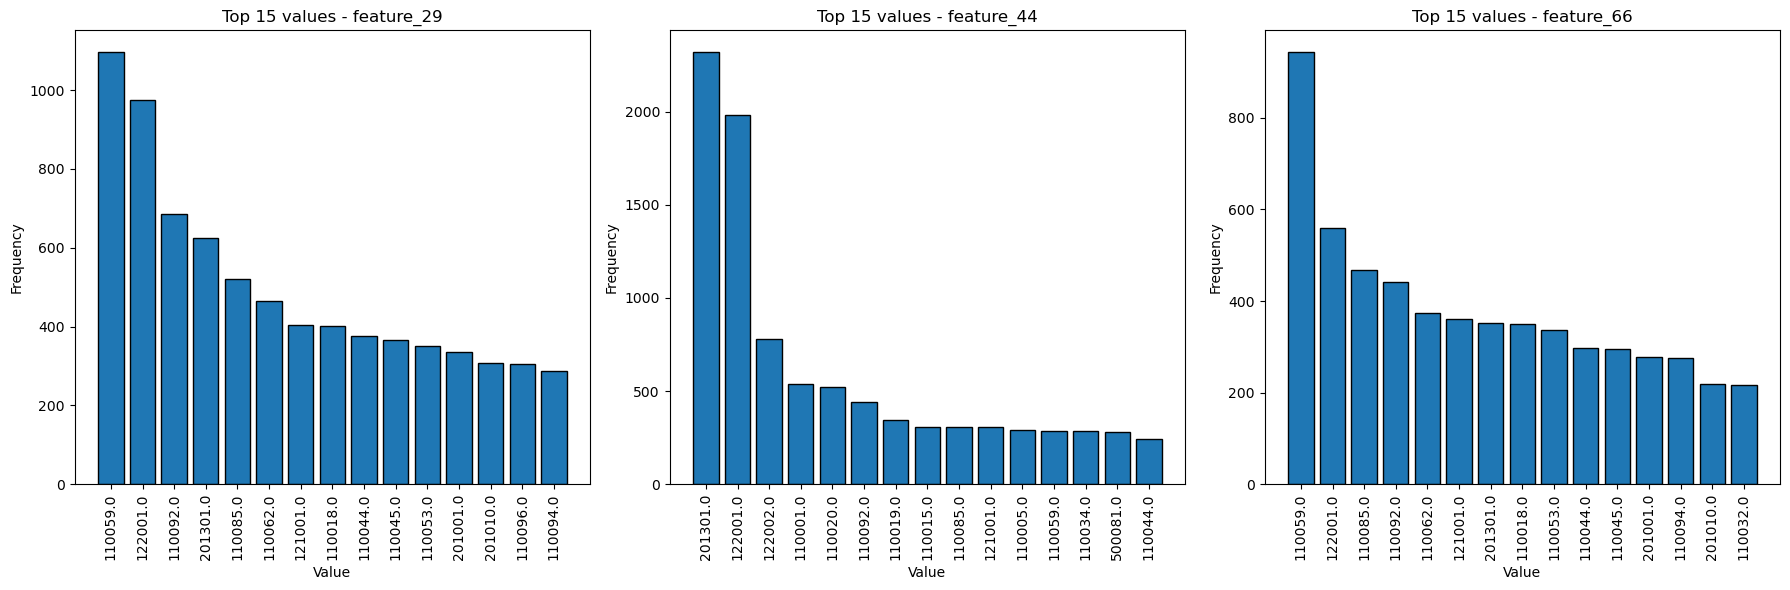

In [126]:
# Code-like features: Top 15 values

code_features = [
    'feature_29',
    'feature_44',
    'feature_66'
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, col in enumerate(code_features):

    top_values = demographic_df[col].value_counts().head(15)

    axes[i].bar(
        top_values.index.astype(str),
        top_values.values,
        edgecolor='black'
    )

    axes[i].set_title(f'Top 15 values - {col}')
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')
    axes[i].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

### Distribution Analysis of Code-Like Features

The top 15 most frequent values were visualized for `feature_29`, `feature_44`, and `feature_66`.

**Observations:**

* **feature_29:** Contains 964 distinct values. The most frequent values include 110059 (1,097), 122001 (975), and 110092 (685).
* **feature_44:** Contains 936 distinct values. The most frequent values include 201301 (2,320), 122001 (1,981), and 122002 (782).
* **feature_66:** Contains 3,012 distinct values. The most frequent values include 110059 (944), 122001 (560), and 110085 (467).

**Key findings:**

1. All three features have high cardinality.
2. Their values appear code-like rather than continuous.
3. A relatively small number of values occur frequently, while many other values occur less frequently.
4. `feature_66` has the highest number of distinct values among these three features.

**Conclusion:**

These features should be treated as code-like variables until their actual meanings are confirmed. Numerical operations such as calculating averages would not be meaningful without understanding what the codes represent.

No values or records were modified or removed.


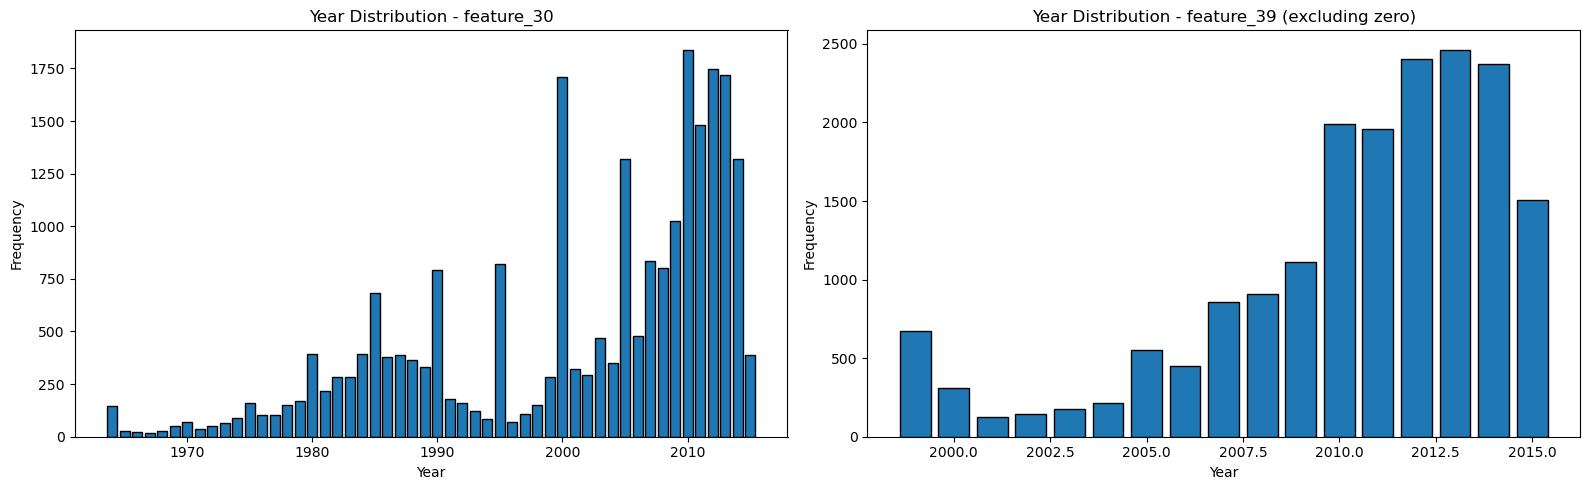

In [127]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# feature_30
year_30_counts = (
    demographic_df['feature_30']
    .value_counts()
    .sort_index()
)

axes[0].bar(
    year_30_counts.index.astype(int),
    year_30_counts.values,
    edgecolor='black'
)

axes[0].set_title('Year Distribution - feature_30')
axes[0].set_xlabel('Year')
axes[0].set_ylabel('Frequency')


# feature_39: Exclude zero for year visualization only
year_39_counts = (
    demographic_df.loc[
        demographic_df['feature_39'] != 0,
        'feature_39'
    ]
    .value_counts()
    .sort_index()
)

axes[1].bar(
    year_39_counts.index.astype(int),
    year_39_counts.values,
    edgecolor='black'
)

axes[1].set_title('Year Distribution - feature_39 (excluding zero)')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

### Distribution Analysis of Year-Like Features

Bar charts were used to examine the distributions of `feature_30` and `feature_39`.

**Observations:**

* **feature_30:** Contains 52 distinct values ranging from 1964 to 2015. Higher frequencies are observed in later years, with 2010 having the highest frequency (1,839 observations). Other noticeable peaks occur in 1985, 1990, 1995, 2000 and 2005.
* **feature_39:** Contains 18 distinct values, including zero. After excluding zero for visualization, the distribution shows increasing frequencies from 2005 onwards. The highest frequency occurs in 2013 (2,463 observations), followed by 2012 (2,402) and 2014 (2,375).

**Key findings:**

1. Both features contain values resembling calendar years.
2. `feature_30` has a broader range of year-like values.
3. `feature_39` is concentrated primarily between 2010 and 2014.
4. `feature_39` contains 5,667 zero values whose meaning is unknown.

**Conclusion:**

Both features are classified as year-like based on their observed values. Their actual meanings cannot be established without a data dictionary.

Zero values in `feature_39` were excluded only from the visualization. The original dataset was not modified.


### Consolidated Feature Type and Distribution Analysis

A total of 32 numerical features were classified based on their observed values, cardinality and distribution patterns.

| Classification   | Number of features |
| ---------------- | -----------------: |
| Continuous-like  |                  5 |
| Categorical-like |                  9 |
| Discrete/Coded   |                  9 |
| Code-like        |                  3 |
| Year-like        |                  2 |
| Special cases    |                  4 |
| **Total**        |             **32** |

**Key findings:**

1. Several continuous-like features exhibit strong right skewness.
2. `feature_35` contains two major concentrations, while `feature_52` has a large concentration of zero values.
3. Several categorical and discrete features have highly imbalanced distributions.
4. Code-like features have high cardinality and require semantic verification.
5. `feature_30` and `feature_39` contain year-like values, although their actual meanings remain unknown.
6. `feature_6` is constant.
7. `feature_35` and `feature_69` are exact duplicates.
8. `feature_49` and `feature_74` have extremely high missingness and require special consideration.
9. Zero values in certain features may represent special codes or valid observations; their meanings cannot be established from the available feature names.

**Conclusion:**

The numerical data types do not necessarily represent continuous measurements. Several features are better understood as categorical, discrete or code-like variables.

These classifications are preliminary and will guide subsequent target relationship analysis and preprocessing decisions.

No data was modified, deleted, or transformed during this analysis.


In [128]:
# Target distribution
target_counts = demographic_df['Bad_label'].value_counts().sort_index()

print("Target counts:")
print(target_counts)

print("\nTarget percentage distribution:")
print(
    demographic_df['Bad_label']
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("\nBaseline bad-credit rate:")
print(
    f"{demographic_df['Bad_label'].mean() * 100:.2f}%"
)

Target counts:
Bad_label
0    22892
1     1004
Name: count, dtype: int64

Target percentage distribution:
Bad_label
0    95.8
1     4.2
Name: proportion, dtype: float64

Baseline bad-credit rate:
4.20%


In [129]:
categorical_features = [
    'feature_4',
    'feature_14',
    'feature_19',
    'feature_25',
    'feature_34',
    'feature_55',
    'feature_67',
    'feature_68',
    'feature_78'
]

for col in categorical_features:

    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")
    print('=' * 50)

    # Customer counts by category and target
    counts = pd.crosstab(
        demographic_df[col].fillna('Missing'),
        demographic_df['Bad_label']
    )

    # Percentage of target classes within each category
    percentages = pd.crosstab(
        demographic_df[col].fillna('Missing'),
        demographic_df['Bad_label'],
        normalize='index'
    ).mul(100).round(2)

    print("\nCustomer counts:")
    print(counts)

    print("\nTarget percentage within each category:")
    print(percentages)


Feature: feature_4

Customer counts:
Bad_label      0    1
feature_4            
1.0         6671  242
2.0         2252  123
3.0        13955  638
Missing       14    1

Target percentage within each category:
Bad_label      0     1
feature_4             
1.0        96.50  3.50
2.0        94.82  5.18
3.0        95.63  4.37
Missing    93.33  6.67

Feature: feature_14

Customer counts:
Bad_label       0    1
feature_14            
0.0          5071  200
12.0        10497  395
Missing      7324  409

Target percentage within each category:
Bad_label       0     1
feature_14             
0.0         96.21  3.79
12.0        96.37  3.63
Missing     94.71  5.29

Feature: feature_19

Customer counts:
Bad_label       0    1
feature_19            
1.0         21753  948
2.0          1125   55
Missing        14    1

Target percentage within each category:
Bad_label       0     1
feature_19             
1.0         95.82  4.18
2.0         95.34  4.66
Missing     93.33  6.67

Feature: feature_25


### Relationship Between Categorical Features and Bad_label

The categorical-like demographic features were compared against `Bad_label` using cross-tabulations and within-category percentage distributions.

The overall baseline bad-credit rate is **4.20%**.

**Key observations:**

1. `feature_4`: Category 2 has a bad-credit rate of 5.18%, higher than the overall baseline.
2. `feature_14`: The missing category contains 7,733 customers and has a bad-credit rate of 5.29%.
3. `feature_19`: Both categories have bad-credit rates close to the overall baseline.
4. `feature_25`: Category 2 has a bad-credit rate of 4.99%, compared with 3.96% for category 1.
5. `feature_34`: Category 2 has a higher bad-credit rate (4.81%) than category 1 (4.01%). Category 3 has only 37 observations.
6. `feature_55`: Category 2 has a bad-credit rate of 5.93%, while category 4 has 25%. However, category 4 contains only 8 observations.
7. `feature_67`: Both categories have similar bad-credit rates.
8. `feature_68`: Its category-level counts and target percentages match those of `feature_34`.
9. `feature_78`: Category 3 has a bad-credit rate of 6.42%, but contains only 109 customers.

**Conclusion:**

Some categories, particularly those in `feature_4`, `feature_14`, and `feature_25`, show higher bad-credit rates than the overall baseline.

The missing category of `feature_14` is also worth investigating because it represents a substantial number of customers.

Small categories must be interpreted cautiously. These comparisons are descriptive and do not establish statistical significance or predictive power.

No values or records were modified or removed.


In [130]:
discrete_features = [
    'feature_26',
    'feature_31',
    'feature_40',
    'feature_41',
    'feature_42',
    'feature_56',
    'feature_64',
    'feature_71',
    'feature_76'
]

In [131]:
for col in discrete_features:

    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")
    print('=' * 50)

    # Customer counts by feature value and target
    counts = pd.crosstab(
        demographic_df[col].fillna('Missing'),
        demographic_df['Bad_label']
    )

    # Target percentages within each feature value
    percentages = pd.crosstab(
        demographic_df[col].fillna('Missing'),
        demographic_df['Bad_label'],
        normalize='index'
    ).mul(100).round(2)

    print("\nCustomer counts:")
    print(counts)

    print("\nTarget percentage within each value:")
    print(percentages)


Feature: feature_26

Customer counts:
Bad_label       0    1
feature_26            
0.0         14784  719
1.0          2069   75
2.0          4155  137
3.0          1322   49
4.0           404   15
5.0           112    7
6.0            22    1
7.0             6    0
8.0             1    0
9.0             1    0
10.0            2    0
Missing        14    1

Target percentage within each value:
Bad_label        0     1
feature_26              
0.0          95.36  4.64
1.0          96.50  3.50
2.0          96.81  3.19
3.0          96.43  3.57
4.0          96.42  3.58
5.0          94.12  5.88
6.0          95.65  4.35
7.0         100.00  0.00
8.0         100.00  0.00
9.0         100.00  0.00
10.0        100.00  0.00
Missing      93.33  6.67

Feature: feature_31

Customer counts:
Bad_label       0    1
feature_31            
0.0         20405  910
1.0           677   23
2.0           120    4
3.0           115    4
4.0           169    8
5.0           102    1
6.0           210   10
7.0  

### Discrete/Coded Features vs Bad_label

The relationship between nine discrete/coded demographic features and `Bad_label` was investigated using cross-tabulations and within-category target percentages.

The overall bad-credit rate was **4.20%**.

**Key observations:**

* `feature_40` and `feature_41` showed some category-level differences from the baseline.
* `feature_56` and `feature_71` showed higher bad-credit rates for value 17, at 5.72% and 5.57%, respectively.
* `feature_64` showed a 7.10% bad-credit rate for value 34.
* `feature_42` and `feature_76` contained highly imbalanced category distributions.
* Several categories showed unusually high percentages but had very small customer counts, making those observations unreliable.

**Conclusion:**

Some discrete/coded features show potential relationships with bad-credit status. However, the findings are descriptive and require further evaluation during modelling. No transformations or data modifications were performed.


In [132]:
continuous_features = [
    'feature_3',
    'feature_7',
    'feature_35',
    'feature_52',
    'feature_65'
]

for col in continuous_features:

    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")
    print('=' * 50)

    summary = demographic_df.groupby('Bad_label')[col].agg(
        ['count', 'mean', 'median', 'std', 'min', 'max']
    )

    print(summary)

    print("\nQuartiles:")
    print(
        demographic_df.groupby('Bad_label')[col]
        .quantile([0.25, 0.50, 0.75])
        .unstack()
    )


Feature: feature_3
           count        mean  median        std    min    max
Bad_label                                                    
0          20194  723.586214   721.0  37.459264   -1.0  896.0
1            866  715.068129   713.0  32.851725  553.0  853.0

Quartiles:
            0.25   0.50   0.75
Bad_label                     
0          698.0  721.0  745.0
1          694.0  713.0  736.0

Feature: feature_7
           count           mean    median           std      min        max
Bad_label                                                                  
0          22878  120034.954979  105000.0  77919.753941      0.0  1217000.0
1           1003   97071.784646   85000.0  64061.494529  15000.0   550000.0

Quartiles:
              0.25      0.50      0.75
Bad_label                             
0          73000.0  105000.0  140000.0
1          58000.0   85000.0  117500.0

Feature: feature_35
           count          mean   median            std  min         max
Bad_label  

<Figure size 700x500 with 0 Axes>

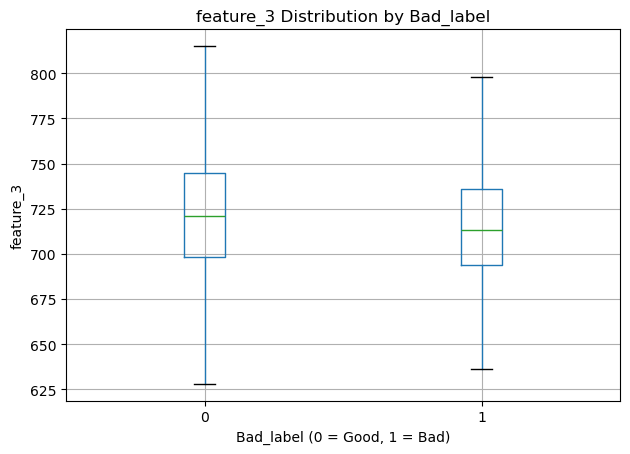

<Figure size 700x500 with 0 Axes>

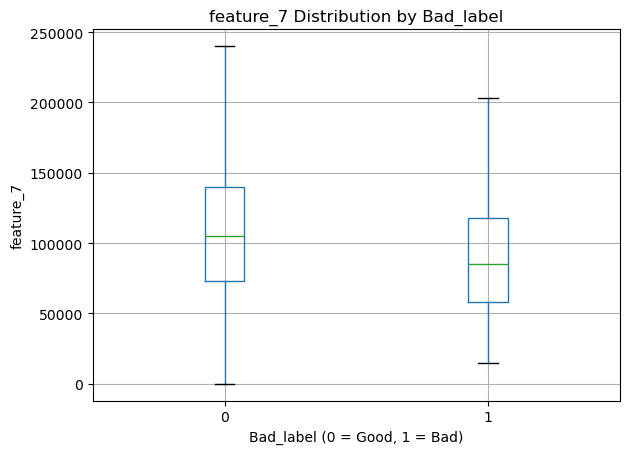

<Figure size 700x500 with 0 Axes>

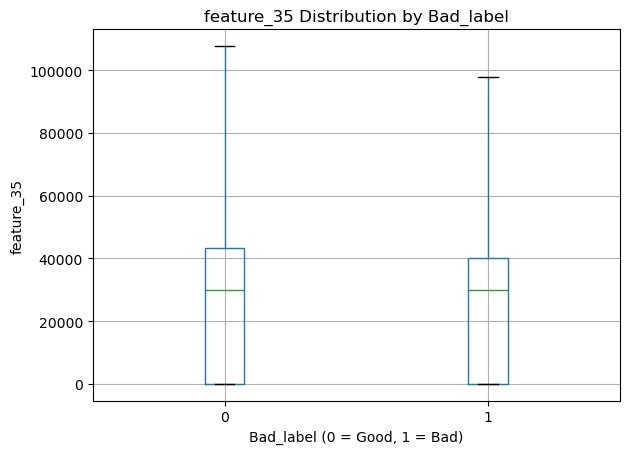

<Figure size 700x500 with 0 Axes>

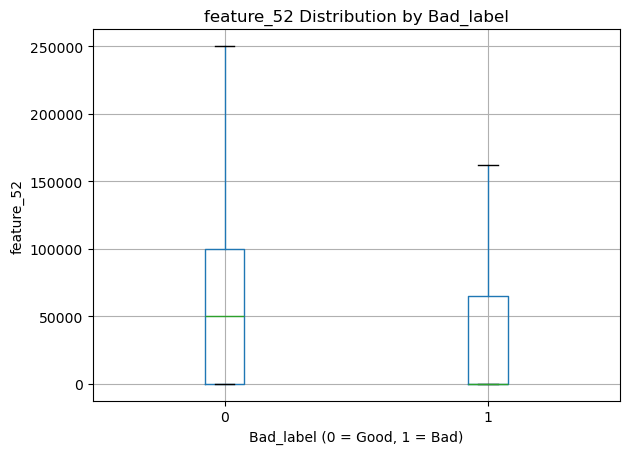

<Figure size 700x500 with 0 Axes>

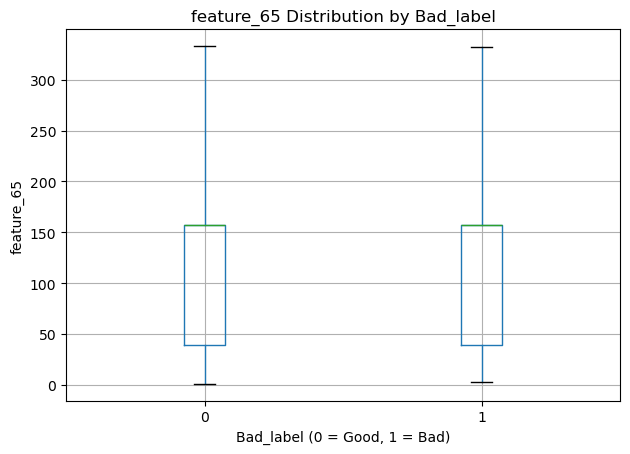

In [133]:
for col in continuous_features:

    plt.figure(figsize=(7, 5))

    demographic_df.boxplot(
        column=col,
        by='Bad_label',
        showfliers=False
    )

    plt.title(f'{col} Distribution by Bad_label')
    plt.suptitle('')
    plt.xlabel('Bad_label (0 = Good, 1 = Bad)')
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

### Continuous-like Features vs Bad_label

The continuous-like demographic features were compared against `Bad_label` using grouped descriptive statistics and box plots.

**Features analysed:**

* `feature_3`
* `feature_7`
* `feature_35`
* `feature_52`
* `feature_65`

**Key observations:**

1. **feature_3:** Bad-credit customers have slightly lower mean and median values. However, the distributions overlap considerably.

2. **feature_7:** Bad-credit customers show lower values across the quartiles, with a noticeably lower median than good-credit customers.

3. **feature_35:** Both groups have the same median and first quartile. The central distributions are largely similar, although the upper quartile is slightly higher for good-credit customers.

4. **feature_52:** Bad-credit customers have a median of zero, compared with 50,000 for good-credit customers. The upper quartile is also lower for the bad-credit group.

5. **feature_65:** Both groups have identical median and quartile values, indicating very similar central distributions.

**Overall finding:**

`feature_7` and `feature_52` show the clearest differences between good-credit and bad-credit customers. `feature_3` shows a smaller difference, while `feature_35` and `feature_65` have largely similar central distributions.

These findings are descriptive and do not establish statistical significance or predictive power. No data transformations, outlier removals, or modifications were performed.


In [134]:
# Account and Enquiry Relationship Verification
# Check whether account and enquiry customer IDs
# exist in the demographic dataset.

demographic_customers = set(demographic_df['customer_no'].dropna())

account_customers = set(account_df['customer_no'].dropna())

enquiry_customers = set(enquiry_df['customer_no'].dropna())


print("ACCOUNT DATASET")
print("Unique customers:", len(account_customers))
print("Customers found in demographics:", 
      len(account_customers.intersection(demographic_customers)))
print("Customers not found in demographics:", 
      len(account_customers - demographic_customers))


print("\nENQUIRY DATASET")
print("Unique customers:", len(enquiry_customers))
print("Customers found in demographics:", 
      len(enquiry_customers.intersection(demographic_customers)))
print("Customers not found in demographics:", 
      len(enquiry_customers - demographic_customers))

ACCOUNT DATASET
Unique customers: 23896
Customers found in demographics: 23896
Customers not found in demographics: 0

ENQUIRY DATASET
Unique customers: 23896
Customers found in demographics: 23896
Customers not found in demographics: 0


In [135]:
# Number of account records per customer
account_records = account_df.groupby('customer_no').size()

# Number of enquiry records per customer
enquiry_records = enquiry_df.groupby('customer_no').size()


print("ACCOUNT RECORDS PER CUSTOMER")
print(account_records.describe())


print("\nENQUIRY RECORDS PER CUSTOMER")
print(enquiry_records.describe())

ACCOUNT RECORDS PER CUSTOMER
count    23896.000000
mean         7.797497
std          6.723154
min          1.000000
25%          3.000000
50%          6.000000
75%         10.000000
max        120.000000
dtype: float64

ENQUIRY RECORDS PER CUSTOMER
count    23896.000000
mean        17.291095
std         15.248175
min          1.000000
25%          7.000000
50%         13.000000
75%         23.000000
max        308.000000
dtype: float64


In [136]:
print("ACCOUNT DATASET COLUMNS AND DATA TYPES")
display(account_df.dtypes)


print("\nENQUIRY DATASET COLUMNS AND DATA TYPES")
display(enquiry_df.dtypes)

ACCOUNT DATASET COLUMNS AND DATA TYPES


dt_opened               object
customer_no              int64
upload_dt               object
acct_type                int64
owner_indic              int64
opened_dt               object
last_paymt_dt           object
closed_dt               object
reporting_dt            object
high_credit_amt        float64
cur_balance_amt          int64
amt_past_due           float64
paymenthistory1         object
paymenthistory2         object
paymt_str_dt            object
paymt_end_dt            object
creditlimit            float64
cashlimit              float64
rateofinterest          object
paymentfrequency       float64
actualpaymentamount    float64
dtype: object


ENQUIRY DATASET COLUMNS AND DATA TYPES


dt_opened       object
customer_no      int64
upload_dt       object
enquiry_dt      object
enq_purpose    float64
enq_amt        float64
dtype: object

In [137]:
# Candidate combination for account records
account_key_columns = [
    'customer_no',
    'acct_type',
    'opened_dt'
]

# Candidate combination for enquiry records
enquiry_key_columns = [
    'customer_no',
    'enquiry_dt',
    'enq_purpose',
    'enq_amt'
]


print("ACCOUNT DATASET")
print("Total records:", len(account_df))
print(
    "Unique candidate combinations:",
    account_df[account_key_columns].drop_duplicates().shape[0]
)


print("\nENQUIRY DATASET")
print("Total records:", len(enquiry_df))
print(
    "Unique candidate combinations:",
    enquiry_df[enquiry_key_columns].drop_duplicates().shape[0]
)

ACCOUNT DATASET
Total records: 186329
Unique candidate combinations: 173578

ENQUIRY DATASET
Total records: 413188
Unique candidate combinations: 399361


In [138]:
# Account: inspect records with repeated candidate combinations

account_repeated = account_df[
    account_df.duplicated(
        subset=account_key_columns,
        keep=False
    )
]

print("ACCOUNT DATASET")
print("Records involved in repeated combinations:",
      len(account_repeated))

display(account_repeated.head(10))


# Enquiry: inspect records with repeated candidate combinations

enquiry_repeated = enquiry_df[
    enquiry_df.duplicated(
        subset=enquiry_key_columns,
        keep=False
    )
]

print("\nENQUIRY DATASET")
print("Records involved in repeated combinations:",
      len(enquiry_repeated))

display(enquiry_repeated.head(10))

ACCOUNT DATASET
Records involved in repeated combinations: 23986


,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,...,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
23,16-Nov-15,12379,30-Jul-15,10,1,07-Apr-03,11-Oct-10,07-Jan-14,31-May-15,97565.0,...,NaN,"""""""000XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX...","""""""XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX...",01-Jan-14,01-Mar-11,369000.0,158301.0,NaN,3.0,NaN
26,16-Nov-15,12379,30-Jul-15,10,1,28-Nov-13,26-Feb-14,NaN,28-Feb-14,152289.0,...,NaN,"""""""000000000000""""""",NaN,01-Feb-14,01-Nov-13,NaN,NaN,NaN,NaN,NaN
27,16-Nov-15,12379,30-Jul-15,10,1,28-Nov-13,26-Jun-15,NaN,30-Jun-15,474994.0,...,NaN,"""""""0000000000000000000000000000000000000000000...",NaN,01-Jun-15,01-Mar-14,NaN,NaN,NaN,NaN,NaN
31,16-Nov-15,12379,30-Jul-15,10,1,11-Mar-09,04-Jul-15,NaN,17-Jul-15,542649.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Jul-15,01-Aug-12,547000.0,NaN,30.0,3.0,49000.0
32,16-Nov-15,12379,30-Jul-15,10,1,11-Mar-09,13-Apr-11,NaN,16-Apr-11,387146.0,...,NaN,"""""""000000000000000000000XXX000000XXX000000000X...","""""""000000000000000000000""""""",01-Apr-11,01-Apr-09,NaN,NaN,NaN,NaN,NaN
34,16-Nov-15,12379,30-Jul-15,10,1,27-Jun-08,26-Mar-11,NaN,28-Feb-15,177957.0,...,NaN,"""""""000000000000000000000000""""""",NaN,01-Feb-15,01-Jul-14,NaN,NaN,NaN,3.0,NaN
35,16-Nov-15,12379,30-Jul-15,10,1,27-Jun-08,25-Oct-14,31-Dec-14,31-Dec-14,177957.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Dec-14,01-Jan-12,NaN,NaN,NaN,3.0,NaN
36,16-Nov-15,12379,30-Jul-15,10,1,27-Jun-08,14-Oct-13,NaN,28-Feb-15,177957.0,...,NaN,"""""""000000000000000000000000""""""",NaN,01-Feb-15,01-Jul-14,NaN,NaN,NaN,3.0,NaN
37,16-Nov-15,12379,30-Jul-15,10,1,27-Jun-08,23-Feb-15,NaN,31-May-15,177957.0,...,NaN,"""""""000000000000000000""""""",NaN,01-May-15,01-Dec-14,233000.0,93200.0,39.6,3.0,23922.0
69,16-Nov-15,12379,30-Jul-15,10,1,07-Apr-03,07-Jan-05,NaN,30-Jun-15,14284.0,...,NaN,"""""""000000000000000000XXX0000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Jun-15,01-Jul-12,NaN,NaN,NaN,3.0,NaN



ENQUIRY DATASET
Records involved in repeated combinations: 26157


,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
83,21-Apr-15,2,23-Apr-15,04-Dec-06,10.0,50000.0
84,21-Apr-15,2,23-Apr-15,04-Dec-06,10.0,50000.0
115,25-Apr-15,4,23-Apr-15,21-Jun-08,51.0,1000000.0
116,25-Apr-15,4,23-Apr-15,21-Jun-08,51.0,1000000.0
165,22-May-15,8,18-May-15,19-Feb-07,0.0,50000.0
166,22-May-15,8,18-May-15,19-Feb-07,0.0,50000.0
184,28-May-15,9,18-May-15,01-Apr-10,2.0,15000000.0
185,28-May-15,9,18-May-15,01-Apr-10,2.0,15000000.0
206,30-May-15,10,28-May-15,19-Feb-07,0.0,50000.0
207,30-May-15,10,28-May-15,19-Feb-07,0.0,50000.0


In [139]:
# Check exact duplicate records across all columns

print("ACCOUNT DATASET")
print(
    "Exact duplicate records:",
    account_df.duplicated(keep=False).sum()
)

print(
    "Duplicate rows beyond first occurrence:",
    account_df.duplicated().sum()
)


print("\nENQUIRY DATASET")
print(
    "Exact duplicate records:",
    enquiry_df.duplicated(keep=False).sum()
)

print(
    "Duplicate rows beyond first occurrence:",
    enquiry_df.duplicated().sum()
)

ACCOUNT DATASET
Exact duplicate records: 4608
Duplicate rows beyond first occurrence: 2401

ENQUIRY DATASET
Exact duplicate records: 26157
Duplicate rows beyond first occurrence: 13827


In [140]:
# Identify exact duplicate records
account_duplicates = account_df[
    account_df.duplicated(keep=False)
]

enquiry_duplicates = enquiry_df[
    enquiry_df.duplicated(keep=False)
]


print("ACCOUNT DATASET")
print("Customers affected by exact duplicates:",
      account_duplicates['customer_no'].nunique())


print("\nENQUIRY DATASET")
print("Customers affected by exact duplicates:",
      enquiry_duplicates['customer_no'].nunique())

ACCOUNT DATASET
Customers affected by exact duplicates: 400

ENQUIRY DATASET
Customers affected by exact duplicates: 5832


In [141]:
# Date columns to investigate
account_date_columns = [
    'dt_opened',
    'upload_dt',
    'opened_dt',
    'reporting_dt'
]

enquiry_date_columns = [
    'dt_opened',
    'upload_dt',
    'enquiry_dt'
]


# Account dataset: distinct dates per customer
print("ACCOUNT DATASET")

for col in account_date_columns:
    date_counts = account_df.groupby('customer_no')[col].nunique()

    print(f"\n{col}")
    print(date_counts.describe())


# Enquiry dataset: distinct dates per customer
print("\nENQUIRY DATASET")

for col in enquiry_date_columns:
    date_counts = enquiry_df.groupby('customer_no')[col].nunique()

    print(f"\n{col}")
    print(date_counts.describe())

ACCOUNT DATASET

dt_opened
count    23896.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: dt_opened, dtype: float64

upload_dt
count    23896.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: upload_dt, dtype: float64

opened_dt
count    23896.000000
mean         7.187102
std          5.861384
min          1.000000
25%          3.000000
50%          5.000000
75%          9.000000
max         64.000000
Name: opened_dt, dtype: float64

reporting_dt
count    23896.000000
mean         5.479662
std          4.227344
min          1.000000
25%          3.000000
50%          4.000000
75%          7.000000
max         46.000000
Name: reporting_dt, dtype: float64

ENQUIRY DATASET

dt_opened
count    23896.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: dt_opened, d

In [142]:
# Account date completeness and variation

print("ACCOUNT DATASET")

for col in account_date_columns:
    date_counts = account_df.groupby('customer_no')[col].nunique()

    print(f"\n{col}")
    print("Missing records:", account_df[col].isna().sum())
    print("Customers with multiple dates:", (date_counts > 1).sum())
    print("Customers with no available date:", (date_counts == 0).sum())


# Enquiry date completeness and variation

print("\nENQUIRY DATASET")

for col in enquiry_date_columns:
    date_counts = enquiry_df.groupby('customer_no')[col].nunique()

    print(f"\n{col}")
    print("Missing records:", enquiry_df[col].isna().sum())
    print("Customers with multiple dates:", (date_counts > 1).sum())
    print("Customers with no available date:", (date_counts == 0).sum())

ACCOUNT DATASET

dt_opened
Missing records: 0
Customers with multiple dates: 0
Customers with no available date: 0

upload_dt
Missing records: 0
Customers with multiple dates: 0
Customers with no available date: 0

opened_dt
Missing records: 455
Customers with multiple dates: 22780
Customers with no available date: 0

reporting_dt
Missing records: 0
Customers with multiple dates: 22191
Customers with no available date: 0

ENQUIRY DATASET

dt_opened
Missing records: 0
Customers with multiple dates: 0
Customers with no available date: 0

upload_dt
Missing records: 110
Customers with multiple dates: 0
Customers with no available date: 109

enquiry_dt
Missing records: 110
Customers with multiple dates: 23557
Customers with no available date: 109


In [143]:
date_columns = ['dt_opened', 'upload_dt']

datasets = {
    'Account': account_df,
    'Enquiry': enquiry_df
}

for dataset_name, df in datasets.items():

    print(f"\n{'='*40}")
    print(f"{dataset_name.upper()} DATASET")
    print(f"{'='*40}")

    for col in date_columns:

        dates = pd.to_datetime(
            df[col],
            format='%d-%b-%y',
            errors='coerce'
        )

        print(f"\nColumn: {col}")
        print("Unique dates:", dates.nunique())
        print("Earliest date:", dates.min())
        print("Latest date:", dates.max())
        print("Missing/unparsed dates:", dates.isna().sum())

        print("\nTop 5 most frequent dates:")
        display(dates.value_counts().head(5))


ACCOUNT DATASET

Column: dt_opened
Unique dates: 197
Earliest date: 2015-04-16 00:00:00
Latest date: 2015-12-31 00:00:00
Missing/unparsed dates: 0

Top 5 most frequent dates:


dt_opened
2015-11-16    4643
2015-12-21    2395
2015-08-18    2158
2015-10-13    2062
2015-10-26    2004
Name: count, dtype: int64


Column: upload_dt
Unique dates: 75
Earliest date: 2015-04-21 00:00:00
Latest date: 2015-12-31 00:00:00
Missing/unparsed dates: 0

Top 5 most frequent dates:


upload_dt
2015-04-21    5128
2015-10-23    3591
2015-07-16    3512
2015-09-28    3507
2015-10-20    3486
Name: count, dtype: int64


ENQUIRY DATASET

Column: dt_opened
Unique dates: 197
Earliest date: 2015-04-16 00:00:00
Latest date: 2015-12-31 00:00:00
Missing/unparsed dates: 0

Top 5 most frequent dates:


dt_opened
2015-11-16    10538
2015-12-21     5088
2015-08-18     4801
2015-10-13     4605
2015-10-26     4518
Name: count, dtype: int64


Column: upload_dt
Unique dates: 75
Earliest date: 2015-04-21 00:00:00
Latest date: 2015-12-31 00:00:00
Missing/unparsed dates: 110

Top 5 most frequent dates:


upload_dt
2015-04-21    11770
2015-07-16     8018
2015-09-28     7603
2015-08-20     7540
2015-10-23     7535
Name: count, dtype: int64

In [144]:
# Extract one date per customer from each dataset

account_dates = account_df.groupby('customer_no')[
    ['dt_opened', 'upload_dt']
].first()

enquiry_dates = enquiry_df.groupby('customer_no')[
    ['dt_opened', 'upload_dt']
].first()


# Compare customer-level dates

print("DT_OPENED MATCH:")
print(
    (account_dates['dt_opened'] ==
     enquiry_dates['dt_opened']).value_counts(dropna=False)
)

print("\nUPLOAD_DT MATCH:")
print(
    (account_dates['upload_dt'] ==
     enquiry_dates['upload_dt']).value_counts(dropna=False)
)

DT_OPENED MATCH:
dt_opened
True    23896
Name: count, dtype: int64

UPLOAD_DT MATCH:
upload_dt
True     23787
False      109
Name: count, dtype: int64


In [145]:
datasets = {
    'Account': account_df,
    'Enquiry': enquiry_df
}

for dataset_name, df in datasets.items():

    print(f"\n{'='*40}")
    print(f"{dataset_name.upper()} DATASET")
    print(f"{'='*40}")

    # Convert date columns temporarily
    opened_date = pd.to_datetime(
        df['dt_opened'],
        format='%d-%b-%y',
        errors='coerce'
    )

    upload_date = pd.to_datetime(
        df['upload_dt'],
        format='%d-%b-%y',
        errors='coerce'
    )

    # Calculate difference in days
    date_difference = (upload_date - opened_date).dt.days

    print("\nDate difference summary:")
    display(date_difference.describe())

    print("\nDate relationship:")
    print("Upload before opened:", (date_difference < 0).sum())
    print("Upload same as opened:", (date_difference == 0).sum())
    print("Upload after opened:", (date_difference > 0).sum())
    print("Missing differences:", date_difference.isna().sum())

    print("\nTop 10 most frequent date differences:")
    display(date_difference.value_counts().head(10))


ACCOUNT DATASET

Date difference summary:


count    186329.000000
mean        -23.103103
std          20.476092
min        -238.000000
25%         -28.000000
50%         -18.000000
75%         -11.000000
max          34.000000
dtype: float64


Date relationship:
Upload before opened: 184237
Upload same as opened: 1351
Upload after opened: 741
Missing differences: 0

Top 10 most frequent date differences:


-14    8766
-15    8114
-11    8039
-21    7733
-18    7441
-16    6824
-7     6552
-19    6432
-8     6393
-9     6122
Name: count, dtype: int64


ENQUIRY DATASET

Date difference summary:


count    413078.000000
mean        -23.450012
std          20.657951
min        -238.000000
25%         -28.000000
50%         -18.000000
75%         -11.000000
max          34.000000
dtype: float64


Date relationship:
Upload before opened: 408379
Upload same as opened: 2944
Upload after opened: 1755
Missing differences: 110

Top 10 most frequent date differences:


-14.0    19581
-15.0    18369
-11.0    17497
-21.0    17236
-18.0    16930
-16.0    14823
-19.0    14783
-8.0     13610
-7.0     13423
-9.0     12950
Name: count, dtype: int64

### Temporal Relationship Between `dt_opened` and `upload_dt`

The relationship between `dt_opened` and `upload_dt` was investigated in both account and enquiry datasets by calculating the difference in days between the two dates.

**Account dataset:**

* Mean difference: -23.10 days.
* Median difference: -18 days.
* Approximately 98.88% of records had an upload date earlier than the opened date.
* 0.73% had the same date.
* 0.40% had an upload date later than the opened date.

**Enquiry dataset:**

* Mean difference: -23.45 days.
* Median difference: -18 days.
* Approximately 98.86% of valid records had an upload date earlier than the opened date.
* 0.71% had the same date.
* 0.42% had an upload date later than the opened date.
* 110 records had missing date differences.

**Key observation:**

Both datasets demonstrate a similar temporal pattern. The upload date generally precedes the opened date, with a median difference of 18 days.

The business meaning of these date columns remains unverified. No transformations or modifications were made to the original datasets.


In [146]:
# Convert dates temporarily

opened_date = pd.to_datetime(
    account_df['opened_dt'],
    format='%d-%b-%y',
    errors='coerce'
)

reporting_date = pd.to_datetime(
    account_df['reporting_dt'],
    format='%d-%b-%y',
    errors='coerce'
)


# Calculate difference in days

date_difference = (reporting_date - opened_date).dt.days


# Summary statistics

print("DATE DIFFERENCE SUMMARY")
display(date_difference.describe())


# Date relationship

print("\nDATE RELATIONSHIP")

print("Reporting before opening:", (date_difference < 0).sum())
print("Reporting on opening date:", (date_difference == 0).sum())
print("Reporting after opening:", (date_difference > 0).sum())
print("Missing differences:", date_difference.isna().sum())


# Most frequent differences

print("\nTOP 10 MOST FREQUENT DIFFERENCES")
display(date_difference.value_counts().head(10))

DATE DIFFERENCE SUMMARY


count    185874.000000
mean       1120.983806
std        1076.113129
min           0.000000
25%         318.000000
50%         751.000000
75%        1570.000000
max       10715.000000
dtype: float64


DATE RELATIONSHIP
Reporting before opening: 0
Reporting on opening date: 165
Reporting after opening: 185709
Missing differences: 455

TOP 10 MOST FREQUENT DIFFERENCES


304.0    376
31.0     302
273.0    299
108.0    296
61.0     288
365.0    275
122.0    268
92.0     261
212.0    261
306.0    248
Name: count, dtype: int64

### Temporal Relationship Between `opened_dt` and `reporting_dt`

The relationship between account opening dates and reporting dates was investigated by calculating the difference in days between the two columns.

**Results:**

* Valid records: 185,874.
* Mean difference: 1,120.98 days.
* Median difference: 751 days.
* Minimum difference: 0 days.
* Maximum difference: 10,715 days.
* Missing differences: 455.

**Date relationship:**

* Reporting before opening: 0 records.
* Reporting on opening date: 165 records.
* Reporting after opening: 185,709 records.

**Key observations:**

All records with valid dates have reporting dates equal to or later than their account opening dates. The time differences vary considerably, with a median of 751 days and a maximum of 10,715 days.

The most frequent intervals include 304, 31, 273, 108 and 61 days. No single reporting interval dominates the dataset.

No transformations or modifications were made to the original dataset.


In [147]:
# Convert dates temporarily

enquiry_date = pd.to_datetime(
    enquiry_df['enquiry_dt'],
    format='%d-%b-%y',
    errors='coerce'
)

opened_date = pd.to_datetime(
    enquiry_df['dt_opened'],
    format='%d-%b-%y',
    errors='coerce'
)


# Calculate difference in days

date_difference = (opened_date - enquiry_date).dt.days


# Summary statistics

print("DATE DIFFERENCE SUMMARY")
display(date_difference.describe())


# Date relationship

print("\nDATE RELATIONSHIP")

print("Enquiry before dt_opened:", (date_difference > 0).sum())
print("Enquiry on dt_opened:", (date_difference == 0).sum())
print("Enquiry after dt_opened:", (date_difference < 0).sum())
print("Missing differences:", date_difference.isna().sum())


# Most frequent differences

print("\nTOP 10 MOST FREQUENT DIFFERENCES")
display(date_difference.value_counts().head(10))

DATE DIFFERENCE SUMMARY


count    413078.000000
mean       1098.771578
std         946.149277
min           2.000000
25%         334.000000
50%         783.000000
75%        1665.000000
max        4054.000000
dtype: float64


DATE RELATIONSHIP
Enquiry before dt_opened: 413078
Enquiry on dt_opened: 0
Enquiry after dt_opened: 0
Missing differences: 110

TOP 10 MOST FREQUENT DIFFERENCES


133.0    420
210.0    417
126.0    409
175.0    405
119.0    399
63.0     399
84.0     398
147.0    397
238.0    392
77.0     384
Name: count, dtype: int64

### Temporal Relationship Between `enquiry_dt` and `dt_opened`

The temporal relationship between `enquiry_dt` and `dt_opened` was investigated to understand the chronological structure of enquiry records.

The date difference was calculated as:

`dt_opened - enquiry_dt`

#### Date difference summary

| Statistic          |     Days |
| ------------------ | -------: |
| Valid records      |  413,078 |
| Mean               | 1,098.77 |
| Standard deviation |   946.15 |
| Minimum            |        2 |
| 25th percentile    |      334 |
| Median             |      783 |
| 75th percentile    |    1,665 |
| Maximum            |    4,054 |

#### Date relationship

* Enquiry before `dt_opened`: 413,078 records.
* Enquiry on `dt_opened`: 0 records.
* Enquiry after `dt_opened`: 0 records.
* Missing date differences: 110 records.

All records with valid dates had an `enquiry_dt` earlier than `dt_opened`.

The mean difference (1,098.77 days) was higher than the median (783 days), indicating a right-skewed distribution. The time gap varied considerably across records.

#### Observation

The enquiry dataset shows a consistent chronological relationship: all valid enquiry dates precede `dt_opened`. However, the business meaning of `dt_opened` has not been established, so no further interpretation is assumed.

No records were modified, removed, aggregated, or joined during this investigation.


###— Account and Enquiry Relationship Verification

#### Objective

The objective of this investigation was to understand how account and enquiry records relate to customers and determine whether they can be safely associated with the customer-level target variable, `Bad_label`.

#### 1. Customer Identifier Verification

The `customer_no` column exists in all three datasets.

| Check                               | Account | Enquiry |
| ----------------------------------- | ------: | ------: |
| Unique customers                    |  23,896 |  23,896 |
| Customers found in demographics     |  23,896 |  23,896 |
| Customers not found in demographics |       0 |       0 |

**Observation:** Both account and enquiry datasets cover the same customer population as the demographic dataset. Therefore, `customer_no` provides a common customer-level identifier.

#### 2. Records Per Customer

| Statistic | Account | Enquiry |
| --------- | ------: | ------: |
| Mean      |    7.80 |   17.29 |
| Median    |       6 |      13 |
| Minimum   |       1 |       1 |
| Maximum   |     120 |     308 |

**Observation:** Account and enquiry datasets have a one-to-many relationship with customers, whereas the demographic dataset contains one row per customer.

#### 3. Record Identification and Duplicate Analysis

| Check                                               | Account | Enquiry |
| --------------------------------------------------- | ------: | ------: |
| Total records                                       | 186,329 | 413,188 |
| Exact duplicate rows beyond first                   |   2,401 |  13,827 |
| Customers affected by exact duplicates              |     400 |   5,832 |
| Records involved in repeated candidate combinations |  23,986 |  26,157 |

Neither dataset has an identified dedicated record identifier. The candidate combinations investigated did not uniquely identify every record.

Repeated candidate combinations in the account dataset sometimes contained differences in other columns. In the enquiry dataset, the repeated candidate combinations corresponded to exact duplicates across all six columns.

No records were removed or modified.

#### 4. Temporal Structure

##### Account Dataset

* Every customer has exactly one distinct `dt_opened` and `upload_dt` value.
* `opened_dt` and `reporting_dt` vary across records.
* Approximately 98.9% of records have `upload_dt` earlier than `dt_opened`.
* All records with valid `opened_dt` and `reporting_dt` values have `reporting_dt` equal to or later than `opened_dt`.

##### Enquiry Dataset

* Every customer has exactly one distinct `dt_opened` value.
* 109 customers have no available `upload_dt` or `enquiry_dt` value.
* All 413,078 records with valid dates have `enquiry_dt` earlier than `dt_opened`.
* The mean difference between `dt_opened` and `enquiry_dt` is approximately 1,098.77 days.

**Observation:** The date patterns are consistent across the datasets. However, the business meaning of the date columns has not been established, so no assumptions about their meaning or prediction cutoff have been made.

#### 5. Customer-Level Association Assessment

The common `customer_no` identifier provides a complete connection between the account, enquiry, and demographic datasets.

However, account and enquiry datasets contain multiple records per customer. Directly joining these raw records to the demographic dataset could multiply customer-level rows.

Therefore:

* Customer-level matching using `customer_no` is supported.
* Direct raw-record joins are not recommended at this stage.
* Account and enquiry records require a defined customer-level summarisation strategy before comparison with `Bad_label`.
* Duplicate handling and temporal eligibility must be investigated before modelling.
* No joins, aggregations, transformations, or record removals were performed during this investigation.

#### Conclusion

The customer identifier relationship has been verified successfully. Both account and enquiry datasets cover all 23,896 customers present in the demographic dataset.

The datasets can potentially contribute customer-level information to the prediction task, but their one-to-many structure, repeated records, and temporal characteristics must be considered before creating a modelling dataset.


In [148]:
# Analyse Behaviour at the Appropriate Level
# Count records for each account type
account_type_counts = account_df['acct_type'].value_counts().sort_index()

# Calculate percentage of total account records
account_type_percentage = (
    account_type_counts / len(account_df) * 100
)

# Count distinct customers for each account type
customers_per_type = (
    account_df.groupby('acct_type')['customer_no']
    .nunique()
)

# Combine results
account_type_summary = pd.DataFrame({
    'Record_Count': account_type_counts,
    'Percentage': account_type_percentage,
    'Unique_Customers': customers_per_type
})

display(account_type_summary)

,Record_Count,Percentage,Unique_Customers
acct_type,,,
0,3944,2.116686,3056
1,9427,5.059331,5620
2,5639,3.026367,3649
3,672,0.360652,503
4,188,0.100897,123
5,22921,12.301359,10240
6,25664,13.773487,9205
7,4256,2.284132,1396
8,407,0.218431,367


### Account Type Distribution

The `acct_type` column was analysed to understand the distribution of account records across different account types.

#### Key findings

* Account type 10 is the dominant category, with 100,239 records (53.80%) across 23,215 unique customers.
* Account type 6 contains 25,664 records (13.77%) across 9,205 customers.
* Account type 5 contains 22,921 records (12.30%) across 10,240 customers.
* Account types 1 and 13 account for 5.06% and 4.60% of records, respectively.
* Several account types have very few observations.

#### Observations

Account type 10 represents more than half of all account records and is present among approximately 97.15% of customers.

Account types 5 and 6 also represent substantial portions of the dataset.

Some account types have extremely low record counts. These categories will require caution during further analysis because their sample sizes are limited.

The unique customer counts across account types are not additive because customers may hold multiple account types.

The actual business meaning of the numerical account type codes is unknown.

**Conclusion:** The account dataset is heavily concentrated in account type 10, followed by types 6 and 5. This establishes the overall account-type composition but does not establish any relationship with credit risk.


In [149]:
balance_columns = [
    'cur_balance_amt',
    'high_credit_amt',
    'amt_past_due'
]

balance_summary = account_df[balance_columns].describe().T

balance_summary['missing_count'] = (
    account_df[balance_columns].isnull().sum()
)

balance_summary['missing_percentage'] = (
    account_df[balance_columns].isnull().mean() * 100
)

display(balance_summary)

,count,mean,std,min,25%,50%,75%,max,missing_count,missing_percentage
cur_balance_amt,186329.0,76402.694932,618678.291810,-7355205.0,0.0,0.0,20998.00,136009965.0,0,0.000000
high_credit_amt,177454.0,175610.351652,984264.331718,1.0,22975.0,45223.5,106000.00,180000000.0,8875,4.763080
amt_past_due,876.0,25831.509132,203067.995753,1.0,153.5,1209.5,7663.25,4869309.0,185453,99.529864


In [150]:
for col in balance_columns:
    print(f"\n{col}")
    print("Zero values:", (account_df[col] == 0).sum())
    print("Negative values:", (account_df[col] < 0).sum())
    print("Missing values:", account_df[col].isnull().sum())


cur_balance_amt
Zero values: 89872
Negative values: 8881
Missing values: 0

high_credit_amt
Zero values: 0
Negative values: 0
Missing values: 8875

amt_past_due
Zero values: 0
Negative values: 0
Missing values: 185453


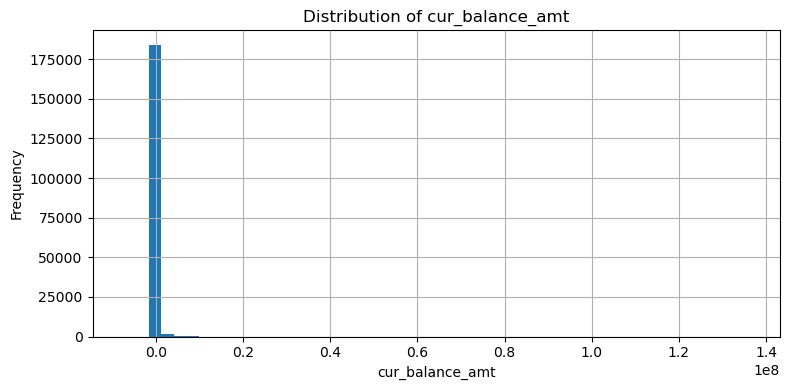

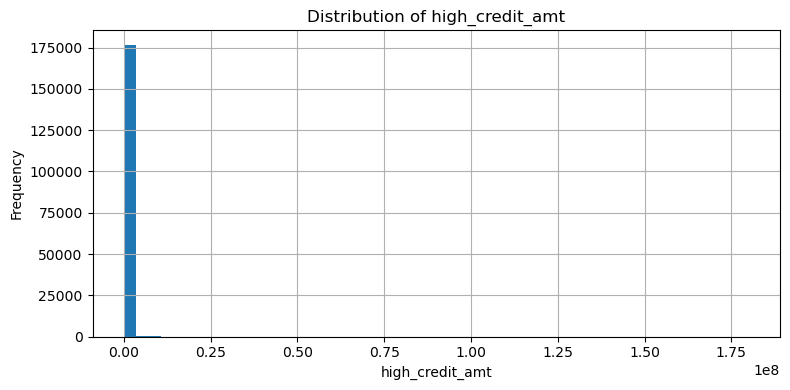

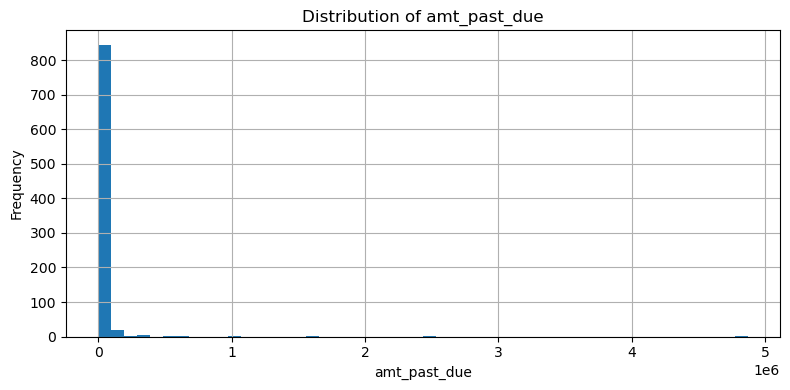

In [151]:
for col in balance_columns:
    plt.figure(figsize=(8, 4))

    account_df[col].dropna().hist(bins=50)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

In [152]:
for col in balance_columns:

    print(f"\n{col}")

    display(
        account_df[col].quantile(
            [0.90, 0.95, 0.99, 0.995, 0.999]
        )
    )


cur_balance_amt


0.900    1.018118e+05
0.950    2.792998e+05
0.990    1.465971e+06
0.995    2.339635e+06
0.999    5.918697e+06
Name: cur_balance_amt, dtype: float64


high_credit_amt


0.900    3.025800e+05
0.950    5.500000e+05
0.990    2.340000e+06
0.995    3.448000e+06
0.999    9.154700e+06
Name: high_credit_amt, dtype: float64


amt_past_due


0.900      33802.500
0.950      63338.000
0.990     305409.750
0.995     895914.500
0.999    2821403.875
Name: amt_past_due, dtype: float64

In [153]:
# Filter negative current balances for inspection only

negative_balances = account_df[
    account_df['cur_balance_amt'] < 0
]

print("Number of negative balance records:",
      len(negative_balances))

display(
    negative_balances[
        ['customer_no', 'acct_type', 'cur_balance_amt',
         'high_credit_amt', 'amt_past_due']
    ].head(20)
)

Number of negative balance records: 8881


,customer_no,acct_type,cur_balance_amt,high_credit_amt,amt_past_due
39,12379,10,-34,46742.0,NaN
42,12379,10,-7,82074.0,NaN
54,12379,10,-2,NaN,NaN
65,12379,10,-1,31000.0,NaN
72,12379,10,-1,25935.0,NaN
78,17744,10,-6327,28261.0,NaN
82,17744,10,-6327,28261.0,NaN
88,370,1,-1771,36500.0,NaN
107,6218,10,-45,26624.0,NaN
110,6218,10,-1,24251.0,NaN


In [154]:
display(
    account_df.nlargest(10, 'cur_balance_amt')[
        ['customer_no', 'acct_type', 'cur_balance_amt',
         'high_credit_amt', 'amt_past_due']
    ]
)

,customer_no,acct_type,cur_balance_amt,high_credit_amt,amt_past_due
176100,6999,2,136009965,180000000.0,NaN
153169,16438,3,43403125,60000000.0,NaN
142558,17594,3,42444359,46000000.0,NaN
10160,8845,2,39138851,40000000.0,NaN
125758,22949,2,38950534,41477744.0,NaN
111767,19708,2,34942978,35500000.0,NaN
79186,15012,2,34731070,34900000.0,NaN
90670,60,0,32339854,69966552.0,NaN
19155,7535,2,32063143,33000000.0,NaN
152735,7599,0,30500000,30500000.0,NaN


In [155]:
display(
    account_df.nlargest(10, 'high_credit_amt')[
        ['customer_no', 'acct_type', 'cur_balance_amt',
         'high_credit_amt', 'amt_past_due']
    ]
)

,customer_no,acct_type,cur_balance_amt,high_credit_amt,amt_past_due
176100,6999,2,136009965,180000000.0,NaN
176105,6999,51,0,100000000.0,NaN
176104,6999,51,0,95463505.0,NaN
176110,6999,51,0,85000000.0,NaN
90671,60,3,0,70555622.0,NaN
90670,60,0,32339854,69966552.0,NaN
70602,20248,51,0,60500000.0,NaN
153169,16438,3,43403125,60000000.0,NaN
70603,20248,3,0,51700000.0,NaN
142558,17594,3,42444359,46000000.0,NaN


In [156]:
display(
    account_df.nlargest(10, 'amt_past_due')[
        ['customer_no', 'acct_type', 'cur_balance_amt',
         'high_credit_amt', 'amt_past_due']
    ]
)

,customer_no,acct_type,cur_balance_amt,high_credit_amt,amt_past_due
31181,13198,10,4869309,4869309.0,4869309.0
98230,1,10,2528846,2528846.0,2528846.0
27195,42,12,1561783,1499529.0,1561783.0
118185,16099,51,1053440,1000000.0,1053440.0
118207,16099,51,1053440,1000000.0,1053440.0
27194,42,0,6614497,8200000.0,633372.0
152512,6307,2,576298,NaN,576298.0
41448,20598,2,1291105,1511000.0,355295.0
90691,9443,5,242796,300000.0,311652.0
92146,10434,10,303329,NaN,303329.0


### Account Balance Analysis

The following variables were investigated:

* `cur_balance_amt`
* `high_credit_amt`
* `amt_past_due`

#### 1. Current Balance (`cur_balance_amt`)

* Total records: 186,329.
* Missing values: 0.
* Zero values: 89,872.
* Negative values: 8,881.
* Mean: 76,402.69.
* Median: 0.
* Minimum: -7,355,205.
* Maximum: 136,009,965.

The distribution is strongly right-skewed. The mean is considerably higher than the median, and the histogram shows a large concentration of observations near zero.

Negative balances were inspected. Some values are close to zero, while others are considerably larger in magnitude. Their business meaning has not been established.

#### 2. High Credit Amount (`high_credit_amt`)

* Total records: 186,329.
* Missing values: 8,875 (4.76%).
* Mean: 175,610.35.
* Median: 45,223.50.
* Minimum: 1.
* Maximum: 180,000,000.

The distribution is strongly right-skewed, with a substantial difference between the mean and median.

Inspection of the largest records showed that some customers have multiple accounts with exceptionally high credit amounts. Some of these records have zero current balances.

#### 3. Amount Past Due (`amt_past_due`)

* Total records: 186,329.
* Available values: 876.
* Missing values: 185,453 (99.53%).
* Mean: 25,831.51.
* Median: 1,209.50.
* Minimum: 1.
* Maximum: 4,869,309.

The column has extremely high missingness. Its available values are strongly right-skewed, with a small number of very large amounts.

Some inspected records had identical current balance, high credit, and past-due amounts. The reason for these patterns is unknown.

#### 4. Extreme-Value Investigation

Upper percentiles were examined to understand the distribution tails.

| Percentile | Current balance | High credit |     Past due |
| ---------- | --------------: | ----------: | -----------: |
| 90th       |         101,812 |     302,580 |    33,802.50 |
| 95th       |      279,299.80 |     550,000 |       63,338 |
| 99th       |       1,465,971 |   2,340,000 |   305,409.75 |
| 99.5th     |       2,339,635 |   3,448,000 |   895,914.50 |
| 99.9th     |       5,918,697 |   9,154,700 | 2,821,403.88 |

The percentiles for `amt_past_due` are based on its 876 non-missing observations.

Inspection of the largest records showed that:

* Some extreme current balances are accompanied by high credit amounts.
* Some customers appear multiple times with different account types.
* Some records have zero current balances despite high credit amounts.
* Some past-due records have identical values across multiple balance columns.
* Repeated displayed records require caution before any duplicate-handling decision.

#### Conclusion

The three balance variables exhibit highly skewed distributions and substantial extreme values.

`cur_balance_amt` contains negative values and many zero balances. `high_credit_amt` has relatively low missingness but a wide range of values. `amt_past_due` has extremely high missingness, making its available observations limited.

These findings are descriptive. No records were removed, no missing values were filled, and no transformations were performed. The business meaning of unusual values and missingness remains unverified.


In [157]:
# Credit_Limit Analysis
credit_columns = ['creditlimit', 'cashlimit']

credit_summary = account_df[credit_columns].describe().T

credit_summary['missing_count'] = (
    account_df[credit_columns].isnull().sum()
)

credit_summary['missing_percentage'] = (
    account_df[credit_columns].isnull().mean() * 100
)

display(credit_summary)

,count,mean,std,min,25%,50%,75%,max,missing_count,missing_percentage
creditlimit,48852.0,75528.806559,71741.089587,1.0,31000.0,60000.0,100000.0,2500000.0,137477,73.781859
cashlimit,35282.0,20608.503401,24856.481410,1.0,7500.0,12500.0,27000.0,1000000.0,151047,81.064676


In [158]:
for col in credit_columns:
    print(f"\n{col}")
    print("Zero values:", (account_df[col] == 0).sum())
    print("Negative values:", (account_df[col] < 0).sum())
    print("Missing values:", account_df[col].isnull().sum())


creditlimit
Zero values: 0
Negative values: 0
Missing values: 137477

cashlimit
Zero values: 0
Negative values: 0
Missing values: 151047


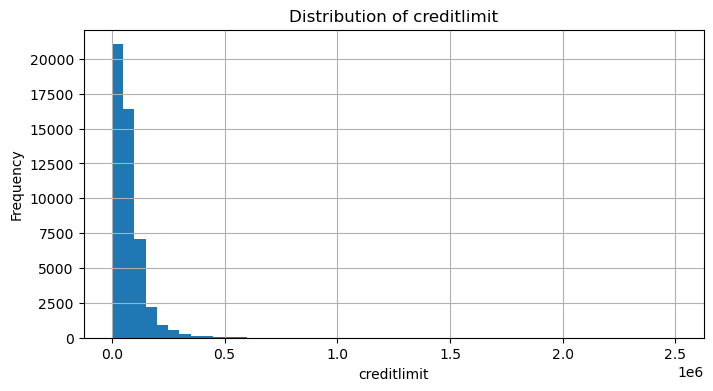

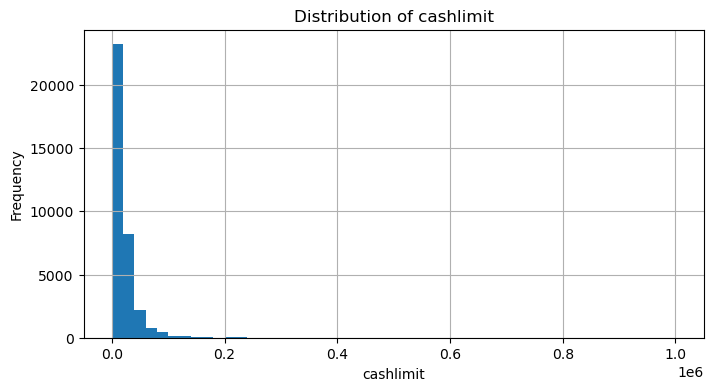

In [159]:
import matplotlib.pyplot as plt

for col in credit_columns:
    plt.figure(figsize=(8, 4))

    account_df[col].dropna().hist(bins=50)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')

    plt.show()

### Credit-Limit Analysis

The following variables were investigated:

* `creditlimit`
* `cashlimit`

#### 1. Credit Limit (`creditlimit`)

* Total records: 186,329.
* Available records: 48,852.
* Missing values: 137,477 (73.78%).
* Mean: 75,528.81.
* Median: 60,000.
* Minimum: 1.
* Maximum: 2,500,000.
* Zero values: 0.
* Negative values: 0.

The distribution is strongly right-skewed. Most available observations are concentrated toward the lower end, with a smaller number of substantially higher values.

#### 2. Cash Limit (`cashlimit`)

* Total records: 186,329.
* Available records: 35,282.
* Missing values: 151,047 (81.06%).
* Mean: 20,608.50.
* Median: 12,500.
* Minimum: 1.
* Maximum: 1,000,000.
* Zero values: 0.
* Negative values: 0.

The distribution is also strongly right-skewed, with most observations concentrated at lower values and a smaller number of extreme values.

#### Conclusion

Both credit-limit variables have substantial missingness. `cashlimit` has a higher missing percentage than `creditlimit`.

Their distributions are strongly right-skewed, and neither variable contains


In [160]:
for col in credit_columns:
    print(f"\n{col.upper()}")

    print("\nUpper percentiles:")
    display(
        account_df[col].quantile(
            [0.90, 0.95, 0.99, 0.995, 0.999]
        )
    )

    print("\nTop 10 records:")
    display(
        account_df.nlargest(10, col)[
            ['customer_no', 'acct_type', col]
        ]
    )


CREDITLIMIT

Upper percentiles:


0.900    144940.0
0.950    194000.0
0.990    348000.0
0.995    447000.0
0.999    714894.0
Name: creditlimit, dtype: float64


Top 10 records:


,customer_no,acct_type,creditlimit
59662,84,10,2500000.0
46396,11340,10,1500000.0
46140,9561,10,1365500.0
116061,19858,10,1350000.0
144666,7621,10,1200000.0
4054,8312,10,1000000.0
70009,17827,10,1000000.0
101761,2,10,1000000.0
132189,4265,10,1000000.0
152074,21,10,1000000.0



CASHLIMIT

Upper percentiles:


0.900     42000.0
0.950     60000.0
0.990    120514.0
0.995    153000.0
0.999    240000.0
Name: cashlimit, dtype: float64


Top 10 records:


,customer_no,acct_type,cashlimit
70009,17827,10,1000000.0
144665,7621,10,576200.0
91381,22869,10,450000.0
102845,17420,10,450000.0
152240,90,10,450000.0
55927,10691,10,440000.0
13475,12063,10,400000.0
132189,4265,10,400000.0
68843,11,10,390546.0
68844,11,10,390546.0


### Credit Limit Analysis

The account dataset contains two credit-limit variables: `creditlimit` and `cashlimit`.

**Key findings:**

* `creditlimit` has 73.78% missing values, while `cashlimit` has 81.06% missing values.
* The median credit limit is 60,000, compared with a mean of approximately 75,529.
* The median cash limit is 12,500, compared with a mean of approximately 20,609.
* Both variables exhibit strongly right-skewed distributions, with a small number of very large values.
* The maximum observed values are 2,500,000 for `creditlimit` and 1,000,000 for `cashlimit`.
* No zero or negative values were observed among the available records.

**Conclusion:**

Both variables have substantial missingness and highly skewed distributions. Their descriptive statistics should therefore be interpreted cautiously. The reasons for the missing values and extreme observations are not established.

No records were removed, no missing values were filled, and no transformations were performed.


In [161]:
# Payment History Patterns
payment_columns = ['paymenthistory1', 'paymenthistory2']

for col in payment_columns:
    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"{'=' * 50}")

    print("Data type:", account_df[col].dtype)
    print("Missing values:", account_df[col].isna().sum())
    print("Missing percentage:", account_df[col].isna().mean() * 100)

    print("\nNumber of unique values:")
    print(account_df[col].nunique())

    print("\nTop 20 most frequent values:")
    display(account_df[col].value_counts(dropna=False).head(20))


Column: paymenthistory1
Data type: object
Missing values: 0
Missing percentage: 0.0

Number of unique values:
18311

Top 20 most frequent values:


paymenthistory1
"""000000000000000000000000000000000000000000000000000000"""    44979
"""000"""                                                       12550
"""XXX"""                                                        6489
"""000000"""                                                     5163
"""000000000"""                                                  4642
"""000000000000"""                                               4138
"""000000000000000000000000000000"""                             4127
"""000000000000000000000000000000000"""                          4105
"""000000000000000000000000000"""                                3916
"""000000000000000000000"""                                      3732
"""000000000000000000"""                                         3676
"""000000000000000"""                                            3654
"""000000000000000000000000"""                                   3642
"""000000000000000000000000000000000000"""                       3017
"""0


Column: paymenthistory2
Data type: object
Missing values: 107824
Missing percentage: 57.867535380965926

Number of unique values:
11911

Top 20 most frequent values:


paymenthistory2
NaN                                                             107824
"""000000000000000000000000000000000000000000000000000000"""     18956
"""XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX"""      3878
"""000"""                                                         2620
"""000000"""                                                      2072
"""000000000000000000000"""                                       1970
"""000000000"""                                                   1874
"""000000000000"""                                                1839
"""000000000000000"""                                             1691
"""000000000000000000"""                                          1688
"""000000000000000000000000"""                                    1501
"""000000000000000000000000000"""                                 1327
"""000000000000000000000000000000"""                              1192
"""000000000000000000000000000000000"""                      

In [162]:
for col in payment_columns:

    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"{'=' * 50}")

    # Inspect actual stored values
    print("\nSample values:")
    for value in account_df[col].dropna().head(10):
        print(repr(value))

    # Examine string lengths
    lengths = account_df[col].dropna().astype(str).str.len()

    print("\nString length summary:")
    display(lengths.describe())

    print("\nTop 15 most frequent string lengths:")
    display(lengths.value_counts().head(15))

    # Examine characters present
    characters = set(
        ''.join(account_df[col].dropna().astype(str))
    )

    print("\nUnique characters:")
    print(sorted(characters))


Column: paymenthistory1

Sample values:
'"""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXSTD"""'
'"""000000000000000000000000000000000000000000000000000000"""'
'"""000000000000000000000000000000000000000000000000000000"""'
'"""120090060060060030000000000000000000000000000000000000"""'
'"""000000000000000"""'
'"""000000000000000"""'
'"""000000000000000000"""'
'"""000000000000000000000000"""'
'"""000000000000000000000000000000000000000000000000000000"""'
'"""000000000XXX000000000000030XXX000000000000000000000000"""'

String length summary:


count    186329.000000
mean         41.676153
std          19.682810
min           9.000000
25%          24.000000
50%          48.000000
75%          60.000000
max          60.000000
Name: paymenthistory1, dtype: float64


Top 15 most frequent string lengths:


paymenthistory1
60    81566
9     21410
36     6852
33     6702
12     6674
15     6292
39     5987
18     5834
30     5620
24     5474
27     5299
21     5022
42     4860
45     4467
48     4122
Name: count, dtype: int64


Unique characters:
['"', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'D', 'L', 'M', 'S', 'T', 'U', 'X']

Column: paymenthistory2

Sample values:
'"""000000000000000000000000000XXX000000000000000000000000"""'
'"""000000000000000000000000000000000000000000000000000000"""'
'"""000000000000000000000000000000000000"""'
'"""030000000000XXX000000000000000000000000XXX000000000"""'
'"""000000000000000000000000000000000000000000000000000000"""'
'"""553523492464433402372XXX311280249219188158127099XXX007"""'
'"""XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXSTDSTDSTDSTDSTDSTDSTDSTD"""'
'"""XXXSTD"""'
'"""XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX"""'
'"""XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX"""'

String length summary:


count    78505.000000
mean        45.907433
std         17.836197
min          9.000000
25%         30.000000
50%         60.000000
75%         60.000000
max         60.000000
Name: paymenthistory2, dtype: float64


Top 15 most frequent string lengths:


paymenthistory2
60    41202
9      3039
27     3030
12     2609
24     2538
30     2496
18     2432
15     2431
21     2374
33     2100
39     1956
36     1954
42     1865
45     1861
57     1736
Name: count, dtype: int64


Unique characters:
['"', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'D', 'L', 'M', 'S', 'T', 'U', 'X']


In [163]:
for col in payment_columns:

    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"{'=' * 50}")

    # Remove surrounding quotation marks temporarily
    cleaned = account_df[col].dropna().astype(str).str.strip('"')

    # Check whether lengths are divisible by 3
    remainders = cleaned.str.len() % 3

    print("Records with length divisible by 3:", (remainders == 0).sum())
    print("Records with remaining characters:", (remainders != 0).sum())

    # Divide strings into three-character units
    segments = cleaned.apply(
        lambda value: [
            value[i:i+3]
            for i in range(0, len(value), 3)
        ]
    )

    # Count the frequency of each unit
    segment_counts = segments.explode().value_counts()

    print("\nTop 20 most frequent three-character units:")
    display(segment_counts.head(20))

    print("\nTotal distinct three-character units:")
    print(segment_counts.size)


Column: paymenthistory1
Records with length divisible by 3: 186329
Records with remaining characters: 0

Top 20 most frequent three-character units:


paymenthistory1
000    1757758
XXX     233218
STD     147940
900       7173
030       5526
001       3419
015       2820
180       2729
060       2728
150       2028
090       1857
025       1720
026       1293
120       1256
007       1098
024        931
008        925
006        710
SUB        693
023        650
Name: count, dtype: int64


Total distinct three-character units:
899

Column: paymenthistory2
Records with length divisible by 3: 78505
Records with remaining characters: 0

Top 20 most frequent three-character units:


paymenthistory2
000    798678
XXX    152659
STD     51330
900      3052
030      2881
001      2336
180      2116
015      1870
150      1163
060      1111
025      1045
026       789
090       532
024       513
008       495
007       482
023       481
020       454
055       449
006       434
Name: count, dtype: int64


Total distinct three-character units:
890


In [164]:
# Categories the payment-history codes 
import re

for col in payment_columns:

    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"{'=' * 50}")

    cleaned = account_df[col].dropna().astype(str).str.strip('"')

    # Split each history string into three-character units
    segments = cleaned.apply(
        lambda value: [
            value[i:i+3]
            for i in range(0, len(value), 3)
        ]
    ).explode()

    # Categorise each unit
    numeric_count = segments.str.fullmatch(r'\d{3}').sum()
    alphabetic_count = segments.str.fullmatch(r'[A-Za-z]{3}').sum()
    mixed_count = segments.str.fullmatch(r'(?=.*[A-Za-z])(?=.*\d)[A-Za-z\d]{3}').sum()

    print("Total units:", len(segments))
    print("Numeric units:", numeric_count)
    print("Alphabetic units:", alphabetic_count)
    print("Mixed units:", mixed_count)

    print("\nDistinct alphabetic codes:")
    display(
        segments[segments.str.fullmatch(r'[A-Za-z]{3}')]
        .value_counts()
    )

    print("\nNumeric code range:")
    numeric_codes = pd.to_numeric(
        segments[segments.str.fullmatch(r'\d{3}')],
        errors='coerce'
    )

    display(numeric_codes.describe())


Column: paymenthistory1
Total units: 2215834
Numeric units: 1833451
Alphabetic units: 382383
Mixed units: 0

Distinct alphabetic codes:


paymenthistory1
XXX    233218
STD    147940
SUB       693
DBT       281
LSS       176
SMA        75
Name: count, dtype: int64


Numeric code range:


count    1.833451e+06
mean     8.746838e+00
std      7.202263e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      9.000000e+02
Name: paymenthistory1, dtype: float64


Column: paymenthistory2
Total units: 1044311
Numeric units: 839770
Alphabetic units: 204541
Mixed units: 0

Distinct alphabetic codes:


paymenthistory2
XXX    152659
STD     51330
SUB       280
DBT       141
LSS        87
SMA        44
Name: count, dtype: int64


Numeric code range:


count    839770.000000
mean          9.610658
std          74.244068
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         900.000000
Name: paymenthistory2, dtype: float64

### Payment History Analysis

The `paymenthistory1` and `paymenthistory2` columns contain structured payment-history information stored as strings.

#### Structural observations

* All non-missing records have string lengths divisible by three.
* Each three-character segment appears to represent an individual payment-history unit.
* The maximum string length is 60 characters, corresponding to 20 three-character units.
* `paymenthistory1` contains 186,329 non-missing records.
* `paymenthistory2` contains 78,505 non-missing records, with approximately 57.87% missing values.

#### Code observations

The three-character units contain numeric and alphabetic codes.

Numeric examples: `000`, `030`, `060`, `090`, `180`, and `900`.

Alphabetic examples: `XXX`, `STD`, `SUB`, `DBT`, `LSS`, and `SMA`.

The `000` code is the most frequently occurring unit in both columns. Alphabetic codes also account for a substantial number of observations.

#### Conclusion

Both payment-history columns follow a consistent three-character structure and contain a combination of numeric and alphabetic codes. These variables may contain useful historical repayment information.

However, the business meaning of individual codes and the chronological order of the segments have not been established. Therefore, no assumptions about their meanings or transformations have been made.

No records were removed, missing values were not filled, and the original columns were not modified.


In [165]:
for col in payment_columns:

    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"{'=' * 50}")

    cleaned = account_df[col].dropna().astype(str).str.strip('"')

    segments = cleaned.apply(
        lambda value: [
            value[i:i+3]
            for i in range(0, len(value), 3)
        ]
    ).explode()

    numeric_codes = segments[
        segments.str.fullmatch(r'\d{3}')
    ]

    print("\nTop 20 numeric codes excluding 000:")

    display(
        numeric_codes[numeric_codes != '000']
        .value_counts()
        .head(20)
    )


Column: paymenthistory1

Top 20 numeric codes excluding 000:


paymenthistory1
900    7173
030    5526
001    3419
015    2820
180    2729
060    2728
150    2028
090    1857
025    1720
026    1293
120    1256
007    1098
024     931
008     925
006     710
023     650
055     646
020     631
016     594
038     548
Name: count, dtype: int64


Column: paymenthistory2

Top 20 numeric codes excluding 000:


paymenthistory2
900    3052
030    2881
001    2336
180    2116
015    1870
150    1163
060    1111
025    1045
026     789
090     532
024     513
008     495
007     482
023     481
020     454
055     449
006     434
120     426
016     382
027     357
Name: count, dtype: int64

In [166]:
# How many records contain each code
for col in payment_columns:

    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"{'=' * 50}")

    cleaned = account_df[col].dropna().astype(str).str.strip('"')

    # Split each record into three-character units
    segments = cleaned.apply(
        lambda value: [
            value[i:i+3]
            for i in range(0, len(value), 3)
        ]
    )

    # Count records containing each code
    record_counts = segments.apply(
        lambda codes: set(codes)
    ).explode().value_counts()

    # Exclude 000 and select numeric codes
    numeric_counts = record_counts[
        record_counts.index.str.fullmatch(r'\d{3}')
    ]

    numeric_counts = numeric_counts.drop(
        '000', errors='ignore'
    )

    print("\nTop 20 numeric codes by number of records containing them:")

    display(numeric_counts.head(20))


Column: paymenthistory1

Top 20 numeric codes by number of records containing them:


paymenthistory1
030    2899
001    2087
060    1763
015    1517
090    1288
120     951
025     900
026     727
007     715
900     680
008     574
150     564
024     559
006     507
180     505
023     454
038     422
055     405
005     395
056     381
Name: count, dtype: int64


Column: paymenthistory2

Top 20 numeric codes by number of records containing them:


paymenthistory2
030    1573
001    1449
015    1010
060     685
025     532
026     424
090     357
900     331
007     325
008     313
024     310
006     310
023     309
016     273
150     261
120     256
019     245
020     242
180     231
027     214
Name: count, dtype: int64

### Record-Level Frequency of Payment History Codes

After examining the overall frequency of three-character payment-history codes, a record-level frequency analysis was performed.

The purpose was to identify how many account records contained each code at least once. This differs from the previous frequency analysis, which counted every occurrence of a code across all payment-history strings.

**Key observations:**

* `030` appeared in the highest number of records in both `paymenthistory1` (2,899 records) and `paymenthistory2` (1,573 records).
* `001` was the second most common code in both columns, appearing in 2,087 and 1,449 records, respectively.
* Other relatively common codes included `060`, `015`, `090`, `025`, and `026`.
* Although `900` had the highest total occurrence count in the previous analysis, it appeared in fewer individual records than `030` and `001`.

**Conclusion:**

The analysis shows that some codes occur repeatedly within individual payment-history records, while others are distributed across a larger number of records.

The business definitions of these codes are unavailable. Therefore, no assumptions have been made about their meanings.

No data transformations, modifications, or record removals were performed.


In [167]:
top_codes = [
    '030', '001', '060', '015', '090',
    '120', '025', '026', '900', '007'
]

for col in payment_columns:

    print(f"\n{'=' * 60}")
    print(f"Column: {col}")
    print(f"{'=' * 60}")

    # Remove missing values and surrounding quotation marks
    cleaned = (
        account_df[col]
        .dropna()
        .astype(str)
        .str.strip('"')
    )

    # Divide each payment-history string into three-character segments
    segments = cleaned.apply(
        lambda value: [
            value[i:i+3]
            for i in range(0, len(value), 3)
        ]
    )

    # Convert the segments into a DataFrame.
    # Each column represents a position in the payment history.
    position_df = pd.DataFrame(segments.tolist())

    # Count how many records contain each selected code at each position
    position_counts = pd.DataFrame(index=top_codes)

    for position in position_df.columns:

        position_counts[f'Position {position + 1}'] = (
            position_df[position]
            .value_counts()
            .reindex(top_codes, fill_value=0)
        )

    display(position_counts)


Column: paymenthistory1


,Position 1,Position 2,Position 3,Position 4,Position 5,Position 6,Position 7,Position 8,Position 9,Position 10,Position 11,Position 12,Position 13,Position 14,Position 15,Position 16,Position 17,Position 18
030,121,309,433,613,428,428,368,330,307,298,265,275,247,237,230,203,210,224
001,97,226,197,307,251,237,217,212,179,190,191,174,168,157,164,146,170,136
060,97,327,479,266,233,183,141,134,121,100,88,79,90,80,72,83,80,75
015,36,134,131,143,174,188,166,155,193,186,192,162,172,165,174,138,164,147
090,148,472,226,190,142,97,76,73,58,47,40,44,48,34,40,38,41,43
120,319,180,145,97,59,51,65,40,31,35,30,31,21,31,32,31,29,29
025,31,88,82,100,102,100,103,109,116,111,106,106,98,94,86,95,98,95
026,18,77,77,61,60,78,80,83,86,90,72,73,81,74,84,66,68,65
900,38,391,545,546,516,509,492,464,452,417,400,392,383,364,344,324,303,293
007,39,55,70,76,81,78,94,85,63,57,58,41,43,47,48,66,45,52



Column: paymenthistory2


,Position 1,Position 2,Position 3,Position 4,Position 5,Position 6,Position 7,Position 8,Position 9,Position 10,Position 11,Position 12,Position 13,Position 14,Position 15,Position 16,Position 17,Position 18
030,217,220,194,193,161,150,168,180,156,170,139,163,140,136,130,127,122,115
001,169,147,148,151,153,136,147,170,135,123,101,130,119,122,92,103,89,101
060,81,73,76,58,63,79,82,64,66,57,70,53,61,48,47,52,43,38
015,159,132,139,112,103,111,99,89,98,101,123,96,87,88,85,90,78,80
090,34,37,33,34,52,45,34,32,28,32,23,27,21,21,25,22,17,15
120,27,31,32,40,24,25,29,29,29,23,18,20,23,20,18,11,13,14
025,94,74,89,82,57,53,58,55,68,57,47,49,47,51,46,36,37,45
026,71,57,54,42,45,47,46,48,45,41,44,32,35,32,46,36,33,35
900,277,264,239,225,213,203,190,181,166,151,143,142,133,115,112,111,97,90
007,46,39,35,29,26,23,26,22,28,25,24,31,29,17,16,16,18,32


In [168]:
top_codes = [
    '030', '001', '060', '015', '090',
    '120', '025', '026', '900', '007'
]

for col in payment_columns:

    print(f"\n{'=' * 60}")
    print(f"Column: {col}")
    print(f"{'=' * 60}")

    cleaned = (
        account_df[col]
        .dropna()
        .astype(str)
        .str.strip('"')
    )

    segments = cleaned.apply(
        lambda value: [
            value[i:i+3]
            for i in range(0, len(value), 3)
        ]
    )

    position_df = pd.DataFrame(segments.tolist())

    position_counts = pd.DataFrame(index=top_codes)

    for position in position_df.columns:

        position_counts[f'Position {position + 1}'] = (
            position_df[position]
            .value_counts()
            .reindex(top_codes, fill_value=0)
        )

    # Count available records at each position
    position_totals = position_df.count()

    # Match the position labels
    position_totals.index = [
        f'Position {position + 1}'
        for position in position_totals.index
    ]

    # Calculate percentages
    position_percentages = (
        position_counts
        .div(position_totals, axis=1)
        * 100
    )

    display(position_percentages.round(2))


Column: paymenthistory1


,Position 1,Position 2,Position 3,Position 4,Position 5,Position 6,Position 7,Position 8,Position 9,Position 10,Position 11,Position 12,Position 13,Position 14,Position 15,Position 16,Position 17,Position 18
030,0.06,0.19,0.27,0.40,0.29,0.30,0.27,0.25,0.25,0.25,0.24,0.26,0.25,0.25,0.25,0.23,0.25,0.27
001,0.05,0.14,0.12,0.20,0.17,0.17,0.16,0.16,0.14,0.16,0.17,0.17,0.17,0.16,0.18,0.17,0.20,0.17
060,0.05,0.20,0.30,0.18,0.16,0.13,0.10,0.10,0.10,0.08,0.08,0.08,0.09,0.08,0.08,0.09,0.09,0.09
015,0.02,0.08,0.08,0.09,0.12,0.13,0.12,0.12,0.15,0.16,0.17,0.15,0.17,0.17,0.19,0.16,0.19,0.18
090,0.08,0.29,0.14,0.13,0.10,0.07,0.06,0.06,0.05,0.04,0.04,0.04,0.05,0.04,0.04,0.04,0.05,0.05
120,0.17,0.11,0.09,0.06,0.04,0.04,0.05,0.03,0.02,0.03,0.03,0.03,0.02,0.03,0.03,0.04,0.03,0.04
025,0.02,0.05,0.05,0.07,0.07,0.07,0.08,0.08,0.09,0.09,0.10,0.10,0.10,0.10,0.09,0.11,0.12,0.12
026,0.01,0.05,0.05,0.04,0.04,0.06,0.06,0.06,0.07,0.08,0.06,0.07,0.08,0.08,0.09,0.07,0.08,0.08
900,0.02,0.24,0.34,0.36,0.35,0.36,0.36,0.36,0.36,0.35,0.36,0.37,0.38,0.38,0.38,0.37,0.36,0.36
007,0.02,0.03,0.04,0.05,0.06,0.06,0.07,0.07,0.05,0.05,0.05,0.04,0.04,0.05,0.05,0.07,0.05,0.06



Column: paymenthistory2


,Position 1,Position 2,Position 3,Position 4,Position 5,Position 6,Position 7,Position 8,Position 9,Position 10,Position 11,Position 12,Position 13,Position 14,Position 15,Position 16,Position 17,Position 18
030,0.28,0.29,0.27,0.27,0.24,0.23,0.27,0.30,0.27,0.31,0.26,0.32,0.28,0.28,0.28,0.29,0.28,0.28
001,0.22,0.19,0.20,0.21,0.23,0.21,0.23,0.28,0.23,0.22,0.19,0.25,0.24,0.26,0.20,0.23,0.21,0.25
060,0.10,0.10,0.10,0.08,0.09,0.12,0.13,0.11,0.11,0.10,0.13,0.10,0.12,0.10,0.10,0.12,0.10,0.09
015,0.20,0.17,0.19,0.16,0.15,0.17,0.16,0.15,0.17,0.18,0.23,0.19,0.18,0.18,0.18,0.20,0.18,0.19
090,0.04,0.05,0.05,0.05,0.08,0.07,0.05,0.05,0.05,0.06,0.04,0.05,0.04,0.04,0.05,0.05,0.04,0.04
120,0.03,0.04,0.04,0.06,0.04,0.04,0.05,0.05,0.05,0.04,0.03,0.04,0.05,0.04,0.04,0.02,0.03,0.03
025,0.12,0.10,0.12,0.12,0.08,0.08,0.09,0.09,0.12,0.10,0.09,0.10,0.09,0.11,0.10,0.08,0.09,0.11
026,0.09,0.08,0.07,0.06,0.07,0.07,0.07,0.08,0.08,0.07,0.08,0.06,0.07,0.07,0.10,0.08,0.08,0.08
900,0.35,0.35,0.33,0.32,0.31,0.31,0.30,0.30,0.29,0.27,0.27,0.28,0.27,0.24,0.24,0.25,0.23,0.22
007,0.06,0.05,0.05,0.04,0.04,0.04,0.04,0.04,0.05,0.05,0.04,0.06,0.06,0.04,0.03,0.04,0.04,0.08


### Positional Analysis of Payment History Codes

A positional analysis was performed on `paymenthistory1` and `paymenthistory2` to investigate how frequently selected numeric codes appeared at different positions within the payment-history strings.

The ten frequently occurring numeric codes identified in the previous analysis were selected. For each position, the percentage of available account records containing each code was calculated.

**Key observations from paymenthistory1:**

* Code `030` reached its highest observed percentage at Position 4.
* Code `060` was most concentrated around Position 3.
* Code `120` showed a generally declining pattern across subsequent positions.
* Code `900` increased considerably after Position 1 and remained relatively frequent across later positions.

**Key observations from paymenthistory2:**

* Code `030` maintained a relatively consistent distribution across positions.
* Code `900` showed a gradual decline from Position 1 towards Position 18.
* Codes `001` and `015` also showed relatively stable positional distributions.

**Comparison:**

The positional distributions differed between the two payment-history columns. `paymenthistory1` showed stronger positional variation for certain codes, while `paymenthistory2` showed comparatively stable distributions for most selected codes.

**Conclusion:**

The analysis identified differences in the positional distribution of payment-history codes across the two columns. However, the chronological meaning of the positions and the business definitions of the codes are unknown.

Therefore, these findings are descriptive only. No assumptions were made about payment status, delinquency periods, or the chronological direction of the payment-history strings.

No original data was modified or removed.


In [169]:
# Check data types
print(account_df[['opened_dt', 'closed_dt']].dtypes)

# Inspect sample values
display(account_df[['opened_dt', 'closed_dt']].head(10))

opened_dt    object
closed_dt    object
dtype: object


,opened_dt,closed_dt
0,09-Jun-13,05-Jul-14
1,25-May-12,NaN
2,22-Mar-12,NaN
3,13-Jan-06,26-Jul-07
4,18-Jan-15,NaN
5,14-Jan-15,NaN
6,29-Dec-14,NaN
7,22-Oct-14,NaN
8,04-Dec-12,NaN
9,01-Aug-12,NaN


In [170]:
# Create a separate DataFrame
lifecycle_df = account_df[
    ['opened_dt', 'closed_dt']
].copy()

# Convert dates using the identified format
for col in ['opened_dt', 'closed_dt']:

    lifecycle_df[col] = pd.to_datetime(
        lifecycle_df[col],
        format='%d-%b-%y',
        errors='coerce'
    )

# Verify conversion
print("Data types:")
print(lifecycle_df.dtypes)

# Check missing values after conversion
print("\nMissing values:")
print(lifecycle_df.isna().sum())

# Inspect converted dates
display(lifecycle_df.head(10))

Data types:
opened_dt    datetime64[ns]
closed_dt    datetime64[ns]
dtype: object

Missing values:
opened_dt       455
closed_dt    109075
dtype: int64


,opened_dt,closed_dt
0,2013-06-09,2014-07-05
1,2012-05-25,NaT
2,2012-03-22,NaT
3,2006-01-13,2007-07-26
4,2015-01-18,NaT
5,2015-01-14,NaT
6,2014-12-29,NaT
7,2014-10-22,NaT
8,2012-12-04,NaT
9,2012-08-01,NaT


In [171]:
# Calculate account duration in days
lifecycle_df['account_duration_days'] = (
    lifecycle_df['closed_dt'] -
    lifecycle_df['opened_dt']
).dt.days

# Descriptive statistics
display(
    lifecycle_df['account_duration_days'].describe()
)

count    77100.000000
mean       784.485214
std        727.988561
min      -1045.000000
25%        296.000000
50%        542.000000
75%       1086.000000
max      10494.000000
Name: account_duration_days, dtype: float64

In [172]:
duration = lifecycle_df['account_duration_days']

print("Negative durations:", (duration < 0).sum())
print("Zero durations:", (duration == 0).sum())
print("Positive durations:", (duration > 0).sum())
print("Missing durations:", duration.isna().sum())

Negative durations: 2
Zero durations: 198
Positive durations: 76900
Missing durations: 109229


In [173]:
# Inspect records with negative account duration
negative_duration = lifecycle_df[
    lifecycle_df['account_duration_days'] < 0
]

display(negative_duration)

,opened_dt,closed_dt,account_duration_days
70142,2013-06-06,2010-07-27,-1045.0
164953,2008-08-30,2008-05-09,-113.0


In [174]:
# Retrieve original account details for these records
negative_indices = negative_duration.index

display(
    account_df.loc[
        negative_indices,
        ['customer_no', 'acct_type', 'opened_dt', 'closed_dt']
    ]
)

,customer_no,acct_type,opened_dt,closed_dt
70142,19732,10,06-Jun-13,27-Jul-10
164953,23626,2,30-Aug-08,09-May-08


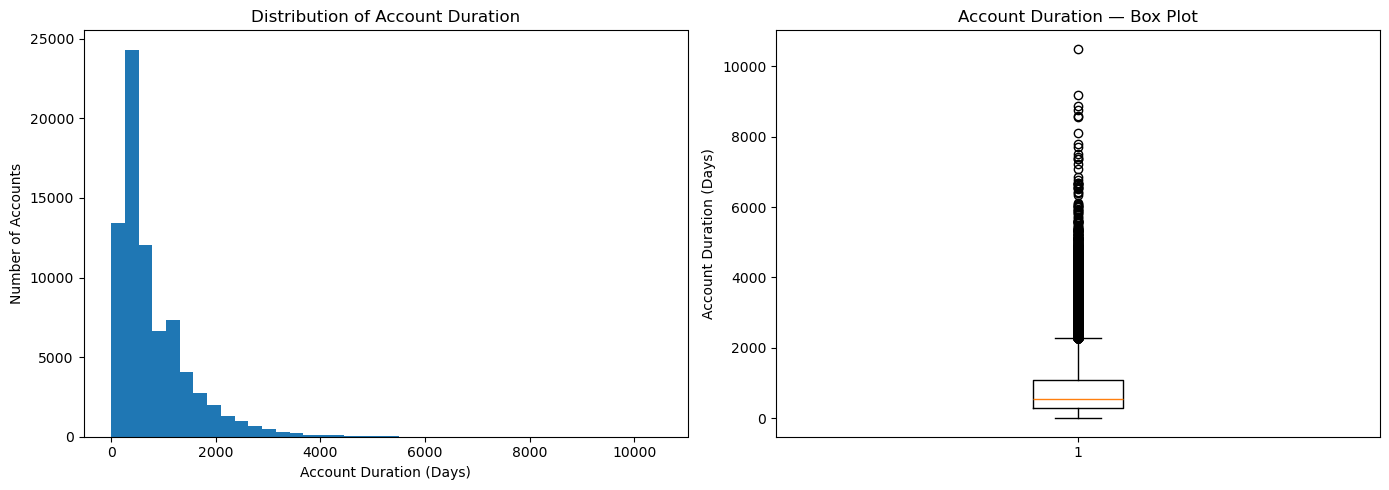

In [175]:
# Select non-negative account durations for visualisation
valid_duration = lifecycle_df.loc[
    lifecycle_df['account_duration_days'] >= 0,
    'account_duration_days'
]

# Create histogram and box plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(valid_duration, bins=40)
axes[0].set_title('Distribution of Account Duration')
axes[0].set_xlabel('Account Duration (Days)')
axes[0].set_ylabel('Number of Accounts')

# Box plot
axes[1].boxplot(valid_duration)
axes[1].set_title('Account Duration — Box Plot')
axes[1].set_ylabel('Account Duration (Days)')

plt.tight_layout()
plt.show()

### Account Duration Distribution

Account duration was calculated as the difference between the recorded account closure date and opening date.

The descriptive analysis identified 77,100 valid duration records before excluding two negative-duration records for visualisation. The duration statistics showed:

* Mean: 784.49 days
* Median: 542 days
* Standard deviation: 727.99 days
* Minimum: -1,045 days
* Maximum: 10,494 days

Two records had negative durations, indicating that their recorded closure dates preceded their opening dates. These records were investigated and retained without modification.

A histogram and box plot were used to examine the distribution of non-negative account durations.

**Key observations:**

1. The distribution is strongly right-skewed.
2. Most account durations are concentrated in the lower duration ranges.
3. The median duration is considerably lower than the mean.
4. The box plot identifies numerous potential outliers with unusually long durations.
5. The maximum recorded duration is 10,494 days.

**Conclusion:**

Account durations show substantial variation, with most accounts having relatively shorter recorded lifetimes and a smaller number having much longer durations.

The potential outliers are not automatically considered errors. No records were removed or modified during this analysis.


In [176]:
# Extract year from opening and closing dates

opening_year = lifecycle_df['opened_dt'].dt.year
closing_year = lifecycle_df['closed_dt'].dt.year

# Count accounts opened and closed each year

opening_counts = opening_year.value_counts().sort_index()
closing_counts = closing_year.value_counts().sort_index()

# Combine yearly counts into one DataFrame

yearly_activity = pd.concat(
    [opening_counts, closing_counts],
    axis=1
)

yearly_activity.columns = [
    'Accounts Opened',
    'Accounts Closed'
]

# Display yearly account activity

display(yearly_activity)

,Accounts Opened,Accounts Closed
1979.0,1,NaN
1984.0,1,NaN
1985.0,2,NaN
1988.0,1,NaN
1989.0,1,NaN
1990.0,5,NaN
1991.0,14,NaN
1992.0,22,NaN
1993.0,35,1.0
1994.0,60,NaN


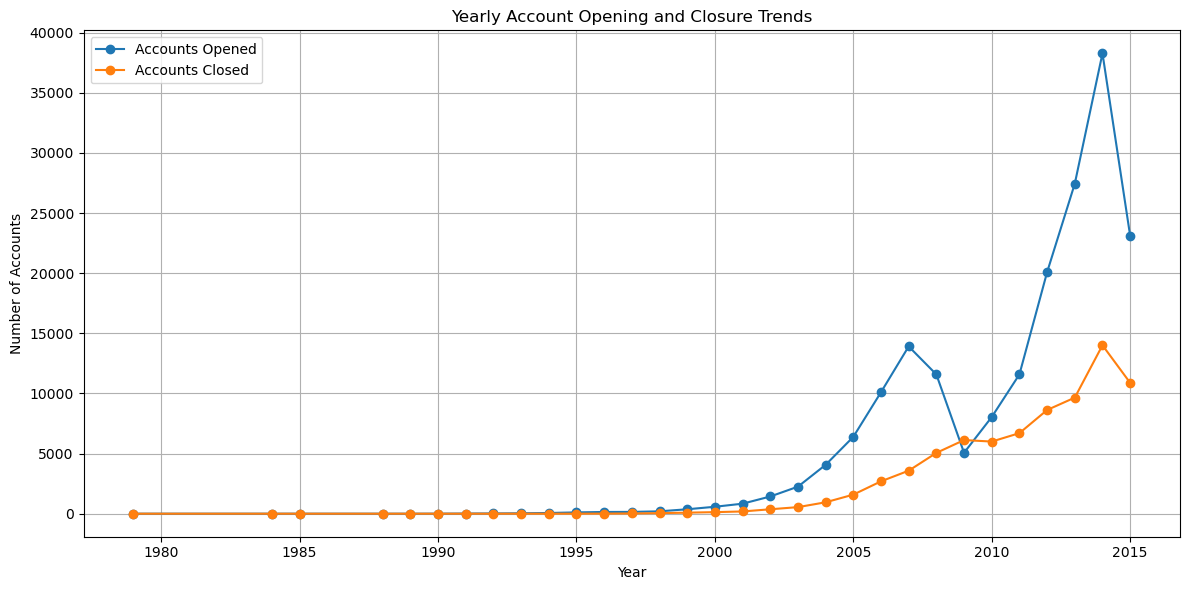

In [177]:
# Replace missing yearly counts with zero in the summary
yearly_activity_plot = yearly_activity.fillna(0)

# Create line chart
plt.figure(figsize=(12, 6))

plt.plot(
    yearly_activity_plot.index,
    yearly_activity_plot['Accounts Opened'],
    marker='o',
    label='Accounts Opened'
)

plt.plot(
    yearly_activity_plot.index,
    yearly_activity_plot['Accounts Closed'],
    marker='o',
    label='Accounts Closed'
)

plt.title('Yearly Account Opening and Closure Trends')
plt.xlabel('Year')
plt.ylabel('Number of Accounts')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Yearly Account Opening and Closure Trends

The yearly distribution of account opening and closure records was analysed to understand changes in account activity over time.

The `opened_dt` and `closed_dt` columns were used to extract the respective years. Yearly record counts were calculated and visualised using a line chart.

**Key observations — Account openings:**

* Account openings increased considerably from the early 2000s.
* A substantial increase occurred between 2003 and 2007.
* Openings declined from 13,912 in 2007 to 5,066 in 2009.
* Activity recovered after 2009.
* The highest recorded opening count was 38,285 in 2014.
* Openings declined to 23,107 in 2015.

**Key observations — Account closures:**

* Closure activity generally increased over the observed period.
* Closures increased from 5,050 in 2008 to 6,125 in 2009.
* The highest recorded closure count was 14,009 in 2014.
* Closures declined to 10,883 in 2015.

**Comparison:**

Account openings exceeded closures in most observed years. However, in 2009, the number of closures exceeded the number of openings. Both opening and closure counts reached their highest recorded levels in 2014.

**Conclusion:**

The dataset shows substantial changes in account opening and closure activity over time, particularly during the 2000–2015 period. The analysis is descriptive and does not establish the reasons behind these changes.

The counts represent account records rather than necessarily distinct customers. No original records were modified or removed during this analysis.


In [178]:
# Enquiry behaviour Analysis
# Check relevant data types
print(enquiry_df[['enquiry_dt', 'dt_opened']].dtypes)

# Inspect sample date values
display(enquiry_df[['enquiry_dt', 'dt_opened']].head(10))

enquiry_dt    object
dt_opened     object
dtype: object


,enquiry_dt,dt_opened
0,19-Dec-14,18-Apr-15
1,05-Mar-14,18-Apr-15
2,05-Mar-14,18-Apr-15
3,22-Feb-14,18-Apr-15
4,11-Jun-13,18-Apr-15
5,08-Feb-13,18-Apr-15
6,30-Nov-12,18-Apr-15
7,30-May-12,18-Apr-15
8,24-May-11,18-Apr-15
9,10-Nov-10,18-Apr-15


In [179]:
# Create a temporary DataFrame
enquiry_date_df = enquiry_df[['enquiry_dt', 'dt_opened']].copy()

# Convert date columns
for col in ['enquiry_dt', 'dt_opened']:
    enquiry_date_df[col] = pd.to_datetime(
        enquiry_date_df[col],
        format='%d-%b-%y',
        errors='coerce'
    )

# Check data types
print("Data types:")
print(enquiry_date_df.dtypes)

# Check missing values
print("\nMissing values:")
print(enquiry_date_df.isna().sum())

# Inspect converted dates
display(enquiry_date_df.head(10))

Data types:
enquiry_dt    datetime64[ns]
dt_opened     datetime64[ns]
dtype: object

Missing values:
enquiry_dt    110
dt_opened       0
dtype: int64


,enquiry_dt,dt_opened
0,2014-12-19,2015-04-18
1,2014-03-05,2015-04-18
2,2014-03-05,2015-04-18
3,2014-02-22,2015-04-18
4,2013-06-11,2015-04-18
5,2013-02-08,2015-04-18
6,2012-11-30,2015-04-18
7,2012-05-30,2015-04-18
8,2011-05-24,2015-04-18
9,2010-11-10,2015-04-18


In [180]:
# Create temporary date-based columns
enquiry_date_df['enquiry_year'] = enquiry_date_df['enquiry_dt'].dt.year
enquiry_date_df['enquiry_month'] = enquiry_date_df['enquiry_dt'].dt.month

# Calculate yearly enquiry counts
yearly_enquiries = (
    enquiry_date_df['enquiry_year']
    .value_counts()
    .sort_index()
)

display(yearly_enquiries)

# Calculate monthly enquiry counts
monthly_enquiries = (
    enquiry_date_df['enquiry_month']
    .value_counts()
    .sort_index()
)

display(monthly_enquiries)

enquiry_year
2004.0       22
2005.0      797
2006.0     8365
2007.0    24310
2008.0    31532
2009.0    14863
2010.0    20494
2011.0    26886
2012.0    43206
2013.0    69994
2014.0    92262
2015.0    80347
Name: count, dtype: int64

enquiry_month
1.0     34033
2.0     33142
3.0     36058
4.0     33344
5.0     35117
6.0     35017
7.0     36765
8.0     34765
9.0     35341
10.0    34250
11.0    31482
12.0    33764
Name: count, dtype: int64

### Enquiry Date Distribution

The enquiry date analysis was conducted using the `enquiry_dt` column after converting it into datetime format.

#### Yearly Enquiry Distribution

The yearly enquiry counts showed the following patterns:

* Enquiry activity increased considerably between 2005 and 2008.
* A noticeable decline occurred in 2009.
* Enquiry activity recovered from 2010 onwards.
* The highest enquiry volume was recorded in 2014, with 92,262 records.
* The enquiry count decreased to 80,347 in 2015.

These observations indicate considerable variation in enquiry activity over the years. However, the available counts alone do not establish the reasons behind these changes.

#### Monthly Enquiry Distribution

Monthly enquiry counts were relatively consistent compared with the yearly variation.

* July recorded the highest count, with 36,765 enquiries.
* November recorded the lowest count, with 31,482 enquiries.

No strong monthly pattern was immediately apparent. Since these counts combine observations across multiple years, further analysis would be required before drawing conclusions about seasonality.

#### EDA Conclusion

Enquiry activity increased substantially over the observed period, with 2014 recording the highest volume. Monthly enquiry counts were comparatively stable.

No records were removed or modified during this analysis.


In [181]:
# Calculate the number of enquiries per customer
enquiry_frequency = enquiry_df.groupby('customer_no').size()

# Descriptive statistics
display(enquiry_frequency.describe())

count    23896.000000
mean        17.291095
std         15.248175
min          1.000000
25%          7.000000
50%         13.000000
75%         23.000000
max        308.000000
dtype: float64

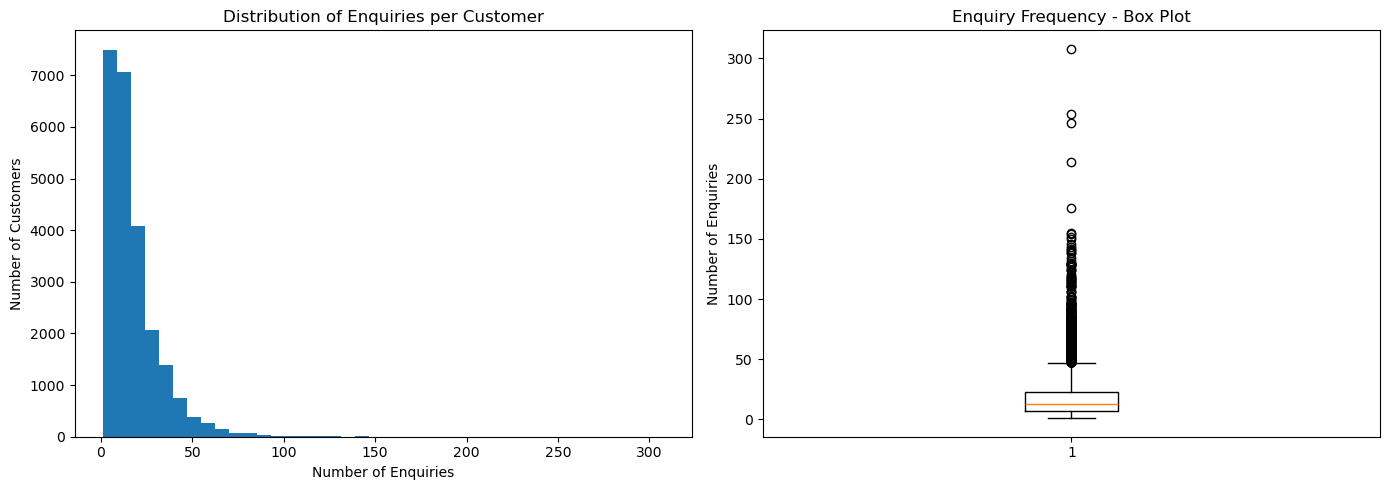

In [182]:
# Create histogram and box plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(enquiry_frequency, bins=40)
axes[0].set_title('Distribution of Enquiries per Customer')
axes[0].set_xlabel('Number of Enquiries')
axes[0].set_ylabel('Number of Customers')

# Box plot
axes[1].boxplot(enquiry_frequency)
axes[1].set_title('Enquiry Frequency - Box Plot')
axes[1].set_ylabel('Number of Enquiries')

plt.tight_layout()
plt.show()

In [183]:
# Check data type
print(enquiry_df['enq_amt'].dtype)

# Check missing values
print("Missing values:", enquiry_df['enq_amt'].isna().sum())

# Inspect sample values
display(enquiry_df['enq_amt'].head(10))

float64
Missing values: 110


0    3500000.0
1     500000.0
2      50000.0
3      50000.0
4       1000.0
5       1000.0
6       1000.0
7       1000.0
8       1000.0
9        150.0
Name: enq_amt, dtype: float64

In [184]:
# Descriptive statistics
print("Enquiry Amount Summary:")
display(enquiry_df['enq_amt'].describe())

# Count zero and negative values
print("\nZero values:", (enquiry_df['enq_amt'] == 0).sum())
print("Negative values:", (enquiry_df['enq_amt'] < 0).sum())

# Calculate selected percentiles
print("\nSelected Percentiles:")
display(
    enquiry_df['enq_amt'].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999]
    )
)

Enquiry Amount Summary:


count    4.130780e+05
mean     8.289094e+05
std      1.204328e+07
min      1.000000e+00
25%      1.000000e+04
50%      5.000000e+04
75%      1.430000e+05
max      1.000000e+09
Name: enq_amt, dtype: float64


Zero values: 0
Negative values: 0

Selected Percentiles:


0.500        50000.0
0.750       143000.0
0.900       500000.0
0.950      1000000.0
0.990      6500000.0
0.995     25000000.0
0.999    100000000.0
Name: enq_amt, dtype: float64

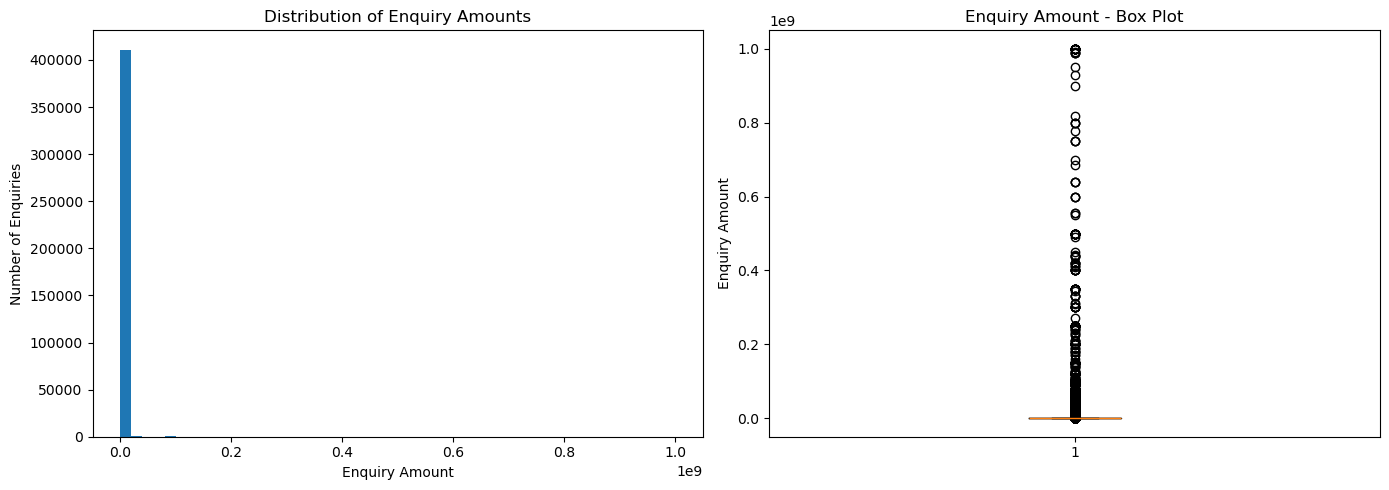

In [185]:
# Create histogram and box plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(enquiry_df['enq_amt'].dropna(), bins=50)
axes[0].set_title('Distribution of Enquiry Amounts')
axes[0].set_xlabel('Enquiry Amount')
axes[0].set_ylabel('Number of Enquiries')

# Box plot
axes[1].boxplot(enquiry_df['enq_amt'].dropna())
axes[1].set_title('Enquiry Amount - Box Plot')
axes[1].set_ylabel('Enquiry Amount')

plt.tight_layout()
plt.show()

In [186]:
# Display the 20 records with the highest enquiry amounts

top_enquiries = enquiry_df.nlargest(20, 'enq_amt')

display(top_enquiries)

,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
18398,28-May-15,1004,11-May-15,24-Apr-09,0.0,999999999.0
70321,18-Sep-15,3971,27-Aug-15,22-Apr-14,3.0,999999999.0
104691,23-Jul-15,6075,16-Jul-15,23-Aug-08,10.0,999999999.0
136371,07-Jul-15,7500,22-Jun-15,18-Sep-08,10.0,999999999.0
140537,17-Jul-15,7700,04-Jun-15,23-Aug-08,10.0,999999999.0
174575,17-Sep-15,9329,04-Sep-15,04-Mar-15,0.0,999999999.0
181572,28-Sep-15,9738,07-Sep-15,14-Jan-09,10.0,999999999.0
190760,06-Oct-15,10222,21-Sep-15,22-Dec-08,10.0,999999999.0
237335,21-Nov-15,12777,02-Nov-15,07-Oct-08,10.0,999999999.0
282075,06-Jul-15,15283,02-Jul-15,20-Feb-08,10.0,999999999.0


In [187]:
# Inspect the most frequent enquiry amounts
display(
    enquiry_df['enq_amt']
    .value_counts()
    .head(20)
)

enq_amt
50000.0      79949
10000.0      54584
1000.0       50162
100000.0     38876
15000.0      15442
300000.0     14253
200000.0     10324
500000.0     10010
1.0           8869
25000.0       7724
100.0         6095
40000.0       5496
150000.0      5194
400000.0      4748
250000.0      4270
1000000.0     3807
30000.0       3346
60000.0       3208
600000.0      2393
350000.0      2299
Name: count, dtype: int64

In [188]:
# Count records with the value 999999999
special_amount_count = (
    enquiry_df['enq_amt'] == 999999999
).sum()

print("Records with enquiry amount 999999999:", special_amount_count)

# Count unique customers associated with this amount
special_amount_customers = enquiry_df.loc[
    enquiry_df['enq_amt'] == 999999999,
    'customer_no'
].nunique()

print("Unique customers:", special_amount_customers)

Records with enquiry amount 999999999: 15
Unique customers: 15


### Enquiry Amount Analysis

The enquiry amount distribution was examined using descriptive statistics, selected percentiles, frequency counts, and visualizations.

**Key observations:**

* The dataset contains 413,078 non-missing enquiry amounts.
* The mean enquiry amount is approximately ₹828,909, whereas the median is ₹50,000. This indicates a strongly right-skewed distribution.
* The most frequent enquiry amounts are ₹50,000 (79,949 records), ₹10,000 (54,584 records), ₹1,000 (50,162 records), and ₹100,000 (38,876 records).
* The 99th percentile is ₹6.5 million, and the 99.9th percentile is ₹100 million.
* The maximum recorded amount is ₹1 billion.
* No zero or negative enquiry amounts were observed.
* The value `999999999` appears in 15 records belonging to 15 unique customers. Its business meaning cannot be established from the available information.

**Conclusion:**

Enquiry amounts are heavily concentrated around relatively smaller values, with a long right tail containing exceptionally large observations. These extreme values substantially influence the mean. The value `999999999` requires attention during future data-quality assessment, but no assumptions, replacements, or removals are made during EDA.


In [189]:
# Enquiry Purpose 
# Check data type
print("Data type:", enquiry_df['enq_purpose'].dtype)

# Check missing values
print("\nMissing values:")
print(enquiry_df['enq_purpose'].isna().sum())

# Check number of unique values
print("\nNumber of unique purpose codes:")
print(enquiry_df['enq_purpose'].nunique())

# Inspect distinct values
print("\nDistinct purpose codes:")
print(sorted(enquiry_df['enq_purpose'].dropna().unique()))

# Frequency distribution
print("\nPurpose code frequency:")
display(enquiry_df['enq_purpose'].value_counts(dropna=False).sort_index())

Data type: float64

Missing values:
110

Number of unique purpose codes:
36

Distinct purpose codes:
[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0), np.float64(7.0), np.float64(8.0), np.float64(9.0), np.float64(10.0), np.float64(11.0), np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(40.0), np.float64(41.0), np.float64(43.0), np.float64(51.0), np.float64(52.0), np.float64(53.0), np.float64(54.0), np.float64(55.0), np.float64(56.0), np.float64(57.0), np.float64(58.0), np.float64(59.0)]

Purpose code frequency:


enq_purpose
0.0      15048
1.0      23708
2.0      15576
3.0       1728
4.0        280
5.0      81881
6.0      17426
7.0       1351
8.0        563
9.0         51
10.0    238150
11.0        13
12.0      1000
13.0     11179
14.0        95
15.0        13
16.0         2
17.0       410
31.0         3
32.0       170
33.0        14
34.0         3
35.0        19
36.0         6
40.0        22
41.0         7
43.0         6
51.0      3942
52.0       130
53.0        72
54.0       154
55.0        12
56.0        13
57.0        10
58.0         6
59.0        15
NaN        110
Name: count, dtype: int64

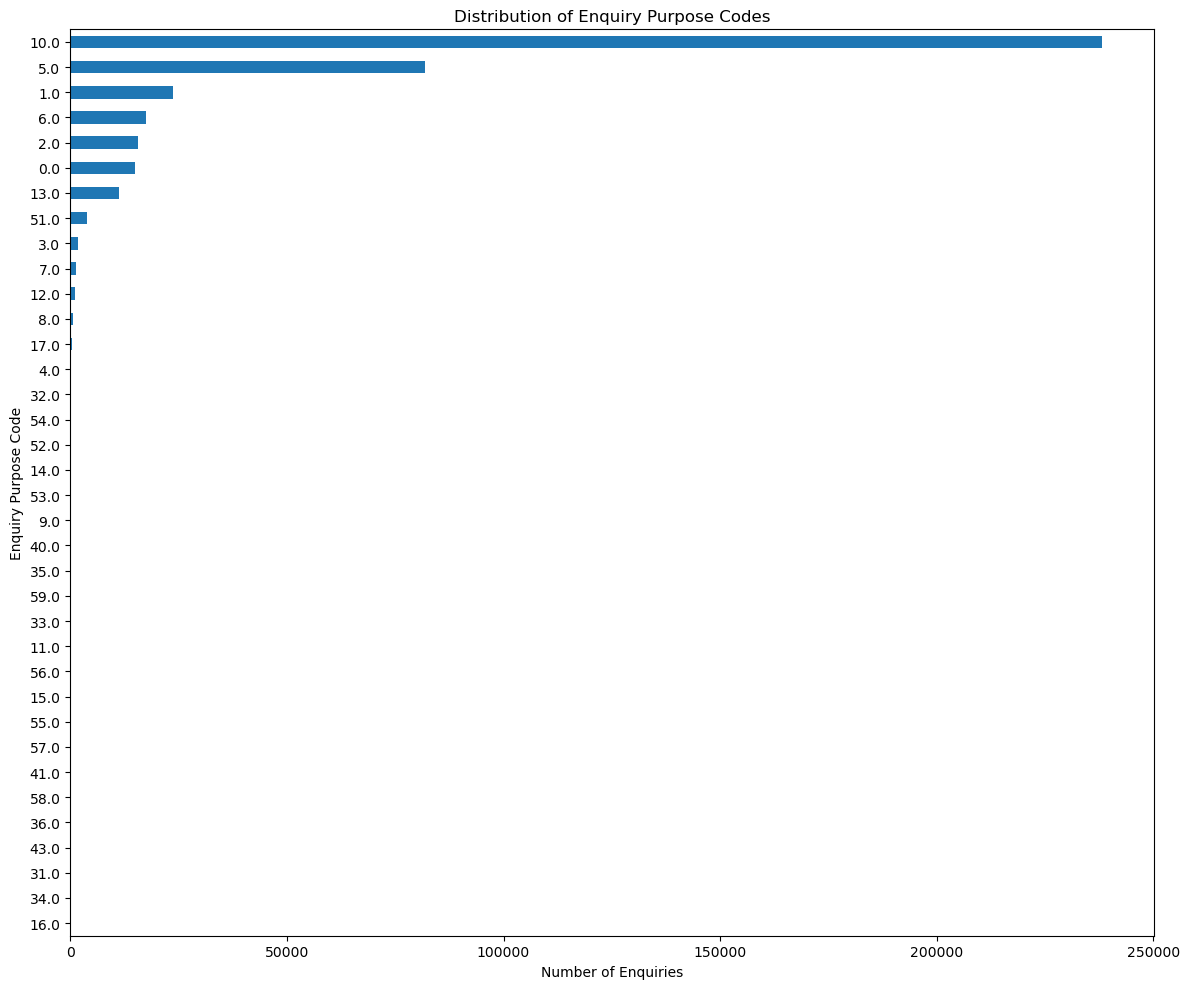

In [190]:
# Calculate frequency of each enquiry purpose
purpose_counts = enquiry_df['enq_purpose'].value_counts().sort_values()

# Create horizontal bar chart
plt.figure(figsize=(12, 10))

purpose_counts.plot(kind='barh')

plt.title('Distribution of Enquiry Purpose Codes')
plt.xlabel('Number of Enquiries')
plt.ylabel('Enquiry Purpose Code')

plt.tight_layout()
plt.show()

### Enquiry Purpose Analysis

The `enq_purpose` column was examined to understand the distribution and frequency of enquiry purpose codes.

**Key observations:**

* The column contains 36 distinct purpose codes and 110 missing values.
* Purpose code 10 is the most frequent, accounting for 238,150 records (approximately 57.65%).
* Purpose code 5 is the second most frequent, accounting for 81,881 records (approximately 19.82%).
* Together, codes 10 and 5 account for approximately 77.47% of all enquiry records.
* Codes 1, 6, 2, 0 and 13 are the next most frequent categories.
* Several purpose codes occur very rarely. For example, code 16 appears only twice.

**Conclusion:**

The enquiry purpose distribution is highly concentrated in a small number of codes. Code 10 dominates the dataset, followed by code 5. The remaining categories have substantially lower frequencies.

Since the business definitions of these codes are unavailable, no business meaning has been assigned to individual codes. No records were modified or removed.


In [191]:
# Convert date columns temporarily
dt_opened = pd.to_datetime(
    enquiry_df['dt_opened'],
    format='%d-%b-%y',
    errors='coerce'
)

enquiry_date = pd.to_datetime(
    enquiry_df['enquiry_dt'],
    format='%d-%b-%y',
    errors='coerce'
)

# Calculate enquiry recency
enquiry_recency = (
    dt_opened - enquiry_date
).dt.days.dropna()

# Display descriptive statistics
display(enquiry_recency.describe())

count    413078.000000
mean       1098.771578
std         946.149277
min           2.000000
25%         334.000000
50%         783.000000
75%        1665.000000
max        4054.000000
dtype: float64

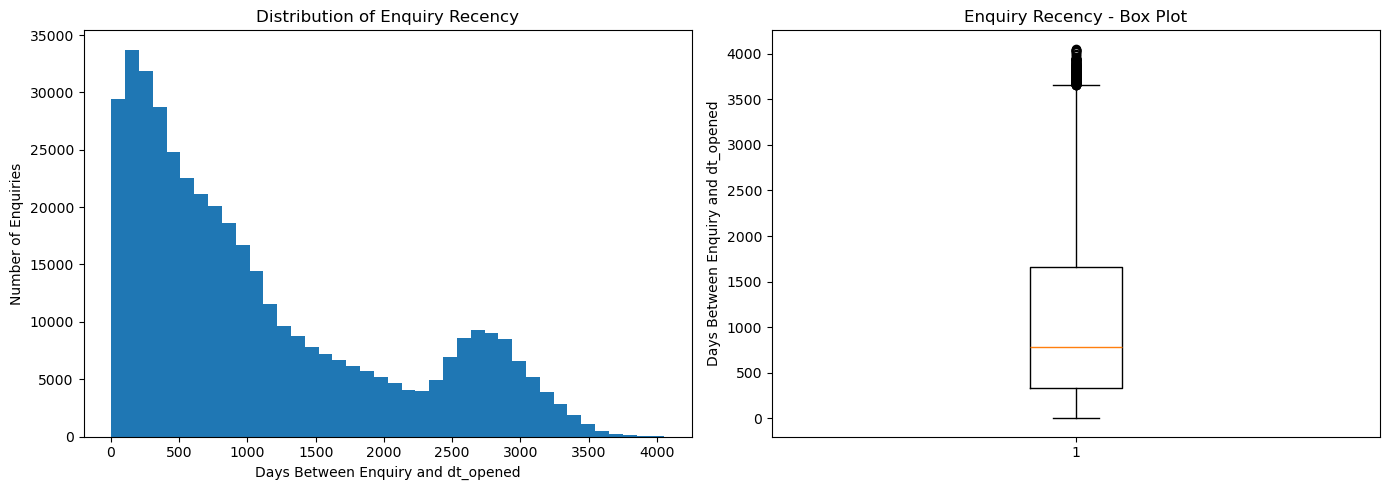

In [192]:
# Create histogram and box plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(enquiry_recency, bins=40)
axes[0].set_title('Distribution of Enquiry Recency')
axes[0].set_xlabel('Days Between Enquiry and dt_opened')
axes[0].set_ylabel('Number of Enquiries')

# Box plot
axes[1].boxplot(enquiry_recency)
axes[1].set_title('Enquiry Recency - Box Plot')
axes[1].set_ylabel('Days Between Enquiry and dt_opened')

plt.tight_layout()
plt.show()

### Enquiry Date and Recency Analysis

#### 1. Date Validation

The `enquiry_dt` and `dt_opened` columns were converted to datetime format.

**Findings:**

* Both columns were successfully converted to `datetime64[ns]`.
* `enquiry_dt` contains 110 missing values.
* `dt_opened` contains no missing values.
* All valid enquiry dates occur before the corresponding `dt_opened` dates.

#### 2. Enquiry Recency

A temporary variable, `enquiry_recency`, was calculated as:

`dt_opened - enquiry_dt`

This represents the number of days between an enquiry and the associated account opening date.

**Descriptive Statistics:**

| Metric             |     Days |
| ------------------ | -------: |
| Count              |  413,078 |
| Mean               | 1,098.77 |
| Standard deviation |   946.15 |
| Minimum            |        2 |
| 25th percentile    |      334 |
| Median             |      783 |
| 75th percentile    |    1,665 |
| Maximum            |    4,054 |

#### 3. Distribution Analysis

* The histogram shows a higher concentration of shorter enquiry-to-account-opening intervals.
* Frequencies generally decline as the interval increases.
* A secondary concentration appears around 2,500–3,000 days.
* The box plot indicates a right-skewed distribution with several higher-end outliers.

#### 4. Key Observations

* All 413,078 valid records have positive intervals.
* The median interval is 783 days.
* The mean interval is approximately 1,099 days.
* The maximum interval is 4,054 days.
* 110 records with missing enquiry dates were excluded.
* The distribution is right-skewed.

#### 5. Interpretation and Decisions

The enquiry records generally precede the associated account-opening date by a considerable period.

The interval may provide useful information about the timing of customer enquiries relative to account opening. However, its business interpretation and predictive usefulness have not yet been established.

The calculation was performed separately without modifying the original dataset. No records were removed or altered.

**Important:** This variable should be evaluated further during feature engineering, including checks for temporal validity and potential data leakage.


In [193]:
# Variation Across Customers
# Aggregate enquiry behaviour at customer level

customer_enquiry = (
    enquiry_df
    .groupby('customer_no')
    .agg(
        total_enquiries=('customer_no', 'count'),
        total_enquiry_amount=('enq_amt', 'sum')
    )
)

# Summary statistics
display(customer_enquiry.describe())

,total_enquiries,total_enquiry_amount
count,23896.000000,2.389600e+04
mean,17.291095,1.432894e+07
std,15.248175,1.118235e+08
min,1.000000,0.000000e+00
25%,7.000000,3.712492e+05
50%,13.000000,1.281205e+06
75%,23.000000,4.013355e+06
max,308.000000,7.119712e+09


In [194]:
# Identify customers with zero total enquiry amount

zero_amount_customers = customer_enquiry[
    customer_enquiry['total_enquiry_amount'] == 0
]

print("Customers with zero aggregate enquiry amount:",
      len(zero_amount_customers))

# Check whether their enquiry amounts are entirely missing

missing_amount_per_customer = (
    enquiry_df.groupby('customer_no')['enq_amt']
    .apply(lambda x: x.isna().all())
)

print(
    "Customers with all enquiry amounts missing:",
    missing_amount_per_customer.sum()
)

Customers with zero aggregate enquiry amount: 109
Customers with all enquiry amounts missing: 109


In [195]:
# Recalculate customer-level enquiry amounts
# Keep the aggregate as NaN when all individual amounts are missing

customer_enquiry_amount = (
    enquiry_df.groupby('customer_no')['enq_amt']
    .sum(min_count=1)
)

# Replace the amount column in the derived customer-level DataFrame
customer_enquiry['total_enquiry_amount'] = customer_enquiry_amount

# Inspect the updated summary
display(customer_enquiry['total_enquiry_amount'].describe())

print(
    "Customers with missing aggregate amounts:",
    customer_enquiry['total_enquiry_amount'].isna().sum()
)

count    2.378700e+04
mean     1.439460e+07
std      1.120752e+08
min      1.000000e+00
25%      3.780000e+05
50%      1.295032e+06
75%      4.040950e+06
max      7.119712e+09
Name: total_enquiry_amount, dtype: float64

Customers with missing aggregate amounts: 109


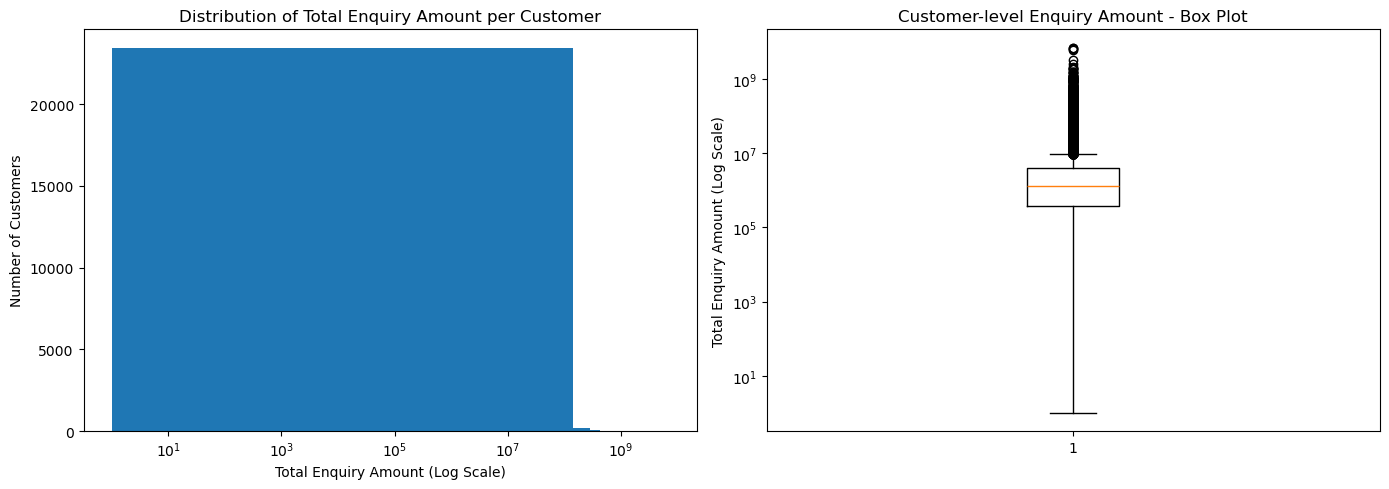

In [196]:
# Visualise customer-level enquiry amount variation

valid_amounts = customer_enquiry['total_enquiry_amount'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram with logarithmic x-axis
axes[0].hist(valid_amounts, bins=50)
axes[0].set_xscale('log')
axes[0].set_title('Distribution of Total Enquiry Amount per Customer')
axes[0].set_xlabel('Total Enquiry Amount (Log Scale)')
axes[0].set_ylabel('Number of Customers')

# Box plot with logarithmic y-axis
axes[1].boxplot(valid_amounts)
axes[1].set_yscale('log')
axes[1].set_title('Customer-level Enquiry Amount - Box Plot')
axes[1].set_ylabel('Total Enquiry Amount (Log Scale)')

plt.tight_layout()
plt.show()

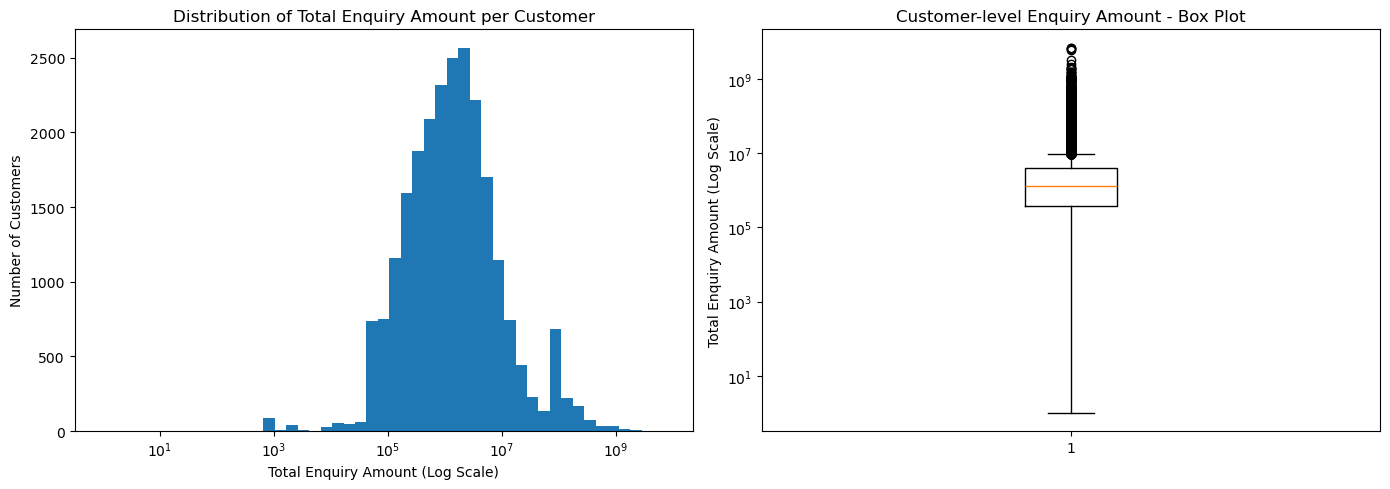

In [197]:
# Keep only positive aggregate amounts for logarithmic plotting
valid_amounts = customer_enquiry.loc[
    customer_enquiry['total_enquiry_amount'] > 0,
    'total_enquiry_amount'
]

# Create logarithmically spaced bins
log_bins = np.logspace(
    np.log10(valid_amounts.min()),
    np.log10(valid_amounts.max()),
    50
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(valid_amounts, bins=log_bins)
axes[0].set_xscale('log')
axes[0].set_title('Distribution of Total Enquiry Amount per Customer')
axes[0].set_xlabel('Total Enquiry Amount (Log Scale)')
axes[0].set_ylabel('Number of Customers')

# Box plot
axes[1].boxplot(valid_amounts)
axes[1].set_yscale('log')
axes[1].set_title('Customer-level Enquiry Amount - Box Plot')
axes[1].set_ylabel('Total Enquiry Amount (Log Scale)')

plt.tight_layout()
plt.show()

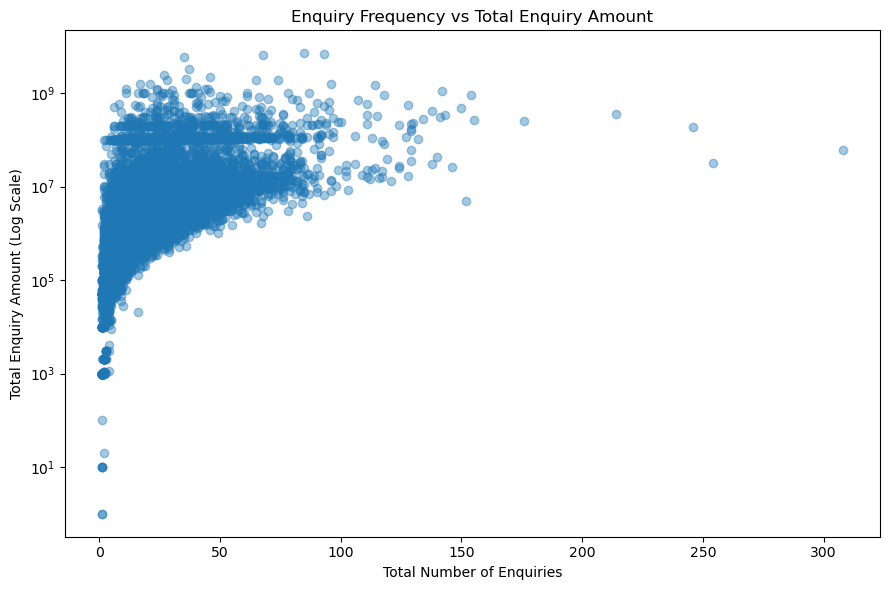

In [198]:
# Compare enquiry frequency with total enquiry amount

customer_enquiry_valid = customer_enquiry[
    customer_enquiry['total_enquiry_amount'] > 0
]

plt.figure(figsize=(9, 6))

plt.scatter(
    customer_enquiry_valid['total_enquiries'],
    customer_enquiry_valid['total_enquiry_amount'],
    alpha=0.4
)

plt.yscale('log')
plt.xlabel('Total Number of Enquiries')
plt.ylabel('Total Enquiry Amount (Log Scale)')
plt.title('Enquiry Frequency vs Total Enquiry Amount')

plt.tight_layout()
plt.show()

In [199]:
from scipy.stats import spearmanr

# Calculate Spearman correlation
correlation, p_value = spearmanr(
    customer_enquiry_valid['total_enquiries'],
    customer_enquiry_valid['total_enquiry_amount']
)

print(f"Spearman Correlation: {correlation:.4f}")
print(f"P-value: {p_value:.6f}")

Spearman Correlation: 0.7740
P-value: 0.000000


### Relationship Between Enquiry Frequency and Total Enquiry Amount

To understand how enquiry frequency relates to the total enquiry amount at customer level, a scatter plot and Spearman rank correlation were used.

**Scatter plot observations:**

* A positive relationship is visible between enquiry frequency and aggregate enquiry amount.
* Customers with higher enquiry counts generally tend to have higher total enquiry amounts.
* Considerable variation exists among customers with similar enquiry frequencies.
* The distribution becomes more dispersed at higher enquiry frequencies.

**Spearman correlation results:**

* Spearman correlation coefficient: 0.7740
* P-value: < 0.000001 (rounded output displayed as 0.000000)

The correlation indicates a strong positive monotonic relationship between the two variables. The statistically significant result provides evidence that this association is unlikely to be due to random sampling variation under the test assumptions.

**EDA conclusion:**

Enquiry frequency and total enquiry amount capture complementary aspects of customer enquiry behaviour. Although they are strongly associated, they are not interchangeable because customers with similar enquiry counts can have substantially different aggregate enquiry amounts.

No records were modified or removed during this analysis.


### Customer-Level Variation in Enquiry Behaviour

Enquiry records were aggregated by customer to examine differences in enquiry activity and total enquiry amounts.

**Enquiry frequency:**

* The dataset contains 23,896 customers.
* The average number of enquiries per customer is approximately 17.29.
* The median is 13 enquiries.
* The minimum is 1 and the maximum is 308.

**Total enquiry amount:**

* Aggregate enquiry amounts were available for 23,787 customers.
* For 109 customers, all enquiry amounts were missing.
* Among customers with available amounts, the mean total enquiry amount was approximately 14.39 million.
* The median was approximately 1.30 million.
* The distribution was strongly right-skewed, with a small number of customers having very high aggregate amounts.

**Relationship between enquiry frequency and total amount:**

The Spearman rank correlation was 0.774, with a p-value below 0.000001.

This indicates a strong positive association: customers with more enquiries generally tend to have higher total enquiry amounts.

**Conclusion:**

Enquiry behaviour varies considerably across customers. Both enquiry frequency and total enquiry amount show substantial variation, and the two measures have a strong positive association.

These findings are descriptive. The analysis does not establish causation or predictive usefulness. No records were removed, and the original enquiry dataset was not modified.


### Identification of Potentially Informative Variables

#### 1. Objective

The objective of this stage is to identify candidate variables that may provide useful information for predicting customer credit risk.

Based on the completed EDA, variables are classified into three groups:

1. Potentially informative based on EDA.
2. Requiring further investigation.
3. Potentially redundant, unreliable, or affected by data leakage.

These classifications are preliminary. No final feature-selection decisions are made during this stage.

#### 2. Potentially Informative Variables

##### Demographic Dataset

The following features showed descriptive differences between good-credit and bad-credit customers:

* `feature_7`
* `feature_52`
* `feature_4`
* `feature_14`
* `feature_25`
* `feature_40`
* `feature_41`
* `feature_56`
* `feature_64`
* `feature_71`

Among the continuous-like features, `feature_7` and `feature_52` showed the clearest differences between the target groups.

Some categorical and discrete/coded features also showed category-level differences in bad-credit rates.

##### Account Dataset

The following variables are retained as candidate variables for further assessment:

* `acct_type`
* `cur_balance_amt`
* `high_credit_amt`
* `creditlimit`
* `cashlimit`
* `owner_indic`

These variables showed meaningful variation during descriptive analysis. Their customer-level predictive usefulness has not yet been established.

##### Enquiry Dataset

The following variables are retained as candidates:

* `enq_amt`
* `enq_purpose`
* Customer-level enquiry frequency
* Customer-level total enquiry amount
* Enquiry recency

The customer-level enquiry analysis showed substantial variation in enquiry activity and amounts.

Enquiry frequency and total enquiry amount also showed a strong positive Spearman correlation of 0.7740.

#### 3. Variables Requiring Further Investigation

##### Account Dataset

* `amt_past_due`: 99.53% missing.
* `rateofinterest`: 86.67% missing.
* `actualpaymentamount`: 77.97% missing.
* `paymentfrequency`: 65.71% missing.
* `closed_dt`: 58.54% missing.
* `paymenthistory1` and `paymenthistory2`: Structured codes whose business meanings and chronological order remain unknown.

##### Enquiry Dataset

* `enq_amt`: The value 999999999 occurs in 15 records. Its meaning is unknown.
* `enq_purpose`: Contains 36 distinct codes without available business definitions.
* `enquiry_dt`: Its temporal relationship with the prediction date requires further investigation.

##### Demographic Dataset

* `feature_49`: 99.56% missing.
* `feature_74`: 99.93% missing.
* `feature_17`, `feature_18`, `feature_10`, and `feature_61`: Very high missingness.
* `feature_47`, `feature_20`, and `feature_21`: High cardinality.
* `feature_30` and `feature_39`: Year-like values with unknown meanings.

These variables require further investigation before decisions about their suitability can be made.

#### 4. Potentially Redundant, Unreliable, or Leakage-Affected Variables

| Variable                                         | Concern                                                                               |
| ------------------------------------------------ | ------------------------------------------------------------------------------------- |
| `customer_no`                                    | Customer identifier; not automatically a predictive feature.                          |
| `Bad_label`                                      | Target variable; must not be included as an input feature.                            |
| `feature_6`                                      | Constant feature.                                                                     |
| `feature_5`                                      | Constant categorical feature.                                                         |
| `feature_54`                                     | Constant date feature.                                                                |
| `feature_35` and `feature_69`                    | Exact duplicate features.                                                             |
| `feature_34` and `feature_68`                    | Matching category distributions; exact redundancy requires verification.              |
| `amt_past_due`                                   | Potential target leakage because the target definition involves a 30+ DPD bucket.     |
| `paymenthistory1` and `paymenthistory2`          | Potential temporal leakage depending on the prediction cutoff and history chronology. |
| `closed_dt`, `last_paymt_dt`, and `reporting_dt` | Potential post-outcome or post-prediction information.                                |
| `upload_dt` and `dt_opened`                      | Business meaning and temporal eligibility require verification.                       |

#### 5. Important Considerations

The target variable, `Bad_label`, is imbalanced:

* Good-credit customers (`0`): 22,892 (95.80%).
* Bad-credit customers (`1`): 1,004 (4.20%).

Therefore, descriptive differences should not be treated as proof of predictive usefulness.

Account and enquiry datasets contain multiple records per customer, whereas the demographic dataset contains one record per customer. Any future use of account-level and enquiry-level information will require an appropriate customer-level aggregation strategy.

The prediction cutoff must also be established before using date-sensitive or historical repayment variables. Variables containing information from after the prediction date could introduce data leakage.

#### 6. Stage 4 Conclusion

The completed EDA identified several potentially informative demographic, account, and enquiry variables.

Other variables require additional investigation because of high missingness, unusual values, high cardinality, unknown business meanings, or potential temporal leakage.

Some features have also been identified as constant or potentially redundant.

These classifications are preliminary. No variables have been selected or removed, and no data transformations have been performed.

Final feature selection will be addressed during the planned feature-engineering, feature-selection, and modelling stages.


### EDA Summary and Key Findings

#### 1. Dataset Overview

The project uses three datasets:

- Customer Accounts (`account_df`): 186,329 records.
- Customer Enquiries (`enquiry_df`): 413,188 records.
- Customer Demographics (`demographic_df`): 23,896 records and 83 columns.

The demographic dataset contains the target variable `Bad_label`, while the account and enquiry datasets contain multiple records per customer.

#### 2. Target Variable Distribution

- Good credit customers (`Bad_label = 0`): 22,892 (95.80%).
- Bad credit customers (`Bad_label = 1`): 1,004 (4.20%).

**Key finding:** The target variable is highly imbalanced. Accuracy alone may not be a reliable evaluation metric during modelling.

**Decision:** Consider evaluation metrics such as Gini, recall, precision and other suitable classification metrics during the modelling phase.

#### 3. Data Quality Findings

##### 3.1 Missing Values

- Customer Accounts contains approximately 29% missing values overall.
- `amt_past_due` has approximately 99.53% missing values.
- `creditlimit` has approximately 73.78% missing values.
- `cashlimit` has approximately 81.06% missing values.
- Customer Enquiries has very few missing values overall.
- `enq_purpose` contains 110 missing records.
- Customer Demographics has approximately 16.38% missing values.

**Decision:** Missing values require further investigation during preprocessing. Missing values should not automatically be treated as zero.

##### 3.2 Duplicate Records

- Customer Accounts contains 2,401 exact duplicate rows.
- Customer Enquiries contains 13,827 exact duplicate rows.
- Customer Demographics contains no duplicate rows.

**Decision:** Duplicate records should be investigated before deciding whether removal is appropriate. No records were removed during EDA.

##### 3.3 Data Types and Inconsistent Values

- Several date columns were originally stored as strings.
- Payment history columns contain numeric and alphabetic three-character codes.
- Some numerical columns contain unusually large values.
- Negative current balances were observed.

**Decision:** Data types, unusual values and coded variables require further investigation during preprocessing. Business meanings should not be assumed without supporting documentation.

#### 4. Account Behaviour Findings

##### 4.1 Account Type Distribution

- Account type 10 represents approximately 53.80% of account records.
- Account type 6 represents approximately 13.77%.
- Account type 5 represents approximately 12.30%.
- Some account types have very few records.

**Key finding:** Account records are concentrated in a small number of account types.

**Decision:** Account type may be a potentially informative categorical variable. Rare categories require further investigation.

##### 4.2 Account Balances

- Current balances contain a large number of zero values.
- Negative current balances were also observed.
- Current balance, high credit and past-due amounts are strongly right-skewed.
- `amt_past_due` has approximately 99.53% missing values.

**Key finding:** Account balance variables have substantially different distributions and contain extreme values.

**Decision:** Investigate extreme values and missingness during preprocessing and feature engineering.

##### 4.3 Credit Limits

- `creditlimit` has approximately 73.78% missing values.
- `cashlimit` has approximately 81.06% missing values.
- Both variables are right-skewed and contain extreme values.

**Decision:** These variables may contain useful information, but their high missingness requires careful evaluation.

##### 4.4 Payment History

- `paymenthistory1` and `paymenthistory2` contain three-character segments.
- The most frequent codes include `000`, `XXX` and `STD`.
- Numeric and alphabetic codes are present.
- The business meaning of these codes is unavailable.

**Decision:** Retain these variables as candidates for further investigation. Their interpretation and possible feature-engineering approach must be established before modelling.

#### 5. Enquiry Behaviour Findings

##### 5.1 Enquiry Frequency

- Average enquiries per customer: approximately 17.29.
- Median enquiries per customer: 13.
- Maximum enquiries for a customer: 308.

**Key finding:** Enquiry frequency varies considerably across customers.

##### 5.2 Enquiry Amounts

- Enquiry amounts are highly right-skewed.
- Common enquiry amounts include 50,000, 10,000, 1,000 and 100,000.
- Fifteen records have an enquiry amount of 999,999,999, belonging to fifteen unique customers.

**Decision:** The unusually large enquiry amount should be investigated further before deciding how to handle it.

##### 5.3 Enquiry Purpose

- There are 36 distinct enquiry purpose codes.
- Purpose code 10 is the most frequent, followed by codes 5, 1, 6 and 2.
- Several purpose codes occur very rarely.
- The business meaning of the codes is unavailable.

**Decision:** Enquiry purpose may be informative, but rare categories and unknown code meanings require further investigation.

##### 5.4 Enquiry Recency

- Enquiry dates generally precede the associated `dt_opened` date.
- Mean interval: approximately 1,099 days.
- Median interval: 783 days.
- Minimum interval: 2 days.
- Maximum interval: 4,054 days.
- There are 110 records with missing enquiry dates.

**Key finding:** Enquiry records generally precede the associated account-opening date by a considerable period.

**Decision:** The date relationship requires further temporal validation before feature engineering. The business meaning of the interval has not been established.

##### 5.5 Variation Across Customers

- Average total enquiry amount per customer: approximately 14.39 million.
- Median total enquiry amount per customer: approximately 1.30 million.
- Maximum total enquiry amount: approximately 7.12 billion.
- 109 customers have all enquiry amounts missing.

The Spearman correlation between enquiry frequency and total enquiry amount is approximately 0.774.

**Key finding:** Customers with more enquiries generally tend to have higher total enquiry amounts.

**Decision:** Enquiry frequency and total enquiry amount are potential candidate variables. Their relationship and usefulness should be evaluated during feature engineering and modelling.

#### 6. Demographic and Application Behaviour

- The target variable is highly imbalanced.
- Several demographic features show differences between good-credit and bad-credit groups.
- `feature_7` and `feature_52` show lower values in the bad-credit group.
- Most other continuous-like features show broadly similar distributions.
- Some categorical groups show differences in bad-credit rates, but certain groups have small sample sizes.

**Decision:** Features showing descriptive differences should be retained as candidates for further investigation. No final feature-selection decisions were made during EDA.

#### 7. Relationship Between Datasets

- `customer_no` is available in all three datasets.
- All unique customers in the account and enquiry datasets are present in the demographic dataset.
- Account and enquiry datasets contain multiple records per customer.
- The demographic dataset contains one record per customer.

**Key finding:** Account and enquiry data have a one-to-many relationship with customer-level demographic data.

**Decision:** Raw account and enquiry records should not be directly joined to the demographic dataset without an appropriate aggregation strategy. Temporal validity and potential data leakage must also be considered.

#### 8. Overall EDA Decisions

Based on the EDA findings:

1. Investigate missing values before preprocessing.
2. Investigate duplicate records before deciding whether to remove them.
3. Examine extreme values and unusual numerical observations.
4. Investigate coded categorical variables without assuming their business meanings.
5. Evaluate account-level and enquiry-level variables through appropriate customer-level feature engineering.
6. Validate temporal relationships to avoid potential data leakage.
7. Consider the target imbalance when selecting evaluation metrics.
8. Retain potentially informative variables for further evaluation during feature engineering and feature selection.

#### 9. Conclusion

The EDA identified several potentially informative variables across account, enquiry and demographic datasets. It also revealed important data quality concerns, including missing values, duplicate records, extreme values, coded variables and temporal relationships.

These findings provide direction for the next stages of the project. No final feature-selection decisions or data-cleaning operations were performed during EDA. Candidate variables will be evaluated further during preprocessing, feature engineering, feature selection and modelling.

### Data Processing and Preprocessing

###  Define the Modeling Dataset

#### Objective

Define the observation level and source datasets for the credit-risk classification problem.

#### Dataset Overview

The project contains three datasets:

| Dataset | Rows | Columns | Granularity |
|---|---:|---:|---|
| `demographic_df` | 23,896 | 83 | One row per customer |
| `account_df` | 186,329 | 21 | Multiple records per customer |
| `enquiry_df` | 413,188 | 6 | Multiple records per customer |

#### Modeling Unit

The modeling unit will be an individual customer. Therefore, the final modeling dataset must contain one row per customer.

#### Base Dataset

`demographic_df` will serve as the base dataset because it contains one record per customer and includes the target variable `Bad_label`.

#### Supporting Datasets

- `account_df` contains historical account-level information.
- `enquiry_df` contains historical enquiry-level information.

These datasets may provide additional customer-level predictors. However, their records cannot be directly joined to the demographic dataset because multiple records can exist for the same customer.

Their information will be evaluated for appropriate customer-level aggregation during the feature-engineering phase.

#### Decision

The modeling problem is defined as a customer-level binary classification problem.

- Observation: One customer.
- Target: `Bad_label`.
- Base dataset: `demographic_df`.
- Supporting datasets: `account_df` and `enquiry_df`.

No data transformations, aggregations, joins, or row removals were performed during this task.

Potential target leakage and temporal validity will be investigated before finalizing the predictor set.

In [200]:
# Separate target variable and predictor variables

target_column = 'Bad_label'

# Check whether the target column exists
assert target_column in demographic_df.columns, "Target column not found!"

# Separate predictors (X) and target (y)
X = demographic_df.drop(columns=[target_column])
y = demographic_df[target_column]

# Display dataset dimensions
print("Predictor dataset shape:", X.shape)
print("Target variable shape:", y.shape)

# Check target distribution
print("\nTarget distribution:")
display(y.value_counts())

# Check target proportions
print("\nTarget distribution (%):")
display(y.value_counts(normalize=True) * 100)

# Verify separation
print("\nTarget column present in X:", target_column in X.columns)
print("Missing values in target:", y.isnull().sum())
print("Number of unique customers:", demographic_df['customer_no'].nunique())

Predictor dataset shape: (23896, 82)
Target variable shape: (23896,)

Target distribution:


Bad_label
0    22892
1     1004
Name: count, dtype: int64


Target distribution (%):


Bad_label
0    95.79846
1     4.20154
Name: proportion, dtype: float64


Target column present in X: False
Missing values in target: 0
Number of unique customers: 23896


In [201]:
# Calculate missing-value statistics for predictor variables

missing_summary = pd.DataFrame({
    'Missing_Count': X.isnull().sum(),
    'Missing_Percentage': (X.isnull().mean() * 100)
})

# Keep only columns containing missing values
missing_summary = missing_summary[
    missing_summary['Missing_Count'] > 0
]

# Sort by missing percentage
missing_summary = missing_summary.sort_values(
    by='Missing_Percentage',
    ascending=False
)

print("Number of columns containing missing values:",
      missing_summary.shape[0])

print(missing_summary.to_string())

Number of columns containing missing values: 76
            Missing_Count  Missing_Percentage
feature_61          23887           99.962337
feature_74          23879           99.928858
feature_18          23878           99.924674
feature_10          23845           99.786575
feature_49          23792           99.564781
feature_17          22869           95.702210
feature_9           22635           94.722966
feature_8           22635           94.722966
feature_57          21503           89.985772
feature_73          20951           87.675762
feature_48          18399           76.996150
feature_45          13713           57.386173
feature_13          13004           54.419150
feature_53          11610           48.585537
feature_51          11422           47.798795
feature_14           7733           32.361065
feature_36           5682           23.778038
feature_37           5682           23.778038
feature_38           5682           23.778038
feature_27           3637       

In [202]:
# Analyse missing-value percentages separately for each target class

missing_by_target = X.groupby(y).apply(
    lambda group: group.isnull().mean() * 100
).T

missing_by_target.columns = [
    'Good_Credit_Missing_Percentage',
    'Bad_Credit_Missing_Percentage'
]

missing_by_target['Difference'] = (
    missing_by_target['Bad_Credit_Missing_Percentage']
    - missing_by_target['Good_Credit_Missing_Percentage']
)

missing_by_target = missing_by_target.sort_values(
    by='Difference',
    key=abs,
    ascending=False
)

display(missing_by_target)

,Good_Credit_Missing_Percentage,Bad_Credit_Missing_Percentage,Difference
feature_53,47.942513,63.247012,15.304499
feature_51,47.164948,62.250996,15.086048
feature_14,31.993710,40.737052,8.743342
feature_13,54.145553,60.657371,6.511817
feature_36,23.628342,27.191235,3.562893
...,...,...,...
customer_no,0.000000,0.000000,0.000000
feature_47,0.000000,0.000000,0.000000
feature_20,0.000000,0.000000,0.000000
feature_22,0.000000,0.000000,0.000000


In [203]:
# Count missing values in each customer record

missing_per_customer = X.isnull().sum(axis=1)

# Distribution of missing values across customers
print("Distribution of missing values per customer:")

display(
    missing_per_customer.value_counts().sort_index()
)

# Identify customers with missing values in many features
print("\nCustomers with the highest number of missing features:")

display(
    missing_per_customer.sort_values(ascending=False).head(20)
)

Distribution of missing values per customer:


7        1
8        5
9      248
10     515
11    2462
12    3927
13    3476
14    4377
15    3370
16    2110
17    1888
18     708
19     651
20     123
21      17
22       2
23       1
76      15
Name: count, dtype: int64


Customers with the highest number of missing features:


8687     76
12048    76
17978    76
14693    76
22320    76
12250    76
12581    76
12590    76
8807     76
1566     76
7250     76
18752    76
2231     76
18313    76
13333    76
11101    23
12567    22
8810     22
10083    21
12178    21
dtype: int64

In [204]:
# Identify customers with 76 missing predictor values

fully_missing_customers = missing_per_customer[
    missing_per_customer == 76
].index

# Check their target distribution
print("Target distribution of these customers:")

display(y.loc[fully_missing_customers].value_counts())

print("\nTarget percentages:")

display(
    y.loc[fully_missing_customers]
    .value_counts(normalize=True) * 100
)

# Inspect their available predictor values
display(X.loc[fully_missing_customers].dropna(axis=1, how='all'))

Target distribution of these customers:


Bad_label
0    14
1     1
Name: count, dtype: int64


Target percentages:


Bad_label
0    93.333333
1     6.666667
Name: proportion, dtype: float64

,dt_opened,customer_no,feature_20,feature_22,feature_47,feature_77
1566,10-Jun-15,1567,XXXXX,XXXXX,XXXXX,XXXXX
2231,27-Jun-15,2232,XXXXX,XXXXX,XXXXX,XXXXX
7250,27-Jun-15,7251,XXXXX,XXXXX,XXXXX,XXXXX
8687,02-Sep-15,8688,XXXXX,XXXXX,XXXXX,XXXXX
8807,03-Sep-15,8808,XXXXX,XXXXX,XXXXX,XXXXX
12048,06-Nov-15,12049,XXXXX,XXXXX,XXXXX,XXXXX
12250,10-Nov-15,12251,XXXXX,XXXXX,XXXXX,XXXXX
12581,17-Nov-15,12582,XXXXX,XXXXX,XXXXX,XXXXX
12590,18-Nov-15,12591,XXXXX,XXXXX,XXXXX,XXXXX
13333,03-Dec-15,13334,XXXXX,XXXXX,XXXXX,XXXXX


In [205]:
# Investigate the four available features

available_features = [
    'feature_20',
    'feature_22',
    'feature_47',
    'feature_77'
]

for col in available_features:
    print(f"\nColumn: {col}")
    print("Data type:", X[col].dtype)
    print("Unique values:", X[col].nunique())
    display(X[col].value_counts(dropna=False).head(10))


Column: feature_20
Data type: object
Unique values: 10610


feature_20
AXMPKXXXXX    16
XXXXX         15
ATFPKXXXXX    15
AWMPKXXXXX    14
ARPPKXXXXX    13
BZXPSXXXXX    13
AUXPKXXXXX    13
AXLPKXXXXX    13
ATKPKXXXXX    13
BXCPSXXXXX    12
Name: count, dtype: int64


Column: feature_22
Data type: object
Unique values: 3251


feature_22
99999XXXXX    194
99990XXXXX    138
98100XXXXX    117
99994XXXXX    112
98110XXXXX    110
98116XXXXX    109
99100XXXXX    109
98111XXXXX    106
99997XXXXX    106
99996XXXXX    101
Name: count, dtype: int64


Column: feature_47
Data type: object
Unique values: 11250


feature_47
XXXXX         94
ATFPKXXXXX    15
AXMPKXXXXX    15
DL-03XXXXX    14
ARPPKXXXXX    13
ATKPKXXXXX    13
AWMPKXXXXX    13
BZXPSXXXXX    13
BXCPSXXXXX    12
AUXPKXXXXX    12
Name: count, dtype: int64


Column: feature_77
Data type: object
Unique values: 3124


feature_77
XXXXX         2149
99999XXXXX     176
99990XXXXX     132
98100XXXXX     109
99994XXXXX     107
98110XXXXX     100
98116XXXXX      99
98111XXXXX      97
99993XXXXX      96
99100XXXXX      95
Name: count, dtype: int64

### Missing-Value Analysis and Treatment Strategy

#### 1. Missing-Value Overview

- 76 out of 82 predictor columns contain missing values.
- Several features have extremely high missingness, with some exceeding 99%.
- Most features have relatively low missingness, with 15 missing values (approximately 0.063%).

#### 2. Missingness Across Target Classes

Missing-value percentages were compared between good-credit customers
(Bad_label = 0) and bad-credit customers (Bad_label = 1).

Key observations:

- feature_53 showed a 15.30 percentage-point difference.
- feature_51 showed a 15.09 percentage-point difference.
- feature_14 showed an 8.74 percentage-point difference.
- feature_13 showed a 6.51 percentage-point difference.

These observations suggest that missingness in some features may contain
predictive information. However, the differences are descriptive and do
not establish statistical significance.

#### 3. Investigation of Highly Incomplete Records

Fifteen customers were found to have 76 missing predictor values each.

Their target distribution was:

- Good-credit customers: 14 (93.33%)
- Bad-credit customers: 1 (6.67%)

These customers have only four non-missing predictor features:
feature_20, feature_22, feature_47, and feature_77.

The literal value 'XXXXX' was observed in these features. It is an
existing string value, not a Pandas NaN value. Its business meaning
has not been established.

#### 4. Missing-Value Treatment Strategy

- Retain the 15 highly incomplete customer records for now.
- Treat features with extremely high missingness as candidates for
  exclusion, subject to further evaluation.
- Retain other features initially and evaluate their usefulness.
- Determine numerical and categorical imputation strategies in their
  respective preprocessing tasks.
- Implement imputation using Scikit-learn Pipeline and
  ColumnTransformer.
- Fit preprocessing transformations using training data only.

No rows or columns were removed, and no missing values were imputed
during this investigation.

#### Conclusion

Missing-value patterns have been investigated and a provisional
treatment strategy has been established. Final implementation will
take place during preprocessing.

In [206]:
# Determine Categorical-Variable Treatment
# Identify columns with object, category, and boolean data types

categorical_columns = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Number of categorical columns:", len(categorical_columns))

print("\nCategorical columns:")
print(categorical_columns)

Number of categorical columns: 49

Categorical columns:
['dt_opened', 'entry_time', 'feature_1', 'feature_2', 'feature_5', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_27', 'feature_28', 'feature_32', 'feature_33', 'feature_36', 'feature_37', 'feature_38', 'feature_43', 'feature_45', 'feature_46', 'feature_47', 'feature_48', 'feature_50', 'feature_51', 'feature_53', 'feature_54', 'feature_57', 'feature_58', 'feature_59', 'feature_60', 'feature_61', 'feature_62', 'feature_63', 'feature_70', 'feature_72', 'feature_73', 'feature_75', 'feature_77', 'feature_79']


In [207]:
# Examine the cardinality of categorical columns

categorical_summary = pd.DataFrame({
    'Data_Type': X[categorical_columns].dtypes.astype(str),
    'Unique_Values': X[categorical_columns].nunique(),
    'Missing_Count': X[categorical_columns].isnull().sum(),
    'Missing_Percentage': X[categorical_columns].isnull().mean() * 100
})

categorical_summary = categorical_summary.sort_values(
    by='Unique_Values',
    ascending=False
)

display(categorical_summary)

,Data_Type,Unique_Values,Missing_Count,Missing_Percentage
feature_47,object,11250,0,0.000000
feature_20,object,10610,0,0.000000
feature_21,object,8462,15,0.062772
feature_38,object,5663,5682,23.778038
feature_45,object,4472,13713,57.386173
feature_22,object,3251,0,0.000000
feature_77,object,3124,0,0.000000
feature_24,object,721,640,2.678273
feature_16,object,522,27,0.112990
feature_63,object,491,15,0.062772


In [208]:
# Identify categorical columns with 20 or fewer unique values

low_cardinality_columns = [
    col for col in categorical_columns
    if X[col].nunique() <= 20
]

print("Number of low-cardinality columns:",
      len(low_cardinality_columns))

# Inspect their most frequent values
for col in low_cardinality_columns:

    print(f"\nFeature: {col}")
    print("Unique values:", X[col].nunique())

    display(
        X[col].value_counts(dropna=False).head(20)
    )

Number of low-cardinality columns: 28

Feature: feature_1
Unique values: 7


feature_1
Platinum Maxima    9056
Platinum Deligh    8541
Titanium Deligh    5943
RBL Bank Fun+       218
Insignia             67
Golf Card            30
Platinum Cricke      26
NaN                  15
Name: count, dtype: int64


Feature: feature_5
Unique values: 1


feature_5
Card Setup    23881
NaN              15
Name: count, dtype: int64


Feature: feature_8
Unique values: 19


feature_8
NaN      22635
ROTVR      336
RCFO       275
RMTVR      249
RCFR       166
RRTVR      108
RNOI        94
RRCPV        8
RCBSR        7
ROCPV        4
RMIC         3
RPRN         2
RFCU         2
RCBNH        1
RNOA         1
RROCL        1
RINF         1
RMINV        1
RUTR         1
RCBL         1
Name: count, dtype: int64

... (46 outputs left out)


Feature: feature_73
Unique values: 2


feature_73
NaN    20951
Y       2126
N        819
Name: count, dtype: int64


Feature: feature_79
Unique values: 2


feature_79
N      23876
NaN       15
Y          5
Name: count, dtype: int64

In [209]:
# Compare feature_8 and feature_9

feature_mapping = (
    X.groupby(['feature_8', 'feature_9'], dropna=False)
    .size()
    .reset_index(name='Count')
)

display(
    feature_mapping.sort_values(
        by='Count',
        ascending=False
    )
)

,feature_8,feature_9,Count
19,NaN,NaN,22635
13,ROTVR,Negative Office Tele Verification,336
3,RCFO,Contactability Failure at Office,275
9,RMTVR,Negative Mobile tele Verification,249
4,RCFR,Contactability Failure at Residence,166
17,RRTVR,Negative Residence Tele Verification,108
11,RNOI,Not Interested,94
15,RRCPV,Negative Residence Field Verification,8
2,RCBSR,CIBIL Score Requirement Not Met,7
12,ROCPV,Negative Office Field Verification,4


In [210]:
# Identify categorical columns with more than 20 unique values

high_cardinality_columns = [
    col for col in categorical_columns
    if X[col].nunique() > 20
]

print("Number of high-cardinality columns:",
      len(high_cardinality_columns))

# Inspect the most frequent values
for col in high_cardinality_columns:

    print(f"\nFeature: {col}")
    print("Unique values:", X[col].nunique())

    display(
        X[col].value_counts(dropna=False).head(10)
    )

Number of high-cardinality columns: 21

Feature: dt_opened
Unique values: 197


dt_opened
16-Nov-15    699
21-Dec-15    324
13-Oct-15    279
26-Oct-15    271
24-Nov-15    268
18-Aug-15    266
30-Sep-15    257
30-Nov-15    241
31-Dec-15    238
15-Oct-15    229
Name: count, dtype: int64


Feature: entry_time
Unique values: 296


entry_time
19-Oct-15    180
11-Sep-15    180
23-Oct-15    174
07-Aug-15    172
09-Oct-15    172
16-Nov-15    168
12-Oct-15    168
17-Oct-15    166
24-Sep-15    165
06-Nov-15    155
Name: count, dtype: int64


Feature: feature_2
Unique values: 281


feature_2
NaN          2836
19-Oct-15     182
24-Oct-15     164
17-Oct-15     154
09-Oct-15     153
24-Sep-15     148
04-Nov-15     148
12-Oct-15     146
19-Aug-15     146
06-Nov-15     145
Name: count, dtype: int64

... (32 outputs left out)


Feature: feature_75
Unique values: 62


feature_75
0000-00-00    23820
NaN              15
6/15/65           1
09-01-1960        1
10/16/71          1
1/15/96           1
10/27/63          1
10/26/84          1
05-11-1984        1
07-06-1970        1
Name: count, dtype: int64


Feature: feature_77
Unique values: 3124


feature_77
XXXXX         2149
99999XXXXX     176
99990XXXXX     132
98100XXXXX     109
99994XXXXX     107
98110XXXXX     100
98116XXXXX      99
98111XXXXX      97
99993XXXXX      96
99100XXXXX      95
Name: count, dtype: int64

In [211]:
# Compare feature_28 and feature_43

city_mapping = (
    X.groupby(['feature_28', 'feature_43'], dropna=False)
    .size()
    .reset_index(name='Count')
)

display(
    city_mapping.sort_values(
        by='Count',
        ascending=False
    )
)

print("Unique values in feature_28:", X['feature_28'].nunique())
print("Unique values in feature_43:", X['feature_43'].nunique())

,feature_28,feature_43,Count
108,New Delhi,New Delhi,8866
63,Hyderabad / Secunderabad,Hyderabad,2049
106,New Delhi,Gurgaon,2000
109,New Delhi,Noida,1368
94,Mumbai / Navi Mumbai / Thane,Mumbai,1308
...,...,...,...
148,Vadodara,Surat,1
150,Valsad,Daman and Diu,1
151,Valsad,Valsad,1
152,Virudhunagar,Kolhapur,1


Unique values in feature_28: 62
Unique values in feature_43: 70


In [212]:
# Identify categorical columns containing only one non-missing unique value

constant_categorical_columns = [
    col for col in categorical_columns
    if X[col].nunique(dropna=True) == 1
]

print("Number of constant categorical columns:",
      len(constant_categorical_columns))

print("\nConstant categorical columns:")
for col in constant_categorical_columns:
    print(f"{col}: {X[col].dropna().unique()[0]}")

Number of constant categorical columns: 2

Constant categorical columns:
feature_5: Card Setup
feature_54: 17-Jun-16


In [213]:
# Remove constant categorical features from predictors

constant_columns_to_drop = ['feature_5', 'feature_54']

X = X.drop(columns=constant_columns_to_drop)

print("Removed columns:", constant_columns_to_drop)
print("Updated predictor shape:", X.shape)

# Verify removal
print(
    "Remaining constant columns:",
    [col for col in constant_columns_to_drop if col in X.columns]
)

Removed columns: ['feature_5', 'feature_54']
Updated predictor shape: (23896, 80)
Remaining constant columns: []


In [214]:
# Update categorical columns after removing constant features

categorical_columns = [
    col for col in categorical_columns
    if col in X.columns
]

print("Updated number of categorical columns:",
      len(categorical_columns))

print("\nUpdated categorical columns:")
print(categorical_columns)

Updated number of categorical columns: 47

Updated categorical columns:
['dt_opened', 'entry_time', 'feature_1', 'feature_2', 'feature_8', 'feature_9', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_27', 'feature_28', 'feature_32', 'feature_33', 'feature_36', 'feature_37', 'feature_38', 'feature_43', 'feature_45', 'feature_46', 'feature_47', 'feature_48', 'feature_50', 'feature_51', 'feature_53', 'feature_57', 'feature_58', 'feature_59', 'feature_60', 'feature_61', 'feature_62', 'feature_63', 'feature_70', 'feature_72', 'feature_73', 'feature_75', 'feature_77', 'feature_79']


In [215]:
# Generate cardinality summary for remaining categorical features

cardinality_summary = pd.DataFrame({
    'Unique_Values': X[categorical_columns].nunique(dropna=True),
    'Missing_Count': X[categorical_columns].isnull().sum()
})

cardinality_summary = cardinality_summary.sort_values(
    by='Unique_Values',
    ascending=False
)

display(cardinality_summary)

,Unique_Values,Missing_Count
feature_47,11250,0
feature_20,10610,0
feature_21,8462,15
feature_38,5663,5682
feature_45,4472,13713
feature_22,3251,0
feature_77,3124,0
feature_24,721,640
feature_16,522,27
feature_63,491,15


In [216]:
# Inspect category frequency distributions

high_cardinality_columns = [
    'feature_20',
    'feature_47',
    'feature_22'
]

for col in high_cardinality_columns:

    print(f"\n{'=' * 50}")
    print(f"Feature: {col}")
    print(f"Unique values: {X[col].nunique(dropna=True)}")

    # Count occurrences of each category
    value_counts = X[col].value_counts(dropna=False)

    print("\nTop 15 most frequent categories:")
    display(value_counts.head(15))

    # Count categories appearing only once
    singleton_categories = (value_counts == 1).sum()

    # Count categories appearing five times or fewer
    rare_categories = (value_counts <= 5).sum()

    print("\nNumber of categories appearing once:",
          singleton_categories)

    print("Number of categories appearing five times or fewer:",
          rare_categories)

    print("Percentage of categories appearing five times or fewer:",
          round(rare_categories / len(value_counts) * 100, 2), "%")


Feature: feature_20
Unique values: 10610

Top 15 most frequent categories:


feature_20
AXMPKXXXXX    16
XXXXX         15
ATFPKXXXXX    15
AWMPKXXXXX    14
ARPPKXXXXX    13
BZXPSXXXXX    13
AUXPKXXXXX    13
AXLPKXXXXX    13
ATKPKXXXXX    13
BXCPSXXXXX    12
AIPPAXXXXX    12
BDEPSXXXXX    12
AKTPCXXXXX    12
AWZPKXXXXX    11
BDEPKXXXXX    11
Name: count, dtype: int64


Number of categories appearing once: 4876
Number of categories appearing five times or fewer: 10023
Percentage of categories appearing five times or fewer: 94.47 %

Feature: feature_47
Unique values: 11250

Top 15 most frequent categories:


feature_47
XXXXX         94
ATFPKXXXXX    15
AXMPKXXXXX    15
DL-03XXXXX    14
ARPPKXXXXX    13
ATKPKXXXXX    13
AWMPKXXXXX    13
BZXPSXXXXX    13
BXCPSXXXXX    12
AUXPKXXXXX    12
AIPPAXXXXX    12
AUSPKXXXXX    12
BDKPKXXXXX    11
AWZPKXXXXX    11
AMZPGXXXXX    11
Name: count, dtype: int64


Number of categories appearing once: 5651
Number of categories appearing five times or fewer: 10745
Percentage of categories appearing five times or fewer: 95.51 %

Feature: feature_22
Unique values: 3251

Top 15 most frequent categories:


feature_22
99999XXXXX    194
99990XXXXX    138
98100XXXXX    117
99994XXXXX    112
98110XXXXX    110
98116XXXXX    109
99100XXXXX    109
98111XXXXX    106
99997XXXXX    106
99996XXXXX    101
99993XXXXX    100
99992XXXXX     98
98102XXXXX     96
98999XXXXX     96
98112XXXXX     96
Name: count, dtype: int64


Number of categories appearing once: 1259
Number of categories appearing five times or fewer: 2447
Percentage of categories appearing five times or fewer: 75.27 %


In [217]:
# Identify categorical columns containing missing values

categorical_missing = X[categorical_columns].isnull().sum()

categorical_missing = categorical_missing[
    categorical_missing > 0
].sort_values(ascending=False)

display(categorical_missing)

feature_61    23887
feature_18    23878
feature_10    23845
feature_17    22869
feature_9     22635
feature_8     22635
feature_57    21503
feature_73    20951
feature_48    18399
feature_45    13713
feature_13    13004
feature_53    11610
feature_51    11422
feature_38     5682
feature_36     5682
feature_37     5682
feature_27     3637
feature_2      2836
feature_24      640
feature_46       94
feature_16       27
feature_15       23
feature_11       15
feature_12       15
entry_time       15
feature_1        15
feature_43       15
feature_32       15
feature_33       15
feature_28       15
feature_23       15
feature_21       15
feature_50       15
feature_58       15
feature_60       15
feature_59       15
feature_63       15
feature_62       15
feature_70       15
feature_72       15
feature_75       15
feature_79       15
dtype: int64

In [218]:
# Identify numerical predictor columns

numerical_columns = X.select_dtypes(
    include=['number']
).columns.tolist()

print("Number of numerical columns:", len(numerical_columns))

print("\nNumerical columns:")
print(numerical_columns)


# Calculate missing-value statistics

numerical_missing = pd.DataFrame({
    'Missing_Count': X[numerical_columns].isnull().sum(),
    'Missing_Percentage': X[numerical_columns].isnull().mean() * 100
})

numerical_missing = numerical_missing[
    numerical_missing['Missing_Count'] > 0
].sort_values(
    by='Missing_Percentage',
    ascending=False
)

print("\nNumerical features containing missing values:")
display(numerical_missing)


# Generate descriptive statistics

print("\nNumerical feature summary:")
display(X[numerical_columns].describe().T)

Number of numerical columns: 33

Numerical columns:
['customer_no', 'feature_3', 'feature_4', 'feature_6', 'feature_7', 'feature_14', 'feature_19', 'feature_25', 'feature_26', 'feature_29', 'feature_30', 'feature_31', 'feature_34', 'feature_35', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_44', 'feature_49', 'feature_52', 'feature_55', 'feature_56', 'feature_64', 'feature_65', 'feature_66', 'feature_67', 'feature_68', 'feature_69', 'feature_71', 'feature_74', 'feature_76', 'feature_78']

Numerical features containing missing values:


,Missing_Count,Missing_Percentage
feature_74,23879,99.928858
feature_49,23792,99.564781
feature_14,7733,32.361065
feature_3,2836,11.868095
feature_7,15,0.062772
feature_19,15,0.062772
feature_6,15,0.062772
feature_4,15,0.062772
feature_29,15,0.062772
feature_30,15,0.062772



Numerical feature summary:


,count,mean,std,min,25%,50%,75%,max
customer_no,23896.0,1.194850e+04,6.898325e+03,1.0,5.974750e+03,1.194850e+04,1.792225e+04,2.389600e+04
feature_3,21060.0,7.232359e+02,3.731868e+01,-1.0,6.980000e+02,7.210000e+02,7.450000e+02,8.960000e+02
feature_4,23881.0,2.321595e+00,8.928375e-01,1.0,1.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00
feature_6,23881.0,1.400000e+01,0.000000e+00,14.0,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01
feature_7,23881.0,1.190705e+05,7.752349e+04,0.0,7.200000e+04,1.040000e+05,1.390000e+05,1.217000e+06
feature_14,16163.0,8.086618e+00,5.625654e+00,0.0,0.000000e+00,1.200000e+01,1.200000e+01,1.200000e+01
feature_19,23881.0,1.049412e+00,2.167305e-01,1.0,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00
feature_25,23881.0,1.233910e+00,4.233244e-01,1.0,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00
feature_26,23881.0,7.256396e-01,1.124986e+00,0.0,0.000000e+00,0.000000e+00,2.000000e+00,1.000000e+01
feature_29,23881.0,2.176202e+05,1.592671e+05,110001.0,1.100510e+05,1.100940e+05,3.900020e+05,7.122450e+05


In [219]:
# Identify numerical features with low cardinality
# Exclude customer_no because it is an identifier

numeric_features = [
    col for col in X.select_dtypes(include='number').columns
    if col != 'customer_no'
]

numeric_cardinality = pd.DataFrame({
    'Unique_Values': X[numeric_features].nunique(),
    'Missing_Count': X[numeric_features].isnull().sum(),
    'Missing_Percentage': X[numeric_features].isnull().mean() * 100
}).sort_values(by='Unique_Values')

# Display numerical features with 20 or fewer unique values
low_cardinality_numeric = numeric_cardinality[
    numeric_cardinality['Unique_Values'] <= 20
]

display(low_cardinality_numeric)

print(
    "Number of low-cardinality numerical features:",
    low_cardinality_numeric.shape[0]
)

,Unique_Values,Missing_Count,Missing_Percentage
feature_6,1,15,0.062772
feature_25,2,15,0.062772
feature_19,2,15,0.062772
feature_14,2,7733,32.361065
feature_67,2,15,0.062772
feature_4,3,15,0.062772
feature_74,3,23879,99.928858
feature_34,3,15,0.062772
feature_78,3,15,0.062772
feature_68,3,15,0.062772


Number of low-cardinality numerical features: 21


In [220]:
# Inspect the values of low-cardinality numerical features

for col in low_cardinality_numeric.index:
    print(f"\nFeature: {col}")
    display(X[col].value_counts(dropna=False).sort_index())


Feature: feature_6


feature_6
14.0    23881
NaN        15
Name: count, dtype: int64


Feature: feature_25


feature_25
1.0    18295
2.0     5586
NaN       15
Name: count, dtype: int64


Feature: feature_19


feature_19
1.0    22701
2.0     1180
NaN       15
Name: count, dtype: int64

... (32 outputs left out)


Feature: feature_49


feature_49
7.568570e+05        1
7.723740e+05        1
1.531761e+06        1
1.650139e+06        2
1.676840e+06        1
1.731996e+06        1
1.049050e+07        1
1.061418e+07        1
1.062149e+07        1
3.090005e+10        1
3.090096e+10        1
1.000000e+11        2
1.010000e+11        4
3.000000e+11        1
3.090000e+11       76
3.100000e+11        2
4.090000e+11        6
8.090000e+11        1
NaN             23792
Name: count, dtype: int64


Feature: feature_39


feature_39
0.0       5667
1999.0     670
2000.0     307
2001.0     128
2002.0     143
2003.0     174
2004.0     216
2005.0     554
2006.0     449
2007.0     860
2008.0     907
2009.0    1113
2010.0    1989
2011.0    1960
2012.0    2402
2013.0    2463
2014.0    2375
2015.0    1504
NaN         15
Name: count, dtype: int64

In [221]:
# Separate numerical features by their observed characteristics

numeric_categorical_features = [
    'feature_4', 'feature_14', 'feature_19', 'feature_25',
    'feature_26', 'feature_31', 'feature_34', 'feature_40',
    'feature_41', 'feature_42', 'feature_55', 'feature_56',
    'feature_67', 'feature_68', 'feature_71', 'feature_76',
    'feature_78'
]

continuous_numeric_features = [
    'feature_3', 'feature_7', 'feature_29', 'feature_30',
    'feature_35', 'feature_44', 'feature_52', 'feature_65',
    'feature_66'
]

special_numeric_features = [
    'feature_6', 'feature_39', 'feature_49', 'feature_74'
]

print("Numerical categorical features:", len(numeric_categorical_features))
print("Continuous numerical features:", len(continuous_numeric_features))
print("Features requiring special review:", len(special_numeric_features))

print("\nSpecial feature summary:")
display(X[special_numeric_features].describe().T)

Numerical categorical features: 17
Continuous numerical features: 9
Features requiring special review: 4

Special feature summary:


,count,mean,std,min,25%,50%,75%,max
feature_6,23881.0,1.400000e+01,0.000000e+00,14.0,1.400000e+01,1.400000e+01,1.400000e+01,1.400000e+01
feature_39,23881.0,1.533269e+03,8.552733e+02,0.0,1.999000e+03,2.010000e+03,2.013000e+03,2.015000e+03
feature_49,104.0,2.724312e+11,1.223114e+11,756857.0,3.090000e+11,3.090000e+11,3.090000e+11,8.090000e+11
feature_74,17.0,2.411765e+00,6.183469e-01,2.0,2.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00


In [222]:
# Check for constant numerical features
constant_numeric_features = [
    col for col in numeric_features
    if X[col].nunique(dropna=True) <= 1
]

# Check for identical numerical columns
duplicate_numeric_pairs = []

for i, col1 in enumerate(numeric_features):
    for col2 in numeric_features[i + 1:]:
        if X[col1].equals(X[col2]):
            duplicate_numeric_pairs.append((col1, col2))

print("Constant numerical features:", constant_numeric_features)
print("\nIdentical numerical feature pairs:")
display(duplicate_numeric_pairs)

Constant numerical features: ['feature_6']

Identical numerical feature pairs:


[('feature_34', 'feature_68'), ('feature_35', 'feature_69')]

In [223]:
# Generate descriptive statistics for continuous numerical features

continuous_summary = X[continuous_numeric_features].describe().T

continuous_summary['Missing_Count'] = (
    X[continuous_numeric_features].isnull().sum()
)

continuous_summary['Missing_Percentage'] = (
    X[continuous_numeric_features].isnull().mean() * 100
)

display(continuous_summary)

,count,mean,std,min,25%,50%,75%,max,Missing_Count,Missing_Percentage
feature_3,21060.0,723.235945,37.318684,-1.0,698.0,721.0,745.0,896.0,2836,11.868095
feature_7,23881.0,119070.503748,77523.485085,0.0,72000.0,104000.0,139000.0,1217000.0,15,0.062772
feature_29,23881.0,217620.229346,159267.102213,110001.0,110051.0,110094.0,390002.0,712245.0,15,0.062772
feature_30,23881.0,2001.183996,11.993426,1964.0,1991.0,2005.0,2011.0,2015.0,15,0.062772
feature_35,23881.0,32789.331603,108786.028313,1.0,1.0,30000.0,43000.0,15000000.0,15,0.062772
feature_44,23881.0,222251.238474,156846.154943,0.0,110044.0,122001.0,390002.0,712201.0,15,0.062772
feature_52,23881.0,65000.733679,100822.463405,0.0,0.0,50000.0,100000.0,3777000.0,15,0.062772
feature_65,23881.0,157.609732,190.979066,1.0,39.0,157.0,157.0,10008.0,15,0.062772
feature_66,23881.0,264374.021440,202001.890433,110001.0,110059.0,122012.0,400601.0,874401.0,15,0.062772


In [224]:
# Check constant and duplicate numerical features

# Constant numerical features
constant_numeric_features = [
    col for col in numerical_columns
    if X[col].nunique(dropna=True) <= 1
]

# Exact duplicate numerical feature pairs
duplicate_numeric_pairs = []

for i, col1 in enumerate(numerical_columns):
    for col2 in numerical_columns[i + 1:]:
        if X[col1].equals(X[col2]):
            duplicate_numeric_pairs.append((col1, col2))

print("Constant numerical features:", constant_numeric_features)
print("Identical numerical feature pairs:", duplicate_numeric_pairs)

Constant numerical features: ['feature_6']
Identical numerical feature pairs: [('feature_34', 'feature_68'), ('feature_35', 'feature_69')]


In [225]:
# Calculate IQR-based outlier counts for continuous numerical features

outlier_summary = []

for col in continuous_numeric_features:
    series = X[col].dropna()

    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (series < lower_bound) | (series > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": col,
        "Outlier_Count": outlier_count,
        "Outlier_Percentage": outlier_count / len(series) * 100,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound
    })

outlier_summary = pd.DataFrame(outlier_summary)
outlier_summary = outlier_summary.sort_values(
    by="Outlier_Percentage",
    ascending=False
)

display(outlier_summary)

,Feature,Outlier_Count,Outlier_Percentage,Lower_Bound,Upper_Bound
7,feature_65,2177,9.116034,-138.0,334.0
1,feature_7,1445,6.050835,-28500.0,239500.0
6,feature_52,1099,4.601985,-150000.0,250000.0
4,feature_35,546,2.286336,-64497.5,107498.5
8,feature_66,479,2.005779,-325754.0,836414.0
0,feature_3,319,1.514720,627.5,815.5
2,feature_29,0,0.000000,-309875.5,809928.5
3,feature_30,0,0.000000,1961.0,2041.0
5,feature_44,0,0.000000,-309893.0,809939.0


In [226]:
# Remove constant and duplicate numerical features

columns_to_remove = [
    'feature_6',
    'feature_68',
    'feature_69'
]

X = X.drop(columns=columns_to_remove)

print("Removed columns:", columns_to_remove)
print("Updated predictor shape:", X.shape)

# Verify removal
print(
    "Remaining columns:",
    [col for col in columns_to_remove if col in X.columns]
)

Removed columns: ['feature_6', 'feature_68', 'feature_69']
Updated predictor shape: (23896, 77)
Remaining columns: []


### Numerical Variable Treatment 

The numerical feature review identified one constant feature and two pairs of identical features.

The following redundant columns were removed:
- `feature_6`: Constant feature.
- `feature_68`: Identical to `feature_34`.
- `feature_69`: Identical to `feature_35`.

No outlier treatment was performed. Outlier handling is reserved for Task 7.

Updated predictor shape: 23,896 rows × 77 columns.

In [227]:
# Define numerical feature groups based on the investigation

numeric_categorical_features = [
    'feature_4', 'feature_14', 'feature_19', 'feature_25',
    'feature_26', 'feature_31', 'feature_34', 'feature_40',
    'feature_41', 'feature_42', 'feature_55', 'feature_56',
    'feature_64', 'feature_67', 'feature_68', 'feature_71',
    'feature_76', 'feature_78'
]

continuous_numeric_features = [
    'feature_3', 'feature_7', 'feature_29', 'feature_30',
    'feature_35', 'feature_44', 'feature_52', 'feature_65',
    'feature_66'
]

special_numeric_features = [
    'feature_39', 'feature_49', 'feature_74'
]

# Keep only columns currently present in X
numeric_categorical_features = [
    col for col in numeric_categorical_features if col in X.columns
]

continuous_numeric_features = [
    col for col in continuous_numeric_features if col in X.columns
]

special_numeric_features = [
    col for col in special_numeric_features if col in X.columns
]

# Create a numerical treatment plan
numerical_treatment_plan = pd.DataFrame({
    'Feature': (
        numeric_categorical_features
        + continuous_numeric_features
        + special_numeric_features
    ),
    'Feature_Type': (
        ['Numeric Categorical'] * len(numeric_categorical_features)
        + ['Continuous Numeric'] * len(continuous_numeric_features)
        + ['Special Review'] * len(special_numeric_features)
    )
})

numerical_treatment_plan['Missing_Count'] = (
    numerical_treatment_plan['Feature']
    .map(X.isnull().sum())
)

numerical_treatment_plan['Missing_Percentage'] = (
    numerical_treatment_plan['Feature']
    .map(X.isnull().mean() * 100)
)

display(
    numerical_treatment_plan.sort_values(
        by='Missing_Percentage',
        ascending=False
    )
)

print("Numeric categorical features:",
      len(numeric_categorical_features))

print("Continuous numeric features:",
      len(continuous_numeric_features))

print("Special review features:",
      len(special_numeric_features))

,Feature,Feature_Type,Missing_Count,Missing_Percentage
28,feature_74,Special Review,23879,99.928858
27,feature_49,Special Review,23792,99.564781
1,feature_14,Numeric Categorical,7733,32.361065
17,feature_3,Continuous Numeric,2836,11.868095
0,feature_4,Numeric Categorical,15,0.062772
5,feature_31,Numeric Categorical,15,0.062772
6,feature_34,Numeric Categorical,15,0.062772
7,feature_40,Numeric Categorical,15,0.062772
8,feature_41,Numeric Categorical,15,0.062772
9,feature_42,Numeric Categorical,15,0.062772


Numeric categorical features: 17
Continuous numeric features: 9
Special review features: 3


In [228]:
# Final numerical treatment decisions

# Numerical categorical features
numeric_categorical_impute = [
    col for col in numeric_categorical_features
    if col in X.columns
]

# Continuous numerical features
continuous_numeric_impute = [
    col for col in continuous_numeric_features
    if col in X.columns
]

# Special features requiring separate handling
date_related_numeric_features = ['feature_39']

high_missing_numeric_features = [
    'feature_49',
    'feature_74'
]

# Proposed imputation strategies
numerical_imputation_strategy = {
    'numeric_categorical': 'most_frequent',
    'continuous_numeric': 'median'
}

print("Numerical categorical features:", len(numeric_categorical_impute))
print("Continuous numerical features:", len(continuous_numeric_impute))
print("Date-related features:", date_related_numeric_features)
print("High-missingness features:", high_missing_numeric_features)

print("\nProposed imputation strategies:")
display(pd.Series(numerical_imputation_strategy))

Numerical categorical features: 17
Continuous numerical features: 9
Date-related features: ['feature_39']
High-missingness features: ['feature_49', 'feature_74']

Proposed imputation strategies:


numeric_categorical    most_frequent
continuous_numeric            median
dtype: object

## Task 5 — Numerical Variable Treatment

### Completed Investigation
Numerical predictors were classified into:
- Numerical categorical features.
- Continuous numerical features.
- Special-review features.

Constant and duplicate numerical features were investigated and removed following approval.

### Treatment Decisions

| Feature Group | Treatment |
|---|---|
| Numerical categorical | Most-frequent imputation |
| Continuous numerical | Median imputation |
| feature_39 | Handle separately during date processing |
| feature_49 | Review for exclusion due to 99.56% missing values |
| feature_74 | Review for exclusion due to 99.93% missing values |

### Important Notes
- No imputation or scaling has been performed.
- The original predictor dataset has not been modified during this investigation.
- Imputation will be implemented later using Scikit-learn Pipeline and ColumnTransformer.
- customer_no will be reviewed separately for identifier handling and potential leakage.

In [229]:
# Identify date-related and date-like features

date_candidates = [
    'dt_opened',
    'entry_time',
    'feature_2',
    'feature_21',
    'feature_53',
    'feature_63',
    'feature_70',
    'feature_75'
]

date_summary = []

for col in date_candidates:
    if col in X.columns:
        date_summary.append({
            'Feature': col,
            'Data_Type': X[col].dtype,
            'Missing_Count': X[col].isnull().sum(),
            'Unique_Values': X[col].nunique(),
            'Sample_Values': X[col].dropna().astype(str).unique()[:5]
        })

date_summary_df = pd.DataFrame(date_summary)

display(date_summary_df)

,Feature,Data_Type,Missing_Count,Unique_Values,Sample_Values
0,dt_opened,object,0,197,"[18-Apr-15, 21-Apr-15, 22-Apr-15, 25-Apr-15, 0..."
1,entry_time,object,15,296,"[13-Apr-15, 21-Apr-15, 15-Apr-15, 30-Apr-15, 0..."
2,feature_2,object,2836,281,"[13-Apr-15, 21-Apr-15, 20-Apr-15, 06-May-15, 1..."
3,feature_21,object,15,8462,"[03-Sep-65, 14-Jul-62, 10-Apr-66, 16-Apr-64, 0..."
4,feature_53,object,11610,180,"[01-Jun-13, 01-Jun-14, 01-Jan-10, 01-Oct-05, 0..."
5,feature_63,object,15,491,"[1965-0, 1969-0, 1966-0, 1988-0, 1995-0]"
6,feature_70,object,15,133,"[Nov-00, 0-0, Apr-00, May-00, Jul-00]"
7,feature_75,object,15,62,"[0000-00-00, 6/15/65, 10/27/63, 09-01-1960, 10..."


In [230]:
# Inspect the most frequent values in each date-related feature

for col in date_candidates:
    if col in X.columns:
        print("\n" + "=" * 50)
        print("Feature:", col)
        print("Most frequent values:")
        display(X[col].value_counts(dropna=False).head(15))


Feature: dt_opened
Most frequent values:


dt_opened
16-Nov-15    699
21-Dec-15    324
13-Oct-15    279
26-Oct-15    271
24-Nov-15    268
18-Aug-15    266
30-Sep-15    257
30-Nov-15    241
31-Dec-15    238
15-Oct-15    229
24-Dec-15    226
10-Jul-15    225
29-Dec-15    222
16-Oct-15    221
07-Dec-15    215
Name: count, dtype: int64


Feature: entry_time
Most frequent values:


entry_time
19-Oct-15    180
11-Sep-15    180
23-Oct-15    174
07-Aug-15    172
09-Oct-15    172
16-Nov-15    168
12-Oct-15    168
17-Oct-15    166
24-Sep-15    165
06-Nov-15    155
10-Sep-15    154
08-Oct-15    154
16-Oct-15    153
20-Oct-15    152
23-Sep-15    151
Name: count, dtype: int64


Feature: feature_2
Most frequent values:


feature_2
NaN          2836
19-Oct-15     182
24-Oct-15     164
17-Oct-15     154
09-Oct-15     153
24-Sep-15     148
04-Nov-15     148
12-Oct-15     146
19-Aug-15     146
06-Nov-15     145
07-Aug-15     144
20-Oct-15     142
16-Nov-15     142
10-Sep-15     141
25-Aug-15     133
Name: count, dtype: int64

... (6 outputs left out)


Feature: feature_70
Most frequent values:


feature_70
0-0       18235
Nov-00     1976
Oct-00      363
May-00      355
Aug-00      245
Jun-00      200
Apr-00      175
Mar-00      175
Jul-00      171
Feb-00      127
Sep-00       99
Jan-00       82
06-May       40
01-May       38
01-Jun       33
Name: count, dtype: int64


Feature: feature_75
Most frequent values:


feature_75
0000-00-00    23820
NaN              15
6/15/65           1
09-01-1960        1
10/16/71          1
1/15/96           1
10/27/63          1
10/26/84          1
05-11-1984        1
07-06-1970        1
04-01-1954        1
09-08-1940        1
09-05-1982        1
5/15/89           1
1/17/91           1
Name: count, dtype: int64

In [231]:
# Test date conversion without modifying the original predictors

date_formats = {
    'dt_opened': '%d-%b-%y',
    'entry_time': '%d-%b-%y',
    'feature_2': '%d-%b-%y',
    'feature_21': '%d-%b-%y',
    'feature_53': '%d-%b-%y'
}

date_conversion_summary = []

for col, date_format in date_formats.items():

    parsed_dates = pd.to_datetime(
        X[col],
        format=date_format,
        errors='coerce'
    )

    date_conversion_summary.append({
        'Feature': col,
        'Original_Missing': X[col].isnull().sum(),
        'Successfully_Parsed': parsed_dates.notnull().sum(),
        'Conversion_Failures': (
            X[col].notnull() & parsed_dates.isnull()
        ).sum(),
        'Earliest_Date': parsed_dates.min(),
        'Latest_Date': parsed_dates.max()
    })

display(pd.DataFrame(date_conversion_summary))

,Feature,Original_Missing,Successfully_Parsed,Conversion_Failures,Earliest_Date,Latest_Date
0,dt_opened,0,23896,0,2015-04-16,2015-12-31
1,entry_time,15,23881,0,2015-02-01,2015-12-23
2,feature_2,2836,21060,0,2015-02-02,2015-12-24
3,feature_21,15,23881,0,1969-01-01,2068-12-31
4,feature_53,11610,12286,0,1989-06-01,2015-10-01


In [232]:
# Inspect values that require special treatment

special_date_features = [
    'feature_63',
    'feature_70',
    'feature_75'
]

for col in special_date_features:
    print(f"\nFeature: {col}")
    print("Data type:", X[col].dtype)
    print("Unique values:", X[col].nunique())
    print("Missing values:", X[col].isnull().sum())
    display(X[col].value_counts(dropna=False).head(10))


Feature: feature_63
Data type: object
Unique values: 491
Missing values: 15


feature_63
2010-0    1670
2012-0    1567
2013-0    1524
2000-0    1499
2011-0    1338
2014-0    1182
2005-0    1156
2009-0     920
2007-0     749
1995-0     732
Name: count, dtype: int64


Feature: feature_70
Data type: object
Unique values: 133
Missing values: 15


feature_70
0-0       18235
Nov-00     1976
Oct-00      363
May-00      355
Aug-00      245
Jun-00      200
Apr-00      175
Mar-00      175
Jul-00      171
Feb-00      127
Name: count, dtype: int64


Feature: feature_75
Data type: object
Unique values: 62
Missing values: 15


feature_75
0000-00-00    23820
NaN              15
6/15/65           1
09-01-1960        1
10/16/71          1
1/15/96           1
10/27/63          1
10/26/84          1
05-11-1984        1
07-06-1970        1
Name: count, dtype: int64

In [233]:
# Inspect remaining date-like features

remaining_date_features = [
    'feature_63',
    'feature_70',
    'feature_75'
]

for col in remaining_date_features:
    print("=" * 50)
    print(f"Feature: {col}")
    print("\nMissing values:", X[col].isnull().sum())
    print("\nMost frequent values:")
    display(X[col].value_counts(dropna=False).head(15))

Feature: feature_63

Missing values: 15

Most frequent values:


feature_63
2010-0    1670
2012-0    1567
2013-0    1524
2000-0    1499
2011-0    1338
2014-0    1182
2005-0    1156
2009-0     920
2007-0     749
1995-0     732
1990-0     707
2008-0     702
1985-0     612
2006-0     439
2003-0     419
Name: count, dtype: int64

Feature: feature_70

Missing values: 15

Most frequent values:


feature_70
0-0       18235
Nov-00     1976
Oct-00      363
May-00      355
Aug-00      245
Jun-00      200
Apr-00      175
Mar-00      175
Jul-00      171
Feb-00      127
Sep-00       99
Jan-00       82
06-May       40
01-May       38
01-Jun       33
Name: count, dtype: int64

Feature: feature_75

Missing values: 15

Most frequent values:


feature_75
0000-00-00    23820
NaN              15
6/15/65           1
09-01-1960        1
10/16/71          1
1/15/96           1
10/27/63          1
10/26/84          1
05-11-1984        1
07-06-1970        1
04-01-1954        1
09-08-1940        1
09-05-1982        1
5/15/89           1
1/17/91           1
Name: count, dtype: int64

### Handle Dates Appropriately

#### Objective
Identify date-related features and determine whether they can be reliably converted into datetime format.

#### Findings

The following features were successfully parsed:
- `dt_opened`
- `entry_time`
- `feature_2`
- `feature_21`
- `feature_53`

No conversion failures occurred among their non-missing values.

However, `feature_21` contains dates extending from 1969 to 2068, requiring further validity investigation.

The following features contain ambiguous or inconsistent formats:

| Feature | Observation | Decision |
|---|---|---|
| `feature_63` | Values such as `2010-0` | Retain unchanged |
| `feature_70` | Mixed formats and placeholder values such as `0-0` | Retain unchanged |
| `feature_75` | Mostly `0000-00-00`, with very few actual dates | Flag placeholder for missing-value treatment |

#### Decision
- Do not force-convert ambiguous date features.
- Preserve the original values.
- Review suspicious date values before feature engineering.
- Consider handling explicit date placeholders as missing values during preprocessing.

No columns were removed and no original date values were modified during this investigation.

### Handle Dates Appropriately

#### Objective
Identify date-related features and determine which can be reliably converted into datetime format.

#### Completed Work
- Successfully parsed `dt_opened`, `entry_time`, `feature_2`, `feature_21`, and `feature_53`.
- No conversion failures occurred among non-missing values.
- Identified ambiguous date formats in `feature_63`, `feature_70`, and `feature_75`.
- Identified `0000-00-00` as a placeholder in `feature_75`.
- Flagged the unusual date range in `feature_21` (1969–2068) for further review.

#### Decisions
- Retain ambiguous date features without forced conversion.
- Preserve original values.
- Flag `0000-00-00` for missing-value treatment during preprocessing.
- Do not remove any date-related columns at this stage.

#### Outcome
Date-related features have been inspected, and an initial handling strategy has been established. No original data was modified during this investigation.

### Investigate Outliers and Decide on Treatment

#### Objective
Identify extreme numerical values and determine whether they require treatment before model development.

#### Findings
The IQR method identified outliers in six continuous numerical features:

| Feature | Outlier Count | Percentage |
|---|---:|---:|
| feature_65 | 2,177 | 9.12% |
| feature_7 | 1,445 | 6.05% |
| feature_52 | 1,099 | 4.60% |
| feature_35 | 546 | 2.29% |
| feature_66 | 479 | 2.01% |
| feature_3 | 319 | 1.51% |

No outliers were identified in feature_29, feature_30, and feature_44.

#### Decision
- Retain all identified outliers.
- Do not remove, clip, or winsorize values at this stage.
- Preserve the original data.
- Reconsider outlier handling during model development if necessary.

#### Outcome
Outliers were identified and an initial treatment decision was established. No data values were modified.

### Finalize missing-value treatment

In [234]:
# Compare missingness indicators with the target variable

missing_features = [
    'feature_61',
    'feature_18',
    'feature_10',
    'feature_17',
    'feature_9',
    'feature_8',
    'feature_57',
    'feature_73',
    'feature_48',
    'feature_45',
    'feature_13',
    'feature_51',
    'feature_14'
]

missingness_analysis = []

for col in missing_features:

    missing_indicator = X[col].isnull()

    missingness_analysis.append({
        'Feature': col,
        'Missing_Percentage': missing_indicator.mean() * 100,
        'Bad_Rate_When_Missing': (
            y[missing_indicator].mean() * 100
            if missing_indicator.sum() > 0 else None
        ),
        'Bad_Rate_When_Present': (
            y[~missing_indicator].mean() * 100
            if (~missing_indicator).sum() > 0 else None
        ),
        'Missing_Count': missing_indicator.sum(),
        'Available_Count': (~missing_indicator).sum()
    })

missingness_analysis = pd.DataFrame(missingness_analysis)

display(
    missingness_analysis.sort_values(
        by='Missing_Percentage',
        ascending=False
    )
)

,Feature,Missing_Percentage,Bad_Rate_When_Missing,Bad_Rate_When_Present,Missing_Count,Available_Count
0,feature_61,99.962337,4.198937,11.111111,23887,9
1,feature_18,99.924674,4.200519,5.555556,23878,18
2,feature_10,99.786575,4.210526,0.000000,23845,51
3,feature_17,95.702210,4.237177,3.407984,22869,1027
4,feature_9,94.722966,4.130771,5.471848,22635,1261
5,feature_8,94.722966,4.130771,5.471848,22635,1261
6,feature_57,89.985772,4.278473,3.510238,21503,2393
7,feature_73,87.675762,4.257553,3.803056,20951,2945
8,feature_48,76.996150,4.163270,4.329634,18399,5497
9,feature_45,57.386173,4.287902,4.085240,13713,10183


In [235]:
from scipy.stats import chi2_contingency, fisher_exact

features_to_test = [
    'feature_13',
    'feature_14',
    'feature_45',
    'feature_48',
    'feature_51',
    'feature_57',
    'feature_73'
]

results = []

for col in features_to_test:

    missing_indicator = X[col].isnull()

    contingency_table = pd.crosstab(
        missing_indicator,
        y
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    if (expected < 5).any():
        _, p_value = fisher_exact(contingency_table)

    results.append({
        'Feature': col,
        'P_Value': p_value,
        'Significant': p_value < 0.05
    })

missingness_tests = pd.DataFrame(results)

display(
    missingness_tests.sort_values('P_Value')
)

,Feature,P_Value,Significant
4,feature_51,1.018263e-20,True
1,feature_14,8.344590e-09,True
0,feature_13,5.757405e-05,True
5,feature_57,8.484941e-02,False
6,feature_73,2.704184e-01,False
2,feature_45,4.595437e-01,False
3,feature_48,6.162505e-01,False


### Missing Value Treatment Decisions

The relationship between missingness and the target variable (`Bad_label`)
was investigated using statistical tests.

**Findings:**
- `feature_13`, `feature_14`, and `feature_51` showed statistically
  significant associations between missingness and the target.
- `feature_57`, `feature_73`, `feature_45`, and `feature_48` did not
  show statistically significant associations.

**Treatment decisions:**

1. Drop extremely sparse features:
   - feature_61
   - feature_18
   - feature_10
   - feature_17
   - feature_9
   - feature_8
   - feature_57
   - feature_73

2. Retain:
   - feature_48
   - feature_45
   - feature_13
   - feature_14
   - feature_51

3. Imputation:
   - Numerical features: Median imputation.
   - Categorical features: Most-frequent imputation or a separate
     missing category, depending on the feature.

4. Preserve missingness indicators for:
   - feature_13
   - feature_14
   - feature_51

These decisions will be implemented through the preprocessing pipeline.
The usefulness of missingness indicators will be evaluated during
model development.

In [236]:
# Remove features selected for exclusion

columns_to_drop = [
    'feature_61',
    'feature_18',
    'feature_10',
    'feature_17',
    'feature_9',
    'feature_8',
    'feature_57',
    'feature_73'
]

columns_to_drop = [
    col for col in columns_to_drop if col in X.columns
]

X = X.drop(columns=columns_to_drop)

print("Removed columns:", columns_to_drop)
print("Updated X shape:", X.shape)

Removed columns: ['feature_61', 'feature_18', 'feature_10', 'feature_17', 'feature_9', 'feature_8', 'feature_57', 'feature_73']
Updated X shape: (23896, 69)


### Finalise categorical-variable treatment

In [237]:
# Identify categorical columns
categorical_columns = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

categorical_profile = []

for col in categorical_columns:

    categorical_profile.append({
        'Feature': col,
        'Data_Type': str(X[col].dtype),
        'Unique_Values': X[col].nunique(),
        'Missing_Count': X[col].isnull().sum(),
        'Missing_Percentage': X[col].isnull().mean() * 100,
        'Most_Frequent_Value': X[col].mode().iloc[0]
            if not X[col].mode().empty else None,
        'Most_Frequent_Count': X[col].value_counts().iloc[0]
            if not X[col].value_counts().empty else 0
    })

categorical_profile = pd.DataFrame(categorical_profile)

display(
    categorical_profile.sort_values(
        by='Unique_Values',
        ascending=False
    )
)

,Feature,Data_Type,Unique_Values,Missing_Count,Missing_Percentage,Most_Frequent_Value,Most_Frequent_Count
24,feature_47,object,11250,0,0.000000,XXXXX,94
9,feature_20,object,10610,0,0.000000,AXMPKXXXXX,16
10,feature_21,object,8462,15,0.062772,01-Jan-85,33
20,feature_38,object,5663,5682,23.778038,MANAGER,1624
22,feature_45,object,4472,13713,57.386173,@GMAIL.COM,1854
11,feature_22,object,3251,0,0.000000,99999XXXXX,194
37,feature_77,object,3124,0,0.000000,XXXXX,2149
13,feature_24,object,721,640,2.678273,@GMAIL.COM,15595
8,feature_16,object,522,27,0.112990,AS19,1374
33,feature_63,object,491,15,0.062772,2010-0,1670


In [238]:
# Inspect numerical columns with relatively few unique values

numerical_columns = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

discrete_profile = []

for col in numerical_columns:

    unique_count = X[col].nunique()

    if unique_count <= 20:
        discrete_profile.append({
            'Feature': col,
            'Unique_Values': unique_count,
            'Values': X[col].dropna().unique().tolist(),
            'Missing_Percentage': X[col].isnull().mean() * 100
        })

display(pd.DataFrame(discrete_profile))

,Feature,Unique_Values,Values,Missing_Percentage
0,feature_4,3,"[2.0, 1.0, 3.0]",0.062772
1,feature_14,2,"[0.0, 12.0]",32.361065
2,feature_19,2,"[1.0, 2.0]",0.062772
3,feature_25,2,"[1.0, 2.0]",0.062772
4,feature_26,11,"[2.0, 0.0, 3.0, 1.0, 5.0, 4.0, 6.0, 7.0, 8.0, ...",0.062772
5,feature_31,13,"[0.0, 4.0, 11.0, 1.0, 5.0, 12.0, 2.0, 3.0, 8.0...",0.062772
6,feature_34,3,"[2.0, 1.0, 3.0]",0.062772
7,feature_39,18,"[0.0, 2014.0, 1999.0, 2015.0, 2011.0, 2009.0, ...",0.062772
8,feature_40,13,"[0.0, 1.0, 8.0, 5.0, 4.0, 9.0, 6.0, 3.0, 10.0,...",0.062772
9,feature_41,12,"[0.0, 11.0, 6.0, 3.0, 1.0, 4.0, 9.0, 5.0, 10.0...",0.062772


In [239]:
# Inspect high-cardinality categorical features

high_cardinality_features = [
    'feature_47',
    'feature_20',
    'feature_22',
    'feature_38',
    'feature_45',
    'feature_24',
    'feature_16',
    'feature_43',
    'feature_28',
    'feature_48'
]

for col in high_cardinality_features:

    print(f"\n{'='*50}")
    print(f"Feature: {col}")
    print(f"Unique values: {X[col].nunique()}")
    print(f"Missing values: {X[col].isnull().sum()}")

    print("\nTop 10 values:")
    display(X[col].value_counts(dropna=False).head(10))

    print("\nSample values:")
    print(X[col].dropna().sample(
        min(10, X[col].notna().sum()),
        random_state=42
    ).tolist())


Feature: feature_47
Unique values: 11250
Missing values: 0

Top 10 values:


feature_47
XXXXX         94
ATFPKXXXXX    15
AXMPKXXXXX    15
DL-03XXXXX    14
ARPPKXXXXX    13
ATKPKXXXXX    13
AWMPKXXXXX    13
BZXPSXXXXX    13
BXCPSXXXXX    12
AUXPKXXXXX    12
Name: count, dtype: int64


Sample values:
['AFXPCXXXXX', 'ATAPKXXXXX', 'BZAPSXXXXX', 'CMQPKXXXXX', 'BODPAXXXXX', 'H8691XXXXX', 'DDMPSXXXXX', 'BMYPSXXXXX', 'BJXPSXXXXX', 'BYZPSXXXXX']

Feature: feature_20
Unique values: 10610
Missing values: 0

Top 10 values:


feature_20
AXMPKXXXXX    16
XXXXX         15
ATFPKXXXXX    15
AWMPKXXXXX    14
ARPPKXXXXX    13
BZXPSXXXXX    13
AUXPKXXXXX    13
AXLPKXXXXX    13
ATKPKXXXXX    13
BXCPSXXXXX    12
Name: count, dtype: int64


Sample values:
['AFXPCXXXXX', 'ATAPKXXXXX', 'BZAPSXXXXX', 'CMQPKXXXXX', 'BODPAXXXXX', 'AFEPVXXXXX', 'DDMPSXXXXX', 'BMYPSXXXXX', 'BJXPSXXXXX', 'BYZPSXXXXX']

Feature: feature_22
Unique values: 3251
Missing values: 0

Top 10 values:


feature_22
99999XXXXX    194
99990XXXXX    138
98100XXXXX    117
99994XXXXX    112
98110XXXXX    110
98116XXXXX    109
99100XXXXX    109
98111XXXXX    106
99997XXXXX    106
99996XXXXX    101
Name: count, dtype: int64

... (11 outputs left out)

feature_28
New Delhi                       12539
Hyderabad / Secunderabad         2218
Mumbai / Navi Mumbai / Thane     1708
Ghaziabad                        1410
Gurgaon                          1405
Faridabad                        1074
Noida / Greater Noida             863
Bengaluru                         539
Ahmedabad                         482
Vadodara                          391
Name: count, dtype: int64


Sample values:
['Hyderabad / Secunderabad', 'Gurgaon', 'New Delhi', 'New Delhi', 'Faridabad', 'Hyderabad / Secunderabad', 'Mumbai / Navi Mumbai / Thane', 'New Delhi', 'New Delhi', 'New Delhi']

Feature: feature_48
Unique values: 56
Missing values: 18399

Top 10 values:


feature_48
NaN                         18399
HDFC Bank                    1368
ICICI Bank                   1130
AXIS Bank                     528
The Ratnakar Bank Ltd.        456
State Bank of India           382
Kotak Mahindra Bank Ltd.      210
Citibank N.A.                 194
Standard Chartered Bank       133
Yes Bank                      120
Name: count, dtype: int64


Sample values:
['ICICI Bank', 'HDFC Bank', 'Yes Bank', 'Bank of India', 'AXIS Bank', 'HDFC Bank', 'AXIS Bank', 'AXIS Bank', 'HDFC Bank', 'AXIS Bank']


In [240]:
numerical_categorical_features = [
    'feature_4',
    'feature_14',
    'feature_19',
    'feature_25',
    'feature_26',
    'feature_31',
    'feature_34',
    'feature_40',
    'feature_41',
    'feature_42',
    'feature_55',
    'feature_56',
    'feature_67',
    'feature_71',
    'feature_76',
    'feature_78'
]

### Categorical Variable Treatment Decisions

The categorical features were investigated based on their unique values,
frequency distributions, missing values, and observed data characteristics.

**1. Excluded provisionally:**
- feature_47
- feature_20
- feature_22

These features contain high-cardinality masked codes whose business
meaning could not be established.

**2. Retained with rare-category grouping:**
- feature_38: Occupation/designation
- feature_45: Email-domain-like values
- feature_24: Email-domain-like values
- feature_16: Alphanumeric codes
- feature_43: City
- feature_28: City
- feature_48: Bank names

**3. Encoding strategy:**

- Low-cardinality categorical features: One-Hot Encoding.
- High-cardinality retained features: One-Hot Encoding with
  infrequent-category grouping.
- Rare-category threshold: 20 observations, determined using training data.
- Missing categorical values: Preserved using a dedicated missing category
  where appropriate.

All encoding and category-frequency decisions will be learned from the
training dataset through the preprocessing pipeline to prevent data leakage.

### Finalise numerical-variable treatment

In [241]:
# Inspect special numerical features

special_features = [
    'feature_39',
    'feature_49',
    'feature_74'
]

for col in special_features:

    print(f"\n{'='*50}")
    print(f"Feature: {col}")
    print("Data type:", X[col].dtype)
    print("Unique values:", X[col].nunique())
    print("Missing values:", X[col].isnull().sum())
    print("Missing percentage:", X[col].isnull().mean() * 100)

    print("\nValue distribution:")
    display(X[col].value_counts().sort_index().head(30))

    print("\nDescriptive statistics:")
    display(X[col].describe())


Feature: feature_39
Data type: float64
Unique values: 18
Missing values: 15
Missing percentage: 0.06277201205222632

Value distribution:


feature_39
0.0       5667
1999.0     670
2000.0     307
2001.0     128
2002.0     143
2003.0     174
2004.0     216
2005.0     554
2006.0     449
2007.0     860
2008.0     907
2009.0    1113
2010.0    1989
2011.0    1960
2012.0    2402
2013.0    2463
2014.0    2375
2015.0    1504
Name: count, dtype: int64


Descriptive statistics:


count    23881.000000
mean      1533.268707
std        855.273257
min          0.000000
25%       1999.000000
50%       2010.000000
75%       2013.000000
max       2015.000000
Name: feature_39, dtype: float64


Feature: feature_49
Data type: float64
Unique values: 18
Missing values: 23792
Missing percentage: 99.5647807164379

Value distribution:


feature_49
7.568570e+05     1
7.723740e+05     1
1.531761e+06     1
1.650139e+06     2
1.676840e+06     1
1.731996e+06     1
1.049050e+07     1
1.061418e+07     1
1.062149e+07     1
3.090005e+10     1
3.090096e+10     1
1.000000e+11     2
1.010000e+11     4
3.000000e+11     1
3.090000e+11    76
3.100000e+11     2
4.090000e+11     6
8.090000e+11     1
Name: count, dtype: int64

... (2 outputs left out)


Feature: feature_74
Data type: float64
Unique values: 3
Missing values: 23879
Missing percentage: 99.9288583863408

Value distribution:


feature_74
2.0    11
3.0     5
4.0     1
Name: count, dtype: int64


Descriptive statistics:


count    17.000000
mean      2.411765
std       0.618347
min       2.000000
25%       2.000000
50%       2.000000
75%       3.000000
max       4.000000
Name: feature_74, dtype: float64

In [242]:
# Numerical feature summary

numerical_columns = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

numerical_summary = X[numerical_columns].describe().T

numerical_summary['Unique_Values'] = X[numerical_columns].nunique()
numerical_summary['Missing_Percentage'] = (
    X[numerical_columns].isnull().mean() * 100
)

display(numerical_summary)

,count,mean,std,min,25%,50%,75%,max,Unique_Values,Missing_Percentage
customer_no,23896.0,1.194850e+04,6.898325e+03,1.0,5.974750e+03,1.194850e+04,1.792225e+04,2.389600e+04,23896,0.000000
feature_3,21060.0,7.232359e+02,3.731868e+01,-1.0,6.980000e+02,7.210000e+02,7.450000e+02,8.960000e+02,262,11.868095
feature_4,23881.0,2.321595e+00,8.928375e-01,1.0,1.000000e+00,3.000000e+00,3.000000e+00,3.000000e+00,3,0.062772
feature_7,23881.0,1.190705e+05,7.752349e+04,0.0,7.200000e+04,1.040000e+05,1.390000e+05,1.217000e+06,484,0.062772
feature_14,16163.0,8.086618e+00,5.625654e+00,0.0,0.000000e+00,1.200000e+01,1.200000e+01,1.200000e+01,2,32.361065
feature_19,23881.0,1.049412e+00,2.167305e-01,1.0,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,2,0.062772
feature_25,23881.0,1.233910e+00,4.233244e-01,1.0,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,2,0.062772
feature_26,23881.0,7.256396e-01,1.124986e+00,0.0,0.000000e+00,0.000000e+00,2.000000e+00,1.000000e+01,11,0.062772
feature_29,23881.0,2.176202e+05,1.592671e+05,110001.0,1.100510e+05,1.100940e+05,3.900020e+05,7.122450e+05,964,0.062772
feature_30,23881.0,2.001184e+03,1.199343e+01,1964.0,1.991000e+03,2.005000e+03,2.011000e+03,2.015000e+03,52,0.062772


In [243]:
# Investigate special numerical features against the target

special_features = ['feature_39', 'feature_49', 'feature_74']

for col in special_features:

    print(f"\n{'='*60}")
    print(f"FEATURE: {col}")

    print("\nValue distribution:")
    display(X[col].value_counts(dropna=False).sort_index())

    print("\nMissingness by target:")
    missing_comparison = pd.DataFrame({
        'Missing': X[col].isna(),
        'Bad_label': y
    })

    display(
        missing_comparison.groupby('Missing')['Bad_label']
        .agg(['count', 'mean'])
    )

    print("\nTarget distribution for available values:")
    available = pd.DataFrame({
        'Value': X[col],
        'Bad_label': y
    }).dropna()

    display(
        available.groupby('Value')['Bad_label']
        .agg(['count', 'mean'])
        .sort_values('count', ascending=False)
    )


FEATURE: feature_39

Value distribution:


feature_39
0.0       5667
1999.0     670
2000.0     307
2001.0     128
2002.0     143
2003.0     174
2004.0     216
2005.0     554
2006.0     449
2007.0     860
2008.0     907
2009.0    1113
2010.0    1989
2011.0    1960
2012.0    2402
2013.0    2463
2014.0    2375
2015.0    1504
NaN         15
Name: count, dtype: int64


Missingness by target:


,count,mean
Missing,,
False,23881,0.042000
True,15,0.066667



Target distribution for available values:


,count,mean
Value,,
0.0,5667,0.047997
2013.0,2463,0.041007
2012.0,2402,0.046211
2014.0,2375,0.053053
2010.0,1989,0.039216
2011.0,1960,0.044388
2015.0,1504,0.043218
2009.0,1113,0.030548
2008.0,907,0.029768


... (8 outputs left out)


Missingness by target:


,count,mean
Missing,,
False,17,0.058824
True,23879,0.042003



Target distribution for available values:


,count,mean
Value,,
2.0,11,0.090909
3.0,5,0.000000
4.0,1,0.000000


In [244]:
# Apply numerical feature treatment decisions

# Remove features with insufficient usable information
columns_to_drop = ['feature_49', 'feature_74']

X = X.drop(columns=columns_to_drop, errors='ignore')

# Add feature_39 to categorical features
if 'feature_39' not in numerical_categorical_features:
    numerical_categorical_features.append('feature_39')

print("Removed features:", columns_to_drop)
print("Updated X shape:", X.shape)

print("\nNumerical categorical features:")
print(numerical_categorical_features)

Removed features: ['feature_49', 'feature_74']
Updated X shape: (23896, 67)

Numerical categorical features:
['feature_4', 'feature_14', 'feature_19', 'feature_25', 'feature_26', 'feature_31', 'feature_34', 'feature_40', 'feature_41', 'feature_42', 'feature_55', 'feature_56', 'feature_67', 'feature_71', 'feature_76', 'feature_78', 'feature_39']


### Numerical Variable Treatment Decisions

The numerical features were classified based on their distributions,
unique values, missingness, and relationship with the target.

**Feature decisions:**

1. `feature_39`
   - Contains year-like values between 1999 and 2015.
   - Contains zero values whose business meaning is unknown.
   - Retained as a categorical variable.
   - Zero is preserved as a separate category.

2. `feature_49`
   - Approximately 99.56% missing.
   - Only 104 available observations.
   - Excluded due to insufficient usable information.

3. `feature_74`
   - Approximately 99.93% missing.
   - Only 17 available observations.
   - Excluded due to insufficient usable information.

**General numerical treatment:**
- Continuous numerical variables: Median imputation.
- Numerical categorical variables: Most-frequent imputation and categorical encoding.
- Identifier columns: Excluded from predictors after leakage/identifier assessment.
- Outliers: Retained unless a specific data-quality issue is identified.

### Date Handling — Final Decisions

The date investigation identified eight date-related features.

Five features could be successfully converted into datetime format:
- dt_opened
- entry_time
- feature_2
- feature_21
- feature_53

However, feature_21 contained unusual date values, while feature_53 had substantial missingness.

The remaining three features contained inconsistent formats or placeholder values:
- feature_63
- feature_70
- feature_75

The project brief does not specify a prediction reference date. Therefore, the temporal availability of these features cannot be established.

**Final decision:**
All eight date-related features will be excluded from the initial modelling dataset to avoid potential temporal leakage and unreliable date information.

These features may be reconsidered during feature engineering if their business meanings and prediction-time availability can be established.

No raw datetime columns will be passed directly into the modelling pipeline.

### Outlier Investigation and Treatment

The IQR method was used to identify potential outliers in numerical
features.

The investigation identified outliers in the following features:

- feature_3: 319 (1.51%)
- feature_7: 1,445 (6.05%)
- feature_35: 546 (2.29%)
- feature_52: 1,099 (4.60%)
- feature_65: 2,177 (9.12%)
- feature_66: 479 (2.01%)

The remaining investigated features had no observations outside
their calculated IQR boundaries.

Several features contained extreme values. However, their business
meanings are unknown, so the values cannot confidently be classified
as incorrect observations.

**Final decision:**

- No rows will be removed because of outliers.
- No automatic IQR capping or winsorization will be applied.
- Original numerical values will be preserved.
- The influence of extreme values will be evaluated during model
  development and evaluation.

Outlier treatment is therefore limited to investigation and
documentation at this stage.

### Scaling

In [245]:
# Identify continuous numerical features requiring scaling

print("Continuous numerical features:")
print(continuous_numeric_features)

print("\nNumber of continuous features:",
      len(continuous_numeric_features))

print("\nNumerical categorical features:")
print(numerical_categorical_features)

print("\nNumber of numerical categorical features:",
      len(numerical_categorical_features))

Continuous numerical features:
['feature_3', 'feature_7', 'feature_29', 'feature_30', 'feature_35', 'feature_44', 'feature_52', 'feature_65', 'feature_66']

Number of continuous features: 9

Numerical categorical features:
['feature_4', 'feature_14', 'feature_19', 'feature_25', 'feature_26', 'feature_31', 'feature_34', 'feature_40', 'feature_41', 'feature_42', 'feature_55', 'feature_56', 'feature_67', 'feature_71', 'feature_76', 'feature_78', 'feature_39']

Number of numerical categorical features: 17


In [246]:
# Review the distributions of continuous numerical features

display(
    X[continuous_numeric_features]
    .describe()
    .T
)

,count,mean,std,min,25%,50%,75%,max
feature_3,21060.0,723.235945,37.318684,-1.0,698.0,721.0,745.0,896.0
feature_7,23881.0,119070.503748,77523.485085,0.0,72000.0,104000.0,139000.0,1217000.0
feature_29,23881.0,217620.229346,159267.102213,110001.0,110051.0,110094.0,390002.0,712245.0
feature_30,23881.0,2001.183996,11.993426,1964.0,1991.0,2005.0,2011.0,2015.0
feature_35,23881.0,32789.331603,108786.028313,1.0,1.0,30000.0,43000.0,15000000.0
feature_44,23881.0,222251.238474,156846.154943,0.0,110044.0,122001.0,390002.0,712201.0
feature_52,23881.0,65000.733679,100822.463405,0.0,0.0,50000.0,100000.0,3777000.0
feature_65,23881.0,157.609732,190.979066,1.0,39.0,157.0,157.0,10008.0
feature_66,23881.0,264374.021440,202001.890433,110001.0,110059.0,122012.0,400601.0,874401.0


### Task 8 – Scaling Requirements

**Scaling strategy:**

- Identified 9 continuous numerical features.
- Identified 17 numerical categorical features.
- Selected RobustScaler for continuous numerical features in scale-sensitive models.
- Numerical categorical features will not be scaled.
- Tree-based models will use unscaled numerical features.
- Scaling will be performed inside the Scikit-learn preprocessing pipeline to prevent data leakage.
- Scaling will not remove or modify outliers.

**Continuous numerical features:**
feature_3, feature_7, feature_29, feature_30, feature_35,
feature_44, feature_52, feature_65, feature_66.



In [247]:
# Task 9: Identify potential target leakage

# Check whether the target is present in predictors
print("Target present in X:", target_column in X.columns)

# Check customer identifier
print("Customer ID unique values:", X['customer_no'].nunique())
print("Total rows:", len(X))

# Identify columns with one unique value
constant_columns = X.columns[X.nunique(dropna=False) <= 1].tolist()
print("\nConstant columns:", constant_columns)

# Check whether any predictor exactly matches the target
matching_target_columns = []

for col in X.columns:
    if X[col].equals(y):
        matching_target_columns.append(col)

print("\nColumns identical to target:", matching_target_columns)

Target present in X: False
Customer ID unique values: 23896
Total rows: 23896

Constant columns: []

Columns identical to target: []


In [248]:
# Remove customer identifier from predictors

X = X.drop(columns=['customer_no'])

print("Updated X shape:", X.shape)
print("Customer ID present:", 'customer_no' in X.columns)
print("Target present in X:", target_column in X.columns)

Updated X shape: (23896, 66)
Customer ID present: False
Target present in X: False


### Target Leakage and Identifier Handling

- Checked whether the target variable was present in the predictors.
- Checked for constant columns and predictors identical to the target.
- Identified `customer_no` as a unique customer identifier.
- Removed `customer_no` from the predictor dataset.
- No direct target duplication was detected.

**Final predictor shape:** 23,896 rows × 66 columns.

**Limitation:** Indirect leakage cannot be conclusively ruled out because the meanings of anonymized features are unavailable.

**Status: Completed with limitation documented.**

### Training and Testing Split

In [249]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True) * 100)

Training set: (19116, 66)
Testing set: (4780, 66)

Training target distribution:


Bad_label
0    95.79933
1     4.20067
Name: proportion, dtype: float64


Testing target distribution:


Bad_label
0    95.794979
1     4.205021
Name: proportion, dtype: float64

### Training and Testing Split

- Split the dataset into 80% training and 20% testing.
- Used `train_test_split` with `stratify=y`.
- Set `random_state=42` for reproducibility.
- Training records: 19,116.
- Testing records: 4,780.
- Verified that both sets preserve the original target distribution.

**Decision:** Use the training set for model development and the testing set for final evaluation. Validation during model tuning can be performed using cross-validation on the training set.

### Build Preprocessing Pipeline

In [250]:
# Inspect columns for preprocessing pipeline

print("Dataset shape:", X_train.shape)

print("\nData types:")
display(X_train.dtypes.value_counts())

print("\nColumns grouped by data type:")
for dtype in X_train.dtypes.unique():
    columns = X_train.select_dtypes(include=[dtype]).columns.tolist()
    print(f"\n{dtype} ({len(columns)} columns):")
    print(columns)

Dataset shape: (19116, 66)

Data types:


object     39
float64    27
Name: count, dtype: int64


Columns grouped by data type:

object (39 columns):
['dt_opened', 'entry_time', 'feature_1', 'feature_2', 'feature_11', 'feature_12', 'feature_13', 'feature_15', 'feature_16', 'feature_20', 'feature_21', 'feature_22', 'feature_23', 'feature_24', 'feature_27', 'feature_28', 'feature_32', 'feature_33', 'feature_36', 'feature_37', 'feature_38', 'feature_43', 'feature_45', 'feature_46', 'feature_47', 'feature_48', 'feature_50', 'feature_51', 'feature_53', 'feature_58', 'feature_59', 'feature_60', 'feature_62', 'feature_63', 'feature_70', 'feature_72', 'feature_75', 'feature_77', 'feature_79']

float64 (27 columns):
['feature_3', 'feature_4', 'feature_7', 'feature_14', 'feature_19', 'feature_25', 'feature_26', 'feature_29', 'feature_30', 'feature_31', 'feature_34', 'feature_35', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_44', 'feature_52', 'feature_55', 'feature_56', 'feature_64', 'feature_65', 'feature_66', 'feature_67', 'feature_71', 'feature_76', 'feature_78']


In [251]:
# Review existing feature classifications

print("Continuous numerical features:")
print(continuous_numeric_features)

print("\nNumerical categorical features:")
print(numerical_categorical_features)

print("\nDate columns:")
print(date_columns)

Continuous numerical features:
['feature_3', 'feature_7', 'feature_29', 'feature_30', 'feature_35', 'feature_44', 'feature_52', 'feature_65', 'feature_66']

Numerical categorical features:
['feature_4', 'feature_14', 'feature_19', 'feature_25', 'feature_26', 'feature_31', 'feature_34', 'feature_40', 'feature_41', 'feature_42', 'feature_55', 'feature_56', 'feature_67', 'feature_71', 'feature_76', 'feature_78', 'feature_39']

Date columns:
['dt_opened', 'upload_dt']


In [252]:
# Verify feature classifications against X_train

numeric_columns = X_train.select_dtypes(include=['number']).columns.tolist()
object_columns = X_train.select_dtypes(include=['object']).columns.tolist()

classified_numeric = (
    continuous_numeric_features + numerical_categorical_features
)

print("Numerical columns not classified:")
print(set(numeric_columns) - set(classified_numeric))

print("\nClassified numerical columns not present in X_train:")
print(set(classified_numeric) - set(numeric_columns))

print("\nDate columns present in X_train:")
print(set(date_columns) & set(X_train.columns))

print("\nDate columns missing from X_train:")
print(set(date_columns) - set(X_train.columns))

print("\nObject columns not classified as dates:")
print(set(object_columns) - set(date_columns))

print("\nDate-like/object columns requiring review:")
print([col for col in object_columns if col in ['dt_opened', 'entry_time']])

Numerical columns not classified:
{'feature_64'}

Classified numerical columns not present in X_train:
set()

Date columns present in X_train:
{'dt_opened'}

Date columns missing from X_train:
{'upload_dt'}

Object columns not classified as dates:
{'feature_16', 'feature_2', 'feature_24', 'feature_12', 'feature_37', 'feature_47', 'feature_51', 'feature_46', 'entry_time', 'feature_23', 'feature_1', 'feature_32', 'feature_60', 'feature_22', 'feature_48', 'feature_11', 'feature_45', 'feature_62', 'feature_63', 'feature_20', 'feature_13', 'feature_75', 'feature_79', 'feature_27', 'feature_53', 'feature_38', 'feature_77', 'feature_28', 'feature_43', 'feature_70', 'feature_21', 'feature_33', 'feature_58', 'feature_36', 'feature_72', 'feature_50', 'feature_15', 'feature_59'}

Date-like/object columns requiring review:
['dt_opened', 'entry_time']


In [253]:
# Verify date-related columns across the datasets

date_columns = ['dt_opened', 'upload_dt', 'entry_time']

for col in date_columns:
    print(f"\n{col}")
    print("In demographic_df:", col in demographic_df.columns)
    print("In X:", col in X.columns)
    print("In X_train:", col in X_train.columns)

    if col in X.columns:
        print("Data type:", X[col].dtype)
        print("Missing values:", X[col].isna().sum())
        print("Sample values:")
        print(X[col].dropna().head())


dt_opened
In demographic_df: True
In X: True
In X_train: True
Data type: object
Missing values: 0
Sample values:
0    18-Apr-15
1    21-Apr-15
2    22-Apr-15
3    25-Apr-15
4    06-May-15
Name: dt_opened, dtype: object

upload_dt
In demographic_df: False
In X: False
In X_train: False

entry_time
In demographic_df: True
In X: True
In X_train: True
Data type: object
Missing values: 15
Sample values:
0    13-Apr-15
1    21-Apr-15
2    21-Apr-15
3    15-Apr-15
4    30-Apr-15
Name: entry_time, dtype: object


In [254]:
date_columns = ['dt_opened', 'entry_time']

In [255]:
numerical_categorical_features.append('feature_64')

In [256]:
# Exclude date columns from modelling predictors

X_train = X_train.drop(columns=date_columns)
X_test = X_test.drop(columns=date_columns)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("Remaining date columns:",
      set(date_columns) & set(X_train.columns))

Training shape: (19116, 64)
Testing shape: (4780, 64)
Remaining date columns: set()


In [257]:
numeric_columns = X_train.select_dtypes(include=['number']).columns.tolist()

classified_numeric = (
    continuous_numeric_features +
    numerical_categorical_features
)

print("Unclassified numerical columns:",
      set(numeric_columns) - set(classified_numeric))

print("Missing classified columns:",
      set(classified_numeric) - set(numeric_columns))

print("Continuous numerical:", len(continuous_numeric_features))
print("Numerical categorical:", len(numerical_categorical_features))

Unclassified numerical columns: set()
Missing classified columns: set()
Continuous numerical: 9
Numerical categorical: 18


In [258]:
# Check remaining date-related columns
date_columns_to_check = [
    'dt_opened', 'entry_time',
    'feature_2', 'feature_21', 'feature_53',
    'feature_63', 'feature_70', 'feature_75'
]

remaining_date_columns = [
    col for col in date_columns_to_check
    if col in X_train.columns
]

print("Remaining date-related columns:", remaining_date_columns)

# Inspect feature_64 before finalising its classification
print("\nFeature 64 data type:", X_train['feature_64'].dtype)
print("Feature 64 unique values:", X_train['feature_64'].nunique(dropna=False))
print("\nFeature 64 value distribution:")
print(X_train['feature_64'].value_counts(dropna=False).head(20))

Remaining date-related columns: ['feature_2', 'feature_21', 'feature_53', 'feature_63', 'feature_70', 'feature_75']

Feature 64 data type: float64
Feature 64 unique values: 28

Feature 64 value distribution:
feature_64
10.0    8185
33.0    2513
2.0     2001
13.0    1664
21.0    1651
12.0     777
5.0      595
17.0     432
31.0     337
26.0     143
29.0     138
34.0     128
16.0     119
35.0     111
20.0      98
28.0      61
14.0      52
18.0      27
15.0      19
4.0       19
Name: count, dtype: int64


In [259]:
# Exclude the remaining date-related features
date_columns_to_drop = [
    'feature_2', 'feature_21', 'feature_53',
    'feature_63', 'feature_70', 'feature_75'
]

X_train = X_train.drop(columns=date_columns_to_drop, errors='ignore')
X_test = X_test.drop(columns=date_columns_to_drop, errors='ignore')

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print(
    "Remaining date columns:",
    set(date_columns_to_drop) & set(X_train.columns)
)

Training shape: (19116, 58)
Testing shape: (4780, 58)
Remaining date columns: set()


In [260]:
numeric_columns = X_train.select_dtypes(include=['number']).columns.tolist()

classified_numeric = (
    continuous_numeric_features +
    numerical_categorical_features
)

print("Unclassified numerical columns:",
      set(numeric_columns) - set(classified_numeric))

print("Missing classified columns:",
      set(classified_numeric) - set(numeric_columns))

print("Continuous numerical:", len(continuous_numeric_features))
print("Numerical categorical:", len(numerical_categorical_features))

print("Remaining object columns:",
      X_train.select_dtypes(include=['object']).columns.tolist())

Unclassified numerical columns: set()
Missing classified columns: set()
Continuous numerical: 9
Numerical categorical: 18
Remaining object columns: ['feature_1', 'feature_11', 'feature_12', 'feature_13', 'feature_15', 'feature_16', 'feature_20', 'feature_22', 'feature_23', 'feature_24', 'feature_27', 'feature_28', 'feature_32', 'feature_33', 'feature_36', 'feature_37', 'feature_38', 'feature_43', 'feature_45', 'feature_46', 'feature_47', 'feature_48', 'feature_50', 'feature_51', 'feature_58', 'feature_59', 'feature_60', 'feature_62', 'feature_72', 'feature_77', 'feature_79']


In [261]:
# Exclude high-cardinality features provisionally
excluded_categorical_features = [
    'feature_47',
    'feature_20',
    'feature_22'
]

categorical_features = [
    col for col in X_train.select_dtypes(include=['object']).columns
    if col not in excluded_categorical_features
]

print("Categorical features:", len(categorical_features))
print(categorical_features)

Categorical features: 28
['feature_1', 'feature_11', 'feature_12', 'feature_13', 'feature_15', 'feature_16', 'feature_23', 'feature_24', 'feature_27', 'feature_28', 'feature_32', 'feature_33', 'feature_36', 'feature_37', 'feature_38', 'feature_43', 'feature_45', 'feature_46', 'feature_48', 'feature_50', 'feature_51', 'feature_58', 'feature_59', 'feature_60', 'feature_62', 'feature_72', 'feature_77', 'feature_79']


In [262]:
# High-cardinality categorical features retained
high_cardinality_features = [
    'feature_38',
    'feature_45',
    'feature_24',
    'feature_16',
    'feature_43',
    'feature_28',
    'feature_48'
]

# Remove provisionally excluded features from predictors
excluded_categorical_features = [
    'feature_47',
    'feature_20',
    'feature_22'
]

X_train = X_train.drop(
    columns=excluded_categorical_features,
    errors='ignore'
)

X_test = X_test.drop(
    columns=excluded_categorical_features,
    errors='ignore'
)

# Remaining low-cardinality categorical features
low_cardinality_features = [
    col for col in categorical_features
    if col not in high_cardinality_features
]

print("Low-cardinality features:", len(low_cardinality_features))
print("High-cardinality features:", len(high_cardinality_features))

Low-cardinality features: 21
High-cardinality features: 7


### Preprocessing pipeline

In [263]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler

# Continuous numerical pipeline
continuous_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Numerical categorical pipeline
numerical_categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Low-cardinality categorical pipeline
low_cardinality_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='__MISSING__'
    )),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# High-cardinality categorical pipeline
high_cardinality_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='__MISSING__'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='infrequent_if_exist',
        min_frequency=20
    ))
])

# Combine all transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', continuous_pipeline, continuous_numeric_features),
        ('numerical_categorical', numerical_categorical_pipeline,
         numerical_categorical_features),
        ('low_cardinality', low_cardinality_pipeline,
         low_cardinality_features),
        ('high_cardinality', high_cardinality_pipeline,
         high_cardinality_features)
    ],
    remainder='drop'
)

In [264]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (19116, 3772)
Testing data shape: (4780, 3772)


In [265]:
# Verify preprocessing output
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("\nPreprocessor fitted:", hasattr(preprocessor, 'transformers_'))

print(
    "Same feature dimensions:",
    X_train_processed.shape[1] == X_test_processed.shape[1]
)

print(
    "Training data contains invalid values:",
    not np.isfinite(X_train_processed.data).all()
    if hasattr(X_train_processed, "data")
    else not np.isfinite(X_train_processed).all()
)

print(
    "Testing data contains invalid values:",
    not np.isfinite(X_test_processed.data).all()
    if hasattr(X_test_processed, "data")
    else not np.isfinite(X_test_processed).all()
)

Training shape: (19116, 3772)
Testing shape: (4780, 3772)

Preprocessor fitted: True
Same feature dimensions: True
Training data contains invalid values: False
Testing data contains invalid values: False


### Data Preparation and Preprocessing — Completed

#### Tasks completed

1. Defined the demographic dataset as the modelling base.
2. Separated predictors and target variable.
3. Investigated missing values and established imputation strategies.
4. Classified categorical variables and established encoding strategies.
5. Classified numerical variables.
6. Investigated date-related features and excluded unreliable date columns.
7. Investigated outliers and retained observations.
8. Selected RobustScaler for continuous numerical features.
9. Checked target leakage and removed the customer identifier.
10. Performed an 80/20 stratified train-test split.
11. Built a preprocessing pipeline using ColumnTransformer and Pipeline.
12. Verified that preprocessing was fitted on training data only.

#### Final preprocessing results

- Training samples: 19,116
- Testing samples: 4,780
- Processed features: 3,772
- Missing or infinite values: None
- Train-test feature dimensions: Consistent

#### Outcome

The training and testing datasets are ready for feature engineering and subsequent model development.

### Feature Engineering

In [266]:
# Phase 6 — Task 1: Verify aggregation level

datasets = {
    'Demographic': demographic_df,
    'Account': account_df,
    'Enquiry': enquiry_df
}

for name, df in datasets.items():

    print(f"\n{'=' * 50}")
    print(name)
    print('=' * 50)

    print("Total records:", len(df))
    print("Unique customers:", df['customer_no'].nunique())
    print("Duplicate customer records:",
          df.duplicated(subset='customer_no').sum())

    customer_records = df.groupby('customer_no').size()

    print("\nRecords per customer:")
    display(customer_records.describe())


# Check customer coverage against demographic dataset

demographic_customers = set(demographic_df['customer_no'])

for name, df in {
    'Account': account_df,
    'Enquiry': enquiry_df
}.items():

    supporting_customers = set(df['customer_no'])

    print(f"\n{name} customer coverage")

    print(
        "Customers present in supporting dataset:",
        len(supporting_customers)
    )

    print(
        "Customers matching demographics:",
        len(supporting_customers & demographic_customers)
    )

    print(
        "Customers not found in demographics:",
        len(supporting_customers - demographic_customers)
    )


Demographic
Total records: 23896
Unique customers: 23896
Duplicate customer records: 0

Records per customer:


count    23896.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
dtype: float64


Account
Total records: 186329
Unique customers: 23896
Duplicate customer records: 162433

Records per customer:


count    23896.000000
mean         7.797497
std          6.723154
min          1.000000
25%          3.000000
50%          6.000000
75%         10.000000
max        120.000000
dtype: float64


Enquiry
Total records: 413188
Unique customers: 23896
Duplicate customer records: 389292

Records per customer:


count    23896.000000
mean        17.291095
std         15.248175
min          1.000000
25%          7.000000
50%         13.000000
75%         23.000000
max        308.000000
dtype: float64


Account customer coverage
Customers present in supporting dataset: 23896
Customers matching demographics: 23896
Customers not found in demographics: 0

Enquiry customer coverage
Customers present in supporting dataset: 23896
Customers matching demographics: 23896
Customers not found in demographics: 0


### Determine the Correct Aggregation Level

#### Findings

- Demographic contains 23,896 records and 23,896 unique customers.
- Account contains 186,329 records and 23,896 unique customers.
- Enquiry contains 413,188 records and 23,896 unique customers.

#### Records per customer

- Demographic: 1 record per customer.
- Account: Average 7.80 records per customer.
- Enquiry: Average 17.29 records per customer.

All customers in the Account and Enquiry datasets match the
Demographic dataset.

#### Decision

The customer (`customer_no`) is the aggregation unit.

Account and Enquiry information will be aggregated separately
to the customer level before being incorporated into the
Demographic dataset.

This preserves one record per customer and prevents row
multiplication during merging.

In [267]:
# Phase 6 — Task 2: Account dataset investigation

print("Account dataset shape:", account_df.shape)

print("\nColumn names:")
print(account_df.columns.tolist())

print("\nData types:")
print(account_df.dtypes)

print("\nMissing values:")
account_missing = pd.DataFrame({
    'Missing_Count': account_df.isnull().sum(),
    'Missing_Percentage': (
        account_df.isnull().mean() * 100
    )
})

display(account_missing.sort_values(
    'Missing_Percentage',
    ascending=False
))

print("\nSample records:")
display(account_df.head())

Account dataset shape: (186329, 21)

Column names:
['dt_opened', 'customer_no', 'upload_dt', 'acct_type', 'owner_indic', 'opened_dt', 'last_paymt_dt', 'closed_dt', 'reporting_dt', 'high_credit_amt', 'cur_balance_amt', 'amt_past_due', 'paymenthistory1', 'paymenthistory2', 'paymt_str_dt', 'paymt_end_dt', 'creditlimit', 'cashlimit', 'rateofinterest', 'paymentfrequency', 'actualpaymentamount']

Data types:
dt_opened               object
customer_no              int64
upload_dt               object
acct_type                int64
owner_indic              int64
opened_dt               object
last_paymt_dt           object
closed_dt               object
reporting_dt            object
high_credit_amt        float64
cur_balance_amt          int64
amt_past_due           float64
paymenthistory1         object
paymenthistory2         object
paymt_str_dt            object
paymt_end_dt            object
creditlimit            float64
cashlimit              float64
rateofinterest          object
payme

,Missing_Count,Missing_Percentage
amt_past_due,185453,99.529864
rateofinterest,161496,86.672499
cashlimit,151047,81.064676
actualpaymentamount,145276,77.967466
creditlimit,137477,73.781859
paymentfrequency,122436,65.709578
closed_dt,109075,58.538928
paymenthistory2,107824,57.867535
last_paymt_dt,25487,13.678493
high_credit_amt,8875,4.763080



Sample records:


,dt_opened,customer_no,upload_dt,acct_type,owner_indic,opened_dt,last_paymt_dt,closed_dt,reporting_dt,high_credit_amt,...,amt_past_due,paymenthistory1,paymenthistory2,paymt_str_dt,paymt_end_dt,creditlimit,cashlimit,rateofinterest,paymentfrequency,actualpaymentamount
0,10-Nov-15,12265,20-Oct-15,6,1,09-Jun-13,30-Jun-14,05-Jul-14,30-Sep-15,20900.0,...,NaN,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",NaN,01-Sep-15,01-Jul-14,NaN,NaN,NaN,NaN,NaN
1,10-Nov-15,12265,20-Oct-15,10,1,25-May-12,06-Sep-15,NaN,03-Oct-15,16201.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000...",01-Oct-15,01-Nov-12,14000.0,1400.0,NaN,3.0,5603.0
2,10-Nov-15,12265,20-Oct-15,10,1,22-Mar-12,31-Aug-15,NaN,30-Sep-15,41028.0,...,NaN,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",01-Sep-15,01-Oct-12,NaN,NaN,NaN,NaN,NaN
3,20-Jul-15,15606,09-Jul-15,10,1,13-Jan-06,NaN,26-Jul-07,31-Jan-09,93473.0,...,NaN,"""""""1200900600600600300000000000000000000000000...",NaN,01-Jul-07,01-Feb-06,NaN,NaN,NaN,NaN,NaN
4,20-Jul-15,15606,09-Jul-15,6,1,18-Jan-15,05-May-15,NaN,31-May-15,20250.0,...,NaN,"""""""000000000000000""""""",NaN,01-May-15,01-Jan-15,NaN,NaN,NaN,NaN,NaN


In [268]:
# Account feature investigation

# 1. Account type distribution
print("ACCOUNT TYPE DISTRIBUTION")
display(account_df['acct_type'].value_counts(dropna=False))

# 2. Ownership indicator distribution
print("\nOWNER INDICATOR DISTRIBUTION")
display(account_df['owner_indic'].value_counts(dropna=False))

# 3. Payment frequency distribution
print("\nPAYMENT FREQUENCY DISTRIBUTION")
display(account_df['paymentfrequency'].value_counts(dropna=False))

# 4. Numerical feature statistics
numerical_columns = [
    'high_credit_amt',
    'cur_balance_amt',
    'amt_past_due',
    'creditlimit',
    'cashlimit',
    'actualpaymentamount',
    'rateofinterest'
]

print("\nNUMERICAL FEATURE STATISTICS")

for col in numerical_columns:
    print(f"\n{col}")
    print("Data type:", account_df[col].dtype)
    print("Unique values:", account_df[col].nunique())
    display(account_df[col].describe())

# 5. Payment history examples
print("\nPAYMENT HISTORY EXAMPLES")

for col in ['paymenthistory1', 'paymenthistory2']:
    print(f"\n{col}")
    display(account_df[col].dropna().head(5))

# 6. Date examples
date_columns = [
    'dt_opened',
    'upload_dt',
    'opened_dt',
    'last_paymt_dt',
    'closed_dt',
    'reporting_dt',
    'paymt_str_dt',
    'paymt_end_dt'
]

print("\nDATE COLUMN EXAMPLES")

for col in date_columns:
    print(f"\n{col}")
    display(account_df[col].dropna().head(5))

ACCOUNT TYPE DISTRIBUTION


acct_type
10    100239
6      25664
5      22921
1       9427
13      8569
2       5639
7       4256
0       3944
12      1196
32       744
51       732
3        672
15       519
17       453
8        407
53       386
4        188
52        97
54        73
35        54
9         53
31        27
59        22
55        17
56         8
34         5
33         5
14         5
11         4
16         2
57         1
Name: count, dtype: int64


OWNER INDICATOR DISTRIBUTION


owner_indic
1    177287
4      6253
2      1581
3      1208
Name: count, dtype: int64


PAYMENT FREQUENCY DISTRIBUTION


paymentfrequency
NaN    122436
3.0     63772
1.0       121
Name: count, dtype: int64

... (30 outputs left out)


paymt_str_dt


0    01-Sep-15
1    01-Oct-15
2    01-Sep-15
3    01-Jul-07
4    01-May-15
Name: paymt_str_dt, dtype: object


paymt_end_dt


0    01-Jul-14
1    01-Nov-12
2    01-Oct-12
3    01-Feb-06
4    01-Jan-15
Name: paymt_end_dt, dtype: object

In [269]:
# Phase 6 — Task 2: Customer-level account aggregation investigation

# 1. Total accounts per customer
account_count = (
    account_df.groupby('customer_no')
    .size()
    .rename('total_accounts')
)

# 2. Number of distinct account types per customer
account_type_count = (
    account_df.groupby('customer_no')['acct_type']
    .nunique()
    .rename('distinct_account_types')
)

# 3. Number of accounts by account type per customer
account_type_distribution = pd.crosstab(
    account_df['customer_no'],
    account_df['acct_type']
)

# 4. Number of accounts by ownership indicator per customer
ownership_distribution = pd.crosstab(
    account_df['customer_no'],
    account_df['owner_indic']
)

# 5. Combine for investigation only
account_count_summary = pd.concat(
    [
        account_count,
        account_type_count
    ],
    axis=1
)

print("Customer-level account count summary:")
display(account_count_summary.describe())

print("\nAccount-type aggregation shape:")
print(account_type_distribution.shape)

print("\nOwnership aggregation shape:")
print(ownership_distribution.shape)

print("\nAccount-type aggregation sample:")
display(account_type_distribution.head())

print("\nOwnership aggregation sample:")
display(ownership_distribution.head())

Customer-level account count summary:


,total_accounts,distinct_account_types
count,23896.000000,23896.000000
mean,7.797497,2.798167
std,6.723154,1.483276
min,1.000000,1.000000
25%,3.000000,2.000000
50%,6.000000,3.000000
75%,10.000000,4.000000
max,120.000000,11.000000



Account-type aggregation shape:
(23896, 31)

Ownership aggregation shape:
(23896, 4)

Account-type aggregation sample:


acct_type,0,1,2,3,4,5,6,7,8,9,...,34,35,51,52,53,54,55,56,57,59
customer_no,,,,,,,,,,,,,,,,,,,,,
1,0,0,4,0,0,3,3,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,2,1,0,0,2,0,0,0,0,...,0,0,3,0,0,0,0,0,0,0
5,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0



Ownership aggregation sample:


owner_indic,1,2,3,4
customer_no,,,,
1,17,0,0,1
2,2,0,0,0
3,1,0,0,0
4,10,1,5,1
5,7,0,0,0


In [270]:
# Phase 6 — Task 2: Create account-level count features

# Total accounts per customer
total_accounts = (
    account_df.groupby('customer_no')
    .size()
    .rename('total_accounts')
)

# Distinct account types per customer
distinct_account_types = (
    account_df.groupby('customer_no')['acct_type']
    .nunique()
    .rename('distinct_account_types')
)

# Account counts by account type
account_type_features = pd.crosstab(
    account_df['customer_no'],
    account_df['acct_type']
)

account_type_features.columns = [
    f'account_type_{col}_count'
    for col in account_type_features.columns
]

# Account counts by ownership indicator
ownership_features = pd.crosstab(
    account_df['customer_no'],
    account_df['owner_indic']
)

ownership_features.columns = [
    f'owner_indic_{col}_count'
    for col in ownership_features.columns
]

# Combine customer-level features
account_count_features = pd.concat(
    [
        total_accounts,
        distinct_account_types,
        account_type_features,
        ownership_features
    ],
    axis=1
)

print("Account feature dataset shape:",
      account_count_features.shape)

print("\nMissing values:",
      account_count_features.isnull().sum().sum())

print("\nDuplicate customer IDs:",
      account_count_features.index.duplicated().sum())

print("\nSample:")
display(account_count_features.head())

Account feature dataset shape: (23896, 37)

Missing values: 0

Duplicate customer IDs: 0

Sample:


,total_accounts,distinct_account_types,account_type_0_count,account_type_1_count,account_type_2_count,account_type_3_count,account_type_4_count,account_type_5_count,account_type_6_count,account_type_7_count,...,account_type_53_count,account_type_54_count,account_type_55_count,account_type_56_count,account_type_57_count,account_type_59_count,owner_indic_1_count,owner_indic_2_count,owner_indic_3_count,owner_indic_4_count
customer_no,,,,,,,,,,,,,,,,,,,,,
1,18,4,0,0,4,0,0,3,3,0,...,0,0,0,0,0,0,17,0,0,1
2,2,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,2,0,0,0
3,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
4,17,5,0,2,1,0,0,2,0,0,...,0,0,0,0,0,0,10,1,5,1
5,7,2,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,7,0,0,0


In [271]:
# Validate account-level count aggregations

account_type_columns = [
    col for col in account_count_features.columns
    if col.startswith('account_type_')
]

ownership_columns = [
    col for col in account_count_features.columns
    if col.startswith('owner_indic_')
]

# Sum account-type counts
account_type_totals = (
    account_count_features[account_type_columns].sum(axis=1)
)

# Sum ownership counts
ownership_totals = (
    account_count_features[ownership_columns].sum(axis=1)
)

print(
    "Account-type counts match total accounts:",
    account_type_totals.equals(
        account_count_features['total_accounts']
    )
)

print(
    "Ownership counts match total accounts:",
    ownership_totals.equals(
        account_count_features['total_accounts']
    )
)

Account-type counts match total accounts: True
Ownership counts match total accounts: True


### Account Count Aggregation

Created 37 customer-level account features:

- Total accounts per customer.
- Number of distinct account types.
- Account counts by account type (31 features).
- Account counts by ownership indicator (4 features).

#### Validation

- 23,896 customer records.
- No missing values.
- No duplicate customer IDs.
- One row per customer.

Account-type and ownership counts were checked against
the total account count for each customer.

#### Status: Foundational aggregation completed

In [272]:
# Validate account-level aggregation

account_type_columns = [
    col for col in account_count_features.columns
    if col.startswith('account_type_')
]

ownership_columns = [
    col for col in account_count_features.columns
    if col.startswith('owner_indic_')
]

account_type_valid = (
    account_count_features[account_type_columns].sum(axis=1)
    == account_count_features['total_accounts']
).all()

ownership_valid = (
    account_count_features[ownership_columns].sum(axis=1)
    == account_count_features['total_accounts']
).all()

print("Account-type counts valid:", account_type_valid)
print("Ownership counts valid:", ownership_valid)

Account-type counts valid: True
Ownership counts valid: True


### Account-Level Aggregation: Completed

Account records were aggregated to the customer level using `customer_no`.

The aggregation includes:
- Total number of accounts per customer.
- Number of distinct account types.
- Account counts by account type.
- Account counts by ownership indicator.

Validation confirmed that account-type counts and ownership counts both reconcile with the total account count for every customer.

The resulting dataset contains 23,896 customer records and 37 features, with no missing values or duplicate customer IDs.

In [273]:
print("Enquiry dataset shape:", enquiry_df.shape)

print("\nColumn names:")
print(enquiry_df.columns.tolist())

print("\nData types:")
display(enquiry_df.dtypes)

print("\nMissing values:")
display(
    enquiry_df.isnull().sum()
    .sort_values(ascending=False)
)

print("\nSample records:")
display(enquiry_df.head())

Enquiry dataset shape: (413188, 6)

Column names:
['dt_opened', 'customer_no', 'upload_dt', 'enquiry_dt', 'enq_purpose', 'enq_amt']

Data types:


dt_opened       object
customer_no      int64
upload_dt       object
enquiry_dt      object
enq_purpose    float64
enq_amt        float64
dtype: object


Missing values:


enquiry_dt     110
upload_dt      110
enq_purpose    110
enq_amt        110
customer_no      0
dt_opened        0
dtype: int64


Sample records:


,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
0,18-Apr-15,1,21-Apr-15,19-Dec-14,2.0,3500000.0
1,18-Apr-15,1,21-Apr-15,05-Mar-14,5.0,500000.0
2,18-Apr-15,1,21-Apr-15,05-Mar-14,0.0,50000.0
3,18-Apr-15,1,21-Apr-15,22-Feb-14,10.0,50000.0
4,18-Apr-15,1,21-Apr-15,11-Jun-13,10.0,1000.0


In [274]:
# Enquiry dataset investigation

print("ENQUIRY PURPOSE DISTRIBUTION")
display(enquiry_df['enq_purpose'].value_counts(dropna=False).sort_index())

print("\nENQUIRY AMOUNT STATISTICS")
display(enquiry_df['enq_amt'].describe())

print("\nENQUIRY AMOUNT UNIQUE VALUES")
print(enquiry_df['enq_amt'].nunique())

# Date ranges
date_columns = ['dt_opened', 'upload_dt', 'enquiry_dt']

for col in date_columns:
    dates = pd.to_datetime(enquiry_df[col], format='%d-%b-%y', errors='coerce')

    print(f"\n{col}")
    print("Minimum date:", dates.min())
    print("Maximum date:", dates.max())
    print("Invalid or missing dates:", dates.isna().sum())

# Duplicate enquiry records
print("\nDUPLICATE RECORD INVESTIGATION")
print(
    "Exact duplicate rows:",
    enquiry_df.duplicated().sum()
)

print(
    "Duplicate customer-date-purpose combinations:",
    enquiry_df.duplicated(
        subset=['customer_no', 'enquiry_dt', 'enq_purpose']
    ).sum()
)

# Enquiries per customer
enquiry_counts = enquiry_df.groupby('customer_no').size()

print("\nENQUIRIES PER CUSTOMER")
display(enquiry_counts.describe())

ENQUIRY PURPOSE DISTRIBUTION


enq_purpose
0.0      15048
1.0      23708
2.0      15576
3.0       1728
4.0        280
5.0      81881
6.0      17426
7.0       1351
8.0        563
9.0         51
10.0    238150
11.0        13
12.0      1000
13.0     11179
14.0        95
15.0        13
16.0         2
17.0       410
31.0         3
32.0       170
33.0        14
34.0         3
35.0        19
36.0         6
40.0        22
41.0         7
43.0         6
51.0      3942
52.0       130
53.0        72
54.0       154
55.0        12
56.0        13
57.0        10
58.0         6
59.0        15
NaN        110
Name: count, dtype: int64


ENQUIRY AMOUNT STATISTICS


count    4.130780e+05
mean     8.289094e+05
std      1.204328e+07
min      1.000000e+00
25%      1.000000e+04
50%      5.000000e+04
75%      1.430000e+05
max      1.000000e+09
Name: enq_amt, dtype: float64


ENQUIRY AMOUNT UNIQUE VALUES
7383

dt_opened
Minimum date: 2015-04-16 00:00:00
Maximum date: 2015-12-31 00:00:00
Invalid or missing dates: 0

upload_dt
Minimum date: 2015-04-21 00:00:00
Maximum date: 2015-12-31 00:00:00
Invalid or missing dates: 110

enquiry_dt
Minimum date: 2004-07-22 00:00:00
Maximum date: 2015-12-23 00:00:00
Invalid or missing dates: 110

DUPLICATE RECORD INVESTIGATION
Exact duplicate rows: 13827
Duplicate customer-date-purpose combinations: 19896

ENQUIRIES PER CUSTOMER


count    23896.000000
mean        17.291095
std         15.248175
min          1.000000
25%          7.000000
50%         13.000000
75%         23.000000
max        308.000000
dtype: float64

In [275]:
# 1. Inspect exact duplicate records
exact_duplicates = enquiry_df[
    enquiry_df.duplicated(keep=False)
].sort_values(
    ['customer_no', 'enquiry_dt', 'enq_purpose']
)

print("Exact duplicate records:", len(exact_duplicates))
display(exact_duplicates.head(15))


# 2. Inspect repeated customer-date-purpose combinations
duplicate_combinations = (
    enquiry_df.groupby(
        ['customer_no', 'enquiry_dt', 'enq_purpose'],
        dropna=False
    )
    .agg(
        record_count=('customer_no', 'size'),
        distinct_amounts=('enq_amt', 'nunique'),
        amounts=('enq_amt', lambda x: list(x.dropna().unique()))
    )
    .query('record_count > 1')
    .sort_values('record_count', ascending=False)
)

print("Repeated combinations:", len(duplicate_combinations))
display(duplicate_combinations.head(15))


# 3. Investigate enquiry amount extremes
print("Enquiry amount quantiles:")
display(
    enquiry_df['enq_amt'].quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99, 0.995, 0.999, 1.00]
    )
)


# 4. Inspect enquiries with missing details
missing_enquiries = enquiry_df[
    enquiry_df[
        ['upload_dt', 'enquiry_dt', 'enq_purpose', 'enq_amt']
    ].isna().any(axis=1)
]

print("Records with missing enquiry details:", len(missing_enquiries))
display(missing_enquiries.head(10))

Exact duplicate records: 26157


,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
83,21-Apr-15,2,23-Apr-15,04-Dec-06,10.0,50000.0
84,21-Apr-15,2,23-Apr-15,04-Dec-06,10.0,50000.0
115,25-Apr-15,4,23-Apr-15,21-Jun-08,51.0,1000000.0
116,25-Apr-15,4,23-Apr-15,21-Jun-08,51.0,1000000.0
165,22-May-15,8,18-May-15,19-Feb-07,0.0,50000.0
166,22-May-15,8,18-May-15,19-Feb-07,0.0,50000.0
184,28-May-15,9,18-May-15,01-Apr-10,2.0,15000000.0
185,28-May-15,9,18-May-15,01-Apr-10,2.0,15000000.0
206,30-May-15,10,28-May-15,19-Feb-07,0.0,50000.0
207,30-May-15,10,28-May-15,19-Feb-07,0.0,50000.0


Repeated combinations: 17566


,,,record_count,distinct_amounts,amounts
customer_no,enquiry_dt,enq_purpose,,,
2871,23-Feb-07,5.0,14,1,[50000.0]
6818,11-Jul-08,10.0,13,1,[50000.0]
6089,02-Dec-14,5.0,12,3,"[100001.0, 350000.0, 400000.0]"
20475,14-Jan-14,2.0,10,1,[500000.0]
15198,04-Mar-09,5.0,10,1,[150000.0]
16458,01-Nov-06,10.0,9,1,[50000.0]
18936,27-Feb-08,6.0,9,2,"[100000.0, 1166000.0]"
8220,23-Jul-15,5.0,8,3,"[1200000.0, 1500055.0, 1.0]"
14398,10-Oct-12,51.0,8,1,[55000000.0]


Enquiry amount quantiles:


0.500        50000.0
0.750       143000.0
0.900       500000.0
0.950      1000000.0
0.990      6500000.0
0.995     25000000.0
0.999    100000000.0
1.000    999999999.0
Name: enq_amt, dtype: float64

Records with missing enquiry details: 110


,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
446,22-Jul-15,22,NaN,NaN,NaN,NaN
8066,07-May-15,445,NaN,NaN,NaN,NaN
12249,15-May-15,673,NaN,NaN,NaN,NaN
12852,16-May-15,703,NaN,NaN,NaN,NaN
14764,21-May-15,805,NaN,NaN,NaN,NaN
24202,04-Jun-15,1332,NaN,NaN,NaN,NaN
28922,11-Jun-15,1605,NaN,NaN,NaN,NaN
29453,12-Jun-15,1645,NaN,NaN,NaN,NaN
30757,15-Jun-15,1706,NaN,NaN,NaN,NaN
31308,16-Jun-15,1743,NaN,NaN,NaN,NaN


In [276]:
# Compare enquiry counts before and after exact duplicate removal

enquiry_deduplicated = enquiry_df.drop_duplicates()

raw_counts = enquiry_df.groupby('customer_no').size()

deduplicated_counts = enquiry_deduplicated.groupby('customer_no').size()

comparison = pd.DataFrame({
    'raw_enquiry_count': raw_counts,
    'deduplicated_enquiry_count': deduplicated_counts
})

comparison['difference'] = (
    comparison['raw_enquiry_count']
    - comparison['deduplicated_enquiry_count']
)

print("Total raw enquiry records:", len(enquiry_df))
print("Records after exact deduplication:", len(enquiry_deduplicated))
print("Records removed:", len(enquiry_df) - len(enquiry_deduplicated))

print("\nCustomer-level comparison:")
display(comparison.describe())

print(
    "\nCustomers affected:",
    (comparison['difference'] > 0).sum()
)

Total raw enquiry records: 413188
Records after exact deduplication: 399361
Records removed: 13827

Customer-level comparison:


,raw_enquiry_count,deduplicated_enquiry_count,difference
count,23896.000000,23896.000000,23896.000000
mean,17.291095,16.712462,0.578632
std,15.248175,14.172623,3.183949
min,1.000000,1.000000,0.000000
25%,7.000000,7.000000,0.000000
50%,13.000000,13.000000,0.000000
75%,23.000000,22.000000,0.000000
max,308.000000,189.000000,164.000000



Customers affected: 5832


### Enquiry Deduplication — Findings

The enquiry dataset initially contained 413,188 records. Exact
deduplication reduced this to 399,361 records, removing 13,827
duplicate records (approximately 3.35%).

A customer-level comparison showed that 5,832 customers were
affected. The average number of enquiries decreased from 17.29
to 16.71, while the median remained unchanged at 13.

The original dataset was preserved, and the deduplicated dataset
will be used for subsequent customer-level feature engineering.

In [277]:
#  Validate enquiry prediction cutoff

# Create a temporary working copy
enquiry_working = enquiry_deduplicated.copy()

# Convert dates without modifying the original dataset
enquiry_working['dt_opened'] = pd.to_datetime(
    enquiry_working['dt_opened'],
    format='%d-%b-%y',
    errors='coerce'
)

enquiry_working['enquiry_dt'] = pd.to_datetime(
    enquiry_working['enquiry_dt'],
    format='%d-%b-%y',
    errors='coerce'
)

# 1. Check whether dt_opened is consistent per customer
opening_date_check = (
    enquiry_working.groupby('customer_no')['dt_opened']
    .nunique(dropna=False)
)

print("Customers with inconsistent application dates:",
      (opening_date_check > 1).sum())

# 2. Check missing dates
print("\nMissing application dates:",
      enquiry_working['dt_opened'].isna().sum())

print("Missing enquiry dates:",
      enquiry_working['enquiry_dt'].isna().sum())

# 3. Identify enquiries occurring after the prediction cutoff
future_enquiries = enquiry_working[
    enquiry_working['enquiry_dt'] >
    enquiry_working['dt_opened']
]

print("\nEnquiries after application date:",
      len(future_enquiries))

# 4. Identify enquiries with missing dates
missing_enquiry_dates = enquiry_working[
    enquiry_working['enquiry_dt'].isna()
]

print("Enquiries with missing enquiry dates:",
      len(missing_enquiry_dates))

# 5. Display future enquiry examples
display(
    future_enquiries[
        ['customer_no', 'dt_opened', 'enquiry_dt',
         'enq_purpose', 'enq_amt']
    ].head(10)
)

Customers with inconsistent application dates: 0

Missing application dates: 0
Missing enquiry dates: 109

Enquiries after application date: 0
Enquiries with missing enquiry dates: 109


,customer_no,dt_opened,enquiry_dt,enq_purpose,enq_amt


In [278]:
print("Raw enquiry records:", len(enquiry_df))

print(
    "Exact duplicate rows:",
    enquiry_df.duplicated().sum()
)

print(
    "Exact duplicate rows after deduplication:",
    enquiry_deduplicated.duplicated().sum()
)

print(
    "Deduplicated enquiry records:",
    len(enquiry_deduplicated)
)

print(
    "Unique customers:",
    enquiry_deduplicated['customer_no'].nunique()
)

Raw enquiry records: 413188
Exact duplicate rows: 13827
Exact duplicate rows after deduplication: 0
Deduplicated enquiry records: 399361
Unique customers: 23896


In [279]:
# Exclude records where all enquiry details are missing
valid_enquiries = enquiry_deduplicated.dropna(
    subset=['enquiry_dt', 'enq_purpose', 'enq_amt'],
    how='all'
).copy()

# Convert dates
valid_enquiries['dt_opened'] = pd.to_datetime(
    valid_enquiries['dt_opened'],
    format='%d-%b-%y',
    errors='coerce'
)

valid_enquiries['enquiry_dt'] = pd.to_datetime(
    valid_enquiries['enquiry_dt'],
    format='%d-%b-%y',
    errors='coerce'
)

# Basic customer-level aggregation
enquiry_features = valid_enquiries.groupby('customer_no').agg(
    total_enquiries=('customer_no', 'size'),
    distinct_enquiry_purposes=('enq_purpose', 'nunique'),
    total_enquiry_amount=('enq_amt', 'sum'),
    mean_enquiry_amount=('enq_amt', 'mean'),
    median_enquiry_amount=('enq_amt', 'median'),
    max_enquiry_amount=('enq_amt', 'max')
).reset_index()

print("Enquiry feature dataset shape:", enquiry_features.shape)
print("Missing values:", enquiry_features.isna().sum().sum())
print("Duplicate customer IDs:", enquiry_features['customer_no'].duplicated().sum())

display(enquiry_features.head())

Enquiry feature dataset shape: (23787, 7)
Missing values: 0
Duplicate customer IDs: 0


,customer_no,total_enquiries,distinct_enquiry_purposes,total_enquiry_amount,mean_enquiry_amount,median_enquiry_amount,max_enquiry_amount
0,1,18,4,4.981150e+06,2.767306e+05,50000.0,3500000.0
1,2,67,9,6.676632e+09,9.965122e+07,2500000.0,750000000.0
2,3,1,1,3.400000e+06,3.400000e+06,3400000.0,3400000.0
3,4,33,5,4.981000e+07,1.509394e+06,1500000.0,4000000.0
4,5,2,1,2.000000e+03,1.000000e+03,1000.0,1000.0


In [280]:
# Start with the complete customer list
customer_base = demographic_df[['customer_no']].drop_duplicates()

# Merge enquiry features
enquiry_features_full = customer_base.merge(
    enquiry_features,
    on='customer_no',
    how='left'
)

# Fill count-based features for customers without valid enquiry records
count_columns = [
    'total_enquiries',
    'distinct_enquiry_purposes'
]

enquiry_features_full[count_columns] = (
    enquiry_features_full[count_columns].fillna(0)
)

# No valid enquiry records means total recorded enquiry amount is zero
enquiry_features_full['total_enquiry_amount'] = (
    enquiry_features_full['total_enquiry_amount'].fillna(0)
)

# Validate
print("Enquiry feature dataset shape:", enquiry_features_full.shape)
print("Unique customers:", enquiry_features_full['customer_no'].nunique())
print("Missing values:\n", enquiry_features_full.isna().sum())
print(
    "Customers with zero enquiries:",
    (enquiry_features_full['total_enquiries'] == 0).sum()
)

Enquiry feature dataset shape: (23896, 7)
Unique customers: 23896
Missing values:
 customer_no                    0
total_enquiries                0
distinct_enquiry_purposes      0
total_enquiry_amount           0
mean_enquiry_amount          109
median_enquiry_amount        109
max_enquiry_amount           109
dtype: int64
Customers with zero enquiries: 109


In [281]:
print("Valid enquiry columns:")
print(valid_enquiries.columns.tolist())

print("\nData types:")
print(valid_enquiries.dtypes)

print("\nApplication date data type:")
print(enquiry_df['dt_opened'].dtype)

print("\nEnquiry date data type:")
print(valid_enquiries['enquiry_dt'].dtype)

Valid enquiry columns:
['dt_opened', 'customer_no', 'upload_dt', 'enquiry_dt', 'enq_purpose', 'enq_amt']

Data types:
dt_opened      datetime64[ns]
customer_no             int64
upload_dt              object
enquiry_dt     datetime64[ns]
enq_purpose           float64
enq_amt               float64
dtype: object

Application date data type:
object

Enquiry date data type:
datetime64[ns]


In [282]:
# Calculate the number of days between each enquiry and application
valid_enquiries['days_before_application'] = (
    valid_enquiries['dt_opened'] - valid_enquiries['enquiry_dt']
).dt.days

# Aggregate enquiry recency and frequency at customer level
enquiry_recency_features = (
    valid_enquiries.groupby('customer_no').agg(
        count_enquiry_recency_90=(
            'days_before_application',
            lambda x: ((x >= 0) & (x <= 90)).sum()
        ),
        count_enquiry_recency_365=(
            'days_before_application',
            lambda x: ((x >= 0) & (x <= 365)).sum()
        ),
        mean_diff_open_enquiry_dt=(
            'days_before_application',
            'mean'
        )
    )
    .reset_index()
)

print("Enquiry recency feature shape:", enquiry_recency_features.shape)
print("\nMissing values:")
print(enquiry_recency_features.isna().sum())

display(enquiry_recency_features.head())

Enquiry recency feature shape: (23787, 4)

Missing values:
customer_no                  0
count_enquiry_recency_90     0
count_enquiry_recency_365    0
mean_diff_open_enquiry_dt    0
dtype: int64


,customer_no,count_enquiry_recency_90,count_enquiry_recency_365,mean_diff_open_enquiry_dt
0,1,0,1,1443.500000
1,2,2,19,778.940299
2,3,0,0,438.000000
3,4,0,0,1903.303030
4,5,0,0,1497.500000


In [283]:
# Merge enquiry recency features
enquiry_features_full = enquiry_features_full.merge(
    enquiry_recency_features,
    on='customer_no',
    how='left'
)

# Customers without valid enquiry records have zero recent enquiries
recency_count_columns = [
    'count_enquiry_recency_90',
    'count_enquiry_recency_365'
]

enquiry_features_full[recency_count_columns] = (
    enquiry_features_full[recency_count_columns].fillna(0)
)

# Validate
print("Final enquiry feature shape:", enquiry_features_full.shape)
print("\nMissing values:")
print(enquiry_features_full.isna().sum())

print("\nCustomers with zero 90-day enquiries:",
      (enquiry_features_full['count_enquiry_recency_90'] == 0).sum())

display(enquiry_features_full.head())

Final enquiry feature shape: (23896, 10)

Missing values:
customer_no                    0
total_enquiries                0
distinct_enquiry_purposes      0
total_enquiry_amount           0
mean_enquiry_amount          109
median_enquiry_amount        109
max_enquiry_amount           109
count_enquiry_recency_90       0
count_enquiry_recency_365      0
mean_diff_open_enquiry_dt    109
dtype: int64

Customers with zero 90-day enquiries: 12012


,customer_no,total_enquiries,distinct_enquiry_purposes,total_enquiry_amount,mean_enquiry_amount,median_enquiry_amount,max_enquiry_amount,count_enquiry_recency_90,count_enquiry_recency_365,mean_diff_open_enquiry_dt
0,1,18.0,4.0,4.981150e+06,2.767306e+05,50000.0,3500000.0,0.0,1.0,1443.500000
1,2,67.0,9.0,6.676632e+09,9.965122e+07,2500000.0,750000000.0,2.0,19.0,778.940299
2,3,1.0,1.0,3.400000e+06,3.400000e+06,3400000.0,3400000.0,0.0,0.0,438.000000
3,4,33.0,5.0,4.981000e+07,1.509394e+06,1500000.0,4000000.0,0.0,0.0,1903.303030
4,5,2.0,1.0,2.000000e+03,1.000000e+03,1000.0,1000.0,0.0,0.0,1497.500000


In [284]:
# Validate enquiry recency features

print(
    "90-day count greater than 365-day count:",
    (
        enquiry_features_full['count_enquiry_recency_90']
        > enquiry_features_full['count_enquiry_recency_365']
    ).sum()
)

print(
    "365-day count greater than total enquiries:",
    (
        enquiry_features_full['count_enquiry_recency_365']
        > enquiry_features_full['total_enquiries']
    ).sum()
)

print("\nRecency feature statistics:")
display(
    enquiry_features_full[
        [
            'total_enquiries',
            'count_enquiry_recency_90',
            'count_enquiry_recency_365',
            'mean_diff_open_enquiry_dt'
        ]
    ].describe()
)

90-day count greater than 365-day count: 0
365-day count greater than total enquiries: 0

Recency feature statistics:


,total_enquiries,count_enquiry_recency_90,count_enquiry_recency_365,mean_diff_open_enquiry_dt
count,23896.000000,23896.000000,23896.000000,23787.000000
mean,16.707901,1.024732,4.560931,926.729505
std,14.177840,1.528311,4.393223,570.985720
min,0.000000,0.000000,0.000000,10.000000
25%,7.000000,0.000000,2.000000,487.267857
50%,13.000000,0.000000,3.000000,778.083333
75%,22.000000,1.000000,6.000000,1266.781184
max,189.000000,20.000000,63.000000,3466.750000


In [285]:
# Identify customers with missing enquiry details
customers_with_missing_details = missing_enquiries['customer_no'].unique()

# Check their records in the deduplicated dataset
missing_customer_records = enquiry_deduplicated[
    enquiry_deduplicated['customer_no'].isin(customers_with_missing_details)
]

print("Customers affected:", len(customers_with_missing_details))
print("Deduplicated records for these customers:", len(missing_customer_records))

print("\nRecords per customer:")
display(
    missing_customer_records
    .groupby('customer_no')
    .size()
    .describe()
)

print("\nSample records:")
display(missing_customer_records.head(10))

Customers affected: 109
Deduplicated records for these customers: 109

Records per customer:


count    109.0
mean       1.0
std        0.0
min        1.0
25%        1.0
50%        1.0
75%        1.0
max        1.0
dtype: float64


Sample records:


,dt_opened,customer_no,upload_dt,enquiry_dt,enq_purpose,enq_amt
446,22-Jul-15,22,NaN,NaN,NaN,NaN
8066,07-May-15,445,NaN,NaN,NaN,NaN
12249,15-May-15,673,NaN,NaN,NaN,NaN
12852,16-May-15,703,NaN,NaN,NaN,NaN
14764,21-May-15,805,NaN,NaN,NaN,NaN
24202,04-Jun-15,1332,NaN,NaN,NaN,NaN
28922,11-Jun-15,1605,NaN,NaN,NaN,NaN
29453,12-Jun-15,1645,NaN,NaN,NaN,NaN
30757,15-Jun-15,1706,NaN,NaN,NaN,NaN
31308,16-Jun-15,1743,NaN,NaN,NaN,NaN


In [286]:
# Identify customers with no valid enquiry details
no_enquiry_mask = enquiry_features_full['mean_enquiry_amount'].isna()

# Create an enquiry activity indicator
enquiry_features_full['has_enquiry'] = (~no_enquiry_mask).astype(int)

# Fill count and total amount features with zero
zero_fill_columns = [
    'total_enquiries',
    'distinct_enquiry_purposes',
    'total_enquiry_amount',
    'count_enquiry_recency_90',
    'count_enquiry_recency_365'
]

enquiry_features_full.loc[no_enquiry_mask, zero_fill_columns] = 0

# Validate
print("Customers without valid enquiry details:", no_enquiry_mask.sum())
print("\nMissing values:")
print(enquiry_features_full.isna().sum())

print("\nEnquiry activity distribution:")
print(enquiry_features_full['has_enquiry'].value_counts())

display(enquiry_features_full.head())

Customers without valid enquiry details: 109

Missing values:
customer_no                    0
total_enquiries                0
distinct_enquiry_purposes      0
total_enquiry_amount           0
mean_enquiry_amount          109
median_enquiry_amount        109
max_enquiry_amount           109
count_enquiry_recency_90       0
count_enquiry_recency_365      0
mean_diff_open_enquiry_dt    109
has_enquiry                    0
dtype: int64

Enquiry activity distribution:
has_enquiry
1    23787
0      109
Name: count, dtype: int64


,customer_no,total_enquiries,distinct_enquiry_purposes,total_enquiry_amount,mean_enquiry_amount,median_enquiry_amount,max_enquiry_amount,count_enquiry_recency_90,count_enquiry_recency_365,mean_diff_open_enquiry_dt,has_enquiry
0,1,18.0,4.0,4.981150e+06,2.767306e+05,50000.0,3500000.0,0.0,1.0,1443.500000,1
1,2,67.0,9.0,6.676632e+09,9.965122e+07,2500000.0,750000000.0,2.0,19.0,778.940299,1
2,3,1.0,1.0,3.400000e+06,3.400000e+06,3400000.0,3400000.0,0.0,0.0,438.000000,1
3,4,33.0,5.0,4.981000e+07,1.509394e+06,1500000.0,4000000.0,0.0,0.0,1903.303030,1
4,5,2.0,1.0,2.000000e+03,1.000000e+03,1000.0,1000.0,0.0,0.0,1497.500000,1


In [287]:
enquiry_features_full = enquiry_features_full.rename(
    columns={'has_enquiry': 'has_valid_enquiry_details'}
)

### Enquiry-Level Feature Engineering

- Removed 13,827 exact duplicate enquiry records.
- Aggregated enquiry information at customer level.
- Created total enquiry count and distinct enquiry-purpose count.
- Created total, mean, median and maximum enquiry amount features.
- Created 90-day and 365-day enquiry frequency features.
- Created mean difference between application date and enquiry date.
- Identified 109 customers with placeholder enquiry records containing no usable details.
- Assigned zero to their enquiry count and total amount features.
- Preserved undefined amount statistics and date differences as missing.
- Created `has_valid_enquiry_details` to identify customers with usable enquiry information.

Final dataset: 23,896 customers and 11 columns.

In [288]:
# Identify payment-history related columns
payment_columns = [
    col for col in account_df.columns
    if 'payment' in col.lower()
    or 'dpd' in col.lower()
    or 'history' in col.lower()
]

print("Payment-history related columns:")
print(payment_columns)

display(account_df[payment_columns].head())

Payment-history related columns:
['paymenthistory1', 'paymenthistory2', 'paymentfrequency', 'actualpaymentamount']


,paymenthistory1,paymenthistory2,paymentfrequency,actualpaymentamount
0,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",NaN,NaN,NaN
1,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000...",3.0,5603.0
2,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",NaN,NaN
3,"""""""1200900600600600300000000000000000000000000...",NaN,NaN,NaN
4,"""""""000000000000000""""""",NaN,NaN,NaN


In [289]:
import re
from collections import Counter

payment_history_columns = [
    'paymenthistory1',
    'paymenthistory2'
]

for col in payment_history_columns:
    print(f"\n{'=' * 60}")
    print(f"Column: {col}")
    print(f"{'=' * 60}")

    values = account_df[col].dropna().astype(str)

    # Inspect string lengths
    lengths = values.str.len()

    print("\nTotal non-missing records:", len(values))
    print("Unique values:", values.nunique())
    print("\nString length statistics:")
    display(lengths.describe())

    # Inspect actual characters after removing surrounding quotes
    cleaned = values.str.strip('"')

    characters = Counter(
        character
        for value in cleaned
        for character in value
    )

    print("\nCharacter frequency:")
    display(pd.Series(characters).sort_values(ascending=False))

    # Inspect numeric and alphabetic tokens
    tokens = Counter(
        token
        for value in cleaned
        for token in re.findall(r'[A-Za-z]+|\d+', value)
    )

    print("\nMost common tokens:")
    display(pd.Series(tokens).sort_values(ascending=False).head(20))

    print("\nSample values:")
    display(values.head(10))


Column: paymenthistory1

Total non-missing records: 186329
Unique values: 18311

String length statistics:


count    186329.000000
mean         41.676153
std          19.682810
min           9.000000
25%          24.000000
50%          48.000000
75%          60.000000
max          60.000000
Name: paymenthistory1, dtype: float64


Character frequency:


0    5360731
X     699654
S     149060
D     148221
T     148221
1      28351
5      18746
2      17337
9      15702
3      15448
6      13135
8      12714
4       9192
7       8997
B        974
U        693
L        176
M         75
A         75
dtype: int64


Most common tokens:


000000000000000000000000000000000000000000000000000000    44979
XXX                                                       41967
000                                                       37585
000000                                                    16447
000000000                                                 11722
000000000000                                              10509
000000000000000                                            8839
000000000000000000                                         7136
XXXXXX                                                     6529
000000000000000000000                                      6279
000000000000000000000000000                                6097
000000000000000000000000000000                             6097
000000000000000000000000000000000                          5834
000000000000000000000000                                   5543
000000000000000000000000000000000000                       4934
000000000000000000000000000000000000000 

... (6 outputs left out)


Most common tokens:


XXX                                                       21187
000000000000000000000000000000000000000000000000000000    18956
000                                                       10061
000000                                                     8308
000000000                                                  6028
000000000000                                               5273
000000000000000000000                                      4856
000000000000000                                            4386
000000000000000000                                         3905
XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX     3878
XXXXXX                                                     3258
000000000000000000000000                                   3008
000000000000000000000000000                                2771
000000000000000000000000000000                             2351
000000000000000000000000000000000000                       2290
XXXXXXXXX                               


Sample values:


1     """000000000000000000000000000XXX0000000000000...
2     """0000000000000000000000000000000000000000000...
8            """000000000000000000000000000000000000"""
9     """030000000000XXX000000000000000000000000XXX0...
10    """0000000000000000000000000000000000000000000...
11    """553523492464433402372XXX3112802492191881581...
16    """XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXSTDSTDSTDSTDS...
21                                         """XXXSTD"""
22    """XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX...
23    """XXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXXX...
Name: paymenthistory2, dtype: object

In [290]:
from collections import Counter

payment_history_columns = [
    'paymenthistory1',
    'paymenthistory2'
]

for col in payment_history_columns:

    print(f"\n{'=' * 50}")
    print(f"{col}")
    print('=' * 50)

    values = account_df[col].dropna().astype(str).str.strip('"')

    # Check whether lengths are divisible by 3
    remainder_counts = values.str.len().mod(3).value_counts().sort_index()

    print("\nString length remainder after division by 3:")
    display(remainder_counts)

    # Split each history into three-character codes
    tokens = []

    for value in values:
        tokens.extend(
            value[i:i+3]
            for i in range(0, len(value), 3)
        )

    token_counts = Counter(tokens)

    print("\nTotal three-character tokens:", len(tokens))
    print("Unique three-character tokens:", len(token_counts))

    print("\nMost common codes:")
    display(
        pd.Series(token_counts)
        .sort_values(ascending=False)
        .head(25)
    )

    print("\nSample parsed histories:")

    for value in values.head(5):
        print([value[i:i+3] for i in range(0, len(value), 3)])


paymenthistory1

String length remainder after division by 3:


paymenthistory1
0    186329
Name: count, dtype: int64


Total three-character tokens: 2215834
Unique three-character tokens: 899

Most common codes:


000    1757758
XXX     233218
STD     147940
900       7173
030       5526
001       3419
015       2820
180       2729
060       2728
150       2028
090       1857
025       1720
026       1293
120       1256
007       1098
024        931
008        925
006        710
SUB        693
023        650
055        646
020        631
016        594
038        548
085        531
dtype: int64


Sample parsed histories:
['STD', 'STD', 'STD', 'XXX', 'XXX', 'XXX', 'XXX', 'XXX', 'STD', 'XXX', 'XXX', 'XXX', 'XXX', 'XXX', 'STD']
['000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000']
['000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000']
['120', '090', '060', '060', '060', '030', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000']
['000', '000', '000', '000', '000']

paymenthistory2

String length remainder after division by 3:


paymenthistory2
0    78505
Name: count, dtype: int64


Total three-character tokens: 1044311
Unique three-character tokens: 890

Most common codes:


000    798678
XXX    152659
STD     51330
900      3052
030      2881
001      2336
180      2116
015      1870
150      1163
060      1111
025      1045
026       789
090       532
024       513
008       495
007       482
023       481
020       454
055       449
006       434
120       426
016       382
027       357
019       335
021       316
dtype: int64


Sample parsed histories:
['000', '000', '000', '000', '000', '000', '000', '000', '000', 'XXX', '000', '000', '000', '000', '000', '000', '000', '000']
['000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000']
['000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000']
['030', '000', '000', '000', 'XXX', '000', '000', '000', '000', '000', '000', '000', '000', 'XXX', '000', '000', '000']
['000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000', '000']


In [291]:
import re

for col in ['paymenthistory1', 'paymenthistory2']:

    print(f"\n{'=' * 50}")
    print(col)
    print('=' * 50)

    values = account_df[col].dropna().astype(str).str.strip('"')

    tokens = [
        value[i:i+3]
        for value in values
        for i in range(0, len(value), 3)
    ]

    numeric_codes = [
        token for token in tokens
        if token.isdigit()
    ]

    alphabetic_codes = [
        token for token in tokens
        if token.isalpha()
    ]

    print("\nNumeric code count:", len(numeric_codes))
    print("Unique numeric codes:", len(set(numeric_codes)))

    print("\nMost common numeric codes:")
    display(
        pd.Series(numeric_codes)
        .value_counts()
        .head(30)
    )

    print("\nAlphabetic code distribution:")
    display(
        pd.Series(alphabetic_codes)
        .value_counts()
    )


paymenthistory1

Numeric code count: 1833451
Unique numeric codes: 893

Most common numeric codes:


000    1757758
900       7173
030       5526
001       3419
015       2820
180       2729
060       2728
150       2028
090       1857
025       1720
026       1293
120       1256
007       1098
024        931
008        925
006        710
023        650
055        646
020        631
016        594
038        548
085        531
028        527
029        521
056        500
005        490
021        488
022        483
004        433
003        431
Name: count, dtype: int64


Alphabetic code distribution:


XXX    233218
STD    147940
SUB       693
DBT       281
LSS       176
SMA        75
Name: count, dtype: int64


paymenthistory2

Numeric code count: 839770
Unique numeric codes: 884

Most common numeric codes:


000    798678
900      3052
030      2881
001      2336
180      2116
015      1870
150      1163
060      1111
025      1045
026       789
090       532
024       513
008       495
007       482
023       481
020       454
055       449
006       434
120       426
016       382
027       357
019       335
021       316
003       314
028       313
022       303
085       287
005       274
029       267
004       256
Name: count, dtype: int64


Alphabetic code distribution:


XXX    152659
STD     51330
SUB       280
DBT       141
LSS        87
SMA        44
Name: count, dtype: int64

In [292]:
import numpy as np
import pandas as pd

def extract_payment_features(value):

    # Handle missing histories
    if pd.isna(value):
        return {
            'total_history_months': 0,
            'reported_months': 0,
            'unreported_months': 0,
            'payment_late_count': 0,
            'payment_30_plus_count': 0,
            'payment_60_plus_count': 0,
            'payment_90_plus_count': 0,
            'max_dpd': np.nan,
            'mean_dpd': np.nan,
            'std_count': 0,
            'sma_count': 0,
            'sub_count': 0,
            'dbt_count': 0,
            'lss_count': 0
        }

    value = str(value).strip('"')

    tokens = [
        value[i:i+3]
        for i in range(0, len(value), 3)
    ]

    numeric_dpds = [
        int(token)
        for token in tokens
        if token.isdigit()
    ]

    late_dpds = [
        dpd for dpd in numeric_dpds
        if dpd > 0
    ]

    return {
        'total_history_months': len(tokens),

        'reported_months': sum(
            token != 'XXX' for token in tokens
        ),

        'unreported_months': tokens.count('XXX'),

        'payment_late_count': len(late_dpds),

        'payment_30_plus_count': sum(
            dpd >= 30 for dpd in late_dpds
        ),

        'payment_60_plus_count': sum(
            dpd >= 60 for dpd in late_dpds
        ),

        'payment_90_plus_count': sum(
            dpd >= 90 for dpd in late_dpds
        ),

        'max_dpd': max(numeric_dpds) if numeric_dpds else np.nan,

        'mean_dpd': np.mean(numeric_dpds) if numeric_dpds else np.nan,

        'std_count': tokens.count('STD'),
        'sma_count': tokens.count('SMA'),
        'sub_count': tokens.count('SUB'),
        'dbt_count': tokens.count('DBT'),
        'lss_count': tokens.count('LSS')
    }

In [293]:
payment_history_1_features = pd.DataFrame(
    account_df['paymenthistory1'].apply(
        extract_payment_features
    ).tolist(),
    index=account_df.index
).add_prefix('ph1_')


payment_history_2_features = pd.DataFrame(
    account_df['paymenthistory2'].apply(
        extract_payment_features
    ).tolist(),
    index=account_df.index
).add_prefix('ph2_')


account_payment_features = pd.concat(
    [
        account_df[['customer_no']].copy(),
        payment_history_1_features,
        payment_history_2_features
    ],
    axis=1
)

print("Account payment feature shape:", account_payment_features.shape)

display(account_payment_features.head())

Account payment feature shape: (186329, 29)


,customer_no,ph1_total_history_months,ph1_reported_months,ph1_unreported_months,ph1_payment_late_count,ph1_payment_30_plus_count,ph1_payment_60_plus_count,ph1_payment_90_plus_count,ph1_max_dpd,ph1_mean_dpd,...,ph2_payment_30_plus_count,ph2_payment_60_plus_count,ph2_payment_90_plus_count,ph2_max_dpd,ph2_mean_dpd,ph2_std_count,ph2_sma_count,ph2_sub_count,ph2_dbt_count,ph2_lss_count
0,12265,15,5,10,0,0,0,0,NaN,NaN,...,0,0,0,NaN,NaN,0,0,0,0,0
1,12265,18,18,0,0,0,0,0,0.0,0.000000,...,0,0,0,0.0,0.0,0,0,0,0,0
2,12265,18,18,0,0,0,0,0,0.0,0.000000,...,0,0,0,0.0,0.0,0,0,0,0,0
3,15606,18,18,0,6,6,5,2,120.0,23.333333,...,0,0,0,NaN,NaN,0,0,0,0,0
4,15606,5,5,0,0,0,0,0,0.0,0.000000,...,0,0,0,NaN,NaN,0,0,0,0,0


In [294]:
# Check missing-history records
for col in ['paymenthistory1', 'paymenthistory2']:

    print(f"\n{col}")
    print("Missing raw histories:", account_df[col].isna().sum())
    print(
        "Accounts with zero extracted months:",
        (account_payment_features[
            f"{'ph1' if col == 'paymenthistory1' else 'ph2'}_total_history_months"
        ] == 0).sum()
    )

# Verify DPD feature consistency
for prefix in ['ph1', 'ph2']:

    print(f"\n{prefix} validation")

    print(
        "30+ count <= late count:",
        (
            account_payment_features[f'{prefix}_payment_30_plus_count']
            <= account_payment_features[f'{prefix}_payment_late_count']
        ).all()
    )

    print(
        "60+ count <= 30+ count:",
        (
            account_payment_features[f'{prefix}_payment_60_plus_count']
            <= account_payment_features[f'{prefix}_payment_30_plus_count']
        ).all()
    )

    print(
        "90+ count <= 60+ count:",
        (
            account_payment_features[f'{prefix}_payment_90_plus_count']
            <= account_payment_features[f'{prefix}_payment_60_plus_count']
        ).all()
    )


paymenthistory1
Missing raw histories: 0
Accounts with zero extracted months: 0

paymenthistory2
Missing raw histories: 107824
Accounts with zero extracted months: 107824

ph1 validation
30+ count <= late count: True
60+ count <= 30+ count: True
90+ count <= 60+ count: True

ph2 validation
30+ count <= late count: True
60+ count <= 30+ count: True
90+ count <= 60+ count: True


In [295]:
account_payment_features['ph1_history_missing'] = (
    account_df['paymenthistory1'].isna().astype(int)
)

account_payment_features['ph2_history_missing'] = (
    account_df['paymenthistory2'].isna().astype(int)
)

print(
    account_payment_features[
        ['ph1_history_missing', 'ph2_history_missing']
    ].sum()
)

ph1_history_missing         0
ph2_history_missing    107824
dtype: int64


In [296]:
payment_history_customer_features = (
    account_payment_features
    .groupby('customer_no')
    .agg(
        total_late_payments=('ph1_payment_late_count', 'sum'),
        total_30_plus=('ph1_payment_30_plus_count', 'sum'),
        total_60_plus=('ph1_payment_60_plus_count', 'sum'),
        total_90_plus=('ph1_payment_90_plus_count', 'sum'),

        max_dpd=('ph1_max_dpd', 'max'),
        mean_dpd=('ph1_mean_dpd', 'mean'),

        total_std=('ph1_std_count', 'sum'),
        total_sma=('ph1_sma_count', 'sum'),
        total_sub=('ph1_sub_count', 'sum'),
        total_dbt=('ph1_dbt_count', 'sum'),
        total_lss=('ph1_lss_count', 'sum'),

        accounts_with_missing_ph2=('ph2_history_missing', 'sum'),
        total_accounts=('ph1_total_history_months', 'size')
    )
    .reset_index()
)

print("Shape:", payment_history_customer_features.shape)
payment_history_customer_features.head()

Shape: (23896, 14)


,customer_no,total_late_payments,total_30_plus,total_60_plus,total_90_plus,max_dpd,mean_dpd,total_std,total_sma,total_sub,total_dbt,total_lss,accounts_with_missing_ph2,total_accounts
0,1,16,16,16,16,181.0,20.111111,30,0,0,0,0,12,18
1,2,0,0,0,0,0.0,0.000000,0,0,0,0,0,0,2
2,3,0,0,0,0,0.0,0.000000,0,0,0,0,0,0,1
3,4,14,11,9,7,210.0,4.799253,1,0,0,0,0,6,17
4,5,0,0,0,0,0.0,0.000000,11,0,0,0,0,3,7


In [297]:
# Customer-level validation
print("Unique customers:", payment_history_customer_features['customer_no'].nunique())
print("Duplicate customer IDs:", payment_history_customer_features['customer_no'].duplicated().sum())

# DPD hierarchy validation
print(
    "30+ <= late:",
    (payment_history_customer_features['total_30_plus']
     <= payment_history_customer_features['total_late_payments']).all()
)

print(
    "60+ <= 30+:",
    (payment_history_customer_features['total_60_plus']
     <= payment_history_customer_features['total_30_plus']).all()
)

print(
    "90+ <= 60+:",
    (payment_history_customer_features['total_90_plus']
     <= payment_history_customer_features['total_60_plus']).all()
)

# Account count validation
print(
    "Total accounts match:",
    payment_history_customer_features['total_accounts'].sum() == len(account_df)
)

Unique customers: 23896
Duplicate customer IDs: 0
30+ <= late: True
60+ <= 30+: True
90+ <= 60+: True
Total accounts match: True


In [298]:
# Extract total DPD and numeric observation count per account
def calculate_dpd_totals(value):
    if pd.isna(value):
        return pd.Series({
            'dpd_sum': 0,
            'dpd_observation_count': 0
        })

    value = str(value).strip('"')
    tokens = [value[i:i+3] for i in range(0, len(value), 3)]

    numeric_dpds = [int(token) for token in tokens if token.isdigit()]

    return pd.Series({
        'dpd_sum': sum(numeric_dpds),
        'dpd_observation_count': len(numeric_dpds)
    })


dpd_totals = account_df['paymenthistory1'].apply(calculate_dpd_totals)

dpd_totals['customer_no'] = account_df['customer_no'].values

# Aggregate at customer level
customer_dpd_totals = (
    dpd_totals
    .groupby('customer_no')
    .agg(
        total_dpd=('dpd_sum', 'sum'),
        total_dpd_observations=('dpd_observation_count', 'sum')
    )
)

# Calculate weighted customer-level mean DPD
customer_dpd_totals['corrected_mean_dpd'] = (
    customer_dpd_totals['total_dpd']
    / customer_dpd_totals['total_dpd_observations'].replace(0, np.nan)
)

# Update existing feature
payment_history_customer_features = (
    payment_history_customer_features
    .set_index('customer_no')
)

payment_history_customer_features['mean_dpd'] = (
    customer_dpd_totals['corrected_mean_dpd']
)

payment_history_customer_features = (
    payment_history_customer_features.reset_index()
)

print(payment_history_customer_features[
    ['customer_no', 'mean_dpd']
].head())

   customer_no   mean_dpd
0            1  26.327273
1            2   0.000000
2            3   0.000000
3            4   5.852792
4            5   0.000000


In [299]:
# Check customer-level DPD calculations
print(
    "Customer count matches:",
    len(customer_dpd_totals) == len(payment_history_customer_features)
)

print(
    "Missing corrected means:",
    payment_history_customer_features['mean_dpd'].isna().sum()
)

print(
    "Infinite corrected means:",
    np.isinf(
        payment_history_customer_features['mean_dpd'].dropna()
    ).sum()
)

print(
    "Mean DPD non-negative:",
    (
        payment_history_customer_features['mean_dpd'].dropna() >= 0
    ).all()
)

Customer count matches: True
Missing corrected means: 76
Infinite corrected means: 0
Mean DPD non-negative: True


In [300]:
# Verify missing means correspond to zero numeric observations
missing_mean_customers = customer_dpd_totals[
    customer_dpd_totals['corrected_mean_dpd'].isna()
]

print("Customers with missing mean DPD:", len(missing_mean_customers))

print(
    "Customers with zero numeric observations:",
    (customer_dpd_totals['total_dpd_observations'] == 0).sum()
)

print(
    "Missing mean matches zero observations:",
    (
        customer_dpd_totals['corrected_mean_dpd'].isna()
        == (customer_dpd_totals['total_dpd_observations'] == 0)
    ).all()
)

Customers with missing mean DPD: 76
Customers with zero numeric observations: 76
Missing mean matches zero observations: True


In [301]:
# Search for financial and credit-related columns
financial_keywords = [
    'credit', 'limit', 'balance', 'overdue',
    'payment', 'amount', 'sanction', 'disbursed'
]

financial_columns = [
    col for col in account_df.columns
    if any(keyword in col.lower() for keyword in financial_keywords)
]

print("Financial columns identified:", len(financial_columns))

# Inspect data types and missing values
financial_column_summary = pd.DataFrame({
    'data_type': account_df[financial_columns].dtypes,
    'missing_values': account_df[financial_columns].isna().sum(),
    'missing_percentage': (
        account_df[financial_columns].isna().mean() * 100
    ).round(2),
    'unique_values': account_df[financial_columns].nunique()
})

financial_column_summary

Financial columns identified: 8


,data_type,missing_values,missing_percentage,unique_values
high_credit_amt,float64,8875,4.76,67554
cur_balance_amt,int64,0,0.00,56425
paymenthistory1,object,0,0.00,18311
paymenthistory2,object,107824,57.87,11911
creditlimit,float64,137477,73.78,1379
cashlimit,float64,151047,81.06,1455
paymentfrequency,float64,122436,65.71,2
actualpaymentamount,float64,145276,77.97,18299


In [302]:
account_df[financial_columns].head(10)

,high_credit_amt,cur_balance_amt,paymenthistory1,paymenthistory2,creditlimit,cashlimit,paymentfrequency,actualpaymentamount
0,20900.0,0,"""""""STDSTDSTDXXXXXXXXXXXXXXXSTDXXXXXXXXXXXXXXXS...",NaN,NaN,NaN,NaN,NaN
1,16201.0,10390,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000XXX0000000000000...",14000.0,1400.0,3.0,5603.0
2,41028.0,34420,"""""""0000000000000000000000000000000000000000000...","""""""0000000000000000000000000000000000000000000...",NaN,NaN,NaN,NaN
3,93473.0,0,"""""""1200900600600600300000000000000000000000000...",NaN,NaN,NaN,NaN,NaN
4,20250.0,13500,"""""""000000000000000""""""",NaN,NaN,NaN,NaN,NaN
5,20000.0,8000,"""""""000000000000000""""""",NaN,NaN,NaN,NaN,NaN
6,25100.0,12550,"""""""000000000000000000""""""",NaN,NaN,NaN,NaN,NaN
7,16690.0,2780,"""""""000000000000000000000000""""""",NaN,NaN,NaN,NaN,NaN
8,140160.0,128407,"""""""0000000000000000000000000000000000000000000...","""""""000000000000000000000000000000000000""""""",140000.0,NaN,NaN,6516.0
9,NaN,26879,"""""""000000000XXX000000000000030XXX0000000000000...","""""""030000000000XXX000000000000000000000000XXX0...",NaN,NaN,3.0,NaN


In [303]:
financial_numeric_columns = [
    'high_credit_amt',
    'cur_balance_amt',
    'creditlimit',
    'cashlimit',
    'actualpaymentamount'
]

financial_distribution = account_df[
    financial_numeric_columns
].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T

financial_distribution['zero_count'] = (
    account_df[financial_numeric_columns] == 0
).sum()

financial_distribution['missing_count'] = (
    account_df[financial_numeric_columns].isna().sum()
)

financial_distribution

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max,zero_count,missing_count
high_credit_amt,177454.0,175610.351652,984264.331718,1.0,22975.0,45223.5,106000.0,302580.0,550000.0,2340000.00,180000000.0,0,8875
cur_balance_amt,186329.0,76402.694932,618678.291810,-7355205.0,0.0,0.0,20998.0,101811.8,279299.8,1465971.44,136009965.0,89872,0
creditlimit,48852.0,75528.806559,71741.089587,1.0,31000.0,60000.0,100000.0,144940.0,194000.0,348000.00,2500000.0,0,137477
cashlimit,35282.0,20608.503401,24856.481410,1.0,7500.0,12500.0,27000.0,42000.0,60000.0,120514.00,1000000.0,0,151047
actualpaymentamount,41053.0,30166.160914,387082.205866,1.0,3110.0,7590.0,18000.0,45682.0,85001.2,370000.00,67853221.0,0,145276


In [304]:
account_df[
    financial_numeric_columns
].corr().round(3)

,high_credit_amt,cur_balance_amt,creditlimit,cashlimit,actualpaymentamount
high_credit_amt,1.000,0.756,0.503,0.359,0.770
cur_balance_amt,0.756,1.000,0.313,0.189,0.722
creditlimit,0.503,0.313,1.000,0.758,0.261
cashlimit,0.359,0.189,0.758,1.000,0.184
actualpaymentamount,0.770,0.722,0.261,0.184,1.000


In [305]:
# Investigate negative current balances

negative_balance = account_df[
    account_df['cur_balance_amt'] < 0
]

print("Negative balance records:", len(negative_balance))

print(
    "Negative balance percentage:",
    round(len(negative_balance) / len(account_df) * 100, 2)
)

print("\nNegative balance statistics:")
print(negative_balance['cur_balance_amt'].describe())

print("\nSample negative balance records:")

columns_to_inspect = [
    'customer_no',
    'acct_type',
    'high_credit_amt',
    'cur_balance_amt',
    'creditlimit',
    'cashlimit'
]

negative_balance[columns_to_inspect].head(15)

Negative balance records: 8881
Negative balance percentage: 4.77

Negative balance statistics:
count    8.881000e+03
mean    -3.837264e+03
std      1.003282e+05
min     -7.355205e+06
25%     -2.780000e+02
50%     -3.200000e+01
75%     -2.000000e+00
max     -1.000000e+00
Name: cur_balance_amt, dtype: float64

Sample negative balance records:


,customer_no,acct_type,high_credit_amt,cur_balance_amt,creditlimit,cashlimit
39,12379,10,46742.0,-34,46500.0,4650.0
42,12379,10,82074.0,-7,NaN,NaN
54,12379,10,NaN,-2,NaN,NaN
65,12379,10,31000.0,-1,NaN,NaN
72,12379,10,25935.0,-1,NaN,NaN
78,17744,10,28261.0,-6327,NaN,NaN
82,17744,10,28261.0,-6327,NaN,NaN
88,370,1,36500.0,-1771,NaN,NaN
107,6218,10,26624.0,-45,NaN,NaN
110,6218,10,24251.0,-1,NaN,NaN


In [306]:
account_df['acct_type'].value_counts(dropna=False)

acct_type
10    100239
6      25664
5      22921
1       9427
13      8569
2       5639
7       4256
0       3944
12      1196
32       744
51       732
3        672
15       519
17       453
8        407
53       386
4        188
52        97
54        73
35        54
9         53
31        27
59        22
55        17
56         8
34         5
33         5
14         5
11         4
16         2
57         1
Name: count, dtype: int64

In [307]:
account_type_analysis = (
    account_df
    .groupby('acct_type')
    .agg(
        total_accounts=('customer_no', 'size'),

        negative_balance_count=(
            'cur_balance_amt',
            lambda x: (x < 0).sum()
        ),

        zero_balance_count=(
            'cur_balance_amt',
            lambda x: (x == 0).sum()
        ),

        positive_balance_count=(
            'cur_balance_amt',
            lambda x: (x > 0).sum()
        ),

        median_balance=('cur_balance_amt', 'median'),

        creditlimit_available=(
            'creditlimit',
            'count'
        ),

        cashlimit_available=(
            'cashlimit',
            'count'
        )
    )
)

account_type_analysis['negative_balance_percentage'] = (
    account_type_analysis['negative_balance_count']
    / account_type_analysis['total_accounts'] * 100
).round(2)

account_type_analysis = account_type_analysis.sort_values(
    'total_accounts',
    ascending=False
)

account_type_analysis

,total_accounts,negative_balance_count,zero_balance_count,positive_balance_count,median_balance,creditlimit_available,cashlimit_available,negative_balance_percentage
acct_type,,,,,,,,
10,100239,8517,36156,55566,1205.0,48838,35269,8.50
6,25664,6,18203,7455,0.0,0,0,0.02
5,22921,21,14155,8745,0.0,0,0,0.09
1,9427,85,4495,4847,9494.0,0,0,0.90
13,8569,107,6814,1648,0.0,0,0,1.25
2,5639,14,1884,3741,659321.0,0,0,0.25
7,4256,11,3251,994,0.0,0,0,0.26
0,3944,5,1938,2001,20.0,0,0,0.13
12,1196,48,743,405,0.0,0,0,4.01


In [308]:
account_df.nsmallest(
    20,
    'cur_balance_amt'
)[
    [
        'customer_no',
        'acct_type',
        'high_credit_amt',
        'cur_balance_amt',
        'creditlimit',
        'cashlimit'
    ]
]

,customer_no,acct_type,high_credit_amt,cur_balance_amt,creditlimit,cashlimit
170538,15861,12,NaN,-7355205,NaN,NaN
41892,12210,52,5000000.0,-4410220,NaN,NaN
50863,12128,2,2444076.0,-2384012,NaN,NaN
100076,5722,12,2000000.0,-1622449,NaN,NaN
100073,5722,2,1384000.0,-1390199,NaN,NaN
121074,12508,3,1000000.0,-1011553,NaN,NaN
35228,7557,12,1000000.0,-996000,NaN,NaN
35227,7557,51,1000000.0,-976000,NaN,NaN
115500,10115,12,NaN,-948506,NaN,NaN
110212,8643,52,800000.0,-783306,NaN,NaN


In [309]:
# Filter account type 10
account_type_10 = account_df[
    account_df['acct_type'] == 10
].copy()

financial_columns_type_10 = [
    'high_credit_amt',
    'cur_balance_amt',
    'creditlimit',
    'cashlimit',
    'actualpaymentamount'
]

# Distribution
account_type_10[financial_columns_type_10].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).T

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
high_credit_amt,92384.0,53493.717917,79566.513832,1.0,17365.75,36852.0,64666.25,108627.5,152743.5,326574.68,8271802.0
cur_balance_amt,100239.0,16154.979549,41210.560050,-189222.0,0.00,1205.0,17806.50,47357.2,73146.5,165804.00,4869309.0
creditlimit,48838.0,75455.654572,71512.977885,1.0,31000.00,59800.0,100000.00,144000.0,193500.0,347393.75,2500000.0
cashlimit,35269.0,20599.016615,24847.402216,1.0,7500.00,12500.0,27000.00,42000.0,60000.0,120128.00,1000000.0
actualpaymentamount,30470.0,15312.083919,25799.762749,1.0,2624.00,7152.0,17719.25,38328.3,57044.1,112103.37,1096746.0


In [310]:
# Focus on records with positive high-credit amounts
valid_balance_records = account_type_10[
    (account_type_10['high_credit_amt'] > 0) &
    (account_type_10['cur_balance_amt'] >= 0)
].copy()

valid_balance_records['balance_to_high_credit_ratio'] = (
    valid_balance_records['cur_balance_amt'] /
    valid_balance_records['high_credit_amt']
)

print(
    valid_balance_records[
        'balance_to_high_credit_ratio'
    ].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print(
    "Ratios above 1:",
    (
        valid_balance_records['balance_to_high_credit_ratio'] > 1
    ).sum()
)

count    84321.000000
mean         0.346794
std          1.564891
min          0.000000
25%          0.000000
50%          0.133881
75%          0.625683
90%          0.956732
95%          1.000000
99%          1.000040
max        218.181818
Name: balance_to_high_credit_ratio, dtype: float64
Ratios above 1: 1227


In [311]:
# Inspect accounts where current balance exceeds high credit
ratios_above_one = valid_balance_records[
    valid_balance_records['balance_to_high_credit_ratio'] > 1
].copy()

print("Ratios above 1:", len(ratios_above_one))

print("\nRatio distribution:")
print(
    ratios_above_one['balance_to_high_credit_ratio'].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nHighest ratios:")
ratios_above_one.nlargest(
    15,
    'balance_to_high_credit_ratio'
)[
    [
        'customer_no',
        'acct_type',
        'high_credit_amt',
        'cur_balance_amt',
        'creditlimit',
        'balance_to_high_credit_ratio'
    ]
]

Ratios above 1: 1227

Ratio distribution:
count    1227.000000
mean        3.091544
std        12.328633
min         1.000002
25%         1.000028
50%         1.000272
75%         1.010870
90%         2.198755
95%         8.000343
99%        47.692293
max       218.181818
Name: balance_to_high_credit_ratio, dtype: float64

Highest ratios:


,customer_no,acct_type,high_credit_amt,cur_balance_amt,creditlimit,balance_to_high_credit_ratio
148123,3652,10,275.0,60000,NaN,218.181818
97870,2104,10,1010.0,189999,NaN,188.117822
156790,14230,10,570.0,71866,NaN,126.080702
141807,12360,10,1025.0,122825,NaN,119.829268
144923,6494,10,1010.0,118359,NaN,117.187129
125068,14211,10,329.0,31112,NaN,94.565350
177922,15577,10,562.0,48922,NaN,87.049822
99996,2464,10,610.0,49610,NaN,81.327869
5075,6579,10,562.0,35452,NaN,63.081851
176072,3936,10,590.0,36536,NaN,61.925424


In [312]:
thresholds = [1, 1.5, 2, 5, 10]

for threshold in thresholds:
    count = (
        valid_balance_records['balance_to_high_credit_ratio']
        > threshold
    ).sum()

    print(f"Ratio > {threshold}: {count}")

Ratio > 1: 1227
Ratio > 1.5: 167
Ratio > 2: 133
Ratio > 5: 71
Ratio > 10: 53


In [313]:
# Filter eligible accounts of account type 10
valid_balance_records = account_df[
    (account_df['acct_type'] == 10) &
    (account_df['high_credit_amt'] > 0) &
    (account_df['cur_balance_amt'] >= 0)
].copy()

# Calculate balance-to-high-credit ratio
valid_balance_records['balance_high_credit_ratio'] = (
    valid_balance_records['cur_balance_amt'] /
    valid_balance_records['high_credit_amt']
)

# Aggregate ratio features at customer level
balance_ratio_features = (
    valid_balance_records
    .groupby('customer_no')
    .agg(
        median_balance_high_credit_ratio=(
            'balance_high_credit_ratio', 'median'
        ),
        mean_balance_high_credit_ratio=(
            'balance_high_credit_ratio', 'mean'
        ),
        accounts_balance_exceeds_high_credit=(
            'balance_high_credit_ratio',
            lambda x: (x > 1).sum()
        ),
        accounts_with_valid_ratio=(
            'balance_high_credit_ratio', 'count'
        )
    )
    .reset_index()
)

print("Shape:", balance_ratio_features.shape)
print("Unique customers:", balance_ratio_features['customer_no'].nunique())

balance_ratio_features.head()

Shape: (22912, 5)
Unique customers: 22912


,customer_no,median_balance_high_credit_ratio,mean_balance_high_credit_ratio,accounts_balance_exceeds_high_credit,accounts_with_valid_ratio
0,1,0.064691,0.266452,0,6
1,2,0.105448,0.105448,0,2
2,3,0.147001,0.147001,0,1
3,4,0.000000,0.112416,0,6
4,5,0.000000,0.017699,0,3


In [314]:
print(
    "Duplicate customer IDs:",
    balance_ratio_features['customer_no'].duplicated().sum()
)

print(
    "Mean ratio >= 0:",
    (balance_ratio_features['mean_balance_high_credit_ratio'] >= 0).all()
)

print(
    "Median ratio >= 0:",
    (balance_ratio_features['median_balance_high_credit_ratio'] >= 0).all()
)

print(
    "Valid account count >= 1:",
    (balance_ratio_features['accounts_with_valid_ratio'] >= 1).all()
)

Duplicate customer IDs: 0
Mean ratio >= 0: True
Median ratio >= 0: True
Valid account count >= 1: True


In [318]:
account_feature_df = (
    account_count_features
    .reset_index()
)

print("Shape:", account_feature_df.shape)
print("Unique customers:", account_feature_df['customer_no'].nunique())
print("Duplicate customer IDs:", account_feature_df['customer_no'].duplicated().sum())
print("Missing values:", account_feature_df.isna().sum().sum())

Shape: (23896, 38)
Unique customers: 23896
Duplicate customer IDs: 0
Missing values: 0


In [319]:
# Merge payment-history features
account_feature_df = account_feature_df.merge(
    payment_history_customer_features,
    on='customer_no',
    how='left',
    validate='one_to_one'
)

# Merge balance-ratio features
account_feature_df = account_feature_df.merge(
    balance_ratio_features,
    on='customer_no',
    how='left',
    validate='one_to_one'
)

# Validate the updated dataset
print("Final shape:", account_feature_df.shape)
print("Unique customers:", account_feature_df['customer_no'].nunique())
print("Duplicate customer IDs:", account_feature_df['customer_no'].duplicated().sum())

print("\nMissing values in newly added features:")
new_features = (
    list(payment_history_customer_features.columns.drop('customer_no')) +
    list(balance_ratio_features.columns.drop('customer_no'))
)
print(account_feature_df[new_features].isna().sum())

print("\nTotal missing values:", account_feature_df.isna().sum().sum())

Final shape: (23896, 55)
Unique customers: 23896
Duplicate customer IDs: 0

Missing values in newly added features:


KeyError: "['total_accounts'] not in index"

In [320]:
print("Account feature columns:")
print(account_feature_df.columns.tolist())

print("\nPayment history columns:")
print(payment_history_customer_features.columns.tolist())

print("\nBalance ratio columns:")
print(balance_ratio_features.columns.tolist())

print("\nMissing columns from account_feature_df:")
print([
    col for col in new_features
    if col not in account_feature_df.columns
])

Account feature columns:
['customer_no', 'total_accounts_x', 'distinct_account_types', 'account_type_0_count', 'account_type_1_count', 'account_type_2_count', 'account_type_3_count', 'account_type_4_count', 'account_type_5_count', 'account_type_6_count', 'account_type_7_count', 'account_type_8_count', 'account_type_9_count', 'account_type_10_count', 'account_type_11_count', 'account_type_12_count', 'account_type_13_count', 'account_type_14_count', 'account_type_15_count', 'account_type_16_count', 'account_type_17_count', 'account_type_31_count', 'account_type_32_count', 'account_type_33_count', 'account_type_34_count', 'account_type_35_count', 'account_type_51_count', 'account_type_52_count', 'account_type_53_count', 'account_type_54_count', 'account_type_55_count', 'account_type_56_count', 'account_type_57_count', 'account_type_59_count', 'owner_indic_1_count', 'owner_indic_2_count', 'owner_indic_3_count', 'owner_indic_4_count', 'total_late_payments', 'total_30_plus', 'total_60_plus',

In [321]:
original_columns = account_count_features.reset_index().columns

new_features = [
    col for col in account_feature_df.columns
    if col not in original_columns
]

print("New features:", len(new_features))
print("\nMissing values in new features:")
print(account_feature_df[new_features].isna().sum())

print("\nTotal missing values:", account_feature_df.isna().sum().sum())

New features: 18

Missing values in new features:
total_accounts_x                          0
total_late_payments                       0
total_30_plus                             0
total_60_plus                             0
total_90_plus                             0
max_dpd                                  76
mean_dpd                                 76
total_std                                 0
total_sma                                 0
total_sub                                 0
total_dbt                                 0
total_lss                                 0
accounts_with_missing_ph2                 0
total_accounts_y                          0
median_balance_high_credit_ratio        984
mean_balance_high_credit_ratio          984
accounts_balance_exceeds_high_credit    984
accounts_with_valid_ratio               984
dtype: int64

Total missing values: 4088


In [322]:
# Check whether both account counts are identical
print(
    "Account counts match:",
    account_feature_df['total_accounts_x'].equals(
        account_feature_df['total_accounts_y']
    )
)

print(
    "Mismatched records:",
    (
        account_feature_df['total_accounts_x']
        != account_feature_df['total_accounts_y']
    ).sum()
)

Account counts match: True
Mismatched records: 0


In [323]:
print(
    "Account count columns identical:",
    account_feature_df['total_accounts_x'].equals(
        account_feature_df['total_accounts_y']
    )
)

print(
    "Maximum difference:",
    (
        account_feature_df['total_accounts_x']
        - account_feature_df['total_accounts_y']
    ).abs().max()
)

Account count columns identical: True
Maximum difference: 0


In [324]:
account_feature_df = (
    account_feature_df
    .drop(columns=['total_accounts_y'])
    .rename(columns={'total_accounts_x': 'total_accounts'})
)

print("Shape:", account_feature_df.shape)
print("Duplicate customer IDs:", account_feature_df['customer_no'].duplicated().sum())
print("Missing values:", account_feature_df.isna().sum().sum())
print("Total accounts column:", 'total_accounts' in account_feature_df.columns)

Shape: (23896, 54)
Duplicate customer IDs: 0
Missing values: 4088
Total accounts column: True


In [325]:
# Check customer coverage across engineered datasets
print("Demographic customers:", demographic_df['customer_no'].nunique())
print("Account feature customers:", account_feature_df['customer_no'].nunique())
print("Enquiry feature customers:", enquiry_features_full['customer_no'].nunique())

# Check overlapping feature names
account_columns = set(account_feature_df.columns) - {'customer_no'}
enquiry_columns = set(enquiry_features_full.columns) - {'customer_no'}

print("\nOverlapping feature columns:")
print(account_columns.intersection(enquiry_columns))

Demographic customers: 23896
Account feature customers: 23896
Enquiry feature customers: 23896

Overlapping feature columns:
set()


In [326]:
# Merge account features
final_feature_df = demographic_df.merge(
    account_feature_df,
    on='customer_no',
    how='left',
    validate='one_to_one'
)

# Merge enquiry features
final_feature_df = final_feature_df.merge(
    enquiry_features_full,
    on='customer_no',
    how='left',
    validate='one_to_one'
)

print("Final dataset shape:", final_feature_df.shape)
print("Unique customers:", final_feature_df['customer_no'].nunique())
print("Duplicate customer IDs:", final_feature_df['customer_no'].duplicated().sum())
print("Total missing values:", final_feature_df.isna().sum().sum())

Final dataset shape: (23896, 146)
Unique customers: 23896
Duplicate customer IDs: 0
Total missing values: 338168


In [327]:
print("Target distribution:")
print(final_feature_df['Bad_label'].value_counts())

print("\nTarget missing values:")
print(final_feature_df['Bad_label'].isna().sum())

Target distribution:
Bad_label
0    22892
1     1004
Name: count, dtype: int64

Target missing values:
0


In [328]:
# Missing-value summary
missing_summary = pd.DataFrame({
    'missing_count': final_feature_df.isna().sum(),
    'missing_percentage': (
        final_feature_df.isna().mean() * 100
    )
})

missing_summary = missing_summary[
    missing_summary['missing_count'] > 0
].sort_values(
    by='missing_percentage',
    ascending=False
)

print("Columns with missing values:", len(missing_summary))
print("\nTop 25 columns:")
display(missing_summary.head(25))

Columns with missing values: 86

Top 25 columns:


,missing_count,missing_percentage
feature_61,23887,99.962337
feature_74,23879,99.928858
feature_18,23878,99.924674
feature_10,23845,99.786575
feature_49,23792,99.564781
feature_17,22869,95.702210
feature_8,22635,94.722966
feature_9,22635,94.722966
feature_57,21503,89.985772
feature_73,20951,87.675762


In [330]:
engineered_columns = (
    list(account_feature_df.columns.drop('customer_no')) +
    list(enquiry_features_full.columns.drop('customer_no'))
)

print(
    final_feature_df[engineered_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

median_balance_high_credit_ratio        984
accounts_with_valid_ratio               984
accounts_balance_exceeds_high_credit    984
mean_balance_high_credit_ratio          984
max_enquiry_amount                      109
                                       ... 
total_lss                                 0
total_enquiry_amount                      0
count_enquiry_recency_90                  0
count_enquiry_recency_365                 0
has_valid_enquiry_details                 0
Length: 63, dtype: int64


In [332]:
engineered_missing = (
    final_feature_df[engineered_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

engineered_missing = engineered_missing[
    engineered_missing > 0
]

print("Engineered features with missing values:")
display(engineered_missing.to_frame(name='missing_count'))

Engineered features with missing values:


,missing_count
median_balance_high_credit_ratio,984
accounts_with_valid_ratio,984
accounts_balance_exceeds_high_credit,984
mean_balance_high_credit_ratio,984
max_enquiry_amount,109
median_enquiry_amount,109
mean_enquiry_amount,109
mean_diff_open_enquiry_dt,109
max_dpd,76
mean_dpd,76


In [333]:
engineered_missing = (
    final_feature_df[engineered_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

engineered_missing = engineered_missing[
    engineered_missing > 0
]

print("Engineered features with missing values:")
display(engineered_missing.to_frame(name='missing_count'))

Engineered features with missing values:


,missing_count
median_balance_high_credit_ratio,984
accounts_with_valid_ratio,984
accounts_balance_exceeds_high_credit,984
mean_balance_high_credit_ratio,984
max_enquiry_amount,109
median_enquiry_amount,109
mean_enquiry_amount,109
mean_diff_open_enquiry_dt,109
max_dpd,76
mean_dpd,76


In [334]:
# Account dataset columns
print("ACCOUNT DATASET")
for col in account_df.columns:
    print(col)

# Enquiry dataset columns
print("\nENQUIRY DATASET")
for col in enquiry_df.columns:
    print(col)

# Demographic dataset columns
print("\nDEMOGRAPHIC DATASET")
for col in demographic_df.columns:
    print(col)

ACCOUNT DATASET
dt_opened
customer_no
upload_dt
acct_type
owner_indic
opened_dt
last_paymt_dt
closed_dt
reporting_dt
high_credit_amt
cur_balance_amt
amt_past_due
paymenthistory1
paymenthistory2
paymt_str_dt
paymt_end_dt
creditlimit
cashlimit
rateofinterest
paymentfrequency
actualpaymentamount

ENQUIRY DATASET
dt_opened
customer_no
upload_dt
enquiry_dt
enq_purpose
enq_amt

DEMOGRAPHIC DATASET
dt_opened
customer_no
entry_time
feature_1
feature_2
feature_3
feature_4
feature_5
feature_6
feature_7
feature_8
feature_9
feature_10
feature_11
feature_12
feature_13
feature_14
feature_15
feature_16
feature_17
feature_18
feature_19
feature_20
feature_21
feature_22
feature_23
feature_24
feature_25
feature_26
feature_27
feature_28
feature_29
feature_30
feature_31
feature_32
feature_33
feature_34
feature_35
feature_36
feature_37
feature_38
feature_39
feature_40
feature_41
feature_42
feature_43
feature_44
feature_45
feature_46
feature_47
feature_48
feature_49
feature_50
feature_51
feature_52
feature_5

In [335]:
# Date columns to investigate
account_date_columns = [
    'opened_dt',
    'last_paymt_dt',
    'reporting_dt',
    'paymt_str_dt',
    'paymt_end_dt',
    'dt_opened'
]

enquiry_date_columns = [
    'enquiry_dt',
    'dt_opened'
]

print("ACCOUNT DATE AVAILABILITY")

for col in account_date_columns:
    print(f"\n{col}")
    print("Data type:", account_df[col].dtype)
    print("Missing:", account_df[col].isna().sum())
    print("Non-missing:", account_df[col].notna().sum())
    print("Sample:")
    print(account_df[col].dropna().head(5).tolist())


print("\nENQUIRY DATE AVAILABILITY")

for col in enquiry_date_columns:
    print(f"\n{col}")
    print("Data type:", enquiry_df[col].dtype)
    print("Missing:", enquiry_df[col].isna().sum())
    print("Non-missing:", enquiry_df[col].notna().sum())
    print("Sample:")
    print(enquiry_df[col].dropna().head(5).tolist())

ACCOUNT DATE AVAILABILITY

opened_dt
Data type: object
Missing: 455
Non-missing: 185874
Sample:
['09-Jun-13', '25-May-12', '22-Mar-12', '13-Jan-06', '18-Jan-15']

last_paymt_dt
Data type: object
Missing: 25487
Non-missing: 160842
Sample:
['30-Jun-14', '06-Sep-15', '31-Aug-15', '05-May-15', '02-May-15']

reporting_dt
Data type: object
Missing: 0
Non-missing: 186329
Sample:
['30-Sep-15', '03-Oct-15', '30-Sep-15', '31-Jan-09', '31-May-15']

paymt_str_dt
Data type: object
Missing: 1
Non-missing: 186328
Sample:
['01-Sep-15', '01-Oct-15', '01-Sep-15', '01-Jul-07', '01-May-15']

paymt_end_dt
Data type: object
Missing: 1
Non-missing: 186328
Sample:
['01-Jul-14', '01-Nov-12', '01-Oct-12', '01-Feb-06', '01-Jan-15']

dt_opened
Data type: object
Missing: 0
Non-missing: 186329
Sample:
['10-Nov-15', '10-Nov-15', '10-Nov-15', '20-Jul-15', '20-Jul-15']

ENQUIRY DATE AVAILABILITY

enquiry_dt
Data type: object
Missing: 110
Non-missing: 413078
Sample:
['19-Dec-14', '05-Mar-14', '05-Mar-14', '22-Feb-14', 

In [337]:
creditlimit_summary = (
    account_df.groupby('acct_type')
    .agg(
        total_records=('creditlimit', 'size'),
        available_creditlimit=('creditlimit', 'count'),
        missing_creditlimit=('creditlimit', lambda x: x.isna().sum())
    )
)

creditlimit_summary['missing_percentage'] = (
    creditlimit_summary['missing_creditlimit']
    / creditlimit_summary['total_records'] * 100
)

display(
    creditlimit_summary.sort_values(
        'total_records',
        ascending=False
    )
)

,total_records,available_creditlimit,missing_creditlimit,missing_percentage
acct_type,,,,
10,100239,48838,51401,51.278445
6,25664,0,25664,100.000000
5,22921,0,22921,100.000000
1,9427,0,9427,100.000000
13,8569,0,8569,100.000000
2,5639,0,5639,100.000000
7,4256,0,4256,100.000000
0,3944,0,3944,100.000000
12,1196,0,1196,100.000000


In [338]:
# Create temporary datetime Series without modifying account_df

opened_dates = pd.to_datetime(
    account_df['opened_dt'],
    format='%d-%b-%y',
    errors='coerce'
)

last_payment_dates = pd.to_datetime(
    account_df['last_paymt_dt'],
    format='%d-%b-%y',
    errors='coerce'
)

# Calculate date difference in days
payment_opening_diff = (
    last_payment_dates - opened_dates
).dt.days

# Investigate the results
print("Total account records:", len(account_df))
print("Valid date differences:", payment_opening_diff.notna().sum())
print("Missing date differences:", payment_opening_diff.isna().sum())

print("\nDate difference statistics:")
display(payment_opening_diff.describe())

print("\nNegative differences:", (payment_opening_diff < 0).sum())
print("Zero differences:", (payment_opening_diff == 0).sum())
print("Positive differences:", (payment_opening_diff > 0).sum())

Total account records: 186329
Valid date differences: 160771
Missing date differences: 25558

Date difference statistics:


count    160771.000000
mean        805.559740
std         846.264063
min       -4286.000000
25%         248.000000
50%         517.000000
75%        1067.000000
max        9080.000000
dtype: float64


Negative differences: 99
Zero differences: 633
Positive differences: 160039


In [339]:
# Identify accounts with negative date differences

negative_diff_mask = payment_opening_diff < 0

negative_date_records = account_df.loc[
    negative_diff_mask,
    [
        'customer_no',
        'acct_type',
        'opened_dt',
        'last_paymt_dt',
        'reporting_dt',
        'dt_opened'
    ]
].copy()

negative_date_records['date_difference_days'] = (
    payment_opening_diff[negative_diff_mask]
)

print("Negative date records:", len(negative_date_records))

display(
    negative_date_records.sort_values(
        'date_difference_days'
    ).head(20)
)

Negative date records: 99


,customer_no,acct_type,opened_dt,last_paymt_dt,reporting_dt,dt_opened,date_difference_days
4186,2021,10,17-Mar-12,22-Jun-00,31-Dec-14,23-Jun-15,-4286.0
84288,17579,10,13-Apr-12,24-Apr-03,30-Jun-15,23-Aug-15,-3277.0
152816,3017,10,13-Apr-12,13-Aug-03,31-May-15,16-Jul-15,-3166.0
135598,19956,10,13-Apr-12,24-Dec-03,31-May-15,15-Oct-15,-3033.0
49713,15650,10,31-Aug-13,01-Dec-06,31-Mar-15,20-Jul-15,-2465.0
152451,16544,10,13-Apr-12,28-Aug-06,31-May-15,03-Aug-15,-2055.0
155413,20730,10,13-Apr-12,15-Jan-07,31-Dec-14,05-Nov-15,-1915.0
80317,19652,10,04-Apr-13,02-Feb-08,31-Aug-15,12-Oct-15,-1888.0
97671,12939,10,11-Sep-14,27-Jan-10,31-Dec-14,24-Nov-15,-1688.0
87945,21931,10,14-Mar-13,15-Dec-08,30-Sep-15,27-Nov-15,-1550.0


In [340]:
# Convert reporting dates
reporting_dates = pd.to_datetime(
    account_df['reporting_dt'],
    format='%d-%b-%y',
    errors='coerce'
)

# Check date consistency
opened_after_reporting = opened_dates > reporting_dates

payment_after_reporting = last_payment_dates > reporting_dates

print(
    "Accounts opened after reporting date:",
    opened_after_reporting.sum()
)

print(
    "Last payment after reporting date:",
    payment_after_reporting.sum()
)

print(
    "Negative payment-opening differences:",
    (payment_opening_diff < 0).sum()
)

Accounts opened after reporting date: 0
Last payment after reporting date: 0
Negative payment-opening differences: 99


In [341]:
# Keep only valid, non-negative date differences
valid_payment_diff = payment_opening_diff[
    payment_opening_diff >= 0
]

# Create a temporary DataFrame
payment_date_features = pd.DataFrame({
    'customer_no': account_df.loc[
        valid_payment_diff.index, 'customer_no'
    ],
    'payment_opening_diff_days': valid_payment_diff
})

# Aggregate at customer level
payment_date_customer_features = (
    payment_date_features
    .groupby('customer_no')
    .agg(
        total_diff_lastpaymt_opened_dt=(
            'payment_opening_diff_days', 'sum'
        ),
        mean_diff_lastpaymt_opened_dt=(
            'payment_opening_diff_days', 'mean'
        ),
        valid_payment_date_records=(
            'payment_opening_diff_days', 'count'
        )
    )
    .reset_index()
)

print("Feature dataset shape:",
      payment_date_customer_features.shape)

print("Unique customers:",
      payment_date_customer_features['customer_no'].nunique())

print("\nFeature statistics:")
display(
    payment_date_customer_features[
        [
            'total_diff_lastpaymt_opened_dt',
            'mean_diff_lastpaymt_opened_dt',
            'valid_payment_date_records'
        ]
    ].describe()
)

Feature dataset shape: (23845, 4)
Unique customers: 23845

Feature statistics:


,total_diff_lastpaymt_opened_dt,mean_diff_lastpaymt_opened_dt,valid_payment_date_records
count,23845.000000,23845.000000,23845.000000
mean,5433.593709,689.717530,6.738184
std,7309.516255,455.269999,5.653408
min,0.000000,0.000000,1.000000
25%,1271.000000,361.833333,3.000000
50%,2949.000000,579.000000,5.000000
75%,6406.000000,899.800000,9.000000
max,96440.000000,8517.000000,86.000000


In [342]:
# Distribution analysis
date_feature_columns = [
    'total_diff_lastpaymt_opened_dt',
    'mean_diff_lastpaymt_opened_dt'
]

print("Skewness:")
display(
    payment_date_customer_features[
        date_feature_columns
    ].skew()
)

print("\nPercentiles:")
display(
    payment_date_customer_features[
        date_feature_columns
    ].quantile([0.90, 0.95, 0.99, 1.00])
)

print("\nCorrelation with account count:")

account_count_check = payment_date_customer_features.merge(
    account_feature_df[['customer_no', 'total_accounts']],
    on='customer_no',
    how='left',
    validate='one_to_one'
)

display(
    account_count_check[
        [
            'total_diff_lastpaymt_opened_dt',
            'mean_diff_lastpaymt_opened_dt',
            'total_accounts'
        ]
    ].corr()
)

Skewness:


total_diff_lastpaymt_opened_dt    3.499226
mean_diff_lastpaymt_opened_dt     1.732863
dtype: float64


Percentiles:


,total_diff_lastpaymt_opened_dt,mean_diff_lastpaymt_opened_dt
0.90,13134.60,1295.615000
0.95,19564.60,1580.127778
0.99,36429.72,2185.510000
1.00,96440.00,8517.000000



Correlation with account count:


,total_diff_lastpaymt_opened_dt,mean_diff_lastpaymt_opened_dt,total_accounts
total_diff_lastpaymt_opened_dt,1.000000,0.630083,0.839670
mean_diff_lastpaymt_opened_dt,0.630083,1.000000,0.331615
total_accounts,0.839670,0.331615,1.000000


In [343]:
# Convert application dates
application_dates = pd.to_datetime(
    account_df['dt_opened'],
    format='%d-%b-%y',
    errors='coerce'
)

# Check last payment dates against application dates
payment_after_application = (
    last_payment_dates > application_dates
)

print(
    "Last payment dates after application date:",
    payment_after_application.sum()
)

print(
    "Percentage of records:",
    payment_after_application.mean() * 100
)

# Inspect examples
leakage_records = account_df.loc[
    payment_after_application,
    [
        'customer_no',
        'opened_dt',
        'last_paymt_dt',
        'reporting_dt',
        'dt_opened'
    ]
].copy()

display(leakage_records.head(20))

Last payment dates after application date: 0
Percentage of records: 0.0


,customer_no,opened_dt,last_paymt_dt,reporting_dt,dt_opened


In [344]:
# Check reporting dates against application dates

reporting_after_application = (
    reporting_dates > application_dates
)

print(
    "Reporting dates after application date:",
    reporting_after_application.sum()
)

print(
    "Percentage of records:",
    reporting_after_application.mean() * 100
)

# Inspect examples
reporting_leakage_records = account_df.loc[
    reporting_after_application,
    [
        'customer_no',
        'reporting_dt',
        'dt_opened',
        'cur_balance_amt',
        'creditlimit'
    ]
]

display(reporting_leakage_records.head(20))

Reporting dates after application date: 0
Percentage of records: 0.0


,customer_no,reporting_dt,dt_opened,cur_balance_amt,creditlimit


In [345]:
# Investigate credit-limit ratio eligibility for account type 10

type_10 = account_df[
    account_df['acct_type'] == 10
].copy()

print("Account type 10 records:", len(type_10))

print(
    "Missing credit limits:",
    type_10['creditlimit'].isna().sum()
)

print(
    "Zero or negative credit limits:",
    (type_10['creditlimit'] <= 0).sum()
)

print(
    "Missing current balances:",
    type_10['cur_balance_amt'].isna().sum()
)

print(
    "Negative current balances:",
    (type_10['cur_balance_amt'] < 0).sum()
)

print(
    "Zero current balances:",
    (type_10['cur_balance_amt'] == 0).sum()
)

print(
    "Positive current balances:",
    (type_10['cur_balance_amt'] > 0).sum()
)

# Inspect valid positive credit limits
valid_limits = type_10[
    type_10['creditlimit'] > 0
]

print("\nPositive credit-limit records:", len(valid_limits))

display(
    valid_limits[
        ['creditlimit', 'cur_balance_amt']
    ].describe()
)

Account type 10 records: 100239
Missing credit limits: 51401
Zero or negative credit limits: 0
Missing current balances: 0
Negative current balances: 8517
Zero current balances: 36156
Positive current balances: 55566

Positive credit-limit records: 48838


,creditlimit,cur_balance_amt
count,4.883800e+04,4.883800e+04
mean,7.545565e+04,2.115099e+04
std,7.151298e+04,4.329920e+04
min,1.000000e+00,-8.688300e+04
25%,3.100000e+04,0.000000e+00
50%,5.980000e+04,4.531000e+03
75%,1.000000e+05,2.611400e+04
max,2.500000e+06,1.159324e+06


In [346]:
# Select eligible account type 10 records
eligible_ratio_records = type_10[
    (type_10['creditlimit'] > 0) &
    (type_10['cur_balance_amt'] >= 0)
].copy()

# Calculate balance-to-credit-limit ratio
eligible_ratio_records['balance_creditlimit_ratio'] = (
    eligible_ratio_records['cur_balance_amt'] /
    eligible_ratio_records['creditlimit']
)

print("Eligible records:", len(eligible_ratio_records))

print("\nRatio statistics:")
display(
    eligible_ratio_records['balance_creditlimit_ratio'].describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print(
    "\nRatios greater than 1:",
    (eligible_ratio_records['balance_creditlimit_ratio'] > 1).sum()
)

print(
    "Ratios equal to 1:",
    (eligible_ratio_records['balance_creditlimit_ratio'] == 1).sum()
)

Eligible records: 44735

Ratio statistics:


count    44735.000000
mean         0.435790
std         26.490180
min          0.000000
50%          0.105537
75%          0.507876
90%          0.884498
95%          0.990224
99%          2.182406
max       5602.000000
Name: balance_creditlimit_ratio, dtype: float64


Ratios greater than 1: 1864
Ratios equal to 1: 34


In [347]:
# Count ratios above selected thresholds

thresholds = [1, 1.5, 2, 5, 10, 100]

for threshold in thresholds:
    count = (
        eligible_ratio_records['balance_creditlimit_ratio']
        > threshold
    ).sum()

    print(f"Ratios above {threshold}: {count}")


# Inspect the 20 highest ratios

extreme_ratio_records = (
    eligible_ratio_records
    .sort_values(
        'balance_creditlimit_ratio',
        ascending=False
    )
    [[
        'customer_no',
        'acct_type',
        'cur_balance_amt',
        'creditlimit',
        'balance_creditlimit_ratio',
        'reporting_dt',
        'dt_opened'
    ]]
)

display(extreme_ratio_records.head(20))

Ratios above 1: 1864
Ratios above 1.5: 834
Ratios above 2: 561
Ratios above 5: 37
Ratios above 10: 9
Ratios above 100: 1


,customer_no,acct_type,cur_balance_amt,creditlimit,balance_creditlimit_ratio,reporting_dt,dt_opened
43100,13864,10,5602,1.0,5602.000000,25-Nov-15,15-Dec-15
83216,16893,10,371442,10000.0,37.144200,31-May-15,10-Aug-15
108545,7700,10,28219,1000.0,28.219000,12-May-15,17-Jul-15
76434,7243,10,217118,12000.0,18.093167,30-Apr-15,26-Jun-15
85866,8096,10,310552,21000.0,14.788190,31-May-15,07-Aug-15
181383,15551,10,333172,24000.0,13.882167,06-Jun-15,17-Jul-15
66928,19947,10,149732,11000.0,13.612000,31-Jul-15,15-Oct-15
93156,6417,10,164731,15000.0,10.982067,28-Feb-15,19-May-15
86118,6823,10,253906,24000.0,10.579417,21-Apr-15,10-Jun-15
88268,3896,10,248214,25000.0,9.928560,30-Jun-15,14-Sep-15


In [348]:
# Aggregate account-level ratios by customer

credit_ratio_customer_features = (
    eligible_ratio_records
    .groupby('customer_no')
    .agg(
        median_balance_creditlimit_ratio=(
            'balance_creditlimit_ratio', 'median'
        ),
        mean_balance_creditlimit_ratio=(
            'balance_creditlimit_ratio', 'mean'
        ),
        accounts_with_valid_creditlimit_ratio=(
            'balance_creditlimit_ratio', 'count'
        )
    )
    .reset_index()
)

print("Feature dataset shape:",
      credit_ratio_customer_features.shape)

print("Unique customers:",
      credit_ratio_customer_features['customer_no'].nunique())

print("\nFeature statistics:")

display(
    credit_ratio_customer_features[
        [
            'median_balance_creditlimit_ratio',
            'mean_balance_creditlimit_ratio',
            'accounts_with_valid_creditlimit_ratio'
        ]
    ].describe()
)

Feature dataset shape: (19360, 4)
Unique customers: 19360

Feature statistics:


,median_balance_creditlimit_ratio,mean_balance_creditlimit_ratio,accounts_with_valid_creditlimit_ratio
count,19360.000000,19360.000000,19360.000000
mean,0.474149,0.499720,2.310692
std,20.132660,20.132732,1.830407
min,0.000000,0.000000,1.000000
25%,0.021923,0.057748,1.000000
50%,0.202304,0.247498,2.000000
75%,0.530874,0.546621,3.000000
max,2801.044892,2801.044892,30.000000


In [349]:
credit_ratio_columns = [
    'median_balance_creditlimit_ratio',
    'mean_balance_creditlimit_ratio'
]

print("Skewness:")
display(
    credit_ratio_customer_features[
        credit_ratio_columns
    ].skew()
)

print("\nPercentiles:")
display(
    credit_ratio_customer_features[
        credit_ratio_columns
    ].quantile([0.90, 0.95, 0.99, 1.00])
)

# Compare with total account count
credit_ratio_count_check = (
    credit_ratio_customer_features.merge(
        account_feature_df[['customer_no', 'total_accounts']],
        on='customer_no',
        how='left',
        validate='one_to_one'
    )
)

print("\nCorrelation:")
display(
    credit_ratio_count_check[
        [
            'median_balance_creditlimit_ratio',
            'mean_balance_creditlimit_ratio',
            'accounts_with_valid_creditlimit_ratio',
            'total_accounts'
        ]
    ].corr()
)

Skewness:


median_balance_creditlimit_ratio    139.05870
mean_balance_creditlimit_ratio      139.05343
dtype: float64


Percentiles:


,median_balance_creditlimit_ratio,mean_balance_creditlimit_ratio
0.90,0.857021,0.860506
0.95,0.973776,0.980398
0.99,1.542433,1.620937
1.00,2801.044892,2801.044892



Correlation:


,median_balance_creditlimit_ratio,mean_balance_creditlimit_ratio,accounts_with_valid_creditlimit_ratio,total_accounts
median_balance_creditlimit_ratio,1.000000,0.999969,-0.005611,0.001768
mean_balance_creditlimit_ratio,0.999969,1.000000,-0.004009,0.002921
accounts_with_valid_creditlimit_ratio,-0.005611,-0.004009,1.000000,0.654272
total_accounts,0.001768,0.002921,0.654272,1.000000


In [350]:
# Inspect the 20 customers with the highest median ratios

extreme_customer_ratios = (
    credit_ratio_customer_features
    .sort_values(
        'median_balance_creditlimit_ratio',
        ascending=False
    )
    .head(20)
)

display(extreme_customer_ratios)

,customer_no,median_balance_creditlimit_ratio,mean_balance_creditlimit_ratio,accounts_with_valid_creditlimit_ratio
11282,13864,2801.044892,2801.044892,2
12650,15551,13.882167,13.882167,1
16291,19947,7.032034,7.032034,2
6308,7772,6.264960,6.264960,1
16283,19937,5.889261,5.889261,1
10240,12567,5.213949,5.213949,1
4282,5318,5.034460,5.034460,1
7452,9124,4.914330,4.914330,1
16317,19981,4.909730,4.909730,1
1554,1905,4.605603,4.605603,1


In [351]:
extreme_customer_ids = (
    extreme_customer_ratios['customer_no']
)

display(
    eligible_ratio_records[
        eligible_ratio_records['customer_no'].isin(
            extreme_customer_ids
        )
    ][
        [
            'customer_no',
            'cur_balance_amt',
            'creditlimit',
            'balance_creditlimit_ratio'
        ]
    ].sort_values(
        'balance_creditlimit_ratio',
        ascending=False
    )
)

,customer_no,cur_balance_amt,creditlimit,balance_creditlimit_ratio
43100,13864,5602,1.0,5602.000000
181383,15551,333172,24000.0,13.882167
66928,19947,149732,11000.0,13.612000
148250,7772,313248,50000.0,6.264960
152768,10267,121318,20000.0,6.065900
34441,19937,541812,92000.0,5.889261
114723,12567,307623,59000.0,5.213949
104239,5318,251723,50000.0,5.034460
38234,9124,432461,88000.0,4.914330
60367,19981,309313,63000.0,4.909730


In [352]:
# Investigate records with extreme credit-limit ratios

extreme_ratio_records = account_df[
    (account_df['acct_type'] == 10) &
    (account_df['creditlimit'] > 0) &
    (account_df['cur_balance_amt'] >= 0)
].copy()

extreme_ratio_records['balance_creditlimit_ratio'] = (
    extreme_ratio_records['cur_balance_amt'] /
    extreme_ratio_records['creditlimit']
)

display(
    extreme_ratio_records[
        extreme_ratio_records['balance_creditlimit_ratio'] > 1
    ][
        [
            'customer_no',
            'acct_type',
            'cur_balance_amt',
            'creditlimit',
            'balance_creditlimit_ratio',
            'reporting_dt'
        ]
    ]
    .sort_values(
        'balance_creditlimit_ratio',
        ascending=False
    )
    .head(30)
)

,customer_no,acct_type,cur_balance_amt,creditlimit,balance_creditlimit_ratio,reporting_dt
43100,13864,10,5602,1.0,5602.000000,25-Nov-15
83216,16893,10,371442,10000.0,37.144200,31-May-15
108545,7700,10,28219,1000.0,28.219000,12-May-15
76434,7243,10,217118,12000.0,18.093167,30-Apr-15
85866,8096,10,310552,21000.0,14.788190,31-May-15
181383,15551,10,333172,24000.0,13.882167,06-Jun-15
66928,19947,10,149732,11000.0,13.612000,31-Jul-15
93156,6417,10,164731,15000.0,10.982067,28-Feb-15
86118,6823,10,253906,24000.0,10.579417,21-Apr-15
88268,3896,10,248214,25000.0,9.928560,30-Jun-15


In [353]:
# Check the distribution of credit limits among extreme ratios

display(
    extreme_ratio_records[
        extreme_ratio_records['balance_creditlimit_ratio'] > 1
    ]['creditlimit'].describe(
        percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

count      1864.00000
mean      72905.78970
std       53352.64056
min           1.00000
10%       22000.00000
25%       36000.00000
50%       58000.00000
75%      100000.00000
90%      138000.00000
95%      174850.00000
99%      289462.50000
max      365000.00000
Name: creditlimit, dtype: float64

In [354]:
# Group ratios by credit-limit ranges

credit_limit_bins = [0, 1000, 5000, 10000, 25000, 50000,
                     100000, 200000, float('inf')]

credit_limit_labels = [
    '1-1,000',
    '1,001-5,000',
    '5,001-10,000',
    '10,001-25,000',
    '25,001-50,000',
    '50,001-1,00,000',
    '1,00,001-2,00,000',
    'Above 2,00,000'
]

extreme_ratio_records['credit_limit_range'] = pd.cut(
    extreme_ratio_records['creditlimit'],
    bins=credit_limit_bins,
    labels=credit_limit_labels
)

ratio_by_limit = (
    extreme_ratio_records[
        extreme_ratio_records['balance_creditlimit_ratio'] > 1
    ]
    .groupby('credit_limit_range', observed=False)
    .agg(
        record_count=('customer_no', 'count'),
        mean_ratio=('balance_creditlimit_ratio', 'mean'),
        median_ratio=('balance_creditlimit_ratio', 'median'),
        maximum_ratio=('balance_creditlimit_ratio', 'max')
    )
)

display(ratio_by_limit)

,record_count,mean_ratio,median_ratio,maximum_ratio
credit_limit_range,,,,
"1-1,000",2,2815.109500,2815.109500,5602.000000
"1,001-5,000",1,2.967200,2.967200,2.967200
"5,001-10,000",41,3.158548,1.191700,37.144200
"10,001-25,000",223,2.059095,1.102640,18.093167
"25,001-50,000",528,1.644027,1.207550,6.770259
"50,001-1,00,000",637,1.711422,1.385696,6.056387
"1,00,001-2,00,000",374,1.787997,1.655548,4.821852
"Above 2,00,000",58,1.700847,1.614454,3.018107


In [355]:
extreme_ratio_records = account_df[
    (account_df['acct_type'] == 10) &
    (account_df['creditlimit'] > 0) &
    (account_df['cur_balance_amt'] >= 0)
].copy()

extreme_ratio_records['balance_creditlimit_ratio'] = (
    extreme_ratio_records['cur_balance_amt'] /
    extreme_ratio_records['creditlimit']
)

display(
    extreme_ratio_records[
        extreme_ratio_records['balance_creditlimit_ratio'] > 1
    ][
        [
            'customer_no',
            'creditlimit',
            'cur_balance_amt',
            'balance_creditlimit_ratio',
            'reporting_dt',
            'dt_opened'
        ]
    ].sort_values(
        'balance_creditlimit_ratio',
        ascending=False
    ).head(30)
)

,customer_no,creditlimit,cur_balance_amt,balance_creditlimit_ratio,reporting_dt,dt_opened
43100,13864,1.0,5602,5602.000000,25-Nov-15,15-Dec-15
83216,16893,10000.0,371442,37.144200,31-May-15,10-Aug-15
108545,7700,1000.0,28219,28.219000,12-May-15,17-Jul-15
76434,7243,12000.0,217118,18.093167,30-Apr-15,26-Jun-15
85866,8096,21000.0,310552,14.788190,31-May-15,07-Aug-15
181383,15551,24000.0,333172,13.882167,06-Jun-15,17-Jul-15
66928,19947,11000.0,149732,13.612000,31-Jul-15,15-Oct-15
93156,6417,15000.0,164731,10.982067,28-Feb-15,19-May-15
86118,6823,24000.0,253906,10.579417,21-Apr-15,10-Jun-15
88268,3896,25000.0,248214,9.928560,30-Jun-15,14-Sep-15


In [356]:
small_limit_summary = (
    extreme_ratio_records
    .assign(
        credit_limit_range=pd.cut(
            extreme_ratio_records['creditlimit'],
            bins=[0, 10, 100, 1000, 5000, 10000, float('inf')],
            labels=[
                '1-10',
                '11-100',
                '101-1,000',
                '1,001-5,000',
                '5,001-10,000',
                'Above 10,000'
            ]
        )
    )
    .groupby('credit_limit_range', observed=False)
    .agg(
        record_count=('customer_no', 'count'),
        mean_ratio=('balance_creditlimit_ratio', 'mean'),
        median_ratio=('balance_creditlimit_ratio', 'median'),
        maximum_ratio=('balance_creditlimit_ratio', 'max')
    )
)

display(small_limit_summary)

,record_count,mean_ratio,median_ratio,maximum_ratio
credit_limit_range,,,,
1-10,10,560.200000,0.000000,5602.000000
11-100,0,NaN,NaN,NaN
"101-1,000",52,0.544250,0.000000,28.219000
"1,001-5,000",572,0.005951,0.000000,2.967200
"5,001-10,000",1835,0.201086,0.000000,37.144200
"Above 10,000",42266,0.319225,0.122402,18.093167


In [357]:
over_limit_records = extreme_ratio_records[
    extreme_ratio_records['balance_creditlimit_ratio'] > 1
].copy()

over_limit_summary = (
    over_limit_records
    .assign(
        credit_limit_range=pd.cut(
            over_limit_records['creditlimit'],
            bins=[0, 10, 100, 1000, 5000, 10000, float('inf')],
            labels=[
                '1-10',
                '11-100',
                '101-1,000',
                '1,001-5,000',
                '5,001-10,000',
                'Above 10,000'
            ]
        )
    )
    .groupby('credit_limit_range', observed=False)
    .agg(
        over_limit_records=('customer_no', 'count'),
        mean_ratio=('balance_creditlimit_ratio', 'mean'),
        median_ratio=('balance_creditlimit_ratio', 'median'),
        maximum_ratio=('balance_creditlimit_ratio', 'max')
    )
)

display(over_limit_summary)

,over_limit_records,mean_ratio,median_ratio,maximum_ratio
credit_limit_range,,,,
1-10,1,5602.000000,5602.000000,5602.000000
11-100,0,NaN,NaN,NaN
"101-1,000",1,28.219000,28.219000,28.219000
"1,001-5,000",1,2.967200,2.967200,2.967200
"5,001-10,000",41,3.158548,1.191700,37.144200
"Above 10,000",1820,1.749868,1.329616,18.093167


In [358]:
# Merge account features
final_feature_df = demographic_df.merge(
    account_feature_df,
    on='customer_no',
    how='left',
    validate='one_to_one'
)

# Merge enquiry features
final_feature_df = final_feature_df.merge(
    enquiry_features_full,
    on='customer_no',
    how='left',
    validate='one_to_one'
)

print("Final dataset shape:", final_feature_df.shape)
print("Unique customers:", final_feature_df['customer_no'].nunique())
print("Duplicate customer IDs:", final_feature_df['customer_no'].duplicated().sum())
print("Missing target values:", final_feature_df['Bad_label'].isna().sum())

print("\nTarget distribution:")
print(final_feature_df['Bad_label'].value_counts())

Final dataset shape: (23896, 146)
Unique customers: 23896
Duplicate customer IDs: 0
Missing target values: 0

Target distribution:
Bad_label
0    22892
1     1004
Name: count, dtype: int64


### Feature Engineering


Completed:
- Account-level feature aggregation.
- Enquiry-level feature aggregation.
- Payment-history feature extraction and aggregation.
- Balance-to-high-credit feature engineering.
- Integration of demographic, account and enquiry features.
- Final dataset validation.

Final dataset:
- Rows: 23,896
- Columns: 146
- Unique customers: 23,896
- Duplicate customer IDs: 0
- Missing target values: 0
.

### Feature Selection and Feature Matrix

In [359]:
# Dataset overview
print("Dataset shape:", final_feature_df.shape)

# Feature inventory
feature_inventory = pd.DataFrame({
    'data_type': final_feature_df.dtypes,
    'missing_values': final_feature_df.isna().sum(),
    'missing_percentage': (
        final_feature_df.isna().mean() * 100
    ),
    'unique_values': final_feature_df.nunique()
})

display(
    feature_inventory.sort_values(
        by='missing_percentage',
        ascending=False
    )
)

Dataset shape: (23896, 146)


,data_type,missing_values,missing_percentage,unique_values
feature_61,object,23887,99.962337,8
feature_74,float64,23879,99.928858,3
feature_18,object,23878,99.924674,12
feature_10,object,23845,99.786575,9
feature_49,float64,23792,99.564781,18
...,...,...,...,...
total_lss,int64,0,0.000000,13
total_enquiry_amount,float64,0,0.000000,15886
count_enquiry_recency_90,float64,0,0.000000,19
count_enquiry_recency_365,float64,0,0.000000,47


In [360]:
high_missing_features = (
    feature_inventory[
        (feature_inventory['missing_percentage'] > 90) &
        (~feature_inventory.index.isin(['Bad_label', 'customer_no']))
    ]
    .sort_values('missing_percentage', ascending=False)
)

display(high_missing_features)

,data_type,missing_values,missing_percentage,unique_values
feature_61,object,23887,99.962337,8
feature_74,float64,23879,99.928858,3
feature_18,object,23878,99.924674,12
feature_10,object,23845,99.786575,9
feature_49,float64,23792,99.564781,18
feature_17,object,22869,95.702210,302
feature_8,object,22635,94.722966,19
feature_9,object,22635,94.722966,19


In [361]:
high_missing_columns = high_missing_features.index.tolist()

for col in high_missing_columns:
    print(f"\n{'='*50}")
    print(f"Feature: {col}")
    print(f"Non-missing values: {final_feature_df[col].notna().sum()}")
    print("\nMost frequent values:")
    display(final_feature_df[col].value_counts(dropna=True).head(15))


Feature: feature_61
Non-missing values: 9

Most frequent values:


feature_61
GNWX-B      2
229766      1
500034      1
258625      1
631280      1
M           1
5617        1
137968.0    1
Name: count, dtype: int64


Feature: feature_74
Non-missing values: 17

Most frequent values:


feature_74
2.0    11
3.0     5
4.0     1
Name: count, dtype: int64


Feature: feature_18
Non-missing values: 18

Most frequent values:


feature_18
180       5
113       3
4539      1
91        1
TD3       1
q         1
2219      1
6380      1
3344      1
3452      1
MA03      1
3665.0    1
Name: count, dtype: int64

... (6 outputs left out)


Feature: feature_8
Non-missing values: 1261

Most frequent values:


feature_8
ROTVR    336
RCFO     275
RMTVR    249
RCFR     166
RRTVR    108
RNOI      94
RRCPV      8
RCBSR      7
ROCPV      4
RMIC       3
RPRN       2
RFCU       2
RCBNH      1
RNOA       1
RROCL      1
Name: count, dtype: int64


Feature: feature_9
Non-missing values: 1261

Most frequent values:


feature_9
Negative Office Tele Verification                  336
Contactability Failure at Office                   275
Negative Mobile tele Verification                  249
Contactability Failure at Residence                166
Negative Residence Tele Verification               108
Not Interested                                      94
Negative Residence Field Verification                8
CIBIL Score Requirement Not Met                      7
Negative Office Field Verification                   4
Minimum Income Requirement Not Met - VI Program      3
Program Requirement Not Met                          2
Fraud Check Negative                                 2
CIBIL No Hit                                         1
Not Applied                                          1
Residence Outside City Limits                        1
Name: count, dtype: int64

In [362]:
high_missing_columns = high_missing_features.index.tolist()

missing_target_analysis = pd.DataFrame({
    'missing_count': final_feature_df[high_missing_columns].isna().sum(),
    'observed_count': final_feature_df[high_missing_columns].notna().sum(),
    'bad_rate_when_missing': [
        final_feature_df.loc[
            final_feature_df[col].isna(), 'Bad_label'
        ].mean()
        for col in high_missing_columns
    ],
    'bad_rate_when_observed': [
        final_feature_df.loc[
            final_feature_df[col].notna(), 'Bad_label'
        ].mean()
        for col in high_missing_columns
    ]
})

display(missing_target_analysis)

,missing_count,observed_count,bad_rate_when_missing,bad_rate_when_observed
feature_61,23887,9,0.041989,0.111111
feature_74,23879,17,0.042003,0.058824
feature_18,23878,18,0.042005,0.055556
feature_10,23845,51,0.042105,0.000000
feature_49,23792,104,0.042073,0.028846
feature_17,22869,1027,0.042372,0.034080
feature_8,22635,1261,0.041308,0.054718
feature_9,22635,1261,0.041308,0.054718


In [363]:
mapping_check = (
    final_feature_df[['feature_8', 'feature_9']]
    .dropna()
    .groupby('feature_8')['feature_9']
    .nunique()
)

print("Maximum descriptions per code:", mapping_check.max())
print("Number of codes:", mapping_check.size)
print("One-to-one mapping:", mapping_check.max() == 1)

print("\nMapping:")
display(
    final_feature_df[
        ['feature_8', 'feature_9']
    ].dropna().drop_duplicates().sort_values('feature_8')
)

Maximum descriptions per code: 1
Number of codes: 19
One-to-one mapping: True

Mapping:


,feature_8,feature_9
14577,RCBL,CIBIL Guidelines Not Met
3539,RCBNH,CIBIL No Hit
3781,RCBSR,CIBIL Score Requirement Not Met
1058,RCFO,Contactability Failure at Office
1630,RCFR,Contactability Failure at Residence
7754,RFCU,Fraud Check Negative
9731,RINF,Information Mismatch
555,RMIC,Minimum Income Requirement Not Met - VI Program
11352,RMINV,Minimum Account / Loan / Card Vintage Requirem...
1680,RMTVR,Negative Mobile tele Verification


In [364]:
# Exclude the customer identifier and target
excluded_columns = ['customer_no', 'Bad_label']

candidate_features = final_feature_df.drop(
    columns=excluded_columns
)

# Separate features based on their current data types
numerical_features = candidate_features.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = candidate_features.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Total candidate features:", len(candidate_features.columns))
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Total candidate features: 144
Numerical features: 95
Categorical features: 49


In [365]:
numerical_summary = candidate_features[numerical_features].describe().T

numerical_summary['missing_percentage'] = (
    candidate_features[numerical_features].isna().mean() * 100
)

numerical_summary['zero_percentage'] = (
    candidate_features[numerical_features].eq(0).mean() * 100
)

numerical_summary['skewness'] = (
    candidate_features[numerical_features].skew()
)

display(numerical_summary)

,count,mean,std,min,25%,50%,75%,max,missing_percentage,zero_percentage,skewness
feature_3,21060.0,7.232359e+02,3.731868e+01,-1.0,698.000000,721.000000,7.450000e+02,8.960000e+02,11.868095,0.000000,-1.949817
feature_4,23881.0,2.321595e+00,8.928375e-01,1.0,1.000000,3.000000,3.000000e+00,3.000000e+00,0.062772,0.000000,-0.675506
feature_6,23881.0,1.400000e+01,0.000000e+00,14.0,14.000000,14.000000,1.400000e+01,1.400000e+01,0.062772,0.000000,0.000000
feature_7,23881.0,1.190705e+05,7.752349e+04,0.0,72000.000000,104000.000000,1.390000e+05,1.217000e+06,0.062772,0.012554,3.218016
feature_14,16163.0,8.086618e+00,5.625654e+00,0.0,0.000000,12.000000,1.200000e+01,1.200000e+01,32.361065,22.058085,-0.741914
...,...,...,...,...,...,...,...,...,...,...,...
max_enquiry_amount,23787.0,7.264174e+06,4.171741e+07,1.0,100000.000000,400000.000000,1.040000e+06,1.000000e+09,0.456143,0.000000,15.629378
count_enquiry_recency_90,23896.0,1.024732e+00,1.528311e+00,0.0,0.000000,0.000000,1.000000e+00,2.000000e+01,0.000000,50.267827,2.686216
count_enquiry_recency_365,23896.0,4.560931e+00,4.393223e+00,0.0,2.000000,3.000000,6.000000e+00,6.300000e+01,0.000000,9.955641,2.216680
mean_diff_open_enquiry_dt,23787.0,9.267295e+02,5.709857e+02,10.0,487.267857,778.083333,1.266781e+03,3.466750e+03,0.456143,0.000000,0.925111


In [368]:
display(
    categorical_summary.sort_values(
        by='Unique_Values',
        ascending=False
    ).to_string()
)

'           Data_Type  Unique_Values  Missing_Count  Missing_Percentage\nfeature_47    object          11250              0            0.000000\nfeature_20    object          10610              0            0.000000\nfeature_21    object           8462             15            0.062772\nfeature_38    object           5663           5682           23.778038\nfeature_45    object           4472          13713           57.386173\nfeature_22    object           3251              0            0.000000\nfeature_77    object           3124              0            0.000000\nfeature_24    object            721            640            2.678273\nfeature_16    object            522             27            0.112990\nfeature_63    object            491             15            0.062772\nfeature_15    object            364             23            0.096250\nfeature_17    object            302          22869           95.702210\nentry_time    object            296             15            0

In [369]:
high_cardinality_features = [
    'feature_47',
    'feature_20',
    'feature_21',
    'feature_38',
    'feature_45',
    'feature_22',
    'feature_77',
    'feature_24',
    'feature_16',
    'feature_63'
]

for col in high_cardinality_features:
    print("=" * 60)
    print(f"Feature: {col}")
    print("Data type:", candidate_features[col].dtype)
    print("Unique values:", candidate_features[col].nunique())
    print("\nSample values:")
    print(candidate_features[col].dropna().value_counts().head(15))

Feature: feature_47
Data type: object
Unique values: 11250

Sample values:
feature_47
XXXXX         94
ATFPKXXXXX    15
AXMPKXXXXX    15
DL-03XXXXX    14
ARPPKXXXXX    13
ATKPKXXXXX    13
AWMPKXXXXX    13
BZXPSXXXXX    13
BXCPSXXXXX    12
AUXPKXXXXX    12
AIPPAXXXXX    12
AUSPKXXXXX    12
BDKPKXXXXX    11
AWZPKXXXXX    11
AMZPGXXXXX    11
Name: count, dtype: int64
Feature: feature_20
Data type: object
Unique values: 10610

Sample values:
feature_20
AXMPKXXXXX    16
XXXXX         15
ATFPKXXXXX    15
AWMPKXXXXX    14
ARPPKXXXXX    13
BZXPSXXXXX    13
AUXPKXXXXX    13
AXLPKXXXXX    13
ATKPKXXXXX    13
BXCPSXXXXX    12
AIPPAXXXXX    12
BDEPSXXXXX    12
AKTPCXXXXX    12
AWZPKXXXXX    11
BDEPKXXXXX    11
Name: count, dtype: int64
Feature: feature_21
Data type: object
Unique values: 8462

Sample values:
feature_21
01-Jan-85    33
01-Jan-86    32
01-Jul-84    29
01-Jan-80    29
01-Jul-85    24
01-Jan-84    23
01-Jan-83    23
01-Jan-81    23
01-Jul-81    20
01-Jan-79    19
01-Jun-86    19
01-Ja

In [370]:
suspected_pairs = [
    ('feature_47', 'feature_20'),
    ('feature_22', 'feature_77'),
    ('feature_45', 'feature_24')
]

for col1, col2 in suspected_pairs:

    comparison = pd.DataFrame({
        col1: candidate_features[col1].astype('string').str.upper().str.strip(),
        col2: candidate_features[col2].astype('string').str.upper().str.strip()
    })

    both_present = comparison.dropna()

    print("=" * 60)
    print(f"Comparing {col1} and {col2}")
    print("Both present:", len(both_present))
    print("Exact matches:", (both_present[col1] == both_present[col2]).sum())
    print("Different values:", (both_present[col1] != both_present[col2]).sum())
    print("Unique values in first:", comparison[col1].nunique())
    print("Unique values in second:", comparison[col2].nunique())

Comparing feature_47 and feature_20
Both present: 23896
Exact matches: 22796
Different values: 1100
Unique values in first: 11250
Unique values in second: 10610
Comparing feature_22 and feature_77
Both present: 23896
Exact matches: 21702
Different values: 2194
Unique values in first: 3251
Unique values in second: 3124
Comparing feature_45 and feature_24
Both present: 9954
Exact matches: 2643
Different values: 7311
Unique values in first: 4467
Unique values in second: 688


In [371]:
# Calculate correlation between numerical candidate features
numeric_corr = candidate_features[numerical_features].corr(
    method='spearman'
)

# Extract upper triangle to avoid duplicate pairs
upper_triangle = numeric_corr.where(
    np.triu(np.ones(numeric_corr.shape), k=1).astype(bool)
)

# Identify highly correlated feature pairs
high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    'feature_1',
    'feature_2',
    'correlation'
]

high_corr_pairs['abs_correlation'] = (
    high_corr_pairs['correlation'].abs()
)

high_corr_pairs = high_corr_pairs.sort_values(
    by='abs_correlation',
    ascending=False
)

# Display pairs with absolute correlation >= 0.85
display(
    high_corr_pairs[
        high_corr_pairs['abs_correlation'] >= 0.85
    ]
)

,feature_1,feature_2,correlation,abs_correlation
898,feature_34,feature_68,1.000000,1.000000
981,feature_35,feature_69,1.000000,1.000000
4097,max_dpd,mean_dpd,0.996870,0.996870
4007,total_late_payments,mean_dpd,0.992890,0.992890
4006,total_late_payments,max_dpd,0.990846,0.990846
2407,total_accounts,owner_indic_1_count,0.988788,0.988788
380,feature_19,feature_55,0.951873,0.951873
3092,account_type_10_count,accounts_with_valid_ratio,0.944029,0.944029
4308,mean_enquiry_amount,max_enquiry_amount,0.940717,0.940717
4302,total_enquiry_amount,max_enquiry_amount,0.938366,0.938366


In [372]:
duplicate_pairs = [
    ('feature_34', 'feature_68'),
    ('feature_35', 'feature_69')
]

for col1, col2 in duplicate_pairs:
    print(f"\nComparing {col1} and {col2}")

    print("Exactly equal:", candidate_features[col1].equals(
        candidate_features[col2]
    ))

    print("Matching values:", (
        candidate_features[col1] == candidate_features[col2]
    ).sum())

    print("Missing-value patterns match:", (
        candidate_features[col1].isna() ==
        candidate_features[col2].isna()
    ).all())


Comparing feature_34 and feature_68
Exactly equal: True
Matching values: 23881
Missing-value patterns match: True

Comparing feature_35 and feature_69
Exactly equal: True
Matching values: 23881
Missing-value patterns match: True


In [373]:
# Remove verified duplicate features
duplicate_features = ['feature_68', 'feature_69']

candidate_features_reduced = candidate_features.drop(
    columns=duplicate_features
)

print("Original feature count:", candidate_features.shape[1])
print("Reduced feature count:", candidate_features_reduced.shape[1])
print("Removed features:", duplicate_features)

Original feature count: 144
Reduced feature count: 142
Removed features: ['feature_68', 'feature_69']


In [375]:
# Identify numerical features only
numerical_candidate_features = candidate_features_reduced.select_dtypes(
    include=['int64', 'float64']
)

# Calculate correlation with the target
target_correlations = numerical_candidate_features.corrwith(
    final_feature_df['Bad_label']
)

# Create comparison report
correlation_report = []

for col1, col2 in correlated_pairs:
    correlation_report.append({
        'Feature_1': col1,
        'Feature_2': col2,
        'Feature_1_Target_Correlation': target_correlations[col1],
        'Feature_2_Target_Correlation': target_correlations[col2]
    })

correlation_report = pd.DataFrame(correlation_report)

display(correlation_report.round(4))

C:\Users\AKASH\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\AKASH\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,Feature_1,Feature_2,Feature_1_Target_Correlation,Feature_2_Target_Correlation
0,max_dpd,mean_dpd,0.0150,0.0200
1,total_late_payments,mean_dpd,0.0179,0.0200
2,total_late_payments,max_dpd,0.0179,0.0150
3,total_accounts,owner_indic_1_count,-0.0377,-0.0389
4,feature_19,feature_55,0.0052,0.0065
5,account_type_10_count,accounts_with_valid_ratio,-0.0614,-0.0566
6,mean_enquiry_amount,max_enquiry_amount,0.0045,-0.0042
7,total_enquiry_amount,max_enquiry_amount,0.0077,-0.0042
8,median_balance_high_credit_ratio,mean_balance_high_credit_ratio,0.0359,0.0238
9,total_60_plus,total_90_plus,0.0081,0.0056


In [376]:
# Calculate correlations using numeric features only
target_correlations = candidate_features_reduced.select_dtypes(
    include=['int64', 'float64']
).corrwith(final_feature_df['Bad_label'])

# Identify features with undefined correlations
undefined_correlations = target_correlations[
    target_correlations.isna()
]

print("Features with undefined target correlations:")
display(undefined_correlations)

print("Number of undefined correlations:", len(undefined_correlations))

Features with undefined target correlations:


C:\Users\AKASH\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\AKASH\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3000: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


feature_6   NaN
dtype: float64

Number of undefined correlations: 1


In [377]:
print("Unique values:")
print(candidate_features_reduced['feature_6'].value_counts(dropna=False))

print("\nNumber of unique non-missing values:")
print(candidate_features_reduced['feature_6'].nunique())

Unique values:
feature_6
14.0    23881
NaN        15
Name: count, dtype: int64

Number of unique non-missing values:
1


In [378]:
# Display highly correlated feature pairs
display(
    high_corr_pairs[
        high_corr_pairs['abs_correlation'] >= 0.85
    ].sort_values(
        by='abs_correlation',
        ascending=False
    )
)

,feature_1,feature_2,correlation,abs_correlation
898,feature_34,feature_68,1.000000,1.000000
981,feature_35,feature_69,1.000000,1.000000
4097,max_dpd,mean_dpd,0.996870,0.996870
4007,total_late_payments,mean_dpd,0.992890,0.992890
4006,total_late_payments,max_dpd,0.990846,0.990846
2407,total_accounts,owner_indic_1_count,0.988788,0.988788
380,feature_19,feature_55,0.951873,0.951873
3092,account_type_10_count,accounts_with_valid_ratio,0.944029,0.944029
4308,mean_enquiry_amount,max_enquiry_amount,0.940717,0.940717
4302,total_enquiry_amount,max_enquiry_amount,0.938366,0.938366


In [379]:
# Inspect the two highly correlated features

print("Feature 19:")
display(candidate_features_reduced['feature_19'].value_counts().head(15))

print("\nFeature 55:")
display(candidate_features_reduced['feature_55'].value_counts().head(15))

print("\nCorrelation:")
print(
    candidate_features_reduced[
        ['feature_19', 'feature_55']
    ].corr()
)

Feature 19:


feature_19
1.0    22701
2.0     1180
Name: count, dtype: int64


Feature 55:


feature_55
1.0    22693
3.0      843
2.0      337
4.0        8
Name: count, dtype: int64


Correlation:
            feature_19  feature_55
feature_19    1.000000    0.918355
feature_55    0.918355    1.000000


In [380]:
# Cross-tabulation between the two features
feature_relationship = pd.crosstab(
    candidate_features_reduced['feature_19'],
    candidate_features_reduced['feature_55'],
    margins=True
)

display(feature_relationship)

feature_55,1.0,2.0,3.0,4.0,All
feature_19,,,,,
1.0,22643,23,29,6,22701
2.0,50,314,814,2,1180
All,22693,337,843,8,23881


In [381]:
for feature in ['feature_19', 'feature_55']:
    print(f"\nTarget distribution by {feature}:")

    display(pd.crosstab(
        candidate_features_reduced[feature],
        final_feature_df['Bad_label'],
        normalize='index'
    ).round(4))


Target distribution by feature_19:


Bad_label,0,1
feature_19,,
1.0,0.9582,0.0418
2.0,0.9534,0.0466



Target distribution by feature_55:


Bad_label,0,1
feature_55,,
1.0,0.9584,0.0416
2.0,0.9407,0.0593
3.0,0.9573,0.0427
4.0,0.7500,0.2500


In [382]:
# Remove constant feature
candidate_features_reduced = candidate_features_reduced.drop(
    columns=['feature_6']
)

print("Updated feature count:", candidate_features_reduced.shape[1])

print("Remaining unique values:")
print(candidate_features_reduced.nunique().sort_values().head(10))

Updated feature count: 141
Remaining unique values:
feature_5     1
feature_54    1
feature_14    2
feature_11    2
feature_23    2
feature_25    2
feature_33    2
feature_19    2
feature_60    2
feature_50    2
dtype: int64


In [383]:
# Inspect the remaining constant features
for feature in ['feature_5', 'feature_54']:
    print(f"\nFeature: {feature}")
    print("Value distribution:")
    print(candidate_features_reduced[feature].value_counts(dropna=False))
    print("Unique non-missing values:",
          candidate_features_reduced[feature].nunique())
    print("Missing values:",
          candidate_features_reduced[feature].isna().sum())


Feature: feature_5
Value distribution:
feature_5
Card Setup    23881
NaN              15
Name: count, dtype: int64
Unique non-missing values: 1
Missing values: 15

Feature: feature_54
Value distribution:
feature_54
17-Jun-16    23881
NaN             15
Name: count, dtype: int64
Unique non-missing values: 1
Missing values: 15


In [384]:
# Remove constant features
constant_features = ['feature_5', 'feature_54']

candidate_features_reduced = candidate_features_reduced.drop(
    columns=constant_features
)

print("Removed features:", constant_features)
print("Updated feature count:", candidate_features_reduced.shape[1])

# Verify
print("\nRemaining constant features:")
constant_check = candidate_features_reduced.nunique()
display(constant_check[constant_check <= 1])

Removed features: ['feature_5', 'feature_54']
Updated feature count: 139

Remaining constant features:


Series([], dtype: int64)

In [385]:
# Compare distributions
for feature in ['max_dpd', 'mean_dpd']:
    print(f"\n{feature}")
    print(candidate_features_reduced[feature].describe())
    print("\nMissing values:",
          candidate_features_reduced[feature].isna().sum())

# Compare correlation with target
dpd_target_corr = candidate_features_reduced[
    ['max_dpd', 'mean_dpd']
].corrwith(final_feature_df['Bad_label'])

print("\nCorrelation with Bad_label:")
display(dpd_target_corr)


max_dpd
count    23820.000000
mean        54.562636
std        166.834200
min          0.000000
25%          0.000000
50%          0.000000
75%         15.000000
max        900.000000
Name: max_dpd, dtype: float64

Missing values: 76

mean_dpd
count    23820.000000
mean         7.478277
std         39.039543
min          0.000000
25%          0.000000
50%          0.000000
75%          0.224263
max        843.333333
Name: mean_dpd, dtype: float64

Missing values: 76

Correlation with Bad_label:


max_dpd     0.014993
mean_dpd    0.020021
dtype: float64

In [386]:
payment_corr_features = [
    'total_late_payments',
    'max_dpd',
    'mean_dpd'
]

print("Feature distributions:")
display(
    candidate_features_reduced[payment_corr_features].describe().T
)

print("\nFeature correlations:")
display(
    candidate_features_reduced[payment_corr_features].corr().round(4)
)

print("\nCorrelation with Bad_label:")
display(
    candidate_features_reduced[payment_corr_features]
    .corrwith(final_feature_df['Bad_label'])
    .round(4)
)

Feature distributions:


,count,mean,std,min,25%,50%,75%,max
total_late_payments,23896.0,3.167601,9.080187,0.0,0.0,0.0,1.000000,221.000000
max_dpd,23820.0,54.562636,166.834200,0.0,0.0,0.0,15.000000,900.000000
mean_dpd,23820.0,7.478277,39.039543,0.0,0.0,0.0,0.224263,843.333333



Feature correlations:


,total_late_payments,max_dpd,mean_dpd
total_late_payments,1.0000,0.7267,0.5385
max_dpd,0.7267,1.0000,0.7713
mean_dpd,0.5385,0.7713,1.0000



Correlation with Bad_label:


total_late_payments    0.0179
max_dpd                0.0150
mean_dpd               0.0200
dtype: float64

In [387]:
enquiry_corr_features = [
    'total_enquiries',
    'distinct_enquiry_purposes',
    'total_enquiry_amount',
    'mean_enquiry_amount',
    'median_enquiry_amount',
    'max_enquiry_amount',
    'count_enquiry_recency_90',
    'count_enquiry_recency_365'
]

print("Feature correlations:")
display(
    candidate_features_reduced[enquiry_corr_features]
    .corr()
    .round(4)
)

print("\nCorrelation with Bad_label:")
display(
    candidate_features_reduced[enquiry_corr_features]
    .corrwith(final_feature_df['Bad_label'])
    .round(4)
)

Feature correlations:


,total_enquiries,distinct_enquiry_purposes,total_enquiry_amount,mean_enquiry_amount,median_enquiry_amount,max_enquiry_amount,count_enquiry_recency_90,count_enquiry_recency_365
total_enquiries,1.0000,0.6250,0.2055,0.1059,0.0268,0.2167,0.2904,0.5253
distinct_enquiry_purposes,0.6250,1.0000,0.1834,0.1429,0.0820,0.1712,0.2339,0.3622
total_enquiry_amount,0.2055,0.1834,1.0000,0.7935,0.3586,0.6800,0.0340,0.0658
mean_enquiry_amount,0.1059,0.1429,0.7935,1.0000,0.4604,0.7608,0.0023,0.0080
median_enquiry_amount,0.0268,0.0820,0.3586,0.4604,1.0000,0.1586,0.0079,0.0065
max_enquiry_amount,0.2167,0.1712,0.6800,0.7608,0.1586,1.0000,0.0149,0.0331
count_enquiry_recency_90,0.2904,0.2339,0.0340,0.0023,0.0079,0.0149,1.0000,0.6148
count_enquiry_recency_365,0.5253,0.3622,0.0658,0.0080,0.0065,0.0331,0.6148,1.0000



Correlation with Bad_label:


total_enquiries             -0.0050
distinct_enquiry_purposes    0.0205
total_enquiry_amount         0.0077
mean_enquiry_amount          0.0045
median_enquiry_amount        0.0020
max_enquiry_amount          -0.0042
count_enquiry_recency_90     0.0580
count_enquiry_recency_365    0.0601
dtype: float64

In [388]:
candidate_features_reduced = candidate_features_reduced.drop(
    columns=['feature_9']
)

print("Updated candidate feature shape:",
      candidate_features_reduced.shape)

print("feature_9 present:",
      'feature_9' in candidate_features_reduced.columns)

Updated candidate feature shape: (23896, 138)
feature_9 present: False


In [389]:
categorical_features = candidate_features_reduced.select_dtypes(
    include=['object', 'category']
).columns

cardinality_summary = pd.DataFrame({
    'unique_values': candidate_features_reduced[categorical_features].nunique(),
    'missing_values': candidate_features_reduced[categorical_features].isna().sum(),
    'unique_percentage': (
        candidate_features_reduced[categorical_features].nunique()
        / len(candidate_features_reduced) * 100
    ).round(2)
}).sort_values(
    by='unique_values',
    ascending=False
)

display(cardinality_summary)

,unique_values,missing_values,unique_percentage
feature_47,11250,0,47.08
feature_20,10610,0,44.40
feature_21,8462,15,35.41
feature_38,5663,5682,23.70
feature_45,4472,13713,18.71
feature_22,3251,0,13.60
feature_77,3124,0,13.07
feature_24,721,640,3.02
feature_16,522,27,2.18
feature_63,491,15,2.05


In [390]:
high_cardinality_features = [
    'feature_47',
    'feature_20',
    'feature_21',
    'feature_38',
    'feature_45',
    'feature_22',
    'feature_77',
    'feature_24',
    'feature_16',
    'feature_63'
]

high_cardinality_analysis = []

for col in high_cardinality_features:

    high_cardinality_analysis.append({
        'feature': col,
        'unique_values': candidate_features_reduced[col].nunique(),
        'missing_values': candidate_features_reduced[col].isna().sum(),
        'missing_percentage': (
            candidate_features_reduced[col].isna().mean() * 100
        ).round(2),
        'non_missing_values': candidate_features_reduced[col].notna().sum()
    })

display(pd.DataFrame(high_cardinality_analysis))

,feature,unique_values,missing_values,missing_percentage,non_missing_values
0,feature_47,11250,0,0.00,23896
1,feature_20,10610,0,0.00,23896
2,feature_21,8462,15,0.06,23881
3,feature_38,5663,5682,23.78,18214
4,feature_45,4472,13713,57.39,10183
5,feature_22,3251,0,0.00,23896
6,feature_77,3124,0,0.00,23896
7,feature_24,721,640,2.68,23256
8,feature_16,522,27,0.11,23869
9,feature_63,491,15,0.06,23881


In [392]:
high_cardinality_profile = []

for col in high_cardinality_features:

    counts = candidate_features_reduced[col].value_counts(
        dropna=True
    )

    high_cardinality_profile.append({
        'feature': col,
        'total_categories': len(counts),
        'categories_appearing_once': (counts == 1).sum(),
        'categories_appearing_5_or_fewer': (counts <= 5).sum(),
        'categories_appearing_10_or_fewer': (counts <= 10).sum(),
        'most_common_category_count': counts.max(),
        'most_common_category_percentage': round(
            counts.max() / len(candidate_features_reduced) * 100,
            2
        )
    })

display(
    pd.DataFrame(high_cardinality_profile)
    .set_index('feature')
)

,total_categories,categories_appearing_once,categories_appearing_5_or_fewer,categories_appearing_10_or_fewer,most_common_category_count,most_common_category_percentage
feature,,,,,,
feature_47,11250,5651,10745,11230,94,0.39
feature_20,10610,4876,10023,10588,16,0.07
feature_21,8462,3164,7529,8363,33,0.14
feature_38,5663,4456,5341,5495,1624,6.80
feature_45,4472,3656,4332,4403,1854,7.76
feature_22,3251,1259,2447,2765,194,0.81
feature_77,3124,1255,2370,2666,2149,8.99
feature_24,721,608,685,699,15595,65.26
feature_16,522,192,310,353,1374,5.75


In [393]:
for col in high_cardinality_features:

    print(f"\n{'='*50}")
    print(f"Feature: {col}")
    print(f"{'='*50}")

    display(
        candidate_features_reduced[col]
        .value_counts(dropna=False)
        .head(10)
    )


Feature: feature_47


feature_47
XXXXX         94
ATFPKXXXXX    15
AXMPKXXXXX    15
DL-03XXXXX    14
ARPPKXXXXX    13
ATKPKXXXXX    13
AWMPKXXXXX    13
BZXPSXXXXX    13
BXCPSXXXXX    12
AUXPKXXXXX    12
Name: count, dtype: int64


Feature: feature_20


feature_20
AXMPKXXXXX    16
XXXXX         15
ATFPKXXXXX    15
AWMPKXXXXX    14
ARPPKXXXXX    13
BZXPSXXXXX    13
AUXPKXXXXX    13
AXLPKXXXXX    13
ATKPKXXXXX    13
BXCPSXXXXX    12
Name: count, dtype: int64


Feature: feature_21


feature_21
01-Jan-85    33
01-Jan-86    32
01-Jan-80    29
01-Jul-84    29
01-Jul-85    24
01-Jan-84    23
01-Jan-83    23
01-Jan-81    23
01-Jul-81    20
01-Jun-86    19
Name: count, dtype: int64

... (10 outputs left out)


Feature: feature_16


feature_16
AS19    1374
MA01    1299
AS16    1259
AS17    1243
AS03    1221
AS34     870
AS32     818
G009     780
AS33     737
AS06     700
Name: count, dtype: int64


Feature: feature_63


feature_63
2010-0    1670
2012-0    1567
2013-0    1524
2000-0    1499
2011-0    1338
2014-0    1182
2005-0    1156
2009-0     920
2007-0     749
1995-0     732
Name: count, dtype: int64

In [394]:
date_like_features = ['feature_21', 'feature_63']

for col in date_like_features:

    print(f"\nFeature: {col}")

    print("\nData type:")
    print(candidate_features_reduced[col].dtype)

    print("\nSample values:")
    display(
        candidate_features_reduced[col]
        .dropna()
        .sample(min(15, candidate_features_reduced[col].notna().sum()),
                random_state=42)
    )

    print("\nMinimum and maximum:")
    print(candidate_features_reduced[col].dropna().sort_values().iloc[
        [0, -1]
    ])


Feature: feature_21

Data type:
object

Sample values:


8177     15-Jun-85
22104    31-Dec-75
1744     01-Jan-86
5104     30-Dec-82
1819     12-Dec-70
6163     01-Aug-57
17233    04-Sep-74
18091    08-Dec-90
22446    22-Dec-82
13611    20-Oct-84
13501    09-Dec-75
10496    24-Mar-86
960      09-Dec-82
3072     23-Sep-86
9410     28-Oct-81
Name: feature_21, dtype: object


Minimum and maximum:
21043    01-Apr-58
15433    31-Oct-90
Name: feature_21, dtype: object

Feature: feature_63

Data type:
object

Sample values:


8177     1985-0
22104    2011-0
1744     1990-0
5104     1982-0
1819     2002-0
6163     1995-0
17233    2010-0
18091    2014-0
22446    1998-0
13611    2011-0
13501    2010-0
10496    2014-0
960      2004-0
3072     2000-0
9410     1981-0
Name: feature_63, dtype: object


Minimum and maximum:
9118     1964-0
23049    2015-9
Name: feature_63, dtype: object


In [396]:
feature_63 = candidate_features_reduced['feature_63']

valid_format = feature_63.str.match(
    r'^\d{4}-\d+$',
    na=False
)

print("Total non-missing values:", feature_63.notna().sum())

print("Valid formats:", valid_format.sum())

print("Invalid formats:", (
    feature_63.notna() & ~valid_format
).sum())

print("\nInvalid values:")

display(
    feature_63[
        feature_63.notna() & ~valid_format
    ].head(20)
)

Total non-missing values: 23881
Valid formats: 23881
Invalid formats: 0

Invalid values:


Series([], Name: feature_63, dtype: object)

In [397]:
feature_63_analysis = feature_63.dropna().str.split(
    '-', expand=True
)

feature_63_analysis.columns = ['year', 'period']

feature_63_analysis['year'] = feature_63_analysis['year'].astype(int)
feature_63_analysis['period'] = feature_63_analysis['period'].astype(int)

display(
    pd.crosstab(
        feature_63_analysis['year'],
        feature_63_analysis['period']
    )
)

period,0,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,,
1964,144,0,0,0,0,0,0,0,0,0,0,0,0
1965,27,0,0,0,0,0,0,0,1,0,1,0,0
1966,20,0,0,0,0,0,0,1,0,0,1,0,0
1967,17,0,0,0,0,0,0,0,0,0,0,1,0
1968,23,0,0,0,1,0,0,0,0,0,0,1,1
1969,44,0,0,0,0,0,0,1,0,0,1,3,1
1970,61,3,0,1,1,1,1,0,0,1,2,0,1
1971,36,0,1,0,0,0,1,0,0,0,1,0,0
1972,47,0,0,1,1,1,0,0,0,0,0,0,1


In [398]:
feature_63_analysis = candidate_features_reduced[
    ['feature_63']
].copy()

feature_63_analysis['year'] = (
    feature_63_analysis['feature_63']
    .str.split('-', expand=True)[0]
)

feature_63_analysis['period'] = (
    feature_63_analysis['feature_63']
    .str.split('-', expand=True)[1]
)

feature_63_analysis['Bad_label'] = final_feature_df['Bad_label']

print("Bad rate by year:")
display(
    feature_63_analysis.groupby('year')['Bad_label']
    .agg(['count', 'mean'])
    .assign(bad_rate=lambda x: x['mean'] * 100)
    .round(2)
)

print("\nBad rate by second component:")
display(
    feature_63_analysis.groupby('period')['Bad_label']
    .agg(['count', 'mean'])
    .assign(bad_rate=lambda x: x['mean'] * 100)
    .round(2)
)

Bad rate by year:


,count,mean,bad_rate
year,,,
1964,144,0.06,5.56
1965,29,0.03,3.45
1966,22,0.00,0.00
1967,18,0.11,11.11
1968,26,0.00,0.00
1969,50,0.02,2.00
1970,72,0.03,2.78
1971,39,0.03,2.56
1972,51,0.06,5.88



Bad rate by second component:


,count,mean,bad_rate
period,,,
0,21315,0.04,4.27
1,700,0.03,3.29
10,97,0.04,4.12
11,214,0.04,3.74
12,460,0.03,3.26
2,124,0.03,3.23
3,119,0.03,3.36
4,177,0.05,4.52
5,103,0.01,0.97


In [399]:
feature_21_analysis = pd.DataFrame({
    'date': pd.to_datetime(
        candidate_features_reduced['feature_21'],
        format='%d-%b-%y',
        errors='coerce'
    ),
    'Bad_label': final_feature_df['Bad_label']
})

feature_21_analysis['year'] = (
    feature_21_analysis['date'].dt.year
)

print("Date range:")
print(feature_21_analysis['date'].agg(['min', 'max']))

print("\nBad rate by year:")
display(
    feature_21_analysis.groupby('year')['Bad_label']
    .agg(['count', 'mean'])
    .assign(
        bad_rate=lambda x: (x['mean'] * 100).round(2)
    )
    .drop(columns='mean')
)

Date range:
min   1969-01-01
max   2068-12-31
Name: date, dtype: datetime64[ns]

Bad rate by year:


,count,bad_rate
year,,
1969.0,277,1.44
1970.0,314,3.50
1971.0,273,3.66
1972.0,378,2.91
1973.0,423,2.60
1974.0,498,4.82
1975.0,536,2.61
1976.0,643,3.89
1977.0,734,4.63


In [400]:
feature_21_analysis = pd.DataFrame({
    'date': pd.to_datetime(
        candidate_features_reduced['feature_21'],
        format='%d-%b-%y',
        errors='coerce'
    ),
    'Bad_label': final_feature_df['Bad_label']
})

feature_21_analysis['year'] = (
    feature_21_analysis['date'].dt.year
)

print("Date range:")
print(feature_21_analysis['date'].agg(['min', 'max']))

print("\nBad rate by year:")
display(
    feature_21_analysis.groupby('year')['Bad_label']
    .agg(['count', 'mean'])
    .assign(
        bad_rate=lambda x: (x['mean'] * 100).round(2)
    )
    .drop(columns='mean')
)

Date range:
min   1969-01-01
max   2068-12-31
Name: date, dtype: datetime64[ns]

Bad rate by year:


,count,bad_rate
year,,
1969.0,277,1.44
1970.0,314,3.50
1971.0,273,3.66
1972.0,378,2.91
1973.0,423,2.60
1974.0,498,4.82
1975.0,536,2.61
1976.0,643,3.89
1977.0,734,4.63


In [402]:
feature_21_analysis = pd.DataFrame({
    'year': feature_21_corrected.dt.year,
    'Bad_label': final_feature_df['Bad_label']
})

year_bad_rate = (
    feature_21_analysis
    .groupby('year')['Bad_label']
    .agg(['count', 'mean'])
)

year_bad_rate['bad_rate'] = (
    year_bad_rate['mean'] * 100
).round(2)

display(year_bad_rate.drop(columns='mean'))

,count,bad_rate
year,,
1939.0,1,0.00
1946.0,1,0.00
1948.0,2,0.00
1950.0,2,50.00
1951.0,28,10.71
1952.0,24,0.00
1953.0,18,16.67
1954.0,21,4.76
1955.0,38,5.26


In [403]:
feature_21_analysis['year_group'] = (
    feature_21_analysis['year'] // 5
) * 5

year_group_analysis = (
    feature_21_analysis
    .groupby('year_group')['Bad_label']
    .agg(['count', 'sum', 'mean'])
)

year_group_analysis['bad_rate'] = (
    year_group_analysis['mean'] * 100
).round(2)

display(
    year_group_analysis.drop(columns='mean')
)

,count,sum,bad_rate
year_group,,,
1935.0,1,0,0.00
1945.0,3,0,0.00
1950.0,93,8,8.60
1955.0,273,9,3.30
1960.0,576,24,4.17
1965.0,1026,30,2.92
1970.0,1886,67,3.55
1975.0,3630,134,3.69
1980.0,7183,267,3.72


In [404]:
high_cardinality_drop_features = [
    'feature_47',
    'feature_20',
    'feature_22',
    'feature_77',
    'feature_45',
    'feature_24'
]

In [405]:
print("Features available:")
print(
    candidate_features_reduced.columns.intersection(
        high_cardinality_drop_features
    ).tolist()
)

print("\nCurrent shape:")
print(candidate_features_reduced.shape)

Features available:
['feature_20', 'feature_22', 'feature_24', 'feature_45', 'feature_47', 'feature_77']

Current shape:
(23896, 138)


In [406]:
candidate_features_reduced = candidate_features_reduced.drop(
    columns=high_cardinality_drop_features
)

print("Updated candidate feature shape:")
print(candidate_features_reduced.shape)

print("\nRemaining excluded features:")
print(
    candidate_features_reduced.columns.intersection(
        high_cardinality_drop_features
    ).tolist()
)

Updated candidate feature shape:
(23896, 132)

Remaining excluded features:
[]


In [407]:
# Check missing values and duplicate columns
print("Duplicate columns:",
      candidate_features_reduced.columns.duplicated().sum())

print("Missing target values:",
      final_feature_df['Bad_label'].isna().sum())

print("Duplicate customer records:",
      final_feature_df['customer_no'].duplicated().sum())

print("Candidate features:", candidate_features_reduced.shape[1])

print("\nTarget distribution:")
display(final_feature_df['Bad_label'].value_counts(normalize=True).mul(100).round(2))

Duplicate columns: 0
Missing target values: 0
Duplicate customer records: 0
Candidate features: 132

Target distribution:


Bad_label
0    95.8
1     4.2
Name: proportion, dtype: float64

In [408]:
# feature matrix
from sklearn.model_selection import train_test_split

# Define predictors and target
X = candidate_features_reduced.copy()
y = final_feature_df['Bad_label'].copy()

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training predictors:", X_train.shape)
print("Testing predictors:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))

Training predictors: (19116, 132)
Testing predictors: (4780, 132)

Training target distribution:


Bad_label
0    95.8
1     4.2
Name: proportion, dtype: float64


Testing target distribution:


Bad_label
0    95.79
1     4.21
Name: proportion, dtype: float64

In [409]:
# Identify feature types
numerical_features = X_train.select_dtypes(
    include=['int64', 'float64', 'int32', 'float32']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical feature names:")
print(categorical_features)

print("\nNumerical feature names:")
print(numerical_features)

Numerical features: 92
Categorical features: 40

Categorical feature names:
['dt_opened', 'entry_time', 'feature_1', 'feature_2', 'feature_8', 'feature_10', 'feature_11', 'feature_12', 'feature_13', 'feature_15', 'feature_16', 'feature_17', 'feature_18', 'feature_21', 'feature_23', 'feature_27', 'feature_28', 'feature_32', 'feature_33', 'feature_36', 'feature_37', 'feature_38', 'feature_43', 'feature_46', 'feature_48', 'feature_50', 'feature_51', 'feature_53', 'feature_57', 'feature_58', 'feature_59', 'feature_60', 'feature_61', 'feature_62', 'feature_63', 'feature_70', 'feature_72', 'feature_73', 'feature_75', 'feature_79']

Numerical feature names:
['feature_3', 'feature_4', 'feature_7', 'feature_14', 'feature_19', 'feature_25', 'feature_26', 'feature_29', 'feature_30', 'feature_31', 'feature_34', 'feature_35', 'feature_39', 'feature_40', 'feature_41', 'feature_42', 'feature_44', 'feature_49', 'feature_52', 'feature_55', 'feature_56', 'feature_64', 'feature_65', 'feature_66', 'featur

In [410]:
# Previously identified numerical categorical features
numerical_categorical_features = [
    'feature_4', 'feature_14', 'feature_19', 'feature_25',
    'feature_26', 'feature_31', 'feature_34', 'feature_40',
    'feature_41', 'feature_42', 'feature_55', 'feature_56',
    'feature_67', 'feature_71', 'feature_76', 'feature_78',
    'feature_39', 'feature_64'
]

# Separate numerical features
continuous_numeric_features = [
    col for col in numerical_features
    if col not in numerical_categorical_features
]

print("Continuous numerical:", len(continuous_numeric_features))
print("Numerical categorical:", len(numerical_categorical_features))
print("Total numerical:", len(continuous_numeric_features) +
      len(numerical_categorical_features))

Continuous numerical: 74
Numerical categorical: 18
Total numerical: 92


In [411]:
categorical_cardinality = pd.DataFrame({
    'unique_values': X_train[categorical_features].nunique(),
    'missing_values': X_train[categorical_features].isna().sum()
}).sort_values('unique_values', ascending=False)

display(categorical_cardinality)

,unique_values,missing_values
feature_21,7745,12
feature_38,4785,4478
feature_16,482,21
feature_63,465,12
feature_15,325,20
entry_time,293,12
feature_2,279,2246
feature_17,256,18315
dt_opened,197,0
feature_53,176,9279


In [412]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler

# Continuous numerical pipeline
continuous_numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='median',
        add_indicator=True
    )),
    ('scaler', RobustScaler())
])

# Numerical categorical pipeline
numerical_categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='most_frequent',
        add_indicator=True
    ))
])

# Categorical pipeline
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(
        strategy='constant',
        fill_value='Missing'
    )),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        min_frequency=0.01
    ))
])

# Combine all transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', continuous_numeric_pipeline,
         continuous_numeric_features),

        ('numerical_cat', numerical_categorical_pipeline,
         numerical_categorical_features),

        ('categorical', categorical_pipeline,
         categorical_features)
    ],
    remainder='drop'
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [414]:
for col in categorical_features:
    X_train[col] = X_train[col].apply(
        lambda x: str(x) if pd.notna(x) else np.nan
    )

    X_test[col] = X_test[col].apply(
        lambda x: str(x) if pd.notna(x) else np.nan
    )

print("Categorical columns converted successfully.")

Categorical columns converted successfully.


In [415]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training matrix shape:", X_train_processed.shape)
print("Testing matrix shape:", X_test_processed.shape)
print("Training matrix type:", type(X_train_processed))

Training matrix shape: (19116, 374)
Testing matrix shape: (4780, 374)
Training matrix type: <class 'numpy.ndarray'>


In [416]:
feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))
print("Training matrix shape:", X_train_processed.shape)
print("Testing matrix shape:", X_test_processed.shape)

display(pd.Series(feature_names, name='feature_name').to_frame())

Total transformed features: 374
Training matrix shape: (19116, 374)
Testing matrix shape: (4780, 374)


,feature_name
0,continuous__feature_3
1,continuous__feature_7
2,continuous__feature_29
3,continuous__feature_30
4,continuous__feature_35
...,...
369,categorical__feature_73_Y
370,categorical__feature_75_0000-00-00
371,categorical__feature_75_infrequent_sklearn
372,categorical__feature_79_N


In [417]:
print("Training matrix contains NaN:", np.isnan(X_train_processed).any())
print("Testing matrix contains NaN:", np.isnan(X_test_processed).any())

print("Training matrix contains infinity:", np.isinf(X_train_processed).any())
print("Testing matrix contains infinity:", np.isinf(X_test_processed).any())

print("Feature count matches:", 
      X_train_processed.shape[1] == len(feature_names))

Training matrix contains NaN: False
Testing matrix contains NaN: False
Training matrix contains infinity: False
Testing matrix contains infinity: False
Feature count matches: True


### Model Development

In [418]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_processed, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [419]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Generate predictions
y_test_pred = logistic_model.predict(X_test_processed)

# Generate probability scores for the positive class
y_test_proba = logistic_model.predict_proba(X_test_processed)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

roc_auc = roc_auc_score(y_test, y_test_proba)
gini = (2 * roc_auc - 1) * 100

print("LOGISTIC REGRESSION - TEST RESULTS")
print("----------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"Gini:      {gini:.2f}")
print(f"Benchmark Gini: 37.90")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

LOGISTIC REGRESSION - TEST RESULTS
----------------------------------
Accuracy:  0.7448
Precision: 0.0511
Recall:    0.2886
F1 Score:  0.0868
ROC-AUC:   0.5177
Gini:      3.54
Benchmark Gini: 37.90

Confusion Matrix:
[[3502 1077]
 [ 143   58]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.76      0.85      4579
           1       0.05      0.29      0.09       201

    accuracy                           0.74      4780
   macro avg       0.51      0.53      0.47      4780
weighted avg       0.92      0.74      0.82      4780



In [420]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [421]:
# Predictions
rf_test_pred = rf_model.predict(X_test_processed)
rf_test_proba = rf_model.predict_proba(X_test_processed)[:, 1]

# Evaluation metrics
accuracy = accuracy_score(y_test, rf_test_pred)
precision = precision_score(y_test, rf_test_pred, zero_division=0)
recall = recall_score(y_test, rf_test_pred, zero_division=0)
f1 = f1_score(y_test, rf_test_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, rf_test_proba)
gini = (2 * roc_auc - 1) * 100

print("RANDOM FOREST - TEST RESULTS")
print("----------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"Gini:      {gini:.2f}")
print("Benchmark Gini: 37.90")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, rf_test_pred, zero_division=0))

RANDOM FOREST - TEST RESULTS
----------------------------
Accuracy:  0.9211
Precision: 0.0769
Recall:    0.0796
F1 Score:  0.0782
ROC-AUC:   0.6877
Gini:      37.55
Benchmark Gini: 37.90

Confusion Matrix:
[[4387  192]
 [ 185   16]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96      4579
           1       0.08      0.08      0.08       201

    accuracy                           0.92      4780
   macro avg       0.52      0.52      0.52      4780
weighted avg       0.92      0.92      0.92      4780



In [422]:
# Extract Random Forest feature importance
rf_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

# Display top 20 features
display(rf_importance.head(20).to_frame('importance'))

,importance
continuous__feature_7,0.040101
continuous__mean_diff_open_enquiry_dt,0.034275
continuous__mean_balance_high_credit_ratio,0.032225
continuous__feature_3,0.028903
continuous__median_balance_high_credit_ratio,0.027730
continuous__mean_enquiry_amount,0.025476
continuous__account_type_10_count,0.024572
continuous__count_enquiry_recency_365,0.024446
continuous__total_enquiry_amount,0.023848
continuous__feature_52,0.022057


In [423]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance
perm_importance = permutation_importance(
    rf_model,
    X_test_processed,
    y_test,
    scoring='roc_auc',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Create a results DataFrame
permutation_df = pd.DataFrame({
    'feature': feature_names,
    'importance_mean': perm_importance.importances_mean,
    'importance_std': perm_importance.importances_std
})

# Sort by importance
permutation_df = permutation_df.sort_values(
    by='importance_mean',
    ascending=False
).reset_index(drop=True)

# Display top 20 features
display(permutation_df.head(20))

,feature,importance_mean,importance_std
0,continuous__feature_7,0.008888,0.003699
1,categorical__feature_51_Missing,0.003538,0.000744
2,continuous__feature_52,0.003459,0.002223
3,continuous__account_type_10_count,0.003331,0.004649
4,categorical__feature_12_PM1,0.003156,0.001125
5,continuous__feature_3,0.002839,0.003749
6,categorical__feature_53_Missing,0.002804,0.001140
7,numerical_cat__feature_26,0.002649,0.000858
8,continuous__count_enquiry_recency_365,0.002281,0.002148
9,categorical__feature_50_Y,0.002266,0.000634


In [425]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Generate validation predictions
y_val_proba = rf_val_model.predict_proba(X_val_processed)[:, 1]
y_val_pred = (y_val_proba >= 0.5).astype(int)

# Calculate metrics
roc_auc = roc_auc_score(y_val, y_val_proba)
gini = (2 * roc_auc - 1) * 100

print("RANDOM FOREST - VALIDATION RESULTS")
print("----------------------------------")
print(f"Accuracy:  {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"F1 Score:  {f1_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {average_precision_score(y_val, y_val_proba):.4f}")
print(f"Gini:      {gini:.2f}")
print("Benchmark Gini: 37.90")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

RANDOM FOREST - VALIDATION RESULTS
----------------------------------
Accuracy:  0.9425
Precision: 0.1446
Recall:    0.0745
F1 Score:  0.0984
ROC-AUC:   0.6803
PR-AUC:    0.0877
Gini:      36.06
Benchmark Gini: 37.90

Confusion Matrix:
[[3592   71]
 [ 149   12]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.98      0.97      3663
           1       0.14      0.07      0.10       161

    accuracy                           0.94      3824
   macro avg       0.55      0.53      0.53      3824
weighted avg       0.93      0.94      0.93      3824



In [426]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = (
        y_val_proba >= threshold
    ).astype(int)

    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_val, y_pred_threshold, zero_division=0
        ),
        'Recall': recall_score(
            y_val, y_pred_threshold, zero_division=0
        ),
        'F1 Score': f1_score(
            y_val, y_pred_threshold, zero_division=0
        ),
        'Predicted Bad': y_pred_threshold.sum()
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Precision,Recall,F1 Score,Predicted Bad
0,0.05,0.0421,1.0000,0.0808,3823
1,0.10,0.0430,0.9876,0.0823,3701
2,0.15,0.0474,0.9814,0.0904,3334
3,0.20,0.0521,0.9006,0.0985,2782
4,0.25,0.0618,0.8075,0.1149,2102
5,0.30,0.0696,0.6149,0.1251,1422
6,0.35,0.0784,0.4348,0.1328,893
7,0.40,0.0929,0.2857,0.1402,495
8,0.45,0.1179,0.1677,0.1385,229
9,0.50,0.1446,0.0745,0.0984,83


In [427]:
best_threshold = 0.40

y_val_pred_tuned = (
    y_val_proba >= best_threshold
).astype(int)

print("Selected threshold:", best_threshold)
print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_tuned))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_tuned,
    zero_division=0
))

Selected threshold: 0.4

Confusion Matrix:
[[3214  449]
 [ 115   46]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.88      0.92      3663
           1       0.09      0.29      0.14       161

    accuracy                           0.85      3824
   macro avg       0.53      0.58      0.53      3824
weighted avg       0.93      0.85      0.89      3824



In [428]:
# Combine training and validation data
X_train_final = pd.concat([X_fit, X_val])
y_train_final = pd.concat([y_fit, y_val])

# Refit preprocessing pipeline
preprocessor_final = clone(preprocessor)

X_train_final_processed = preprocessor_final.fit_transform(X_train_final)
X_test_final_processed = preprocessor_final.transform(X_test)

# Refit Random Forest
rf_final_model = clone(rf_model)

rf_final_model.fit(X_train_final_processed, y_train_final)

# Generate test probabilities
y_test_proba_final = rf_final_model.predict_proba(
    X_test_final_processed
)[:, 1]

# Apply selected validation threshold
best_threshold = 0.40

y_test_pred_final = (
    y_test_proba_final >= best_threshold
).astype(int)

print("Final test evaluation completed.")

Final test evaluation completed.


In [429]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_test_pred_final)
precision = precision_score(y_test, y_test_pred_final, zero_division=0)
recall = recall_score(y_test, y_test_pred_final, zero_division=0)
f1 = f1_score(y_test, y_test_pred_final, zero_division=0)

roc_auc = roc_auc_score(y_test, y_test_proba_final)
pr_auc = average_precision_score(y_test, y_test_proba_final)

gini = (2 * roc_auc - 1) * 100

print("FINAL RANDOM FOREST - TEST RESULTS")
print("----------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")
print(f"Gini:      {gini:.2f}")
print("Benchmark Gini: 37.90")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_final))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_final,
    zero_division=0
))

FINAL RANDOM FOREST - TEST RESULTS
----------------------------------
Accuracy:  0.8136
Precision: 0.0873
Recall:    0.3632
F1 Score:  0.1408
ROC-AUC:   0.6924
PR-AUC:    0.0725
Gini:      38.49
Benchmark Gini: 37.90

Confusion Matrix:
[[3816  763]
 [ 128   73]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.83      0.90      4579
           1       0.09      0.36      0.14       201

    accuracy                           0.81      4780
   macro avg       0.53      0.60      0.52      4780
weighted avg       0.93      0.81      0.86      4780



In [431]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.base import clone

# Create a fresh preprocessing pipeline
preprocessor_dt = clone(preprocessor)

# Fit preprocessing on training subset only
X_fit_dt = preprocessor_dt.fit_transform(X_fit)

# Transform validation subset
X_val_dt = preprocessor_dt.transform(X_val)

# Create Decision Tree model
dt_model = DecisionTreeClassifier(
    max_depth=8,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight='balanced',
    random_state=42
)

# Train the model
dt_model.fit(X_fit_dt, y_fit)

print("Decision Tree trained successfully.")
print("Training matrix:", X_fit_dt.shape)
print("Validation matrix:", X_val_dt.shape)

Decision Tree trained successfully.
Training matrix: (15292, 381)
Validation matrix: (3824, 381)


In [432]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Generate predictions
y_val_pred_dt = dt_model.predict(X_val_dt)

# Generate probabilities for the positive class
y_val_proba_dt = dt_model.predict_proba(X_val_dt)[:, 1]

# Calculate metrics
accuracy = accuracy_score(y_val, y_val_pred_dt)
precision = precision_score(y_val, y_val_pred_dt, zero_division=0)
recall = recall_score(y_val, y_val_pred_dt, zero_division=0)
f1 = f1_score(y_val, y_val_pred_dt, zero_division=0)
roc_auc = roc_auc_score(y_val, y_val_proba_dt)
pr_auc = average_precision_score(y_val, y_val_proba_dt)
gini = (2 * roc_auc - 1) * 100

print("DECISION TREE - VALIDATION RESULTS")
print("----------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")
print(f"Gini:      {gini:.2f}")
print("Benchmark Gini: 37.90")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_dt))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_dt,
    zero_division=0
))

DECISION TREE - VALIDATION RESULTS
----------------------------------
Accuracy:  0.5766
Precision: 0.0576
Recall:    0.5901
F1 Score:  0.1050
ROC-AUC:   0.5959
PR-AUC:    0.0610
Gini:      19.18
Benchmark Gini: 37.90

Confusion Matrix:
[[2110 1553]
 [  66   95]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.58      0.72      3663
           1       0.06      0.59      0.11       161

    accuracy                           0.58      3824
   macro avg       0.51      0.58      0.41      3824
weighted avg       0.93      0.58      0.70      3824



In [433]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import clone

# Create a fresh preprocessing pipeline
preprocessor_knn = clone(preprocessor)

# Fit preprocessing on training data only
X_fit_knn = preprocessor_knn.fit_transform(X_fit)
X_val_knn = preprocessor_knn.transform(X_val)

# Create KNN model
knn_model = KNeighborsClassifier(
    n_neighbors=5,
    weights='distance',
    metric='minkowski',
    p=2,
    n_jobs=-1
)

# Train the model
knn_model.fit(X_fit_knn, y_fit)

print("KNN trained successfully.")
print("Training matrix:", X_fit_knn.shape)
print("Validation matrix:", X_val_knn.shape)

KNN trained successfully.
Training matrix: (15292, 381)
Validation matrix: (3824, 381)


In [434]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Generate predictions
y_val_pred_knn = knn_model.predict(X_val_knn)

# Generate probabilities for the bad-credit class
y_val_proba_knn = knn_model.predict_proba(X_val_knn)[:, 1]

# Calculate metrics
accuracy = accuracy_score(y_val, y_val_pred_knn)
precision = precision_score(y_val, y_val_pred_knn, zero_division=0)
recall = recall_score(y_val, y_val_pred_knn, zero_division=0)
f1 = f1_score(y_val, y_val_pred_knn, zero_division=0)

roc_auc = roc_auc_score(y_val, y_val_proba_knn)
pr_auc = average_precision_score(y_val, y_val_proba_knn)

gini = (2 * roc_auc - 1) * 100

print("KNN - VALIDATION RESULTS")
print("------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")
print(f"Gini:      {gini:.2f}")
print("Benchmark Gini: 37.90")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_knn))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_knn,
    zero_division=0
))

C:\Users\AKASH\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\AKASH\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\AKASH\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\AKASH\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

KNN - VALIDATION RESULTS
------------------------
Accuracy:  0.9569
Precision: 0.1667
Recall:    0.0062
F1 Score:  0.0120
ROC-AUC:   0.5168
PR-AUC:    0.0450
Gini:      3.35
Benchmark Gini: 37.90

Confusion Matrix:
[[3658    5]
 [ 160    1]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      1.00      0.98      3663
           1       0.17      0.01      0.01       161

    accuracy                           0.96      3824
   macro avg       0.56      0.50      0.49      3824
weighted avg       0.92      0.96      0.94      3824



In [435]:
from sklearn.svm import SVC
from sklearn.base import clone

# Create a fresh preprocessing pipeline
preprocessor_svm = clone(preprocessor)

# Fit preprocessing on training data only
X_fit_svm = preprocessor_svm.fit_transform(X_fit)

# Transform validation data
X_val_svm = preprocessor_svm.transform(X_val)

# Create SVM model
svm_model = SVC(
    kernel='rbf',
    C=1.0,
    class_weight='balanced',
    probability=True,
    random_state=42,
    cache_size=2000
)

# Train the model
svm_model.fit(X_fit_svm, y_fit)

print("SVM trained successfully.")
print("Training matrix:", X_fit_svm.shape)
print("Validation matrix:", X_val_svm.shape)

SVM trained successfully.
Training matrix: (15292, 381)
Validation matrix: (3824, 381)


In [436]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

# Generate predictions
y_val_pred_svm = svm_model.predict(X_val_svm)

# Generate probabilities for the bad-credit class
y_val_proba_svm = svm_model.predict_proba(X_val_svm)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_val, y_val_pred_svm)
precision = precision_score(y_val, y_val_pred_svm, zero_division=0)
recall = recall_score(y_val, y_val_pred_svm, zero_division=0)
f1 = f1_score(y_val, y_val_pred_svm, zero_division=0)

roc_auc = roc_auc_score(y_val, y_val_proba_svm)
pr_auc = average_precision_score(y_val, y_val_proba_svm)

gini = (2 * roc_auc - 1) * 100

print("SVM - VALIDATION RESULTS")
print("------------------------")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"PR-AUC: {pr_auc:.4f}")
print(f"Gini: {gini:.2f}")
print("Benchmark Gini: 37.90")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_svm))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_svm,
    zero_division=0
))

SVM - VALIDATION RESULTS
------------------------
Accuracy: 0.0429
Precision: 0.0419
Recall: 0.9938
F1 Score: 0.0804
ROC-AUC: 0.5121
PR-AUC: 0.0541
Gini: 2.41
Benchmark Gini: 37.90

Confusion Matrix:
[[   4 3659]
 [   1  160]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.00      0.00      3663
           1       0.04      0.99      0.08       161

    accuracy                           0.04      3824
   macro avg       0.42      0.50      0.04      3824
weighted avg       0.77      0.04      0.01      3824



In [437]:
# Create a dataframe for rank-ordering analysis

rank_df = pd.DataFrame({
    'Actual_Bad': y_val,
    'Predicted_Bad_Probability': y_val_proba
})

# Rank customers by predicted bad-credit probability
rank_df['Risk_Rank'] = rank_df[
    'Predicted_Bad_Probability'
].rank(method='first', ascending=False)

# Divide customers into 10 equal-sized risk groups
rank_df['Decile'] = pd.qcut(
    rank_df['Risk_Rank'],
    q=10,
    labels=range(1, 11)
)

# Summarise each risk group
rank_ordering = (
    rank_df.groupby('Decile', observed=False)
    .agg(
        Customers=('Actual_Bad', 'count'),
        Bad_Customers=('Actual_Bad', 'sum'),
        Average_Predicted_Risk=(
            'Predicted_Bad_Probability', 'mean'
        )
    )
)

# Calculate bad rate
rank_ordering['Bad_Rate'] = (
    rank_ordering['Bad_Customers']
    / rank_ordering['Customers'] * 100
)

# Calculate cumulative bad capture
rank_ordering['Cumulative_Bad_Capture'] = (
    rank_ordering['Bad_Customers'].cumsum()
    / rank_ordering['Bad_Customers'].sum() * 100
)

display(rank_ordering.round(2))

,Customers,Bad_Customers,Average_Predicted_Risk,Bad_Rate,Cumulative_Bad_Capture
Decile,,,,,
1,383,39,0.47,10.18,24.22
2,382,26,0.39,6.81,40.37
3,382,19,0.34,4.97,52.17
4,383,21,0.31,5.48,65.22
5,382,17,0.28,4.45,75.78
6,382,13,0.25,3.40,83.85
7,383,7,0.22,1.83,88.20
8,382,12,0.19,3.14,95.65
9,382,4,0.16,1.05,98.14


In [438]:
# Model comparison results
model_comparison = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Random Forest (Initial)',
        'Random Forest (Validation)',
        'Decision Tree',
        'KNN',
        'SVM',
        'Random Forest (Final)'
    ],

    'Evaluation Set': [
        'Test',
        'Test',
        'Validation',
        'Validation',
        'Validation',
        'Validation',
        'Test'
    ],

    'Accuracy': [
        0.7448, 0.9211, 0.9425, 0.5766,
        0.9569, 0.0429, 0.8136
    ],

    'Precision': [
        0.0511, 0.0769, 0.1446, 0.0576,
        0.1667, 0.0419, 0.0873
    ],

    'Recall': [
        0.2886, 0.0796, 0.0745, 0.5901,
        0.0062, 0.9938, 0.3632
    ],

    'F1 Score': [
        0.0868, 0.0782, 0.0984, 0.1050,
        0.0120, 0.0804, 0.1408
    ],

    'ROC-AUC': [
        0.5177, 0.6877, 0.6803, 0.5959,
        0.5168, 0.5121, 0.6924
    ],

    'PR-AUC': [
        None, None, 0.0877, 0.0610,
        0.0450, 0.0541, 0.0725
    ],

    'Gini': [
        3.54, 37.55, 36.06, 19.18,
        3.35, 2.41, 38.49
    ]
})

# Calculate difference from project benchmark
benchmark_gini = 37.90

model_comparison['Gini vs Benchmark'] = (
    model_comparison['Gini'] - benchmark_gini
)

# Display comparison table
display(
    model_comparison.round(4)
)

,Model,Evaluation Set,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC,Gini,Gini vs Benchmark
0,Logistic Regression,Test,0.7448,0.0511,0.2886,0.0868,0.5177,NaN,3.54,-34.36
1,Random Forest (Initial),Test,0.9211,0.0769,0.0796,0.0782,0.6877,NaN,37.55,-0.35
2,Random Forest (Validation),Validation,0.9425,0.1446,0.0745,0.0984,0.6803,0.0877,36.06,-1.84
3,Decision Tree,Validation,0.5766,0.0576,0.5901,0.1050,0.5959,0.0610,19.18,-18.72
4,KNN,Validation,0.9569,0.1667,0.0062,0.0120,0.5168,0.0450,3.35,-34.55
5,SVM,Validation,0.0429,0.0419,0.9938,0.0804,0.5121,0.0541,2.41,-35.49
6,Random Forest (Final),Test,0.8136,0.0873,0.3632,0.1408,0.6924,0.0725,38.49,0.59


### Reason for Selecting the Final Model

The **Random Forest classifier** was selected as the final candidate model based on its overall performance and its ability to distinguish between good and bad credit customers.

The final Random Forest achieved a **Gini score of 38.49**, exceeding the project's benchmark of **37.90**. It also achieved a ROC-AUC of 0.6924, indicating better-than-random discrimination between the two classes.

The model's other test results were:

* Accuracy: 81.36%
* Precision: 8.73%
* Recall: 36.32%
* F1-score: 14.08%
* PR-AUC: 0.0725

Despite achieving a Gini score above the benchmark, the model has limitations. Its precision is low, meaning that many customers predicted as high-risk are actually good-credit customers. Its recall of 36.32% also indicates that it misses a substantial proportion of bad-credit customers.

Therefore, Random Forest is selected as the final candidate because it achieved the highest reported Gini score among the evaluated models and exceeded the project benchmark. However, its performance should be interpreted with caution because the candidate models were not all evaluated on the same dataset split. A consistent evaluation is required before claiming definitive superiority.


In [ ]:
### Business Insights and Recommendations

#### 1. Business Objective

The objective of this project is to help Bank GoodCredit identify customers who are more likely to develop a poor credit history and reduce potential credit-default risk.

The target variable, `Bad_label`, represents:

* `0` — Customer has a good credit history.
* `1` — Customer has a bad credit history (30+ DPD bucket).

The dataset contains 23,896 customers, of whom 1,004 (4.20%) belong to the bad-credit class. This indicates a significant class imbalance, with the majority of customers having a good credit history.

The analysis combines customer demographic/application information, historical account behaviour, payment history, and enquiry activity.

### 2. Important Risk Patterns Identified During EDA

#### 2.1 Target Class Imbalance

Only 4.20% of customers belong to the bad-credit class, compared with 95.80% in the good-credit class.

**Business implication:**

A model that predicts most customers as good-credit customers may achieve high accuracy while failing to identify customers who represent credit risk.

Therefore, the bank should evaluate models using Gini, recall, precision, PR-AUC, and rank ordering rather than relying on accuracy alone.

#### 2.2 Account Behaviour

The account-level analysis revealed that:

* Account type 10 represents the largest portion of the account records.
* Customers have multiple account records, making customer-level aggregation necessary.
* Current balance values contain both zero and negative balances.
* Several financial variables, including credit limits and cash limits, have substantial missing values.
* Payment-history records contain multiple three-character codes that were converted into numerical and categorical behavioural features.

**Business implication:**

Historical account information provides a useful basis for understanding customer credit behaviour. The bank should consider account exposure, repayment patterns, and payment delinquency history when assessing customer risk.

However, missing financial information should not automatically be interpreted as zero exposure.

#### 2.3 Payment History

Payment-history information was transformed into customer-level features, including:

* Total late payments.
* Total 30+ DPD observations.
* Total 60+ DPD observations.
* Total 90+ DPD observations.
* Maximum DPD.
* Mean DPD.
* Counts of payment-history classifications.

These features provide a structured representation of historical repayment behaviour.

**Business implication:**

The bank can use historical repayment behaviour to identify customers who may require closer monitoring.

The extracted payment-history codes should be interpreted according to the dataset documentation before being used to establish specific financial or regulatory conclusions.

#### 2.4 Enquiry Behaviour

The enquiry dataset was aggregated into customer-level features, including:

* Total enquiries.
* Number of distinct enquiry purposes.
* Total, mean, median, and maximum enquiry amounts.
* Enquiry counts within the previous 90 and 365 days.
* Average difference between enquiry dates and account opening dates.

**Business implication:**

Enquiry frequency, recency, and amounts can provide additional context about customer credit activity.

The bank could investigate whether recent enquiry activity, particularly when combined with other risk indicators, provides useful early-warning information.

However, enquiry activity alone should not be interpreted as evidence of default risk.

#### 2.5 Data Quality and Reliability

The analysis identified several data-quality concerns:

* Significant missingness in selected financial variables.
* Negative current-balance values.
* Date inconsistencies, including reversed payment-history date ranges.
* Duplicate records in the enquiry dataset.

These issues were investigated and handled according to the preprocessing and feature-engineering workflow.

**Business implication:**

A reliable credit-risk system requires continuous data-quality monitoring. Incorrect dates, missing financial information, and inconsistent account records can affect the reliability of risk predictions.

## 3. Predictive Features and Their Business Meaning

The project combines three categories of information.

| Feature category        | Examples                                              | Business relevance                                           |
| ----------------------- | ----------------------------------------------------- | ------------------------------------------------------------ |
| Demographic/application | Anonymized `feature_` variables                       | Provides customer/application-level information.             |
| Account behaviour       | Total accounts, account-type counts, balance ratios   | Represents historical credit exposure and account structure. |
| Payment history         | Late-payment counts, DPD counts, maximum and mean DPD | Represents historical repayment behaviour.                   |
| Enquiry behaviour       | Enquiry counts, amounts, and recency                  | Represents historical credit enquiry activity.               |

The engineered account and enquiry features make it possible to represent multiple historical records at the customer level.

**Important distinction:** These are candidate predictive features included in the modelling dataset. Their individual importance and contribution to the final Random Forest model must be established using model-based feature importance or another suitable interpretation method. They should not all be described as confirmed risk drivers.

## 4. Interpretation of the Model's Risk Ranking

The Random Forest model was selected as the final candidate based on its reported test Gini of 38.49, which exceeds the project benchmark of 37.90.

The model assigns a risk score to each customer. Customers can then be ordered from higher predicted risk to lower predicted risk.

The validation rank-ordering analysis showed the following pattern:

* The first decile had an average predicted risk of 0.47 and a bad rate of 10.18%.
* The second decile had a bad rate of 6.81%.
* The first two deciles together captured 40.37% of the bad customers.
* The first five deciles captured 75.78% of the bad customers.
* The final decile had a bad rate of 0.78%.

This indicates that the risk-ranking exercise concentrated a larger proportion of bad customers in the higher-risk groups.

The results demonstrate useful ranking behaviour, although the separation between deciles is not perfectly monotonic.

**Business interpretation:**

The bank does not need to treat every customer as having the same level of risk. It can use risk scores to prioritise customers who may require additional assessment or monitoring.

The decile results are from the validation ranking exercise and should not be presented as the Random Forest's final test-set performance without confirming that they were generated from the same model and evaluation split.

## 5. Recommendations for Bank GoodCredit

### 5.1 Introduce Risk-Based Customer Monitoring

Use model-generated risk scores to group customers into different risk categories.

Customers in higher-risk groups can receive more frequent account monitoring and repayment-behaviour reviews.

### 5.2 Strengthen Early-Warning Systems

Monitor indicators such as:

* Increasing late-payment frequency.
* Higher DPD observations.
* Changes in account balances.
* Recent enquiry activity.

These indicators can be used as inputs to an early-warning process, subject to further validation.

### 5.3 Improve Credit Assessment

Use the risk score as an additional input during credit assessment and review.

The model should support existing credit policies rather than independently determine credit approval, credit limits, or customer restrictions.

### 5.4 Improve Data Quality

Establish regular checks for:

* Missing financial information.
* Invalid or inconsistent dates.
* Duplicate account and enquiry records.
* Unusual balance values.
* Inconsistent customer identifiers.

Better data quality can improve the reliability of future credit-risk assessments.

### 5.5 Monitor Model Performance

Monitor the model after deployment using:

* Gini.
* ROC-AUC.
* Precision and recall.
* PR-AUC.
* Bad rates across risk groups.
* Changes in customer and feature distributions.

The bank should periodically evaluate whether the model continues to distinguish between higher-risk and lower-risk customers.

## 6. Limitations and Assumptions

The following limitations should be considered before applying the findings operationally:

1. The bad-credit class represents only 4.20% of the dataset, creating a class-imbalance challenge.
2. The final Random Forest achieved a Gini of 38.49, only slightly above the benchmark of 37.90.
3. Its precision of 8.73% and recall of 36.32% indicate that its classification performance still has limitations.
4. The demographic features are anonymized, so their actual business meanings cannot be established from their feature names alone.
5. The individual contribution of each feature requires model-based importance analysis.
6. Historical patterns do not establish causation.
7. The model's performance requires further validation before operational deployment.

## 7. Overall Business Conclusion

This project demonstrates how historical customer information from demographic, account, payment-history, and enquiry datasets can be combined to develop a customer-level credit-risk prediction model.

The Random Forest candidate achieved a test Gini of 38.49, exceeding the project benchmark of 37.90. The validation rank-ordering analysis also showed that higher-risk groups contained a larger proportion of bad-credit customers.

These findings suggest that the model could support risk-based customer monitoring and help the bank prioritise customers for further review.

However, the model should be treated as a decision-support tool rather than an independent credit-decision system. Its classification limitations, data-quality concerns, feature importance, and performance stability should be evaluated before any production deployment.
